In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
from pathlib import Path

base_path = Path("/home/egovridc/Downloads")

aass_file = base_path / "AASS2024f.csv"
masika_crop_file = base_path / "MASIKACROP.csv"
masika_plot_file = base_path / "MASIKAPLOT.csv"
vuli_crop_file = base_path / "VULICROP.csv"
vuli_plot_file = base_path / "VULIPLOT.csv"

era5_path = Path("/home/egovridc/era5_tanzania")

In [3]:
aass = pd.read_csv(aass_file)
masika_crop = pd.read_csv(masika_crop_file)
masika_plot = pd.read_csv(masika_plot_file)
vuli_crop = pd.read_csv(vuli_crop_file)
vuli_plot = pd.read_csv(vuli_plot_file)

FileNotFoundError: [Errno 2] No such file or directory: '/home/egovridc/Downloads/AASS2024f.csv'

In [4]:
from pathlib import Path

base_path = Path("/home/egovridc/Downloads/CSV AASS2024 Datasets")

aass_file = base_path / "AASS2024f.csv"
masika_crop_file = base_path / "MASIKACROP.csv"
masika_plot_file = base_path / "MASIKAPLOT.csv"
vuli_crop_file = base_path / "VULICROP.csv"
vuli_plot_file = base_path / "VULIPLOT.csv"

era5_path = Path("/home/egovridc/era5_tanzania")

In [5]:
aass = pd.read_csv(aass_file)
masika_crop = pd.read_csv(masika_crop_file)
masika_plot = pd.read_csv(masika_plot_file)
vuli_crop = pd.read_csv(vuli_crop_file)
vuli_plot = pd.read_csv(vuli_plot_file)

/tmp/ipykernel_2108484/1695416905.py:2: DtypeWarning: Columns (41: s7q13) have mixed types. Specify dtype option on import or set low_memory=False.
  masika_crop = pd.read_csv(masika_crop_file)


In [6]:
print("AASS:", aass.shape)
print("Masika crop:", masika_crop.shape)
print("Masika plot:", masika_plot.shape)
print("Vuli crop:", vuli_crop.shape)
print("Vuli plot:", vuli_plot.shape)

AASS: (18836, 16)
Masika crop: (34574, 46)
Masika plot: (27917, 42)
Vuli crop: (18757, 42)
Vuli plot: (15495, 42)


In [7]:
print("Masika crop columns:")
print(masika_crop.columns.tolist())

print("\nMasika plot columns:")
print(masika_plot.columns.tolist())

print("\nVuli crop columns:")
print(vuli_crop.columns.tolist())

print("\nVuli plot columns:")
print(vuli_plot.columns.tolist())

Masika crop columns:
['holding_id', 'FIELD__id', 'MASIKAPLOT__id', 'crop_id', 'TEMP_PERM', 'areaPlanted', 's7q02a', 's7q03', 's7q04__1', 's7q04__2', 's7q04__3', 's7q04a', 's7q04a_Unit', 's7q05', 's7q06__1', 's7q06__2', 's7q06__3', 's7q06__4', 's7q06__5', 's7q06__6', 's7q06__7', 's7q06__8', 's7q06__9', 's7q06__10', 's7q06__11', 's7q06__99', 's7q07', 'areaHarvested', 's7q10__1', 's7q10__2', 's7q10__3', 's7q10__4', 's7q10__5', 's7q10__6', 's7q10__7', 's7q10__8', 's7q10__9', 's7q10__10', 's7q10__99', 's7q11', 's7q12', 's7q13', 's7q14', 's7q14a', 's7q14b_unit', 'harvest_ton']

Masika plot columns:
['holding_id', 'FIELD__id', 'MASIKAPLOT__id', 's6q02', 's6q03_hectares', 's6q04', 's6q05a', 's6q05b', 's6q06', 's6q07', 's6q08__1', 's6q08__2', 's6q08__3', 's6q08__4', 's6q08__5', 's6q08__6', 's6q08__7', 's6q08__99', 's6q09', 's6q10__8', 's6q10__9', 's6q10__10', 's6q10__11', 's6q10__12', 's6q10__13', 's6q10__14', 's6q10__115', 's6q10__116', 's6q10__117', 's6q10__118', 's6q10__119', 's6q10__120', '

In [8]:
print(masika_crop["crop_id"].value_counts().head(20))
print()
print(vuli_crop["crop_id"].value_counts().head(20))

crop_id
Maize                         11842
Paddy                          3201
Beans                          3085
Cassava                        2076
Groundnut                      1811
Banana                         1784
Sunflower                      1428
Pigeon pea                     1174
Sorghum                         776
Cashew nut                      713
Sesame                          696
Sweet potatoes                  636
Coffee                          635
Other leguminous crops          514
Other permanent/cash crops      468
Cotton                          459
Avocado                         396
Mango                           359
Irish potatoes                  356
Other fruits                    309
Name: count, dtype: int64

crop_id
Maize                         6141
Cassava                       2374
Banana                        1836
Beans                         1721
Paddy                         1022
Groundnut                      669
Coffee                     

In [9]:
masika_maize = masika_crop[
    masika_crop["crop_id"].astype(str).str.strip().str.lower() == "maize"
].copy()

vuli_maize = vuli_crop[
    vuli_crop["crop_id"].astype(str).str.strip().str.lower() == "maize"
].copy()

In [10]:
masika_maize["season"] = "Masika"
vuli_maize["season"] = "Vuli"

In [11]:
print("Masika maize records:", masika_maize.shape)
print("Vuli maize records:", vuli_maize.shape)

Masika maize records: (11842, 47)
Vuli maize records: (6141, 43)


In [12]:
display(
    masika_maize[
        [
            "holding_id",
            "FIELD__id",
            "MASIKAPLOT__id",
            "crop_id",
            "areaPlanted",
            "areaHarvested",
            "harvest_ton",
            "season"
        ]
    ].head()
)

display(
    vuli_maize[
        [
            "holding_id",
            "FIELD__id",
            "VULIPLOT__id",
            "crop_id",
            "areaPlanted",
            "areaHarvested",
            "harvest_ton",
            "season"
        ]
    ].head()
)

,holding_id,FIELD__id,MASIKAPLOT__id,crop_id,areaPlanted,areaHarvested,harvest_ton,season
1,00-00-02-59,2,1,Maize,1.0,1.0,1.0,Masika
2,00-00-73-70,1,1,Maize,1.0,1.0,1.0,Masika
4,00-00-82-15,1,1,Maize,1.0,1.0,1.0,Masika
5,00-00-85-55,1,1,Maize,1.0,0.0,0.0,Masika
6,00-00-91-90,1,1,Maize,1.0,NaN,0.0,Masika


,holding_id,FIELD__id,VULIPLOT__id,crop_id,areaPlanted,areaHarvested,harvest_ton,season
0,00-00-82-15,1,1,Maize,0.0,0.0,0.0,Vuli
2,00-00-92-50,1,1,Maize,0.0,0.0,0.0,Vuli
5,00-00-97-34,1,1,Maize,0.0,0.0,0.0,Vuli
8,00-00-97-34,2,2,Maize,0.0,0.0,0.0,Vuli
10,00-00-97-34,3,1,Maize,0.0,0.0,0.0,Vuli


In [13]:
masika_merged = masika_maize.merge(
    masika_plot[
        [
            "holding_id",
            "FIELD__id",
            "MASIKAPLOT__id",
            "s6q03_hectares"
        ]
    ],
    on=[
        "holding_id",
        "FIELD__id",
        "MASIKAPLOT__id"
    ],
    how="left"
)

vuli_merged = vuli_maize.merge(
    vuli_plot[
        [
            "holding_id",
            "FIELD__id",
            "VULIPLOT__id",
            "s4q03_hectares"
        ]
    ],
    on=[
        "holding_id",
        "FIELD__id",
        "VULIPLOT__id"
    ],
    how="left"
)

In [14]:
masika_merged = masika_merged.rename(
    columns={"s6q03_hectares": "farm_area"}
)

vuli_merged = vuli_merged.rename(
    columns={"s4q03_hectares": "farm_area"}
)

In [15]:
print("Masika merged:", masika_merged.shape)
print("Vuli merged:", vuli_merged.shape)

print("\nMissing farm area:")
print("Masika:", masika_merged["farm_area"].isna().sum())
print("Vuli:", vuli_merged["farm_area"].isna().sum())

Masika merged: (11842, 48)
Vuli merged: (6141, 44)

Missing farm area:
Masika: 0
Vuli: 0


In [16]:
display(
    masika_merged[
        [
            "holding_id",
            "crop_id",
            "season",
            "farm_area",
            "areaPlanted",
            "areaHarvested",
            "harvest_ton"
        ]
    ].head()
)

display(
    vuli_merged[
        [
            "holding_id",
            "crop_id",
            "season",
            "farm_area",
            "areaPlanted",
            "areaHarvested",
            "harvest_ton"
        ]
    ].head()
)

,holding_id,crop_id,season,farm_area,areaPlanted,areaHarvested,harvest_ton
0,00-00-02-59,Maize,Masika,1,1.0,1.0,1.0
1,00-00-73-70,Maize,Masika,1,1.0,1.0,1.0
2,00-00-82-15,Maize,Masika,1,1.0,1.0,1.0
3,00-00-85-55,Maize,Masika,1,1.0,0.0,0.0
4,00-00-91-90,Maize,Masika,1,1.0,NaN,0.0


,holding_id,crop_id,season,farm_area,areaPlanted,areaHarvested,harvest_ton
0,00-00-82-15,Maize,Vuli,1,0.0,0.0,0.0
1,00-00-92-50,Maize,Vuli,0,0.0,0.0,0.0
2,00-00-97-34,Maize,Vuli,0,0.0,0.0,0.0
3,00-00-97-34,Maize,Vuli,0,0.0,0.0,0.0
4,00-00-97-34,Maize,Vuli,0,0.0,0.0,0.0


In [17]:
print(aass.columns.tolist())

['holding_id', 'holding_type', 'mainland_zanzibar', 'region', 'stratum_id', 'ea_id', 'weight', 's2q10__1', 's2q10__2', 's2q10__3', 's2q10__4', 's2q10__5', 's2q10__6', 's2q10__7', 's20q08', 's20q09']


In [18]:
display(aass.head())

,holding_id,holding_type,mainland_zanzibar,region,stratum_id,ea_id,weight,s2q10__1,s2q10__2,s2q10__3,s2q10__4,s2q10__5,s2q10__6,s2q10__7,s20q08,s20q09
0,00-00-02-59,Household,"Mainland, Tanzania",Mbeya,671.0,9542,719.0,No,No,No,No,No,No,Yes,No,NaN
1,00-00-73-70,Household,"Mainland, Tanzania",Tabora,447.0,9118,669.0,No,No,No,No,No,No,Yes,No,NaN
2,00-00-82-15,Household,"Mainland, Tanzania",Mara,489.0,8270,731.0,No,No,No,No,No,No,Yes,No,NaN
3,00-00-85-55,Household,"Mainland, Tanzania",Manyara,471.0,3542,215.0,No,No,No,No,No,No,Yes,NaN,NaN
4,00-00-91-90,Household,"Mainland, Tanzania",Iringa,789.0,9005,303.0,No,No,No,No,No,No,Yes,No,NaN


In [19]:
region_lookup = aass[
    ["holding_id", "region"]
].drop_duplicates()

In [20]:
masika_merged = masika_merged.merge(
    region_lookup,
    on="holding_id",
    how="left"
)

vuli_merged = vuli_merged.merge(
    region_lookup,
    on="holding_id",
    how="left"
)

In [21]:
print("Missing region values:")
print("Masika:", masika_merged["region"].isna().sum())
print("Vuli:", vuli_merged["region"].isna().sum())

Missing region values:
Masika: 610
Vuli: 140


In [22]:
display(
    masika_merged[
        [
            "holding_id",
            "region",
            "crop_id",
            "season",
            "farm_area",
            "areaPlanted",
            "areaHarvested",
            "harvest_ton"
        ]
    ].head()
)

display(
    vuli_merged[
        [
            "holding_id",
            "region",
            "crop_id",
            "season",
            "farm_area",
            "areaPlanted",
            "areaHarvested",
            "harvest_ton"
        ]
    ].head()
)

,holding_id,region,crop_id,season,farm_area,areaPlanted,areaHarvested,harvest_ton
0,00-00-02-59,Mbeya,Maize,Masika,1,1.0,1.0,1.0
1,00-00-73-70,Tabora,Maize,Masika,1,1.0,1.0,1.0
2,00-00-82-15,Mara,Maize,Masika,1,1.0,1.0,1.0
3,00-00-85-55,Manyara,Maize,Masika,1,1.0,0.0,0.0
4,00-00-91-90,Iringa,Maize,Masika,1,1.0,NaN,0.0


,holding_id,region,crop_id,season,farm_area,areaPlanted,areaHarvested,harvest_ton
0,00-00-82-15,Mara,Maize,Vuli,1,0.0,0.0,0.0
1,00-00-92-50,Kagera,Maize,Vuli,0,0.0,0.0,0.0
2,00-00-97-34,Geita,Maize,Vuli,0,0.0,0.0,0.0
3,00-00-97-34,Geita,Maize,Vuli,0,0.0,0.0,0.0
4,00-00-97-34,Geita,Maize,Vuli,0,0.0,0.0,0.0


In [23]:
# Convert important columns to numeric
for df in [masika_merged, vuli_merged]:
    df["farm_area"] = pd.to_numeric(df["farm_area"], errors="coerce")
    df["areaPlanted"] = pd.to_numeric(df["areaPlanted"], errors="coerce")
    df["areaHarvested"] = pd.to_numeric(df["areaHarvested"], errors="coerce")
    df["harvest_ton"] = pd.to_numeric(df["harvest_ton"], errors="coerce")

In [24]:
masika_clean = masika_merged[
    masika_merged["areaHarvested"].notna() &
    (masika_merged["areaHarvested"] > 0) &
    masika_merged["harvest_ton"].notna()
].copy()

vuli_clean = vuli_merged[
    vuli_merged["areaHarvested"].notna() &
    (vuli_merged["areaHarvested"] > 0) &
    vuli_merged["harvest_ton"].notna()
].copy()

In [25]:
masika_clean["yield_t_ha"] = (
    masika_clean["harvest_ton"] /
    masika_clean["areaHarvested"]
)

vuli_clean["yield_t_ha"] = (
    vuli_clean["harvest_ton"] /
    vuli_clean["areaHarvested"]
)

In [26]:
print("Masika usable records:", masika_clean.shape)
print("Vuli usable records:", vuli_clean.shape)

print("\nMasika yield summary:")
print(masika_clean["yield_t_ha"].describe())

print("\nVuli yield summary:")
print(vuli_clean["yield_t_ha"].describe())

Masika usable records: (3934, 50)
Vuli usable records: (1268, 46)

Masika yield summary:
count    3934.000000
mean        1.674158
std         1.460389
min         0.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        12.333333
Name: yield_t_ha, dtype: float64

Vuli yield summary:
count    1268.000000
mean        1.251386
std         1.259927
min         0.000000
25%         0.500000
50%         1.000000
75%         2.000000
max        12.000000
Name: yield_t_ha, dtype: float64


In [27]:
display(
    masika_clean[
        [
            "region",
            "season",
            "farm_area",
            "areaHarvested",
            "harvest_ton",
            "yield_t_ha"
        ]
    ].head()
)

display(
    vuli_clean[
        [
            "region",
            "season",
            "farm_area",
            "areaHarvested",
            "harvest_ton",
            "yield_t_ha"
        ]
    ].head()
)

,region,season,farm_area,areaHarvested,harvest_ton,yield_t_ha
0,Mbeya,Masika,1,1.0,1.0,1.0
1,Tabora,Masika,1,1.0,1.0,1.0
2,Mara,Masika,1,1.0,1.0,1.0
12,Tabora,Masika,1,1.0,3.0,3.0
13,Manyara,Masika,1,1.0,1.0,1.0


,region,season,farm_area,areaHarvested,harvest_ton,yield_t_ha
5,Geita,Vuli,2,2.0,3.0,1.5
6,Geita,Vuli,2,1.0,2.0,2.0
11,Kilimanjaro,Vuli,1,1.0,1.0,1.0
12,Tanga,Vuli,1,1.0,1.0,1.0
33,Arusha,Vuli,2,2.0,4.0,2.0


In [28]:
maize_data = pd.concat(
    [masika_clean, vuli_clean],
    ignore_index=True
)

print("Combined maize records:", maize_data.shape)

Combined maize records: (5202, 85)


In [29]:
display(
    maize_data[
        [
            "holding_id",
            "region",
            "season",
            "farm_area",
            "areaPlanted",
            "areaHarvested",
            "harvest_ton",
            "yield_t_ha"
        ]
    ].head(10)
)

,holding_id,region,season,farm_area,areaPlanted,areaHarvested,harvest_ton,yield_t_ha
0,00-00-02-59,Mbeya,Masika,1,1.0,1.0,1.0,1.0
1,00-00-73-70,Tabora,Masika,1,1.0,1.0,1.0,1.0
2,00-00-82-15,Mara,Masika,1,1.0,1.0,1.0,1.0
3,00-01-50-14,Tabora,Masika,1,1.0,1.0,3.0,3.0
4,00-01-65-16,Manyara,Masika,1,1.0,1.0,1.0,1.0
5,00-01-78-16,Rukwa,Masika,1,1.0,1.0,4.0,4.0
6,00-01-88-91,Geita,Masika,2,2.0,1.0,1.0,1.0
7,00-02-02-21,Dodoma,Masika,3,3.0,1.0,2.0,2.0
8,00-02-29-95,Simiyu,Masika,2,2.0,2.0,3.0,1.5
9,00-02-93-97,Tabora,Masika,2,2.0,1.0,2.0,2.0


In [30]:
print(
    maize_data[
        [
            "region",
            "season",
            "farm_area",
            "areaPlanted",
            "areaHarvested",
            "harvest_ton",
            "yield_t_ha"
        ]
    ].isna().sum()
)

region           619
season             0
farm_area          0
areaPlanted        0
areaHarvested      0
harvest_ton        0
yield_t_ha         0
dtype: int64


In [31]:
print("Farm area = 0:", (maize_data["farm_area"] <= 0).sum())
print("Yield = 0:", (maize_data["yield_t_ha"] == 0).sum())

Farm area = 0: 0
Yield = 0: 754


In [32]:
zero_yield = maize_data[
    maize_data["yield_t_ha"] == 0
]

print("Zero-yield records:", zero_yield.shape)

display(
    zero_yield[
        [
            "holding_id",
            "region",
            "season",
            "farm_area",
            "areaPlanted",
            "areaHarvested",
            "harvest_ton",
            "yield_t_ha"
        ]
    ].head(20)
)

Zero-yield records: (754, 85)


,holding_id,region,season,farm_area,areaPlanted,areaHarvested,harvest_ton,yield_t_ha
18,00-05-53-47,Geita,Masika,1,1.0,1.0,0.0,0.0
19,00-05-56-44,Geita,Masika,1,1.0,1.0,0.0,0.0
31,00-12-57-13,Tabora,Masika,1,1.0,1.0,0.0,0.0
32,00-12-73-56,Mtwara,Masika,2,1.0,1.0,0.0,0.0
40,00-17-99-71,Shinyanga,Masika,2,1.0,1.0,0.0,0.0
42,00-19-32-34,Rukwa,Masika,1,1.0,1.0,0.0,0.0
43,00-19-68-59,Tabora,Masika,1,1.0,1.0,0.0,0.0
54,00-26-02-21,Mara,Masika,1,1.0,1.0,0.0,0.0
64,00-33-56-97,Tanga,Masika,1,1.0,1.0,0.0,0.0
68,00-34-95-99,Rukwa,Masika,1,1.0,1.0,0.0,0.0


In [33]:
maize_clean = maize_data[
    maize_data["region"].notna()
].copy()

print("Before removing missing regions:", maize_data.shape)
print("After removing missing regions:", maize_clean.shape)

Before removing missing regions: (5202, 85)
After removing missing regions: (4583, 85)


In [34]:
print(
    maize_clean[
        [
            "region",
            "season",
            "farm_area",
            "areaPlanted",
            "areaHarvested",
            "harvest_ton",
            "yield_t_ha"
        ]
    ].isna().sum()
)

region           0
season           0
farm_area        0
areaPlanted      0
areaHarvested    0
harvest_ton      0
yield_t_ha       0
dtype: int64


In [35]:
region_counts = maize_clean["region"].value_counts()

print(region_counts)

region
Tanga               426
Tabora              351
Songwe              335
Manyara             318
Ruvuma              270
Geita               237
Simiyu              222
Mbeya               218
Dodoma              216
Morogoro            216
Iringa              203
Mara                189
Arusha              175
Rukwa               160
Singida             159
Shinyanga           153
Mwanza              148
Njombe              133
Katavi              130
Pwani               101
Kilimanjaro          55
Dar es Salaam        54
Kagera               45
Mtwara               29
Lindi                18
Kigoma               17
Mjini Magharibi       3
Kaskazini Unguja      1
Kusini Unguja         1
Name: count, dtype: int64


In [36]:
print(maize_clean["season"].value_counts())

season
Masika    3421
Vuli      1162
Name: count, dtype: int64


In [37]:
maize_clean.to_csv(
    "maize_agriculture_clean.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


In [38]:
from pathlib import Path

era5_path = Path("/home/egovridc/era5_tanzania")

weather_files = sorted(era5_path.glob("*.nc"))

print("Number of ERA5 files:", len(weather_files))

for file in weather_files:
    print(file.name)

Number of ERA5 files: 24
tanzania_2022_01.nc
tanzania_2022_02.nc
tanzania_2022_03.nc
tanzania_2022_04.nc
tanzania_2022_05.nc
tanzania_2022_06.nc
tanzania_2022_07.nc
tanzania_2022_08.nc
tanzania_2022_09.nc
tanzania_2022_10.nc
tanzania_2022_11.nc
tanzania_2022_12.nc
tanzania_2023_01.nc
tanzania_2023_02.nc
tanzania_2023_03.nc
tanzania_2023_04.nc
tanzania_2023_05.nc
tanzania_2023_06.nc
tanzania_2023_07.nc
tanzania_2023_08.nc
tanzania_2023_09.nc
tanzania_2023_10.nc
tanzania_2023_11.nc
tanzania_2023_12.nc


In [39]:
import cdsapi
from pathlib import Path

client = cdsapi.Client()

dataset = "reanalysis-era5-land"

download_folder = Path("/home/egovridc/era5_tanzania")
download_folder.mkdir(exist_ok=True)

months = [
    "01", "02", "03", "04", "05", "06",
    "07", "08", "09", "10", "11", "12"
]

for month in months:

    filename = download_folder / f"tanzania_2024_{month}.nc"

    # Skip file if already downloaded
    if filename.exists():
        print(f"{filename.name} already exists - skipping")
        continue

    print(f"Downloading 2024-{month}...")

    request = {
        "variable": [
            "2m_temperature",
            "total_precipitation",
            "volumetric_soil_water_layer_1"
        ],

        "year": "2024",

        "month": month,

        "day": [
            "01", "02", "03", "04", "05",
            "06", "07", "08", "09", "10",
            "11", "12", "13", "14", "15",
            "16", "17", "18", "19", "20",
            "21", "22", "23", "24", "25",
            "26", "27", "28", "29", "30", "31"
        ],

        "time": [
            "00:00",
            "06:00",
            "12:00",
            "18:00"
        ],

        "area": [
            -1,
            29,
            -12,
            41
        ],

        "data_format": "netcdf",

        "download_format": "unarchived"
    }

    client.retrieve(
        dataset,
        request,
        str(filename)
    )

    print(f"Finished {filename.name}")

2026-10-06 18:00:30,860 INFO Request ID is 303a80d9-23c9-404c-a33b-a5f47a7cb78d
2026-10-06 18:00:32,511 INFO status has been updated to accepted
2026-10-06 18:00:57,433 INFO status has been updated to running
2026-10-06 18:01:53,860 INFO status has been updated to successful
                                                                                                                                                                                       

Finished tanzania_2024_01.nc


2026-10-06 18:02:07,005 INFO Request ID is 6d43b18a-71dd-4fcb-aa61-fd9da3715f35
2026-10-06 18:02:07,479 INFO status has been updated to accepted
2026-10-06 18:02:30,841 INFO status has been updated to running
2026-10-06 18:05:03,053 INFO status has been updated to successful
                                                                                                                                                                                       

Finished tanzania_2024_02.nc


2026-10-06 18:05:25,683 INFO Request ID is 8879a57c-fe95-47da-a9fd-19aa12c6b601
2026-10-06 18:05:25,924 INFO status has been updated to accepted
2026-10-06 18:05:43,642 INFO status has been updated to running
Recovering from connection error [('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))], attempt 1 of 500
Retrying in 120 seconds
2026-10-06 18:08:54,671 INFO status has been updated to successful
                                                                                                                                                                                       

...

Finished tanzania_2024_10.nc


2026-10-06 18:30:35,044 INFO Request ID is 80fb271d-706e-4c8f-a2ad-63657fc58c25
2026-10-06 18:30:35,305 INFO status has been updated to accepted
2026-10-06 18:30:50,160 INFO status has been updated to running
2026-10-06 18:31:53,440 INFO status has been updated to successful
                                                                                                                                                                                       

Finished tanzania_2024_11.nc


2026-10-06 18:32:20,673 INFO Request ID is 8e72daa3-9117-40a2-91dd-b1057a59f565
2026-10-06 18:32:20,881 INFO status has been updated to accepted
2026-10-06 18:32:45,665 INFO status has been updated to running
2026-10-06 18:33:41,374 INFO status has been updated to successful
                                                                                                                                                                                       

Finished tanzania_2024_12.nc


In [40]:
weather_files = sorted(era5_path.glob("tanzania_202[34]_*.nc"))

print("2023/2024 weather files:", len(weather_files))

for file in weather_files:
    print(file.name)

2023/2024 weather files: 24
tanzania_2023_01.nc
tanzania_2023_02.nc
tanzania_2023_03.nc
tanzania_2023_04.nc
tanzania_2023_05.nc
tanzania_2023_06.nc
tanzania_2023_07.nc
tanzania_2023_08.nc
tanzania_2023_09.nc
tanzania_2023_10.nc
tanzania_2023_11.nc
tanzania_2023_12.nc
tanzania_2024_01.nc
tanzania_2024_02.nc
tanzania_2024_03.nc
tanzania_2024_04.nc
tanzania_2024_05.nc
tanzania_2024_06.nc
tanzania_2024_07.nc
tanzania_2024_08.nc
tanzania_2024_09.nc
tanzania_2024_10.nc
tanzania_2024_11.nc
tanzania_2024_12.nc


In [41]:
sample_file = era5_path / "tanzania_2023_01.nc"

ds = xr.open_dataset(sample_file)

print(ds)

<xarray.Dataset> Size: 20MB
Dimensions:     (valid_time: 124, latitude: 111, longitude: 121)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 992B 2023-01-01 ... 2023-01-31T18...
    expver      (valid_time) <U4 2kB ...
  * latitude    (latitude) float64 888B -1.0 -1.1 -1.2 ... -11.8 -11.9 -12.0
  * longitude   (longitude) float64 968B 29.0 29.1 29.2 29.3 ... 40.8 40.9 41.0
    number      int64 8B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 7MB ...
    tp          (valid_time, latitude, longitude) float32 7MB ...
    swvl1       (valid_time, latitude, longitude) float32 7MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-06T11:39 GRIB to CDM+CF via cfgrib-0.9.1...


In [42]:
print("Variables:")
print(list(ds.data_vars))

print("\nCoordinates:")
print(list(ds.coords))

Variables:
['t2m', 'tp', 'swvl1']

Coordinates:
['number', 'valid_time', 'latitude', 'longitude', 'expver']


In [43]:
print(ds.dims)

FrozenMappingWarningOnValuesAccess({'valid_time': 124, 'latitude': 111, 'longitude': 121})


In [44]:
display(ds)

<xarray.Dataset> Size: 20MB
Dimensions:     (valid_time: 124, latitude: 111, longitude: 121)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 992B 2023-01-01 ... 2023-01-31T18...
    expver      (valid_time) <U4 2kB ...
  * latitude    (latitude) float64 888B -1.0 -1.1 -1.2 ... -11.8 -11.9 -12.0
  * longitude   (longitude) float64 968B 29.0 29.1 29.2 29.3 ... 40.8 40.9 41.0
    number      int64 8B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 7MB ...
    tp          (valid_time, latitude, longitude) float32 7MB ...
    swvl1       (valid_time, latitude, longitude) float32 7MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-06T11:39 GRIB to CDM+CF via cfgrib-0.9.1...

In [45]:
print(list(ds.data_vars))
print(list(ds.coords))

['t2m', 'tp', 'swvl1']
['number', 'valid_time', 'latitude', 'longitude', 'expver']


In [46]:
weather_sample = xr.Dataset({
    "temperature_c": ds["t2m"] - 273.15,
    "rainfall_mm": ds["tp"] * 1000,
    "soil_moisture": ds["swvl1"]
})

display(weather_sample)

<xarray.Dataset> Size: 20MB
Dimensions:        (valid_time: 124, latitude: 111, longitude: 121)
Coordinates:
  * valid_time     (valid_time) datetime64[ns] 992B 2023-01-01 ... 2023-01-31...
    expver         (valid_time) <U4 2kB '0001' '0001' '0001' ... '0001' '0001'
  * latitude       (latitude) float64 888B -1.0 -1.1 -1.2 ... -11.8 -11.9 -12.0
  * longitude      (longitude) float64 968B 29.0 29.1 29.2 ... 40.8 40.9 41.0
    number         int64 8B 0
Data variables:
    temperature_c  (valid_time, latitude, longitude) float32 7MB 15.99 ... nan
    rainfall_mm    (valid_time, latitude, longitude) float32 7MB 0.6216 ... nan
    soil_moisture  (valid_time, latitude, longitude) float32 7MB ...

In [47]:
midnight_rain = weather_sample["rainfall_mm"].sel(
    valid_time=weather_sample.valid_time.dt.hour == 0
)

print(midnight_rain)

<xarray.DataArray 'rainfall_mm' (valid_time: 31, latitude: 111, longitude: 121)> Size: 2MB
array([[[6.21628761e-01, 4.29463387e-01, 2.33721733e-01, ...,
         6.86645508e-03, 5.55515289e-03, 3.46899009e-03],
        [6.31135702e-01, 3.69501114e-01, 4.27854061e-01, ...,
         7.55190849e-03, 5.67436218e-03, 4.00543213e-03],
        [4.74852324e-01, 5.32430410e-01, 7.48616457e-01, ...,
         7.99894333e-03, 5.55515289e-03, 3.14116455e-03],
        ...,
        [7.88141489e+00, 7.12506199e+00, 6.89302111e+00, ...,
                    nan,            nan,            nan],
        [5.12824678e+00, 4.99225855e+00, 5.05061150e+00, ...,
                    nan,            nan,            nan],
        [4.43426991e+00, 4.18401957e+00, 4.24150848e+00, ...,
                    nan,            nan,            nan]],

       [[1.77997351e-01, 1.47867203e-01, 1.18601322e-01, ...,
         2.80618668e-02, 2.90155411e-02, 2.99990177e-02],
        [1.91020966e-01, 1.60533190e-01, 1.15084648e-0

In [48]:
avg_temp = weather_sample["temperature_c"].mean(dim="valid_time")
avg_soil = weather_sample["soil_moisture"].mean(dim="valid_time")

print("Average temperature grid:")
display(avg_temp)

print("Average soil moisture grid:")
display(avg_soil)

Average temperature grid:


<xarray.DataArray 'temperature_c' (latitude: 111, longitude: 121)> Size: 54kB
array([[18.842562, 20.237997, 21.434652, ..., 28.432375, 28.387028,
        28.30588 ],
       [18.468866, 19.930758, 19.943642, ..., 28.433462, 28.352896,
        28.269226],
       [18.137651, 18.477198, 18.80594 , ..., 28.426327, 28.3445  ,
        28.265776],
       ...,
       [21.150362, 21.273455, 21.212357, ...,       nan,       nan,
              nan],
       [21.37105 , 21.364954, 21.25605 , ...,       nan,       nan,
              nan],
       [21.205647, 21.185013, 21.196684, ...,       nan,       nan,
              nan]], shape=(111, 121), dtype=float32)
Coordinates:
  * latitude   (latitude) float64 888B -1.0 -1.1 -1.2 -1.3 ... -11.8 -11.9 -12.0
  * longitude  (longitude) float64 968B 29.0 29.1 29.2 29.3 ... 40.8 40.9 41.0
    number     int64 8B 0
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      13431
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0

Average soil moisture grid:


<xarray.DataArray 'soil_moisture' (latitude: 111, longitude: 121)> Size: 54kB
array([[0.43790522, 0.41873157, 0.24756105, ..., 0.12467772, 0.11108497,
        0.14347753],
       [0.42236513, 0.3669981 , 0.30571672, ..., 0.1194106 , 0.13843057,
        0.1438937 ],
       [0.41670597, 0.3985287 , 0.30482742, ..., 0.1317317 , 0.12580736,
        0.12223816],
       ...,
       [0.41213065, 0.41130632, 0.41062927, ...,        nan,        nan,
               nan],
       [0.41199753, 0.41252726, 0.41129574, ...,        nan,        nan,
               nan],
       [0.40898722, 0.41218504, 0.41254142, ...,        nan,        nan,
               nan]], shape=(111, 121), dtype=float32)
Coordinates:
  * latitude   (latitude) float64 888B -1.0 -1.1 -1.2 -1.3 ... -11.8 -11.9 -12.0
  * longitude  (longitude) float64 968B 29.0 29.1 29.2 29.3 ... 40.8 40.9 41.0
    number     int64 8B 0
Attributes: (12/32)
    GRIB_paramId:                             39
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      13431
    GRIB_typeOfLevel:                         depthBelowLandLayer
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m**3 m**-3
    long_name:                                Volumetric soil water layer 1
    units:                                    m**3 m**-3
    standard_name:                            unknown
    GRIB_depthBelowLandLayer:                 0.0

In [49]:
jan_rainfall = midnight_rain.sum(dim="valid_time")

display(jan_rainfall)

<xarray.DataArray 'rainfall_mm' (latitude: 111, longitude: 121)> Size: 54kB
array([[199.13474 , 117.13885 ,  33.60361 , ...,  14.467448,  14.069929,
         13.572811],
       [146.82373 ,  69.41902 ,  19.803108, ...,  13.539494,  13.035761,
         13.183074],
       [ 96.72397 ,  50.41703 ,  21.399467, ...,  12.054758,  12.25996 ,
         12.961433],
       ...,
       [324.57846 , 324.88016 , 326.6854  , ...,   0.      ,   0.      ,
          0.      ],
       [327.7677  , 329.85052 , 332.53943 , ...,   0.      ,   0.      ,
          0.      ],
       [326.63327 , 328.65012 , 331.3351  , ...,   0.      ,   0.      ,
          0.      ]], shape=(111, 121), dtype=float32)
Coordinates:
  * latitude   (latitude) float64 888B -1.0 -1.1 -1.2 -1.3 ... -11.8 -11.9 -12.0
  * longitude  (longitude) float64 968B 29.0 29.1 29.2 29.3 ... 40.8 40.9 41.0
    number     int64 8B 0
Attributes: (12/32)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      13431
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m
    long_name:                                Total precipitation
    units:                                    m
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [50]:
!pip install geopandas regionmask shapely

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 124.3 kB/s eta 0:00:001m593.1 kB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 368.1/368.1 kB 747.7 kB/s eta 0:00:001m882.8 kB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.3/72.3 kB 540.1 kB/s eta 0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 1.3 MB/s eta 0:00:00m eta 0:00:010:00:010m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.2/67.2 kB 568.8 kB/s eta 0:00:001m2.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.3/33.3 MB 1.0 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 960.8 kB/s eta 0:00:00m eta 0:00:0136m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.2/39.2 MB 615.8 kB/s eta 0:00:00m eta 0:00:010:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 201.5 kB/s eta 0:00:000:00:016m0:00:01:01


In [51]:
import geopandas as gpd
import regionmask

/home/egovridc/era5env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [52]:
regions_url = "https://github.com/wmgeolab/geoBoundaries/raw/9469f09/releaseData/gbOpen/TZA/ADM1/geoBoundaries-TZA-ADM1.geojson"

tanzania_regions = gpd.read_file(regions_url)

print(tanzania_regions.shape)
print(tanzania_regions.columns.tolist())

display(tanzania_regions.head())

(30, 6)
['shapeName', 'shapeISO', 'shapeID', 'shapeGroup', 'shapeType', 'geometry']


,shapeName,shapeISO,shapeID,shapeGroup,shapeType,geometry
0,Kilimanjaro,TZ-09,36957248B55328686942733,TZA,ADM1,"POLYGON ((37.97322 -4.58595, 38.01202 -4.60893..."
1,Mara,TZ-13,36957248B94562559517692,TZA,ADM1,"POLYGON ((35.22448 -2.4975, 35.30072 -2.21338,..."
2,Manyara,TZ-26,36957248B99133684808243,TZA,ADM1,"POLYGON ((37.10873 -3.47107, 37.0903 -3.47221,..."
3,Arusha,TZ-01,36957248B12876867554617,TZA,ADM1,"POLYGON ((37.40454 -2.89704, 37.39612 -2.89064..."
4,Kagera,TZ-05,36957248B48065738140082,TZA,ADM1,"POLYGON ((32.75025 -1, 31.99917 -1, 31.83182 -..."


In [53]:
print("Boundary region names:")
print(tanzania_regions["shapeName"].tolist())

print("\nMaize dataset region names:")
print(sorted(maize_clean["region"].unique()))

Boundary region names:
['Kilimanjaro', 'Mara', 'Manyara', 'Arusha', 'Kagera', 'Mbeya', 'Singida', 'Mtwara', 'Iringa', 'Dar es Salaam', 'Lindi', 'Tabora', 'Pwani', 'Ruvuma', 'Morogoro', 'Rukwa', 'Kigoma', 'Tanga', 'Dodoma', 'Zanzibar South & Central', 'North Pemba', 'Zanzibar North', 'Zanzibar Urban/West', 'South Pemba', 'Katavi', 'Njombe', 'Geita', 'Simiyu', 'Mwanza', 'Shinyanga']

Maize dataset region names:
['Arusha', 'Dar es Salaam', 'Dodoma', 'Geita', 'Iringa', 'Kagera', 'Kaskazini Unguja', 'Katavi', 'Kigoma', 'Kilimanjaro', 'Kusini Unguja', 'Lindi', 'Manyara', 'Mara', 'Mbeya', 'Mjini Magharibi', 'Morogoro', 'Mtwara', 'Mwanza', 'Njombe', 'Pwani', 'Rukwa', 'Ruvuma', 'Shinyanga', 'Simiyu', 'Singida', 'Songwe', 'Tabora', 'Tanga']


In [54]:
region_name_map = {
    "Kusini Unguja": "Zanzibar South & Central",
    "Mjini Magharibi": "Zanzibar Urban/West",
    "Kaskazini Unguja": "Zanzibar North",
    "Kaskazini Pemba": "North Pemba",
    "Kusini Pemba": "South Pemba"
}

maize_clean["region_boundary"] = maize_clean["region"].replace(region_name_map)

In [55]:
boundary_names = set(tanzania_regions["shapeName"])
maize_names = set(maize_clean["region_boundary"])

missing_from_boundaries = maize_names - boundary_names

print("Regions not matched:")
print(missing_from_boundaries)

Regions not matched:
{'Songwe'}


In [56]:
regions_masker = regionmask.from_geopandas(
    tanzania_regions,
    names="shapeName",
    abbrevs="shapeISO"
)

mask = regions_masker.mask(
    ds["longitude"],
    ds["latitude"]
)

display(mask)

<xarray.DataArray 'mask' (latitude: 111, longitude: 121)> Size: 107kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(111, 121))
Coordinates:
  * latitude   (latitude) float64 888B -1.0 -1.1 -1.2 -1.3 ... -11.8 -11.9 -12.0
  * longitude  (longitude) float64 968B 29.0 29.1 29.2 29.3 ... 40.8 40.9 41.0
    number     int64 8B 0
Attributes:
    standard_name:  region
    flag_values:    [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18...
    flag_meanings:  TZ-09 TZ-13 TZ-26 TZ-01 TZ-05 TZ-14 TZ-23 TZ-17 TZ-04 TZ-...

In [57]:
regional_temp = []

for i, region_name in enumerate(tanzania_regions["shapeName"]):
    region_values = avg_temp.where(mask == i)
    mean_temp = float(region_values.mean(skipna=True).values)

    regional_temp.append({
        "region": region_name,
        "temperature_c": mean_temp
    })

regional_temp_df = pd.DataFrame(regional_temp)

display(regional_temp_df.head(30))

,region,temperature_c
0,Kilimanjaro,23.284998
1,Mara,22.454231
2,Manyara,22.904821
3,Arusha,22.499569
4,Kagera,21.878521
5,Mbeya,20.928148
6,Singida,21.406626
7,Mtwara,25.904480
8,Iringa,21.046307
9,Dar es Salaam,27.592447


In [58]:
songwe_lat = -9.01034
songwe_lon = 32.80287

songwe_temp = float(
    avg_temp.sel(
        latitude=songwe_lat,
        longitude=songwe_lon,
        method="nearest"
    ).values
)

print("Songwe January temperature:", songwe_temp)

Songwe January temperature: 20.34311866760254


In [59]:
songwe_point = avg_temp.sel(
    latitude=songwe_lat,
    longitude=songwe_lon,
    method="nearest"
)

print("ERA5 latitude:", float(songwe_point.latitude.values))
print("ERA5 longitude:", float(songwe_point.longitude.values))
print("Temperature:", float(songwe_point.values))

ERA5 latitude: -8.999999999999986
ERA5 longitude: 32.800000000000054
Temperature: 20.34311866760254


In [60]:
all_weather = []

weather_files = sorted(
    era5_path.glob("tanzania_202[34]_*.nc")
)

for file in weather_files:

    print("Processing:", file.name)

    ds_month = xr.open_dataset(file)

    # Convert variables
    temp_c = ds_month["t2m"] - 273.15
    rainfall_mm = ds_month["tp"] * 1000
    soil_moisture = ds_month["swvl1"]

    # Monthly average temperature
    monthly_temp = temp_c.mean(dim="valid_time")

    # Monthly average soil moisture
    monthly_soil = soil_moisture.mean(dim="valid_time")

    # Use 00:00 rainfall values and sum them
    midnight_rain = rainfall_mm.sel(
        valid_time=rainfall_mm.valid_time.dt.hour == 0
    )

    monthly_rain = midnight_rain.sum(dim="valid_time")

    # Get year and month from filename
    parts = file.stem.split("_")
    year = int(parts[1])
    month = int(parts[2])

    # Create regional mask
    mask_month = regions_masker.mask(
        ds_month["longitude"],
        ds_month["latitude"]
    )

    # Process boundary regions
    for i, region_name in enumerate(tanzania_regions["shapeName"]):

        region_temp = monthly_temp.where(mask_month == i)
        region_rain = monthly_rain.where(mask_month == i)
        region_soil = monthly_soil.where(mask_month == i)

        mean_temp = float(
            region_temp.mean(skipna=True).values
        )

        total_rain = float(
            region_rain.mean(skipna=True).values
        )

        mean_soil = float(
            region_soil.mean(skipna=True).values
        )

        all_weather.append({
            "region_boundary": region_name,
            "year": year,
            "month": month,
            "temperature_c": mean_temp,
            "rainfall_mm": total_rain,
            "soil_moisture": mean_soil
        })

    # Add Songwe separately
    songwe_temp = float(
        monthly_temp.sel(
            latitude=songwe_lat,
            longitude=songwe_lon,
            method="nearest"
        ).values
    )

    songwe_rain = float(
        monthly_rain.sel(
            latitude=songwe_lat,
            longitude=songwe_lon,
            method="nearest"
        ).values
    )

    songwe_soil = float(
        monthly_soil.sel(
            latitude=songwe_lat,
            longitude=songwe_lon,
            method="nearest"
        ).values
    )

    all_weather.append({
        "region_boundary": "Songwe",
        "year": year,
        "month": month,
        "temperature_c": songwe_temp,
        "rainfall_mm": songwe_rain,
        "soil_moisture": songwe_soil
    })

    ds_month.close()

print("Finished processing all ERA5 files.")

Processing: tanzania_2023_01.nc
Processing: tanzania_2023_02.nc
Processing: tanzania_2023_03.nc
Processing: tanzania_2023_04.nc
Processing: tanzania_2023_05.nc
Processing: tanzania_2023_06.nc
Processing: tanzania_2023_07.nc
Processing: tanzania_2023_08.nc
Processing: tanzania_2023_09.nc
Processing: tanzania_2023_10.nc
Processing: tanzania_2023_11.nc
Processing: tanzania_2023_12.nc
Processing: tanzania_2024_01.nc
Processing: tanzania_2024_02.nc
Processing: tanzania_2024_03.nc
Processing: tanzania_2024_04.nc
Processing: tanzania_2024_05.nc
Processing: tanzania_2024_06.nc
Processing: tanzania_2024_07.nc
Processing: tanzania_2024_08.nc
Processing: tanzania_2024_09.nc
Processing: tanzania_2024_10.nc
Processing: tanzania_2024_11.nc
Processing: tanzania_2024_12.nc
Finished processing all ERA5 files.


In [61]:
weather_df = pd.DataFrame(all_weather)

print(weather_df.shape)

display(weather_df.head(20))

(744, 6)


,region_boundary,year,month,temperature_c,rainfall_mm,soil_moisture
0,Kilimanjaro,2023,1,23.284998,35.844707,0.235336
1,Mara,2023,1,22.454231,61.945286,0.230735
2,Manyara,2023,1,22.904821,37.839035,0.213574
3,Arusha,2023,1,22.499569,26.682726,0.202605
4,Kagera,2023,1,21.878521,63.140743,0.227600
5,Mbeya,2023,1,20.928148,229.901108,0.429968
6,Singida,2023,1,21.406626,133.038834,0.393949
7,Mtwara,2023,1,25.904480,147.169205,0.291182
8,Iringa,2023,1,21.046307,193.187775,0.374620
9,Dar es Salaam,2023,1,27.592447,48.801891,0.307372


In [62]:
print(weather_df["year"].value_counts())
print()
print(weather_df["month"].value_counts().sort_index())
print()
print(weather_df["region_boundary"].nunique())

year
2023    372
2024    372
Name: count, dtype: int64

month
1     62
2     62
3     62
4     62
5     62
6     62
7     62
8     62
9     62
10    62
11    62
12    62
Name: count, dtype: int64

31


In [63]:
weather_df.to_csv(
    "tanzania_region_weather_2023_2024.csv",
    index=False
)

print("Weather dataset saved.")

Weather dataset saved.


In [64]:
def assign_season(month):
    if month in [3, 4, 5]:
        return "Masika"
    elif month in [10, 11, 12]:
        return "Vuli"
    else:
        return None

weather_df["season"] = weather_df["month"].apply(assign_season)

In [65]:
season_weather = weather_df[
    weather_df["season"].notna()
].copy()

In [67]:
seasonal_weather = (
    season_weather
    .groupby(
        ["region_boundary", "year", "season"],
        as_index=False
    )
    .agg(
        rainfall_mm=("rainfall_mm", "sum"),
        temperature_c=("temperature_c", "mean"),
        soil_moisture=("soil_moisture", "mean")
    )
)

In [68]:
print(seasonal_weather.shape)

display(seasonal_weather.head(20))

(124, 6)


,region_boundary,year,season,rainfall_mm,temperature_c,soil_moisture
0,Arusha,2023,Masika,337.214714,21.301189,0.276551
1,Arusha,2023,Vuli,383.893089,21.878546,0.272903
2,Arusha,2024,Masika,364.808989,21.487329,0.299392
3,Arusha,2024,Vuli,365.768856,21.907843,0.258456
4,Dar es Salaam,2023,Masika,488.918556,26.395161,0.379690
5,Dar es Salaam,2023,Vuli,491.525475,26.875436,0.375106
6,Dar es Salaam,2024,Masika,1009.426102,26.309685,0.418959
7,Dar es Salaam,2024,Vuli,276.711819,27.009385,0.319465
8,Dodoma,2023,Masika,228.280369,22.284707,0.258523
9,Dodoma,2023,Vuli,205.451521,23.820937,0.229926


In [69]:
seasonal_weather.to_csv(
    "tanzania_seasonal_weather_2023_2024.csv",
    index=False
)

print("Seasonal weather saved.")

Seasonal weather saved.


In [70]:
print("Masika crop columns containing year/date/season words:")
print([
    col for col in masika_crop.columns
    if any(word in col.lower() for word in ["year", "date", "season", "month"])
])

print("\nVuli crop columns containing year/date/season words:")
print([
    col for col in vuli_crop.columns
    if any(word in col.lower() for word in ["year", "date", "season", "month"])
])

Masika crop columns containing year/date/season words:
[]

Vuli crop columns containing year/date/season words:
[]


In [71]:
print([
    col for col in aass.columns
    if any(word in col.lower() for word in ["year", "date", "season", "month"])
])

[]


In [72]:
display(masika_crop.iloc[:5, :15])
display(vuli_crop.iloc[:5, :15])

,holding_id,FIELD__id,MASIKAPLOT__id,crop_id,TEMP_PERM,areaPlanted,s7q02a,s7q03,s7q04__1,s7q04__2,s7q04__3,s7q04a,s7q04a_Unit,s7q05,s7q06__1
0,00-00-02-59,1,1,Paddy,Temporary,2.0,No,JANUARY 2024,No,Yes,No,225.0,KILOGRAM,Yes,NaN
1,00-00-02-59,2,1,Maize,Temporary,1.0,Yes,DECEMBER 2023,No,Yes,No,40.0,KILOGRAM,Yes,NaN
2,00-00-73-70,1,1,Maize,Temporary,1.0,Yes,NOVEMBER 2023,No,No,Yes,8.0,KILOGRAM,Yes,NaN
3,00-00-73-70,1,2,Paddy,Temporary,0.0,Yes,DECEMBER 2023,No,No,Yes,9.0,KILOGRAM,Yes,NaN
4,00-00-82-15,1,1,Maize,Temporary,1.0,No,AUGUST 2024,Yes,No,No,20.0,KILOGRAM,Yes,NaN


,holding_id,FIELD__id,VULIPLOT__id,crop_id,TEMP_PERM,areaPlanted,s5q03,s5q04__1,s5q04__2,s5q04__3,s5q04a,s5q04a_Unit,s5q05,s5q06__1,s5q06__2
0,00-00-82-15,1,1,Maize,Temporary,0.0,SEPTEMBER 2023,Yes,No,No,10.0,KILOGRAM,Yes,NaN,NaN
1,00-00-82-15,1,1,Finger Millet,Temporary,0.0,SEPTEMBER 2023,No,No,Yes,6.0,KILOGRAM,Yes,NaN,NaN
2,00-00-92-50,1,1,Maize,Temporary,0.0,SEPTEMBER 2023,No,Yes,No,4.0,KILOGRAM,Yes,NaN,NaN
3,00-00-92-50,1,1,Beans,Temporary,0.0,SEPTEMBER 2023,No,Yes,No,20.0,KILOGRAM,Yes,NaN,NaN
4,00-00-95-53,1,2,Beans,Temporary,0.0,DECEMBER 2023,No,Yes,No,10.0,KILOGRAM,Yes,NaN,NaN


In [73]:
masika_maize["planting_period"] = masika_maize["s7q03"].astype(str)
vuli_maize["planting_period"] = vuli_maize["s5q03"].astype(str)

In [74]:
masika_maize["year"] = (
    masika_maize["planting_period"]
    .str.extract(r"(2023|2024)")[0]
)

vuli_maize["year"] = (
    vuli_maize["planting_period"]
    .str.extract(r"(2023|2024)")[0]
)

In [75]:
masika_maize["year"] = pd.to_numeric(
    masika_maize["year"],
    errors="coerce"
)

vuli_maize["year"] = pd.to_numeric(
    vuli_maize["year"],
    errors="coerce"
)

In [76]:
print("Masika years:")
print(masika_maize["year"].value_counts(dropna=False))

print("\nVuli years:")
print(vuli_maize["year"].value_counts(dropna=False))

Masika years:
year
2023.0    7827
2024.0    4014
NaN          1
Name: count, dtype: int64

Vuli years:
year
2023    5999
2024     142
Name: count, dtype: int64


In [77]:
masika_year_lookup = masika_maize[
    [
        "holding_id",
        "FIELD__id",
        "MASIKAPLOT__id",
        "crop_id",
        "year",
        "planting_period"
    ]
].copy()

In [78]:
masika_clean = masika_clean.merge(
    masika_year_lookup,
    on=[
        "holding_id",
        "FIELD__id",
        "MASIKAPLOT__id",
        "crop_id"
    ],
    how="left",
    suffixes=("", "_plant")
)

In [79]:
vuli_year_lookup = vuli_maize[
    [
        "holding_id",
        "FIELD__id",
        "VULIPLOT__id",
        "crop_id",
        "year",
        "planting_period"
    ]
].copy()

In [80]:
vuli_clean = vuli_clean.merge(
    vuli_year_lookup,
    on=[
        "holding_id",
        "FIELD__id",
        "VULIPLOT__id",
        "crop_id"
    ],
    how="left",
    suffixes=("", "_plant")
)

In [81]:
maize_clean = pd.concat(
    [masika_clean, vuli_clean],
    ignore_index=True
)

maize_clean = maize_clean[
    maize_clean["region"].notna()
].copy()

In [82]:
print(maize_clean["year"].value_counts(dropna=False))
print()
print(
    maize_clean[
        ["region", "season", "planting_period", "year"]
    ].head(20)
)

year
2023.0    3629
2024.0     954
Name: count, dtype: int64

         region  season planting_period    year
0         Mbeya  Masika   DECEMBER 2023  2023.0
1        Tabora  Masika   NOVEMBER 2023  2023.0
2          Mara  Masika     AUGUST 2024  2024.0
3        Tabora  Masika   NOVEMBER 2023  2023.0
4       Manyara  Masika   NOVEMBER 2023  2023.0
5         Rukwa  Masika   NOVEMBER 2023  2023.0
6         Geita  Masika   FEBRUARY 2024  2024.0
7        Dodoma  Masika   DECEMBER 2023  2023.0
8        Simiyu  Masika   NOVEMBER 2023  2023.0
9        Tabora  Masika   NOVEMBER 2023  2023.0
10  Kilimanjaro  Masika      MARCH 2024  2024.0
11       Iringa  Masika   NOVEMBER 2023  2023.0
12       Iringa  Masika   DECEMBER 2023  2023.0
13       Tabora  Masika   DECEMBER 2023  2023.0
14       Njombe  Masika   NOVEMBER 2023  2023.0
15      Singida  Masika   NOVEMBER 2023  2023.0
16      Singida  Masika   DECEMBER 2023  2023.0
17       Ruvuma  Masika   DECEMBER 2023  2023.0
18        Geita  Masika   

In [83]:
month_map = {
    "JANUARY": 1,
    "FEBRUARY": 2,
    "MARCH": 3,
    "APRIL": 4,
    "MAY": 5,
    "JUNE": 6,
    "JULY": 7,
    "AUGUST": 8,
    "SEPTEMBER": 9,
    "OCTOBER": 10,
    "NOVEMBER": 11,
    "DECEMBER": 12
}

maize_clean["planting_month"] = (
    maize_clean["planting_period"]
    .str.extract(
        r"(JANUARY|FEBRUARY|MARCH|APRIL|MAY|JUNE|JULY|AUGUST|SEPTEMBER|OCTOBER|NOVEMBER|DECEMBER)"
    )[0]
    .map(month_map)
)

In [84]:
print(maize_clean["planting_month"].value_counts().sort_index())
print()
print("Missing planting months:",
      maize_clean["planting_month"].isna().sum())

planting_month
1      333
2      232
3      305
4       56
5        8
6       12
7        2
8        4
9      307
10     469
11    1423
12    1432
Name: count, dtype: int64

Missing planting months: 0


In [85]:
display(
    maize_clean[
        [
            "region",
            "season",
            "planting_period",
            "year",
            "planting_month",
            "yield_t_ha"
        ]
    ].head(20)
)

,region,season,planting_period,year,planting_month,yield_t_ha
0,Mbeya,Masika,DECEMBER 2023,2023.0,12,1.000000
1,Tabora,Masika,NOVEMBER 2023,2023.0,11,1.000000
2,Mara,Masika,AUGUST 2024,2024.0,8,1.000000
3,Tabora,Masika,NOVEMBER 2023,2023.0,11,3.000000
4,Manyara,Masika,NOVEMBER 2023,2023.0,11,1.000000
5,Rukwa,Masika,NOVEMBER 2023,2023.0,11,4.000000
6,Geita,Masika,FEBRUARY 2024,2024.0,2,1.000000
7,Dodoma,Masika,DECEMBER 2023,2023.0,12,2.000000
8,Simiyu,Masika,NOVEMBER 2023,2023.0,11,1.500000
9,Tabora,Masika,NOVEMBER 2023,2023.0,11,2.000000


In [86]:
region_name_map = {
    "Kusini Unguja": "Zanzibar South & Central",
    "Mjini Magharibi": "Zanzibar Urban/West",
    "Kaskazini Unguja": "Zanzibar North",
    "Kaskazini Pemba": "North Pemba",
    "Kusini Pemba": "South Pemba"
}

maize_clean["region_boundary"] = (
    maize_clean["region"]
    .replace(region_name_map)
)

In [87]:
maize_clean["year"] = maize_clean["year"].astype(int)
maize_clean["planting_month"] = maize_clean["planting_month"].astype(int)

In [88]:
maize_weather = maize_clean.merge(
    weather_df,
    left_on=[
        "region_boundary",
        "year",
        "planting_month"
    ],
    right_on=[
        "region_boundary",
        "year",
        "month"
    ],
    how="left"
)

In [89]:
print("Rows after weather merge:", maize_weather.shape)

print("\nMissing weather values:")
print(
    maize_weather[
        [
            "temperature_c",
            "rainfall_mm",
            "soil_moisture"
        ]
    ].isna().sum()
)

Rows after weather merge: (4583, 94)

Missing weather values:
temperature_c    3
rainfall_mm      3
soil_moisture    3
dtype: int64


In [90]:
display(
    maize_weather[
        [
            "region",
            "season",
            "year",
            "planting_month",
            "farm_area",
            "rainfall_mm",
            "temperature_c",
            "soil_moisture",
            "yield_t_ha"
        ]
    ].head(20)
)

KeyError: "['season'] not in index"

In [91]:
print(maize_weather.columns.tolist())

['holding_id', 'FIELD__id', 'MASIKAPLOT__id', 'crop_id', 'TEMP_PERM', 'areaPlanted', 's7q02a', 's7q03', 's7q04__1', 's7q04__2', 's7q04__3', 's7q04a', 's7q04a_Unit', 's7q05', 's7q06__1', 's7q06__2', 's7q06__3', 's7q06__4', 's7q06__5', 's7q06__6', 's7q06__7', 's7q06__8', 's7q06__9', 's7q06__10', 's7q06__11', 's7q06__99', 's7q07', 'areaHarvested', 's7q10__1', 's7q10__2', 's7q10__3', 's7q10__4', 's7q10__5', 's7q10__6', 's7q10__7', 's7q10__8', 's7q10__9', 's7q10__10', 's7q10__99', 's7q11', 's7q12', 's7q13', 's7q14', 's7q14a', 's7q14b_unit', 'harvest_ton', 'season_x', 'farm_area', 'region', 'yield_t_ha', 'year', 'planting_period', 'VULIPLOT__id', 's5q03', 's5q04__1', 's5q04__2', 's5q04__3', 's5q04a', 's5q04a_Unit', 's5q05', 's5q06__1', 's5q06__2', 's5q06__3', 's5q06__4', 's5q06__5', 's5q06__6', 's5q06__7', 's5q06__8', 's5q06__9', 's5q06__99', 's5q07', 's5q10__1', 's5q10__2', 's5q10__3', 's5q10__4', 's5q10__5', 's5q10__6', 's5q10__7', 's5q10__8', 's5q10__9', 's5q10__99', 's5q11', 's5q12', 's5

In [92]:
weather_for_merge = weather_df[
    [
        "region_boundary",
        "year",
        "month",
        "temperature_c",
        "rainfall_mm",
        "soil_moisture"
    ]
].copy()

In [93]:
maize_weather = maize_clean.merge(
    weather_for_merge,
    left_on=[
        "region_boundary",
        "year",
        "planting_month"
    ],
    right_on=[
        "region_boundary",
        "year",
        "month"
    ],
    how="left"
)

In [94]:
print("Rows after weather merge:", maize_weather.shape)

print("\nMissing weather values:")
print(
    maize_weather[
        [
            "temperature_c",
            "rainfall_mm",
            "soil_moisture"
        ]
    ].isna().sum()
)

Rows after weather merge: (4583, 93)

Missing weather values:
temperature_c    3
rainfall_mm      3
soil_moisture    3
dtype: int64


In [95]:
display(
    maize_weather[
        [
            "region",
            "season",
            "year",
            "planting_month",
            "farm_area",
            "rainfall_mm",
            "temperature_c",
            "soil_moisture",
            "yield_t_ha"
        ]
    ].head(20)
)

,region,season,year,planting_month,farm_area,rainfall_mm,temperature_c,soil_moisture,yield_t_ha
0,Mbeya,Masika,2023,12,1,341.180084,22.023760,0.427224,1.000000
1,Tabora,Masika,2023,11,1,137.121429,24.155294,0.324644,1.000000
2,Mara,Masika,2024,8,1,45.348457,23.092384,0.179640,1.000000
3,Tabora,Masika,2023,11,1,137.121429,24.155294,0.324644,3.000000
4,Manyara,Masika,2023,11,1,149.803528,21.046419,0.330738,1.000000
5,Rukwa,Masika,2023,11,1,252.278000,22.650822,0.297172,4.000000
6,Geita,Masika,2024,2,2,102.058884,23.005550,0.416285,1.000000
7,Dodoma,Masika,2023,12,3,123.758919,23.675108,0.289143,2.000000
8,Simiyu,Masika,2023,11,2,205.935028,22.289841,0.336076,1.500000
9,Tabora,Masika,2023,11,2,137.121429,24.155294,0.324644,2.000000


In [96]:
print("Missing weather values:")
print(
    maize_weather[
        [
            "rainfall_mm",
            "temperature_c",
            "soil_moisture"
        ]
    ].isna().sum()
)

print("\nTotal rows:", len(maize_weather))

Missing weather values:
rainfall_mm      3
temperature_c    3
soil_moisture    3
dtype: int64

Total rows: 4583


In [97]:
print(maize_weather["farm_area"].describe())

display(
    maize_weather.sort_values(
        "farm_area",
        ascending=False
    )[
        [
            "region",
            "season",
            "farm_area",
            "areaHarvested",
            "harvest_ton",
            "yield_t_ha"
        ]
    ].head(20)
)

count    4583.000000
mean        1.894611
std         3.283960
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        85.000000
Name: farm_area, dtype: float64


,region,season,farm_area,areaHarvested,harvest_ton,yield_t_ha
11,Iringa,Masika,85,22.0,42.0,1.909091
602,Iringa,Masika,85,64.0,4.0,0.062500
1235,Manyara,Masika,72,36.0,10.0,0.277778
1437,Manyara,Masika,72,48.0,37.0,0.770833
1222,Singida,Masika,63,16.0,14.0,0.875000
2501,Singida,Masika,63,16.0,14.0,0.875000
1613,Manyara,Masika,32,4.0,10.0,2.500000
1446,Songwe,Masika,29,29.0,60.0,2.068966
563,Manyara,Masika,28,7.0,13.0,1.857143
1333,Tabora,Masika,27,19.0,5.0,0.263158


In [98]:
print("MASIKA management variables")

for col in ["s6q05a", "s6q06", "s6q09"]:
    print(f"\n{col}")
    print(masika_plot[col].value_counts(dropna=False).head(20))

MASIKA management variables

s6q05a
s6q05a
No     24961
NaN     1561
Yes     1395
Name: count, dtype: int64

s6q06
s6q06
NaN                        26522
FLOODING/SURFACE/FURROW      616
MANUAL IRRIGATION            499
DRIP IRRIGATION              133
SPRINKLER IRRIGATION         107
PIVOT IRRIGATION              31
TERRACED IRRIGATION            9
Name: count, dtype: int64

s6q09
s6q09
No     20185
Yes     6171
NaN     1561
Name: count, dtype: int64


In [99]:
print("VULI plot columns:")
print(vuli_plot.columns.tolist())

VULI plot columns:
['holding_id', 'FIELD__id', 'VULIPLOT__id', 's4q02', 's4q03_hectares', 's4q04', 's4q05a', 's4q05b', 's4q06', 's4q07', 's4q08__1', 's4q08__2', 's4q08__3', 's4q08__4', 's4q08__5', 's4q08__6', 's4q08__7', 's4q08__99', 's4q09', 's4q10__8', 's4q10__9', 's4q10__10', 's4q10__11', 's4q10__12', 's4q10__13', 's4q10__14', 's4q10__115', 's4q10__116', 's4q10__117', 's4q10__118', 's4q10__119', 's4q10__120', 's4q10__121', 's4q10__99', 's4q10a', 's4q11', 's4q12__16', 's4q12__17', 's4q12__18', 's4q12__19', 's4q12__20', 's4q12__99']


In [100]:
print("VULI management variables")

for col in ["s4q05a", "s4q06", "s4q09"]:
    print(f"\n{col}")
    print(vuli_plot[col].value_counts(dropna=False).head(20))

VULI management variables

s4q05a
s4q05a
No     11498
NaN     2926
Yes     1071
Name: count, dtype: int64

s4q06
s4q06
NaN                        14424
MANUAL IRRIGATION            477
FLOODING/SURFACE/FURROW      348
DRIP IRRIGATION              143
SPRINKLER IRRIGATION          93
PIVOT IRRIGATION               7
TERRACED IRRIGATION            3
Name: count, dtype: int64

s4q09
s4q09
No     10580
NaN     2926
Yes     1989
Name: count, dtype: int64


In [101]:
masika_management = masika_plot[
    [
        "holding_id",
        "FIELD__id",
        "MASIKAPLOT__id",
        "s6q05a",
        "s6q06",
        "s6q09"
    ]
].copy()

masika_management = masika_management.rename(
    columns={
        "s6q05a": "irrigation",
        "s6q06": "irrigation_method",
        "s6q09": "fertilizer_use"
    }
)

In [102]:
vuli_management = vuli_plot[
    [
        "holding_id",
        "FIELD__id",
        "VULIPLOT__id",
        "s4q05a",
        "s4q06",
        "s4q09"
    ]
].copy()

vuli_management = vuli_management.rename(
    columns={
        "s4q05a": "irrigation",
        "s4q06": "irrigation_method",
        "s4q09": "fertilizer_use"
    }
)

In [103]:
masika_clean = masika_clean.merge(
    masika_management,
    on=[
        "holding_id",
        "FIELD__id",
        "MASIKAPLOT__id"
    ],
    how="left"
)

In [104]:
maize_management = pd.concat(
    [masika_clean, vuli_clean],
    ignore_index=True
)

maize_management = maize_management[
    maize_management["region"].notna()
].copy()

In [105]:
print("Irrigation:")
print(maize_management["irrigation"].value_counts(dropna=False))

print("\nIrrigation method:")
print(maize_management["irrigation_method"].value_counts(dropna=False))

print("\nFertilizer use:")
print(maize_management["fertilizer_use"].value_counts(dropna=False))

Irrigation:
irrigation
No     3384
NaN    1162
Yes      37
Name: count, dtype: int64

Irrigation method:
irrigation_method
NaN                        4546
FLOODING/SURFACE/FURROW      18
MANUAL IRRIGATION            10
SPRINKLER IRRIGATION          4
DRIP IRRIGATION               4
PIVOT IRRIGATION              1
Name: count, dtype: int64

Fertilizer use:
fertilizer_use
No     2133
Yes    1288
NaN    1162
Name: count, dtype: int64


In [106]:
display(
    maize_management[
        [
            "region",
            "season",
            "farm_area",
            "irrigation",
            "irrigation_method",
            "fertilizer_use",
            "yield_t_ha"
        ]
    ].head(20)
)

,region,season,farm_area,irrigation,irrigation_method,fertilizer_use,yield_t_ha
0,Mbeya,Masika,1,No,NaN,No,1.000000
1,Tabora,Masika,1,No,NaN,No,1.000000
2,Mara,Masika,1,No,NaN,Yes,1.000000
3,Tabora,Masika,1,No,NaN,No,3.000000
4,Manyara,Masika,1,No,NaN,Yes,1.000000
5,Rukwa,Masika,1,No,NaN,Yes,4.000000
6,Geita,Masika,2,No,NaN,No,1.000000
7,Dodoma,Masika,3,No,NaN,No,2.000000
8,Simiyu,Masika,2,No,NaN,No,1.500000
9,Tabora,Masika,2,No,NaN,Yes,2.000000


In [107]:
print("Vuli clean:")
print(vuli_clean[
    ["holding_id", "FIELD__id", "VULIPLOT__id"]
].head())

print("\nVuli management:")
print(vuli_management[
    ["holding_id", "FIELD__id", "VULIPLOT__id"]
].head())

Vuli clean:
    holding_id  FIELD__id  VULIPLOT__id
0  00-01-88-91          2             1
1  00-01-88-91          3             1
2  00-03-00-74          1             1
3  00-03-06-74          1             1
4  00-06-89-76          1             1

Vuli management:
    holding_id  FIELD__id  VULIPLOT__id
0  00-00-82-15          1             1
1  00-00-92-50          1             1
2  00-00-95-53          1             1
3  00-00-95-53          1             2
4  00-00-97-34          1             1


In [108]:
print(vuli_clean[
    ["holding_id", "FIELD__id", "VULIPLOT__id"]
].dtypes)

print()

print(vuli_management[
    ["holding_id", "FIELD__id", "VULIPLOT__id"]
].dtypes)

holding_id        str
FIELD__id       int64
VULIPLOT__id    int64
dtype: object

holding_id        str
FIELD__id       int64
VULIPLOT__id    int64
dtype: object


In [109]:
print([
    col for col in vuli_clean.columns
    if "irrig" in col.lower()
    or "fertil" in col.lower()
])

[]


In [110]:
print([
    col for col in vuli_clean.columns
    if col.startswith("s4q05")
    or col.startswith("s4q06")
    or col.startswith("s4q09")
])

[]


In [111]:
vuli_management_fix = vuli_plot[
    [
        "holding_id",
        "FIELD__id",
        "VULIPLOT__id",
        "s4q05a",
        "s4q06",
        "s4q09"
    ]
].copy()

vuli_management_fix = vuli_management_fix.rename(
    columns={
        "s4q05a": "irrigation",
        "s4q06": "irrigation_method",
        "s4q09": "fertilizer_use"
    }
)

vuli_management_fix = vuli_management_fix.drop_duplicates(
    subset=[
        "holding_id",
        "FIELD__id",
        "VULIPLOT__id"
    ]
)

In [112]:
display(vuli_management_fix.head())

print(vuli_management_fix["irrigation"].value_counts(dropna=False))
print(vuli_management_fix["fertilizer_use"].value_counts(dropna=False))

,holding_id,FIELD__id,VULIPLOT__id,irrigation,irrigation_method,fertilizer_use
0,00-00-82-15,1,1,No,NaN,Yes
1,00-00-92-50,1,1,No,NaN,No
2,00-00-95-53,1,1,NaN,NaN,NaN
3,00-00-95-53,1,2,No,NaN,No
4,00-00-97-34,1,1,No,NaN,No


irrigation
No     11498
NaN     2926
Yes     1071
Name: count, dtype: int64
fertilizer_use
No     10580
NaN     2926
Yes     1989
Name: count, dtype: int64


In [113]:
vuli_clean = vuli_clean.merge(
    vuli_management_fix,
    on=[
        "holding_id",
        "FIELD__id",
        "VULIPLOT__id"
    ],
    how="left"
)

In [114]:
print("Vuli irrigation:")
print(vuli_clean["irrigation"].value_counts(dropna=False))

print("\nVuli fertilizer:")
print(vuli_clean["fertilizer_use"].value_counts(dropna=False))

print("\nVuli irrigation method:")
print(vuli_clean["irrigation_method"].value_counts(dropna=False))

Vuli irrigation:
irrigation
No     1223
Yes      45
Name: count, dtype: int64

Vuli fertilizer:
fertilizer_use
No     1026
Yes     242
Name: count, dtype: int64

Vuli irrigation method:
irrigation_method
NaN                        1223
MANUAL IRRIGATION            19
FLOODING/SURFACE/FURROW      14
SPRINKLER IRRIGATION          9
DRIP IRRIGATION               2
PIVOT IRRIGATION              1
Name: count, dtype: int64


In [115]:
maize_management = pd.concat(
    [masika_clean, vuli_clean],
    ignore_index=True
)

maize_management = maize_management[
    maize_management["region"].notna()
].copy()

print("Total records:", maize_management.shape)
print(maize_management["season"].value_counts())

Total records: (4583, 90)
season
Masika    3421
Vuli      1162
Name: count, dtype: int64


In [116]:
print("Irrigation:")
print(maize_management["irrigation"].value_counts(dropna=False))

print("\nFertilizer use:")
print(maize_management["fertilizer_use"].value_counts(dropna=False))

Irrigation:
irrigation
No     4517
Yes      66
Name: count, dtype: int64

Fertilizer use:
fertilizer_use
No     3108
Yes    1475
Name: count, dtype: int64


In [117]:
maize_management.loc[
    maize_management["irrigation"] == "No",
    "irrigation_method"
] = "NO IRRIGATION"

In [118]:
print(
    maize_management["irrigation_method"]
    .value_counts(dropna=False)
)

irrigation_method
NO IRRIGATION              4517
FLOODING/SURFACE/FURROW      28
MANUAL IRRIGATION            22
SPRINKLER IRRIGATION         10
DRIP IRRIGATION               5
PIVOT IRRIGATION              1
Name: count, dtype: int64


In [119]:
maize_management["region_boundary"] = (
    maize_management["region"]
    .replace(region_name_map)
)

In [120]:
maize_management["year"] = maize_management["year"].astype(int)
maize_management["planting_month"] = maize_management["planting_month"].astype(int)

KeyError: 'planting_month'

In [121]:
print([
    col for col in maize_management.columns
    if "plant" in col.lower() or col == "year"
])

['areaPlanted', 'year', 'planting_period']


In [122]:
month_map = {
    "JANUARY": 1,
    "FEBRUARY": 2,
    "MARCH": 3,
    "APRIL": 4,
    "MAY": 5,
    "JUNE": 6,
    "JULY": 7,
    "AUGUST": 8,
    "SEPTEMBER": 9,
    "OCTOBER": 10,
    "NOVEMBER": 11,
    "DECEMBER": 12
}

maize_management["planting_month"] = (
    maize_management["planting_period"]
    .astype(str)
    .str.extract(
        r"(JANUARY|FEBRUARY|MARCH|APRIL|MAY|JUNE|JULY|AUGUST|SEPTEMBER|OCTOBER|NOVEMBER|DECEMBER)"
    )[0]
    .map(month_map)
)

In [123]:
print(
    maize_management[
        ["region", "season", "planting_period", "year", "planting_month"]
    ].head(20)
)

print("\nMissing planting months:",
      maize_management["planting_month"].isna().sum())

         region  season planting_period  year  planting_month
0         Mbeya  Masika   DECEMBER 2023  2023              12
1        Tabora  Masika   NOVEMBER 2023  2023              11
2          Mara  Masika     AUGUST 2024  2024               8
3        Tabora  Masika   NOVEMBER 2023  2023              11
4       Manyara  Masika   NOVEMBER 2023  2023              11
5         Rukwa  Masika   NOVEMBER 2023  2023              11
6         Geita  Masika   FEBRUARY 2024  2024               2
7        Dodoma  Masika   DECEMBER 2023  2023              12
8        Simiyu  Masika   NOVEMBER 2023  2023              11
9        Tabora  Masika   NOVEMBER 2023  2023              11
10  Kilimanjaro  Masika      MARCH 2024  2024               3
11       Iringa  Masika   NOVEMBER 2023  2023              11
12       Iringa  Masika   DECEMBER 2023  2023              12
13       Tabora  Masika   DECEMBER 2023  2023              12
14       Njombe  Masika   NOVEMBER 2023  2023              11
15      

In [124]:
maize_management["year"] = maize_management["year"].astype(int)
maize_management["planting_month"] = maize_management["planting_month"].astype(int)

In [125]:
maize_management["region_boundary"] = (
    maize_management["region"]
    .replace(region_name_map)
)

final_maize = maize_management.merge(
    weather_for_merge,
    left_on=[
        "region_boundary",
        "year",
        "planting_month"
    ],
    right_on=[
        "region_boundary",
        "year",
        "month"
    ],
    how="left"
)

In [126]:
print("Final rows:", final_maize.shape)

print("\nMissing weather:")
print(
    final_maize[
        ["rainfall_mm", "temperature_c", "soil_moisture"]
    ].isna().sum()
)

Final rows: (4583, 96)

Missing weather:
rainfall_mm      3
temperature_c    3
soil_moisture    3
dtype: int64


In [127]:
missing_weather_rows = final_maize[
    final_maize[
        ["rainfall_mm", "temperature_c", "soil_moisture"]
    ].isna().any(axis=1)
]

display(
    missing_weather_rows[
        [
            "region",
            "region_boundary",
            "season",
            "year",
            "planting_month",
            "rainfall_mm",
            "temperature_c",
            "soil_moisture"
        ]
    ]
)

,region,region_boundary,season,year,planting_month,rainfall_mm,temperature_c,soil_moisture
1008,Mjini Magharibi,Zanzibar Urban/West,Masika,2024,2,NaN,NaN,NaN
4435,Mjini Magharibi,Zanzibar Urban/West,Vuli,2023,10,NaN,NaN,NaN
4525,Mjini Magharibi,Zanzibar Urban/West,Vuli,2023,10,NaN,NaN,NaN


In [128]:
final_maize.to_csv(
    "maize_with_weather_management.csv",
    index=False
)

print("Saved.")

Saved.


In [129]:
input_masika_file = base_path / "InputRoster_masika.csv"
input_vuli_file = base_path / "InputRoster_vuli.csv"
input_use_file = base_path / "Input_Use_roster.csv"

input_masika = pd.read_csv(input_masika_file)
input_vuli = pd.read_csv(input_vuli_file)
input_use = pd.read_csv(input_use_file)

FileNotFoundError: [Errno 2] No such file or directory: '/home/egovridc/Downloads/CSV AASS2024 Datasets/Input_Use_roster.csv'

In [130]:
input_use_file = base_path / "Input_User_roster.csv"

In [131]:
input_masika_file = base_path / "InputRoster_masika.csv"
input_vuli_file = base_path / "InputRoster_vuli.csv"
input_use_file = base_path / "Input_User_roster.csv"

input_masika = pd.read_csv(input_masika_file)
input_vuli = pd.read_csv(input_vuli_file)
input_use = pd.read_csv(input_use_file)

FileNotFoundError: [Errno 2] No such file or directory: '/home/egovridc/Downloads/CSV AASS2024 Datasets/Input_User_roster.csv'

In [132]:
for file in base_path.glob("*.csv"):
    print(file.name)

MASIKAPLOT.csv
buildings_roster.csv
AASS2024f.csv
input_Use_roster.csv
HOUSEHOLD.csv
VULIPLOT.csv
CROP_USE.csv
MASIKACROP.csv
permanent_crop.csv
InputRoster_masika.csv
FIELD.csv
InputRoster_vuli.csv
VULICROP.csv
s17_aquaculture.csv
collection_roster.csv
sec16_otherproducts.csv


In [133]:
for file in base_path.glob("*Input*.csv"):
    print(file.name)

InputRoster_masika.csv
InputRoster_vuli.csv


In [134]:
input_masika_file = base_path / "InputRoster_masika.csv"
input_vuli_file = base_path / "InputRoster_vuli.csv"
input_use_file = base_path / "Input_Use_roster.csv"

In [135]:
input_masika_file = base_path / "InputRoster_masika.csv"
input_vuli_file = base_path / "InputRoster_vuli.csv"
input_use_file = base_path / "input_use_roster.csv"

input_masika = pd.read_csv(input_masika_file)
input_vuli = pd.read_csv(input_vuli_file)
input_use = pd.read_csv(input_use_file)

FileNotFoundError: [Errno 2] No such file or directory: '/home/egovridc/Downloads/CSV AASS2024 Datasets/input_use_roster.csv'

In [136]:
input_use_matches = list(base_path.glob("*use*roster*.csv"))

print(input_use_matches)

[]


In [137]:
input_use_file = input_use_matches[0]

print("Using file:", input_use_file)

input_use = pd.read_csv(input_use_file)

IndexError: list index out of range

In [138]:
all_csv_files = list(base_path.glob("*.csv"))

for f in all_csv_files:
    print(repr(f.name))

'MASIKAPLOT.csv'
'buildings_roster.csv'
'AASS2024f.csv'
'input_Use_roster.csv'
'HOUSEHOLD.csv'
'VULIPLOT.csv'
'CROP_USE.csv'
'MASIKACROP.csv'
'permanent_crop.csv'
'InputRoster_masika.csv'
'FIELD.csv'
'InputRoster_vuli.csv'
'VULICROP.csv'
's17_aquaculture.csv'
'collection_roster.csv'
'sec16_otherproducts.csv'


In [139]:
input_use_file = next(
    f for f in all_csv_files
    if "use" in f.name.lower()
    and "roster" in f.name.lower()
)

print("Found:", input_use_file)

Found: /home/egovridc/Downloads/CSV AASS2024 Datasets/input_Use_roster.csv


In [140]:
input_masika_file = base_path / "InputRoster_masika.csv"
input_vuli_file = base_path / "InputRoster_vuli.csv"
input_use_file = base_path / "input_Use_roster.csv"

input_masika = pd.read_csv(input_masika_file)
input_vuli = pd.read_csv(input_vuli_file)
input_use = pd.read_csv(input_use_file)

print("Input Masika:", input_masika.shape)
print("Input Vuli:", input_vuli.shape)
print("Input Use:", input_use.shape)

Input Masika: (15694, 4)
Input Vuli: (5192, 4)
Input Use: (31365, 11)


In [141]:
print("MASIKA INPUT COLUMNS:")
print(input_masika.columns.tolist())

print("\nVULI INPUT COLUMNS:")
print(input_vuli.columns.tolist())

print("\nINPUT USE COLUMNS:")
print(input_use.columns.tolist())

MASIKA INPUT COLUMNS:
['holding_id', 'InputRoster_masika__id', 's11q01b', 's11q01b_unit']

VULI INPUT COLUMNS:
['holding_id', 'InputRoster_vuli__id', 's11q01a', 's11q01a_unit']

INPUT USE COLUMNS:
['holding_id', 'input_Use_roster__id', 's21q02', 's21q03', 's21q04', 's21q05', 's21q06', 's21q07', 's21q08', 's21q09', 's21q10']


In [142]:
display(input_masika.head())
display(input_vuli.head())
display(input_use.head())

,holding_id,InputRoster_masika__id,s11q01b,s11q01b_unit
0,00-00-02-59,Urea,650.0,Kilogram
1,00-00-02-59,Diammonium phosphate (DAP),225.0,Kilogram
2,00-00-02-59,Ammonium sulphate (SA),225.0,Kilogram
3,00-00-02-59,Herbicides (liquid),5.0,Liter
4,00-00-82-15,Urea,10.0,Kilogram


,holding_id,InputRoster_vuli__id,s11q01a,s11q01a_unit
0,00-00-82-15,Urea,8.0,Kilogram
1,00-00-97-34,Insecticides,1.0,Liter
2,00-01-88-91,Insecticides,500.0,Milliliter
3,00-01-88-91,Fungicides,500.0,Milliliter
4,00-01-98-69,"Nitrogen, phosphorus, potassium (NPK)",25.0,Kilogram


,holding_id,input_Use_roster__id,s21q02,s21q03,s21q04,s21q05,s21q06,s21q07,s21q08,s21q09,s21q10
0,00-00-02-59,manually operated equipment,99,99,NaN,NaN,NaN,NaN,NaN,Yes,99.0
1,00-00-02-59,Vehicle,1,1,1.0,NaN,NaN,NaN,NaN,No,NaN
2,00-00-02-59,machine powered land preparation and planting ...,1,1,1.0,NaN,NaN,NaN,NaN,No,NaN
3,00-00-73-70,manually operated equipment,37,22,NaN,NaN,NaN,NaN,NaN,Yes,15.0
4,00-00-73-70,animal powered equipment,1,1,NaN,NaN,NaN,NaN,NaN,No,NaN


In [143]:
print("MASIKA seed variables")

for col in ["s7q04__1", "s7q04__2", "s7q04__3"]:
    print(f"\n{col}")
    print(masika_maize[col].value_counts(dropna=False))

MASIKA seed variables

s7q04__1
s7q04__1
No     6097
Yes    5744
.a        1
Name: count, dtype: int64

s7q04__2
s7q04__2
No     6306
Yes    5535
.a        1
Name: count, dtype: int64

s7q04__3
s7q04__3
No     10921
Yes      920
.a         1
Name: count, dtype: int64


In [144]:
print("VULI seed variables")

for col in ["s5q04__1", "s5q04__2", "s5q04__3"]:
    print(f"\n{col}")
    print(vuli_maize[col].value_counts(dropna=False))

VULI seed variables

s5q04__1
s5q04__1
No     3287
Yes    2854
Name: count, dtype: int64

s5q04__2
s5q04__2
No     3303
Yes    2838
Name: count, dtype: int64

s5q04__3
s5q04__3
No     5522
Yes     619
Name: count, dtype: int64


In [145]:
def masika_seed_type(row):
    types = []

    if row["s7q04__1"] == "Yes":
        types.append("Improved")

    if row["s7q04__2"] == "Yes":
        types.append("Traditional")

    if row["s7q04__3"] == "Yes":
        types.append("Improved recycled")

    if len(types) == 0:
        return None

    return " + ".join(types)

masika_clean["seed_type"] = masika_clean.apply(
    masika_seed_type,
    axis=1
)

In [146]:
def vuli_seed_type(row):
    types = []

    if row["s5q04__1"] == "Yes":
        types.append("Improved")

    if row["s5q04__2"] == "Yes":
        types.append("Traditional")

    if row["s5q04__3"] == "Yes":
        types.append("Improved recycled")

    if len(types) == 0:
        return None

    return " + ".join(types)

vuli_clean["seed_type"] = vuli_clean.apply(
    vuli_seed_type,
    axis=1
)

In [147]:
print("Masika seed types:")
print(masika_clean["seed_type"].value_counts(dropna=False))

print("\nVuli seed types:")
print(vuli_clean["seed_type"].value_counts(dropna=False))

Masika seed types:
seed_type
Improved                                      2117
Traditional                                   1395
Improved recycled                              262
Improved + Traditional                         128
Improved + Improved recycled                    26
Traditional + Improved recycled                  4
Improved + Traditional + Improved recycled       2
Name: count, dtype: int64

Vuli seed types:
seed_type
Improved                           636
Traditional                        466
Improved recycled                  109
Improved + Traditional              51
Improved + Improved recycled         5
Traditional + Improved recycled      1
Name: count, dtype: int64


In [148]:
maize_management = pd.concat(
    [masika_clean, vuli_clean],
    ignore_index=True
)

maize_management = maize_management[
    maize_management["region"].notna()
].copy()

print("Total rows:", maize_management.shape)
print(maize_management["season"].value_counts())

Total rows: (4583, 91)
season
Masika    3421
Vuli      1162
Name: count, dtype: int64


In [149]:
month_map = {
    "JANUARY": 1,
    "FEBRUARY": 2,
    "MARCH": 3,
    "APRIL": 4,
    "MAY": 5,
    "JUNE": 6,
    "JULY": 7,
    "AUGUST": 8,
    "SEPTEMBER": 9,
    "OCTOBER": 10,
    "NOVEMBER": 11,
    "DECEMBER": 12
}

maize_management["planting_month"] = (
    maize_management["planting_period"]
    .astype(str)
    .str.extract(
        r"(JANUARY|FEBRUARY|MARCH|APRIL|MAY|JUNE|JULY|AUGUST|SEPTEMBER|OCTOBER|NOVEMBER|DECEMBER)"
    )[0]
    .map(month_map)
)

In [150]:
maize_management.loc[
    maize_management["irrigation"] == "No",
    "irrigation_method"
] = "NO IRRIGATION"

In [151]:
maize_management["region_boundary"] = (
    maize_management["region"]
    .replace(region_name_map)
)

In [152]:
maize_management["year"] = maize_management["year"].astype(int)
maize_management["planting_month"] = maize_management["planting_month"].astype(int)

In [153]:
final_maize = maize_management.merge(
    weather_for_merge,
    left_on=[
        "region_boundary",
        "year",
        "planting_month"
    ],
    right_on=[
        "region_boundary",
        "year",
        "month"
    ],
    how="left"
)

In [154]:
display(
    final_maize[
        [
            "region",
            "season",
            "year",
            "planting_month",
            "farm_area",
            "seed_type",
            "irrigation",
            "irrigation_method",
            "fertilizer_use",
            "rainfall_mm",
            "temperature_c",
            "soil_moisture",
            "yield_t_ha"
        ]
    ].head(20)
)

,region,season,year,planting_month,farm_area,seed_type,irrigation,irrigation_method,fertilizer_use,rainfall_mm,temperature_c,soil_moisture,yield_t_ha
0,Mbeya,Masika,2023,12,1,Traditional,No,NO IRRIGATION,No,341.180084,22.023760,0.427224,1.000000
1,Tabora,Masika,2023,11,1,Improved recycled,No,NO IRRIGATION,No,137.121429,24.155294,0.324644,1.000000
2,Mara,Masika,2024,8,1,Improved,No,NO IRRIGATION,Yes,45.348457,23.092384,0.179640,1.000000
3,Tabora,Masika,2023,11,1,Traditional,No,NO IRRIGATION,No,137.121429,24.155294,0.324644,3.000000
4,Manyara,Masika,2023,11,1,Improved,No,NO IRRIGATION,Yes,149.803528,21.046419,0.330738,1.000000
5,Rukwa,Masika,2023,11,1,Improved,No,NO IRRIGATION,Yes,252.278000,22.650822,0.297172,4.000000
6,Geita,Masika,2024,2,2,Improved,No,NO IRRIGATION,No,102.058884,23.005550,0.416285,1.000000
7,Dodoma,Masika,2023,12,3,Improved,No,NO IRRIGATION,No,123.758919,23.675108,0.289143,2.000000
8,Simiyu,Masika,2023,11,2,Improved,No,NO IRRIGATION,No,205.935028,22.289841,0.336076,1.500000
9,Tabora,Masika,2023,11,2,Traditional,No,NO IRRIGATION,Yes,137.121429,24.155294,0.324644,2.000000


In [155]:
model_columns = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use",
    "rainfall_mm",
    "temperature_c",
    "soil_moisture",
    "yield_t_ha"
]

print(final_maize[model_columns].isna().sum())

region            0
season            0
farm_area         0
seed_type         0
irrigation        0
fertilizer_use    0
rainfall_mm       3
temperature_c     3
soil_moisture     3
yield_t_ha        0
dtype: int64


In [156]:
model_data = final_maize[
    model_columns
].dropna().copy()

print("Before cleaning:", final_maize.shape)
print("Model data:", model_data.shape)

Before cleaning: (4583, 97)
Model data: (4580, 10)


In [157]:
print(
    "Zero yield records:",
    (model_data["yield_t_ha"] == 0).sum()
)

Zero yield records: 712


In [158]:
model_data.to_csv(
    "maize_yield_model_data.csv",
    index=False
)

print("Model training dataset saved.")

Model training dataset saved.


In [159]:
X = model_data.drop(
    columns=["yield_t_ha"]
)

y = model_data["yield_t_ha"]

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

X shape: (4580, 9)
y shape: (4580,)


,region,season,farm_area,seed_type,irrigation,fertilizer_use,rainfall_mm,temperature_c,soil_moisture
0,Mbeya,Masika,1,Traditional,No,No,341.180084,22.023760,0.427224
1,Tabora,Masika,1,Improved recycled,No,No,137.121429,24.155294,0.324644
2,Mara,Masika,1,Improved,No,Yes,45.348457,23.092384,0.179640
3,Tabora,Masika,1,Traditional,No,No,137.121429,24.155294,0.324644
4,Manyara,Masika,1,Improved,No,Yes,149.803528,21.046419,0.330738


In [160]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

In [161]:
categorical_features = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use"
]

numeric_features = [
    "farm_area",
    "rainfall_mm",
    "temperature_c",
    "soil_moisture"
]

In [162]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

In [163]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 3664
Testing rows: 916


In [164]:
import xgboost

print(xgboost.__version__)

3.4.1


In [165]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror"
)

In [166]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", xgb_model)
    ]
)

In [167]:
model.fit(X_train, y_train)

print("Model training complete.")

Model training complete.


In [168]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[1.480551  5.131883  1.1909035 2.336062  0.5708677 1.7784038 3.1852636
 1.4983252 0.8463925 3.2465613]


In [169]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(
    y_test,
    y_pred
) ** 0.5
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 0.9006225684612637
RMSE: 1.28388278977851
R²: 0.19541832699996975


In [170]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Simple baseline:
# predict the average training yield for every test record
baseline_prediction = np.full(
    len(y_test),
    y_train.mean()
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

baseline_rmse = mean_squared_error(
    y_test,
    baseline_prediction
) ** 0.5

baseline_r2 = r2_score(
    y_test,
    baseline_prediction
)

print("BASELINE MODEL")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R²:", baseline_r2)

print("\nXGBOOST MODEL")
print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

BASELINE MODEL
MAE: 1.0761379021174868
RMSE: 1.431636810472968
R²: -0.00042628636515829044

XGBOOST MODEL
MAE: 0.9006225684612637
RMSE: 1.28388278977851
R²: 0.19541832699996975


In [171]:
results = X_test.copy()

results["actual_yield"] = y_test.values
results["predicted_yield"] = y_pred

display(
    results[
        [
            "region",
            "season",
            "farm_area",
            "seed_type",
            "irrigation",
            "fertilizer_use",
            "actual_yield",
            "predicted_yield"
        ]
    ].head(20)
)

,region,season,farm_area,seed_type,irrigation,fertilizer_use,actual_yield,predicted_yield
4372,Mwanza,Vuli,1,Improved,No,No,2.0,1.480551
3927,Geita,Vuli,4,Improved + Traditional,No,No,2.5,5.131883
3754,Geita,Vuli,1,Improved,No,No,1.0,1.190904
3382,Songwe,Masika,1,Traditional,No,Yes,1.0,2.336062
3974,Morogoro,Vuli,1,Improved,No,No,0.0,0.570868
230,Mbeya,Masika,1,Improved + Traditional,No,Yes,2.0,1.778404
2427,Ruvuma,Masika,1,Improved,No,Yes,3.0,3.185264
23,Dodoma,Masika,4,Improved,No,No,4.0,1.498325
567,Songwe,Masika,2,Traditional,No,No,0.0,0.846393
69,Rukwa,Masika,2,Improved,No,Yes,0.5,3.246561


In [172]:
print("Actual yield:")
print(results["actual_yield"].describe())

print("\nPredicted yield:")
print(results["predicted_yield"].describe())

Actual yield:
count    916.000000
mean       1.576100
std        1.432114
min        0.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       12.000000
Name: actual_yield, dtype: float64

Predicted yield:
count    916.000000
mean       1.550631
std        0.847374
min        0.198536
25%        0.940444
50%        1.299817
75%        1.893116
max        8.537861
Name: predicted_yield, dtype: float64


In [173]:
zero_results = results[
    results["actual_yield"] == 0
]

print("Zero-yield test records:", len(zero_results))

display(
    zero_results[
        [
            "region",
            "season",
            "farm_area",
            "rainfall_mm",
            "temperature_c",
            "actual_yield",
            "predicted_yield"
        ]
    ].head(20)
)

Zero-yield test records: 141


,region,season,farm_area,rainfall_mm,temperature_c,actual_yield,predicted_yield
3974,Morogoro,Vuli,1,32.295246,26.252535,0.0,0.570868
567,Songwe,Masika,2,302.757202,21.596899,0.0,0.846393
100,Tanga,Masika,1,136.190186,25.500740,0.0,1.090356
3380,Manyara,Masika,1,149.803528,21.046419,0.0,2.026965
2304,Rukwa,Masika,1,388.388947,21.493208,0.0,0.821323
4230,Tanga,Vuli,1,268.940033,23.101486,0.0,1.179210
1243,Katavi,Masika,1,173.620422,23.618095,0.0,1.117052
2831,Ruvuma,Masika,2,455.960754,22.924555,0.0,0.306232
4549,Dodoma,Vuli,1,123.758919,23.675108,0.0,0.566329
555,Geita,Masika,2,286.052399,21.813513,0.0,1.059860


In [174]:
y_train_class = (y_train > 0).astype(int)
y_test_class = (y_test > 0).astype(int)

print("Training classes:")
print(y_train_class.value_counts())

print("\nTesting classes:")
print(y_test_class.value_counts())

Training classes:
yield_t_ha
1    3093
0     571
Name: count, dtype: int64

Testing classes:
yield_t_ha
1    775
0    141
Name: count, dtype: int64


In [175]:
from xgboost import XGBClassifier

xgb_classifier = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

In [176]:
classification_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_classifier)
    ]
)

In [177]:
classification_model.fit(
    X_train,
    y_train_class
)

print("Yield classification model trained.")

Yield classification model trained.


In [178]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

class_pred = classification_model.predict(X_test)

print(
    "Accuracy:",
    accuracy_score(y_test_class, class_pred)
)

print("\nClassification report:")
print(
    classification_report(
        y_test_class,
        class_pred
    )
)

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_test_class,
        class_pred
    )
)

Accuracy: 0.8351528384279476

Classification report:
              precision    recall  f1-score   support

           0       0.42      0.18      0.25       141
           1       0.86      0.95      0.91       775

    accuracy                           0.84       916
   macro avg       0.64      0.57      0.58       916
weighted avg       0.80      0.84      0.81       916


Confusion matrix:
[[ 25 116]
 [ 35 740]]


In [179]:
positive_train_mask = y_train > 0

X_train_positive = X_train[
    positive_train_mask
]

y_train_positive = y_train[
    positive_train_mask
]

print(
    "Positive-yield training rows:",
    len(y_train_positive)
)

print(y_train_positive.describe())

Positive-yield training rows: 3093
count    3093.000000
mean        1.902073
std         1.366314
min         0.125000
25%         1.000000
50%         1.333333
75%         2.000000
max        12.333333
Name: yield_t_ha, dtype: float64


In [180]:
positive_regressor = XGBRegressor(
    n_estimators=400,
    learning_rate=0.04,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror"
)

positive_yield_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", positive_regressor)
    ]
)

In [181]:
positive_yield_model.fit(
    X_train_positive,
    y_train_positive
)

print("Positive-yield regression model trained.")

Positive-yield regression model trained.


In [182]:
zero_count = (y_train_class == 0).sum()
positive_count = (y_train_class == 1).sum()

print("Zero yield:", zero_count)
print("Positive yield:", positive_count)

scale_ratio = positive_count / zero_count

print("Scale ratio:", scale_ratio)

Zero yield: 571
Positive yield: 3093
Scale ratio: 5.416812609457093


In [183]:
balanced_classifier = XGBClassifier(
    n_estimators=400,
    learning_rate=0.04,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss",
    scale_pos_weight=1
)

In [184]:
import numpy as np

class_weights = {
    0: positive_count / zero_count,
    1: 1.0
}

sample_weights = y_train_class.map(class_weights)

print(sample_weights.value_counts())

yield_t_ha
1.000000    3093
5.416813     571
Name: count, dtype: int64


In [185]:
balanced_classifier = XGBClassifier(
    n_estimators=400,
    learning_rate=0.04,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

balanced_classification_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", balanced_classifier)
    ]
)

In [186]:
balanced_classification_model.fit(
    X_train,
    y_train_class,
    classifier__sample_weight=sample_weights
)

print("Balanced classifier trained.")

Balanced classifier trained.


In [187]:
balanced_pred = balanced_classification_model.predict(X_test)

print(
    "Accuracy:",
    accuracy_score(y_test_class, balanced_pred)
)

print("\nClassification report:")
print(
    classification_report(
        y_test_class,
        balanced_pred
    )
)

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_test_class,
        balanced_pred
    )
)

Accuracy: 0.6823144104803494

Classification report:
              precision    recall  f1-score   support

           0       0.28      0.67      0.40       141
           1       0.92      0.68      0.78       775

    accuracy                           0.68       916
   macro avg       0.60      0.68      0.59       916
weighted avg       0.82      0.68      0.72       916


Confusion matrix:
[[ 95  46]
 [245 530]]


In [188]:
positive_test_mask = y_test > 0

X_test_positive = X_test[
    positive_test_mask
]

y_test_positive = y_test[
    positive_test_mask
]

positive_pred = positive_yield_model.predict(
    X_test_positive
)

print(
    "Positive test farms:",
    len(y_test_positive)
)

ValueError: Feature shape mismatch, expected: 44, got 45

In [189]:
from sklearn.base import clone

positive_preprocessor = clone(preprocessor)

positive_regressor = XGBRegressor(
    n_estimators=400,
    learning_rate=0.04,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror"
)

positive_yield_model = Pipeline(
    steps=[
        ("preprocessor", positive_preprocessor),
        ("regressor", positive_regressor)
    ]
)

positive_yield_model.fit(
    X_train_positive,
    y_train_positive
)

print("Positive-yield model retrained successfully.")

Positive-yield model retrained successfully.


In [190]:
positive_test_mask = y_test > 0

X_test_positive = X_test.loc[
    positive_test_mask
].copy()

y_test_positive = y_test.loc[
    positive_test_mask
].copy()

print("Positive test farms:", len(y_test_positive))

Positive test farms: 775


In [191]:
positive_pred = positive_yield_model.predict(
    X_test_positive
)

print("Predictions created:", len(positive_pred))
print(positive_pred[:10])

Predictions created: 775
[1.6679176 4.286637  1.4344338 2.4711707 1.8087213 3.2430437 1.5899563
 3.1324837 1.7234745 1.4940208]


In [192]:
positive_mae = mean_absolute_error(
    y_test_positive,
    positive_pred
)

positive_rmse = mean_squared_error(
    y_test_positive,
    positive_pred
) ** 0.5

positive_r2 = r2_score(
    y_test_positive,
    positive_pred
)

print("POSITIVE-YIELD REGRESSION")
print("MAE:", positive_mae)
print("RMSE:", positive_rmse)
print("R²:", positive_r2)

POSITIVE-YIELD REGRESSION
MAE: 0.8816242080325664
RMSE: 1.247062373053916
R²: 0.17597337090273535


In [193]:
zero_count = (y_train_class == 0).sum()
positive_count = (y_train_class == 1).sum()

print("Zero yield:", zero_count)
print("Positive yield:", positive_count)

class_weights = {
    0: positive_count / zero_count,
    1: 1.0
}

sample_weights = y_train_class.map(class_weights)

print(sample_weights.value_counts())

Zero yield: 571
Positive yield: 3093
yield_t_ha
1.000000    3093
5.416813     571
Name: count, dtype: int64


In [194]:
from sklearn.base import clone

balanced_preprocessor = clone(preprocessor)

balanced_classifier = XGBClassifier(
    n_estimators=400,
    learning_rate=0.04,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

balanced_classification_model = Pipeline(
    steps=[
        ("preprocessor", balanced_preprocessor),
        ("classifier", balanced_classifier)
    ]
)

In [195]:
balanced_classification_model.fit(
    X_train,
    y_train_class,
    classifier__sample_weight=sample_weights
)

print("Balanced classifier trained.")

Balanced classifier trained.


In [196]:
balanced_pred = balanced_classification_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test_class, balanced_pred))

print("\nClassification report:")
print(
    classification_report(
        y_test_class,
        balanced_pred
    )
)

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_test_class,
        balanced_pred
    )
)

Accuracy: 0.6823144104803494

Classification report:
              precision    recall  f1-score   support

           0       0.28      0.67      0.40       141
           1       0.92      0.68      0.78       775

    accuracy                           0.68       916
   macro avg       0.60      0.68      0.59       916
weighted avg       0.82      0.68      0.72       916


Confusion matrix:
[[ 95  46]
 [245 530]]


In [197]:
weather_monthly = weather_df.copy()

weather_monthly.head()

,region_boundary,year,month,temperature_c,rainfall_mm,soil_moisture,season
0,Kilimanjaro,2023,1,23.284998,35.844707,0.235336,NaN
1,Mara,2023,1,22.454231,61.945286,0.230735,NaN
2,Manyara,2023,1,22.904821,37.839035,0.213574,NaN
3,Arusha,2023,1,22.499569,26.682726,0.202605,NaN
4,Kagera,2023,1,21.878521,63.140743,0.227600,NaN


In [198]:
weather_monthly["month_index"] = (
    weather_monthly["year"] * 12
    + weather_monthly["month"]
)

In [199]:
maize_management["planting_index"] = (
    maize_management["year"] * 12
    + maize_management["planting_month"]
)

In [200]:
def get_growing_weather(row, months=4):
    region = row["region_boundary"]
    start = row["planting_index"]

    crop_weather = weather_monthly[
        (weather_monthly["region_boundary"] == region) &
        (weather_monthly["month_index"] >= start) &
        (weather_monthly["month_index"] < start + months)
    ]

    if len(crop_weather) == 0:
        return pd.Series({
            "growing_rainfall_mm": np.nan,
            "growing_temperature_c": np.nan,
            "growing_soil_moisture": np.nan
        })

    return pd.Series({
        "growing_rainfall_mm":
            crop_weather["rainfall_mm"].sum(),

        "growing_temperature_c":
            crop_weather["temperature_c"].mean(),

        "growing_soil_moisture":
            crop_weather["soil_moisture"].mean()
    })

In [201]:
growing_weather = maize_management.apply(
    get_growing_weather,
    axis=1
)

maize_growing = pd.concat(
    [
        maize_management.reset_index(drop=True),
        growing_weather.reset_index(drop=True)
    ],
    axis=1
)

In [202]:
display(
    maize_growing[
        [
            "region",
            "season",
            "year",
            "planting_month",
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture",
            "yield_t_ha"
        ]
    ].head(20)
)

,region,season,year,planting_month,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,yield_t_ha
0,Mbeya,Masika,2023,12,1281.109558,21.642988,0.440201,1.000000
1,Tabora,Masika,2023,11,788.573883,22.785276,0.411738,1.000000
2,Mara,Masika,2024,8,456.237171,23.139217,0.213502,1.000000
3,Tabora,Masika,2023,11,788.573883,22.785276,0.411738,3.000000
4,Manyara,Masika,2023,11,643.435944,22.200369,0.318072,1.000000
5,Rukwa,Masika,2023,11,1244.757675,21.670128,0.345683,4.000000
6,Geita,Masika,2024,2,466.519158,23.106525,0.388444,1.000000
7,Dodoma,Masika,2023,12,633.649864,23.066451,0.334084,2.000000
8,Simiyu,Masika,2023,11,783.973763,21.910604,0.369624,1.500000
9,Tabora,Masika,2023,11,788.573883,22.785276,0.411738,2.000000


In [203]:
print(
    maize_growing[
        [
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture"
        ]
    ].isna().sum()
)

growing_rainfall_mm      0
growing_temperature_c    3
growing_soil_moisture    3
dtype: int64


In [204]:
growing_model_columns = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture",
    "yield_t_ha"
]

growing_model_data = maize_growing[
    growing_model_columns
].dropna().copy()

print("Growing-season dataset shape:", growing_model_data.shape)

print(
    growing_model_data.isna().sum()
)

Growing-season dataset shape: (4580, 10)
region                   0
season                   0
farm_area                0
seed_type                0
irrigation               0
fertilizer_use           0
growing_rainfall_mm      0
growing_temperature_c    0
growing_soil_moisture    0
yield_t_ha               0
dtype: int64


In [205]:
X_growing = growing_model_data.drop(
    columns=["yield_t_ha"]
)

y_growing = growing_model_data["yield_t_ha"]

print("X shape:", X_growing.shape)
print("y shape:", y_growing.shape)

X shape: (4580, 9)
y shape: (4580,)


In [206]:
categorical_features_growing = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use"
]

numeric_features_growing = [
    "farm_area",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

In [207]:
growing_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_growing
        ),
        (
            "numeric",
            "passthrough",
            numeric_features_growing
        )
    ]
)

In [208]:
X_train_growing, X_test_growing, y_train_growing, y_test_growing = train_test_split(
    X_growing,
    y_growing,
    test_size=0.20,
    random_state=42
)

print("Training:", X_train_growing.shape)
print("Testing:", X_test_growing.shape)

Training: (3664, 9)
Testing: (916, 9)


In [209]:
growing_xgb = XGBRegressor(
    n_estimators=400,
    learning_rate=0.04,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror"
)

growing_model = Pipeline(
    steps=[
        ("preprocessor", growing_preprocessor),
        ("regressor", growing_xgb)
    ]
)

growing_model.fit(
    X_train_growing,
    y_train_growing
)

print("Growing-season model trained.")

Growing-season model trained.


In [210]:
growing_pred = growing_model.predict(
    X_test_growing
)

In [211]:
growing_mae = mean_absolute_error(
    y_test_growing,
    growing_pred
)

growing_rmse = mean_squared_error(
    y_test_growing,
    growing_pred
) ** 0.5

growing_r2 = r2_score(
    y_test_growing,
    growing_pred
)

print("GROWING-SEASON XGBOOST")
print("MAE:", growing_mae)
print("RMSE:", growing_rmse)
print("R²:", growing_r2)

GROWING-SEASON XGBOOST
MAE: 0.8872453938956489
RMSE: 1.2542701439881039
R²: 0.2321055111570931


In [212]:
print("OLD MODEL")
print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

print("\nGROWING-SEASON MODEL")
print("MAE:", growing_mae)
print("RMSE:", growing_rmse)
print("R²:", growing_r2)

OLD MODEL
MAE: 0.9006225684612637
RMSE: 1.28388278977851
R²: 0.19541832699996975

GROWING-SEASON MODEL
MAE: 0.8872453938956489
RMSE: 1.2542701439881039
R²: 0.2321055111570931


In [213]:
feature_names = (
    growing_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    growing_model
    .named_steps["regressor"]
    .feature_importances_
)

feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(
    "importance",
    ascending=False
)

display(feature_importance_df.head(20))

,feature,importance
25,categorical__region_Songwe,0.125770
40,categorical__fertilizer_use_Yes,0.074923
39,categorical__fertilizer_use_No,0.069720
12,categorical__region_Manyara,0.066255
21,categorical__region_Ruvuma,0.060916
4,categorical__region_Iringa,0.033211
30,categorical__seed_type_Improved,0.031933
27,categorical__region_Tanga,0.028027
22,categorical__region_Shinyanga,0.026866
24,categorical__region_Singida,0.025737


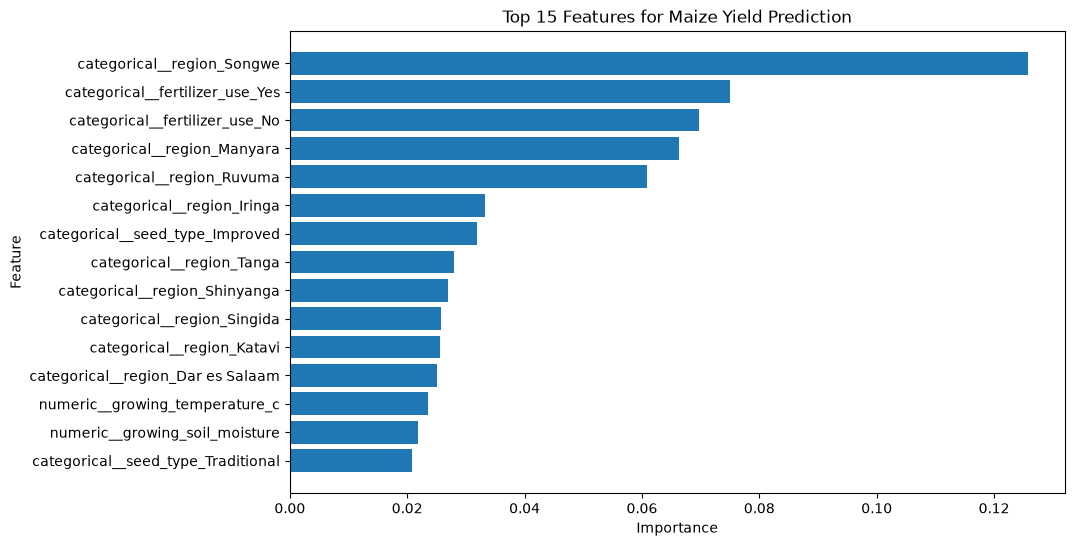

In [214]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features for Maize Yield Prediction")

plt.show()

In [215]:
positive_mask_growing = y_test_growing > 0

positive_growing_mae = mean_absolute_error(
    y_test_growing[positive_mask_growing],
    growing_pred[positive_mask_growing]
)

positive_growing_rmse = mean_squared_error(
    y_test_growing[positive_mask_growing],
    growing_pred[positive_mask_growing]
) ** 0.5

positive_growing_r2 = r2_score(
    y_test_growing[positive_mask_growing],
    growing_pred[positive_mask_growing]
)

print("Positive-yield growing-season model")
print("MAE:", positive_growing_mae)
print("RMSE:", positive_growing_rmse)
print("R²:", positive_growing_r2)

Positive-yield growing-season model
MAE: 0.8526082189196482
RMSE: 1.2653927855303584
R²: 0.15157080736742712


In [216]:
display(input_masika.head(20))

print(input_masika.dtypes)

,holding_id,InputRoster_masika__id,s11q01b,s11q01b_unit
0,00-00-02-59,Urea,650.0,Kilogram
1,00-00-02-59,Diammonium phosphate (DAP),225.0,Kilogram
2,00-00-02-59,Ammonium sulphate (SA),225.0,Kilogram
3,00-00-02-59,Herbicides (liquid),5.0,Liter
4,00-00-82-15,Urea,10.0,Kilogram
5,00-00-91-90,Insecticides,1.0,Liter
6,00-00-97-34,Insecticides,200.0,Milliliter
7,00-01-65-16,Diammonium phosphate (DAP),50.0,Kilogram
8,00-01-65-16,Insecticides,2.0,Liter
9,00-01-76-00,Diammonium phosphate (DAP),NaN,Kilogram


holding_id                    str
InputRoster_masika__id        str
s11q01b                   float64
s11q01b_unit                  str
dtype: object


In [217]:
print(
    input_masika["s11q01b_unit"]
    .value_counts(dropna=False)
)

print("\nVuli units:")

print(
    input_vuli["s11q01a_unit"]
    .value_counts(dropna=False)
)

s11q01b_unit
Kilogram           8872
Liter              5122
Milliliter         1365
Gram                316
Other (Specify)      12
NaN                   7
Name: count, dtype: int64

Vuli units:
s11q01a_unit
Kilogram           2575
Liter              1567
Milliliter          859
Gram                180
Other (Specify)      10
NaN                   1
Name: count, dtype: int64


In [218]:
print("Masika input types:")

print(
    input_masika["InputRoster_masika__id"]
    .value_counts()
    .head(30)
)

print("\nVuli input types:")

print(
    input_vuli["InputRoster_vuli__id"]
    .value_counts()
    .head(30)
)

Masika input types:
InputRoster_masika__id
Insecticides                             4676
Urea                                     2997
Diammonium phosphate (DAP)               2068
Herbicides (liquid)                      1787
Calcium ammonium nitrate (CAN)           1631
Ammonium sulphate (SA)                    802
Fungicides                                664
Nitrogen, phosphorus, potassium (NPK)     525
Herbicides (solid)                        248
Other inorganic fertilizer                 63
NPS zinc                                   48
AMIDAS                                     46
KENOPLUS                                   34
Triple Super Phosphate (TSP)               28
Other (specify)                            23
MACROP                                     16
Rodenticides                               13
Minjingu nafaka plus                       13
Muriate of Potash (MOP)                     9
FOMI                                        3
Name: count, dtype: int64

Vuli input

In [219]:
fertilizer_types = [
    "Urea",
    "Diammonium phosphate (DAP)",
    "Calcium ammonium nitrate (CAN)",
    "Ammonium sulphate (SA)",
    "Nitrogen, phosphorus, potassium (NPK)",
    "Other inorganic fertilizer",
    "NPS zinc",
    "AMIDAS",
    "KENOPLUS",
    "Triple Super Phosphate (TSP)",
    "MACROP",
    "Minjingu nafaka plus",
    "Muriate of Potash (MOP)",
    "FOMI"
]

In [220]:
masika_fertilizer = input_masika[
    input_masika["InputRoster_masika__id"].isin(fertilizer_types)
].copy()

display(masika_fertilizer.head(20))

,holding_id,InputRoster_masika__id,s11q01b,s11q01b_unit
0,00-00-02-59,Urea,650.0,Kilogram
1,00-00-02-59,Diammonium phosphate (DAP),225.0,Kilogram
2,00-00-02-59,Ammonium sulphate (SA),225.0,Kilogram
4,00-00-82-15,Urea,10.0,Kilogram
7,00-01-65-16,Diammonium phosphate (DAP),50.0,Kilogram
9,00-01-76-00,Diammonium phosphate (DAP),NaN,Kilogram
10,00-01-76-00,Calcium ammonium nitrate (CAN),NaN,Kilogram
12,00-01-78-16,Urea,250.0,Kilogram
13,00-01-78-16,Diammonium phosphate (DAP),250.0,Kilogram
17,00-01-98-69,"Nitrogen, phosphorus, potassium (NPK)",25.0,Kilogram


In [221]:
def convert_to_kg(row):
    quantity = row["s11q01b"]
    unit = row["s11q01b_unit"]

    if pd.isna(quantity):
        return np.nan

    if unit == "Kilogram":
        return quantity

    if unit == "Gram":
        return quantity / 1000

    return np.nan

In [222]:
masika_fertilizer["fertilizer_kg"] = masika_fertilizer.apply(
    convert_to_kg,
    axis=1
)

display(
    masika_fertilizer[
        [
            "holding_id",
            "InputRoster_masika__id",
            "s11q01b",
            "s11q01b_unit",
            "fertilizer_kg"
        ]
    ].head(20)
)

,holding_id,InputRoster_masika__id,s11q01b,s11q01b_unit,fertilizer_kg
0,00-00-02-59,Urea,650.0,Kilogram,650.0
1,00-00-02-59,Diammonium phosphate (DAP),225.0,Kilogram,225.0
2,00-00-02-59,Ammonium sulphate (SA),225.0,Kilogram,225.0
4,00-00-82-15,Urea,10.0,Kilogram,10.0
7,00-01-65-16,Diammonium phosphate (DAP),50.0,Kilogram,50.0
9,00-01-76-00,Diammonium phosphate (DAP),NaN,Kilogram,NaN
10,00-01-76-00,Calcium ammonium nitrate (CAN),NaN,Kilogram,NaN
12,00-01-78-16,Urea,250.0,Kilogram,250.0
13,00-01-78-16,Diammonium phosphate (DAP),250.0,Kilogram,250.0
17,00-01-98-69,"Nitrogen, phosphorus, potassium (NPK)",25.0,Kilogram,25.0


In [223]:
vuli_fertilizer = input_vuli[
    input_vuli["InputRoster_vuli__id"].isin(fertilizer_types)
].copy()

In [224]:
def convert_vuli_to_kg(row):
    quantity = row["s11q01a"]
    unit = row["s11q01a_unit"]

    if pd.isna(quantity):
        return np.nan

    if unit == "Kilogram":
        return quantity

    if unit == "Gram":
        return quantity / 1000

    return np.nan

In [225]:
vuli_fertilizer["fertilizer_kg"] = vuli_fertilizer.apply(
    convert_vuli_to_kg,
    axis=1
)

In [226]:
display(
    vuli_fertilizer[
        [
            "holding_id",
            "InputRoster_vuli__id",
            "s11q01a",
            "s11q01a_unit",
            "fertilizer_kg"
        ]
    ].head(20)
)

,holding_id,InputRoster_vuli__id,s11q01a,s11q01a_unit,fertilizer_kg
0,00-00-82-15,Urea,8.0,Kilogram,8.000
4,00-01-98-69,"Nitrogen, phosphorus, potassium (NPK)",25.0,Kilogram,25.000
7,00-03-00-74,Urea,100.0,Kilogram,100.000
8,00-03-00-74,Diammonium phosphate (DAP),50.0,Kilogram,50.000
12,00-03-49-11,Diammonium phosphate (DAP),3.0,Gram,0.003
13,00-03-49-11,"Nitrogen, phosphorus, potassium (NPK)",3.0,Kilogram,3.000
16,00-04-26-65,Urea,15.0,Kilogram,15.000
27,00-07-74-48,Urea,50.0,Kilogram,50.000
31,00-09-26-25,Urea,4.0,Kilogram,4.000
32,00-09-26-25,Diammonium phosphate (DAP),3.0,Kilogram,3.000


In [227]:
masika_fertilizer_total = (
    masika_fertilizer
    .groupby("holding_id", as_index=False)["fertilizer_kg"]
    .sum()
)

masika_fertilizer_total["season"] = "Masika"

In [228]:
vuli_fertilizer_total = (
    vuli_fertilizer
    .groupby("holding_id", as_index=False)["fertilizer_kg"]
    .sum()
)

vuli_fertilizer_total["season"] = "Vuli"

In [229]:
fertilizer_total = pd.concat(
    [
        masika_fertilizer_total,
        vuli_fertilizer_total
    ],
    ignore_index=True
)

display(fertilizer_total.head(20))

,holding_id,fertilizer_kg,season
0,00-00-02-59,1100.0,Masika
1,00-00-82-15,10.0,Masika
2,00-01-65-16,50.0,Masika
3,00-01-76-00,0.0,Masika
4,00-01-78-16,500.0,Masika
5,00-01-98-69,25.0,Masika
6,00-02-93-97,300.0,Masika
7,00-03-00-74,150.0,Masika
8,00-03-42-08,62.0,Masika
9,00-03-45-75,12033.0,Masika


In [230]:
print(
    fertilizer_total["fertilizer_kg"].describe()
)

count    5.555000e+03
mean     3.840879e+03
std      6.963918e+04
min      0.000000e+00
25%      3.550000e+01
50%      1.000000e+02
75%      3.000000e+02
max      3.645250e+06
Name: fertilizer_kg, dtype: float64


In [231]:
display(
    fertilizer_total
    .sort_values(
        "fertilizer_kg",
        ascending=False
    )
    .head(30)
)

,holding_id,fertilizer_kg,season
4331,02-57-54-93,3645250.000,Vuli
5328,45-13-66-18,2739621.000,Vuli
1039,04-84-19-65,1053350.000,Masika
5088,17-91-51-80,1053333.000,Vuli
2782,16-41-06-03,1022676.000,Masika
5523,92-46-29-10,945283.000,Vuli
3652,46-39-90-02,841250.000,Masika
2635,15-01-47-01,651416.000,Masika
3925,73-98-14-60,507117.000,Masika
5540,96-42-22-76,261983.000,Vuli


In [232]:
print(
    fertilizer_total["fertilizer_kg"].quantile(
        [
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            0.995,
            0.999
        ]
    )
)

0.500       100.000
0.750       300.000
0.900       800.000
0.950      3000.000
0.990     56824.460
0.995    101632.020
0.999    887648.718
Name: fertilizer_kg, dtype: float64


In [233]:
display(
    masika_fertilizer[
        [
            "holding_id",
            "InputRoster_masika__id",
            "s11q01b",
            "s11q01b_unit",
            "fertilizer_kg"
        ]
    ]
    .sort_values(
        "fertilizer_kg",
        ascending=False
    )
    .head(30)
)

,holding_id,InputRoster_masika__id,s11q01b,s11q01b_unit,fertilizer_kg
14635,73-98-14-60,"Nitrogen, phosphorus, potassium (NPK)",507117.0,Kilogram,507117.0
3718,04-84-19-65,"Nitrogen, phosphorus, potassium (NPK)",507117.0,Kilogram,507117.0
9923,16-41-06-03,"Nitrogen, phosphorus, potassium (NPK)",507117.0,Kilogram,507117.0
13269,46-39-90-02,Diammonium phosphate (DAP),350783.0,Kilogram,350783.0
3717,04-84-19-65,Diammonium phosphate (DAP),350783.0,Kilogram,350783.0
9405,15-01-47-01,Diammonium phosphate (DAP),350783.0,Kilogram,350783.0
9404,15-01-47-01,Urea,300633.0,Kilogram,300633.0
9921,16-41-06-03,Urea,300633.0,Kilogram,300633.0
13268,46-39-90-02,Urea,300633.0,Kilogram,300633.0
13270,46-39-90-02,Ammonium sulphate (SA),110217.0,Kilogram,110217.0


In [234]:
display(
    vuli_fertilizer[
        [
            "holding_id",
            "InputRoster_vuli__id",
            "s11q01a",
            "s11q01a_unit",
            "fertilizer_kg"
        ]
    ]
    .sort_values(
        "fertilizer_kg",
        ascending=False
    )
    .head(30)
)

,holding_id,InputRoster_vuli__id,s11q01a,s11q01a_unit,fertilizer_kg
4243,45-13-66-18,Diammonium phosphate (DAP),2699967.0,Kilogram,2699967.0
628,02-57-54-93,Diammonium phosphate (DAP),2699967.0,Kilogram,2699967.0
627,02-57-54-93,Urea,945283.0,Kilogram,945283.0
5057,92-46-29-10,Urea,945283.0,Kilogram,945283.0
3328,17-91-51-80,Urea,945283.0,Kilogram,945283.0
5018,89-67-90-17,Other inorganic fertilizer,144265.0,Kilogram,144265.0
5122,96-42-22-76,Other inorganic fertilizer,144265.0,Kilogram,144265.0
4133,39-66-22-08,Other inorganic fertilizer,144265.0,Kilogram,144265.0
3329,17-91-51-80,Diammonium phosphate (DAP),108050.0,Kilogram,108050.0
5120,96-42-22-76,"Nitrogen, phosphorus, potassium (NPK)",107650.0,Kilogram,107650.0


In [235]:
.groupby("holding_id")["fertilizer_kg"].sum()

SyntaxError: invalid syntax (780338365.py, line 1)

In [236]:
.groupby("holding_id")["fertilizer_kg"].sum()

SyntaxError: invalid syntax (780338365.py, line 1)

In [237]:
masika_fertilizer_total = (
    masika_fertilizer
    .groupby(
        "holding_id",
        as_index=False
    )["fertilizer_kg"]
    .sum(min_count=1)
)

masika_fertilizer_total["season"] = "Masika"

vuli_fertilizer_total = (
    vuli_fertilizer
    .groupby(
        "holding_id",
        as_index=False
    )["fertilizer_kg"]
    .sum(min_count=1)
)

vuli_fertilizer_total["season"] = "Vuli"

fertilizer_total = pd.concat(
    [
        masika_fertilizer_total,
        vuli_fertilizer_total
    ],
    ignore_index=True
)

display(fertilizer_total.head(20))

,holding_id,fertilizer_kg,season
0,00-00-02-59,1100.0,Masika
1,00-00-82-15,10.0,Masika
2,00-01-65-16,50.0,Masika
3,00-01-76-00,NaN,Masika
4,00-01-78-16,500.0,Masika
5,00-01-98-69,25.0,Masika
6,00-02-93-97,300.0,Masika
7,00-03-00-74,150.0,Masika
8,00-03-42-08,62.0,Masika
9,00-03-45-75,12033.0,Masika


In [238]:
print(
    fertilizer_total["fertilizer_kg"].describe()
)

count    5.453000e+03
mean     3.912724e+03
std      7.028559e+04
min      0.000000e+00
25%      5.000000e+01
50%      1.000000e+02
75%      3.000000e+02
max      3.645250e+06
Name: fertilizer_kg, dtype: float64


In [239]:
display(
    fertilizer_total
    .sort_values(
        "fertilizer_kg",
        ascending=False
    )
    .head(30)
)

,holding_id,fertilizer_kg,season
4331,02-57-54-93,3645250.000,Vuli
5328,45-13-66-18,2739621.000,Vuli
1039,04-84-19-65,1053350.000,Masika
5088,17-91-51-80,1053333.000,Vuli
2782,16-41-06-03,1022676.000,Masika
5523,92-46-29-10,945283.000,Vuli
3652,46-39-90-02,841250.000,Masika
2635,15-01-47-01,651416.000,Masika
3925,73-98-14-60,507117.000,Masika
5540,96-42-22-76,261983.000,Vuli


In [240]:
thresholds = [500, 1000, 5000, 10000, 50000, 100000]

print("TOTAL RECORDS:", len(fertilizer_total))

for t in thresholds:
    count = (fertilizer_total["fertilizer_kg"] > t).sum()
    percent = count / len(fertilizer_total) * 100

    print(
        f"Above {t:,} kg: "
        f"{count} records "
        f"({percent:.2f}%)"
    )

TOTAL RECORDS: 5555
Above 500 kg: 774 records (13.93%)
Above 1,000 kg: 460 records (8.28%)
Above 5,000 kg: 224 records (4.03%)
Above 10,000 kg: 160 records (2.88%)
Above 50,000 kg: 59 records (1.06%)
Above 100,000 kg: 29 records (0.52%)


In [241]:
print(
    fertilizer_total["fertilizer_kg"]
    .quantile([
        0.50,
        0.75,
        0.90,
        0.95,
        0.97,
        0.98,
        0.99,
        0.995,
        0.999
    ])
)

0.500       100.000
0.750       300.000
0.900       845.000
0.950      3009.600
0.970     10000.000
0.980     15650.000
0.990     57235.520
0.995    103862.760
0.999    898260.084
Name: fertilizer_kg, dtype: float64


In [242]:
fertilizer_check = final_maize[
    [
        "holding_id",
        "season",
        "farm_area",
        "region",
        "yield_t_ha"
    ]
].merge(
    fertilizer_total,
    on=["holding_id", "season"],
    how="left"
)

display(
    fertilizer_check
    .sort_values(
        "fertilizer_kg",
        ascending=False
    )
    .head(30)
)

,holding_id,season,farm_area,region,yield_t_ha,fertilizer_kg
1446,07-50-04-33,Masika,29,Songwe,2.068966,14316.0
11,00-03-45-75,Masika,85,Iringa,1.909091,12033.0
863,04-40-76-12,Masika,18,Mbeya,0.928571,10300.0
346,01-73-27-15,Masika,4,Shinyanga,2.500000,6867.0
370,01-83-89-17,Masika,10,Songwe,6.000000,5167.0
381,01-89-59-18,Masika,8,Songwe,5.333333,5000.0
1629,08-61-35-17,Masika,2,Mbeya,4.500000,5000.0
658,03-41-17-18,Masika,2,Songwe,6.000000,4000.0
657,03-41-17-18,Masika,6,Songwe,5.166667,4000.0
2366,15-01-75-10,Masika,5,Ruvuma,7.500000,3933.0


In [243]:
final_model_columns = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture",
    "yield_t_ha"
]

maize_final = maize_growing[
    final_model_columns
].copy()

print("Shape before cleaning:", maize_final.shape)

print("\nMissing values:")
print(maize_final.isna().sum())

Shape before cleaning: (4583, 10)

Missing values:
region                   0
season                   0
farm_area                0
seed_type                0
irrigation               0
fertilizer_use           0
growing_rainfall_mm      0
growing_temperature_c    3
growing_soil_moisture    3
yield_t_ha               0
dtype: int64


In [244]:
maize_final = maize_final.dropna(
    subset=[
        "growing_temperature_c",
        "growing_soil_moisture"
    ]
).copy()

print("Shape after removing missing weather rows:", maize_final.shape)

print("\nMissing values now:")
print(maize_final.isna().sum())

Shape after removing missing weather rows: (4580, 10)

Missing values now:
region                   0
season                   0
farm_area                0
seed_type                0
irrigation               0
fertilizer_use           0
growing_rainfall_mm      0
growing_temperature_c    0
growing_soil_moisture    0
yield_t_ha               0
dtype: int64


In [245]:
print(maize_final["yield_t_ha"].describe())

print("\nZero-yield records:")
print((maize_final["yield_t_ha"] == 0).sum())

print("\nPositive-yield records:")
print((maize_final["yield_t_ha"] > 0).sum())

count    4580.000000
mean        1.599742
std         1.432268
min         0.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        12.333333
Name: yield_t_ha, dtype: float64

Zero-yield records:
712

Positive-yield records:
3868


In [246]:
features = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

X = maize_final[features].copy()

# Classification target:
# 0 = zero yield
# 1 = positive yield
y_class = (maize_final["yield_t_ha"] > 0).astype(int)

# Regression target
y_reg = maize_final["yield_t_ha"].copy()

print("X shape:", X.shape)

print("\nClassification target:")
print(y_class.value_counts())

print("\nClassification percentages:")
print(y_class.value_counts(normalize=True) * 100)

X shape: (4580, 9)

Classification target:
yield_t_ha
1    3868
0     712
Name: count, dtype: int64

Classification percentages:
yield_t_ha
1    84.454148
0    15.545852
Name: proportion, dtype: float64


In [247]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_class_train, y_class_test, y_reg_train, y_reg_test = train_test_split(
    X,
    y_class,
    y_reg,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining class distribution:")
print(y_class_train.value_counts())

print("\nTesting class distribution:")
print(y_class_test.value_counts())

Training rows: 3664
Testing rows: 916

Training class distribution:
yield_t_ha
1    3094
0     570
Name: count, dtype: int64

Testing class distribution:
yield_t_ha
1    774
0    142
Name: count, dtype: int64


In [248]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features_final = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use"
]

numeric_features_final = [
    "farm_area",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

final_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_final
        ),
        (
            "numeric",
            "passthrough",
            numeric_features_final
        )
    ]
)

print("Final preprocessor created.")

Final preprocessor created.


In [249]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

zero_yield_classifier = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

classification_pipeline = Pipeline(
    steps=[
        ("preprocessor", final_preprocessor),
        ("classifier", zero_yield_classifier)
    ]
)

print("Classification pipeline created.")

Classification pipeline created.


In [250]:
from sklearn.utils.class_weight import compute_sample_weight

class_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_class_train
)

print("Number of weights:", len(class_weights))

print("\nAverage weight for zero-yield farms:")
print(class_weights[y_class_train.values == 0].mean())

print("\nAverage weight for positive-yield farms:")
print(class_weights[y_class_train.values == 1].mean())

Number of weights: 3664

Average weight for zero-yield farms:
3.214035087719299

Average weight for positive-yield farms:
0.5921137685843567


In [251]:
classification_pipeline.fit(
    X_train,
    y_class_train,
    classifier__sample_weight=class_weights
)

print("Stage 1 classifier trained successfully.")

Stage 1 classifier trained successfully.


In [252]:
class_predictions = classification_pipeline.predict(X_test)

print("Predictions created:", len(class_predictions))

print("\nPredicted classes:")
import pandas as pd
print(pd.Series(class_predictions).value_counts())

Predictions created: 916

Predicted classes:
1    581
0    335
Name: count, dtype: int64


In [253]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(
    y_class_test,
    class_predictions
)

print("Accuracy:", accuracy)

print("\nClassification report:")
print(
    classification_report(
        y_class_test,
        class_predictions,
        target_names=[
            "Zero yield",
            "Positive yield"
        ]
    )
)

print("\nConfusion matrix:")
cm = confusion_matrix(
    y_class_test,
    class_predictions
)

print(cm)

Accuracy: 0.7106986899563319

Classification report:
                precision    recall  f1-score   support

    Zero yield       0.32      0.75      0.44       142
Positive yield       0.94      0.70      0.80       774

      accuracy                           0.71       916
     macro avg       0.63      0.73      0.62       916
  weighted avg       0.84      0.71      0.75       916


Confusion matrix:
[[106  36]
 [229 545]]


In [254]:
tn, fp, fn, tp = cm.ravel()

zero_yield_recall = tn / (tn + fp)

print("Correctly detected zero-yield farms:", tn)
print("Missed zero-yield farms:", fp)

print(
    "Zero-yield detection rate:",
    round(zero_yield_recall * 100, 2),
    "%"
)

Correctly detected zero-yield farms: 106
Missed zero-yield farms: 36
Zero-yield detection rate: 74.65 %


In [255]:
positive_train_mask = y_class_train == 1

X_train_positive = X_train[
    positive_train_mask
].copy()

y_train_positive = y_reg_train[
    positive_train_mask
].copy()

print("Positive-yield training farms:", len(X_train_positive))

print(y_train_positive.describe())

Positive-yield training farms: 3094
count    3094.000000
mean        1.890321
std         1.367438
min         0.062500
25%         1.000000
50%         1.000000
75%         2.000000
max        12.333333
Name: yield_t_ha, dtype: float64


In [256]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

yield_regressor = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

yield_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", yield_regressor)
    ]
)

yield_pipeline.fit(
    X_train_positive,
    y_train_positive
)

print("Stage 2 yield regression model trained.")

ValueError: Some column names are not columns of the dataframe: {'soil_moisture', 'temperature_c', 'rainfall_mm'}

In [257]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features_final = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use"
]

numeric_features_final = [
    "farm_area",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

preprocessor_final = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_final
        ),
        (
            "numeric",
            "passthrough",
            numeric_features_final
        )
    ]
)

print("Final preprocessor created.")

Final preprocessor created.


In [258]:
print("X_train_positive columns:")
print(X_train_positive.columns.tolist())

X_train_positive columns:
['region', 'season', 'farm_area', 'seed_type', 'irrigation', 'fertilizer_use', 'growing_rainfall_mm', 'growing_temperature_c', 'growing_soil_moisture']


In [259]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

yield_regressor = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

yield_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_final),
        ("regressor", yield_regressor)
    ]
)

yield_pipeline.fit(
    X_train_positive,
    y_train_positive
)

print("Stage 2 yield regression model trained.")

Stage 2 yield regression model trained.


In [260]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Keep only positive-yield farms from the test set
positive_test_mask = y_reg_test > 0

X_test_positive = X_test[
    positive_test_mask
].copy()

y_test_positive = y_reg_test[
    positive_test_mask
].copy()

print("Positive-yield test farms:", len(y_test_positive))

Positive-yield test farms: 774


In [261]:
# Predict yield for farms that actually had positive yield
yield_predictions = yield_pipeline.predict(
    X_test_positive
)

print("Predictions created:", len(yield_predictions))
print(yield_predictions[:10])

Predictions created: 774
[2.3192503 1.4779896 1.3153298 1.8973113 2.2586906 1.6524576 1.3401638
 2.5212932 1.3427063 3.1160147]


In [262]:
mae_stage2 = mean_absolute_error(
    y_test_positive,
    yield_predictions
)

rmse_stage2 = mean_squared_error(
    y_test_positive,
    yield_predictions
) ** 0.5

r2_stage2 = r2_score(
    y_test_positive,
    yield_predictions
)

print("STAGE 2 - POSITIVE YIELD REGRESSION")
print("MAE:", mae_stage2)
print("RMSE:", rmse_stage2)
print("R²:", r2_stage2)

STAGE 2 - POSITIVE YIELD REGRESSION
MAE: 0.9068821073470308
RMSE: 1.3120876143325289
R²: 0.08229605229026637


In [263]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Simple baseline:
# predict the median positive yield from the training data
baseline_value = y_train_positive.median()

baseline_predictions = np.full(
    len(y_test_positive),
    baseline_value
)

baseline_mae = mean_absolute_error(
    y_test_positive,
    baseline_predictions
)

baseline_rmse = mean_squared_error(
    y_test_positive,
    baseline_predictions
) ** 0.5

baseline_r2 = r2_score(
    y_test_positive,
    baseline_predictions
)

print("Baseline prediction:", baseline_value)

print("\nBASELINE MODEL")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R²:", baseline_r2)

print("\nXGBOOST STAGE 2")
print("MAE:", mae_stage2)
print("RMSE:", rmse_stage2)
print("R²:", r2_stage2)

Baseline prediction: 1.0

BASELINE MODEL
MAE: 0.977029547039237
RMSE: 1.644277365464946
R²: -0.44120939672161485

XGBOOST STAGE 2
MAE: 0.9068821073470308
RMSE: 1.3120876143325289
R²: 0.08229605229026637


In [264]:
print(y_train_positive.describe())

print("\nYield percentiles:")
print(
    y_train_positive.quantile(
        [
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

count    3094.000000
mean        1.890321
std         1.367438
min         0.062500
25%         1.000000
50%         1.000000
75%         2.000000
max        12.333333
Name: yield_t_ha, dtype: float64

Yield percentiles:
0.01    0.333333
0.05    0.500000
0.10    1.000000
0.25    1.000000
0.50    1.000000
0.75    2.000000
0.90    4.000000
0.95    5.000000
0.99    6.352000
Name: yield_t_ha, dtype: float64


In [265]:
display(
    maize_final[
        maize_final["yield_t_ha"] > 0
    ]
    .sort_values(
        "yield_t_ha",
        ascending=False
    )
    .head(30)
)

,region,season,farm_area,seed_type,irrigation,fertilizer_use,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,yield_t_ha
1608,Manyara,Masika,4,Improved,No,No,355.660420,22.041372,0.281745,12.333333
4508,Dar es Salaam,Vuli,1,Improved,No,Yes,688.369286,27.363234,0.416520,12.000000
4051,Geita,Vuli,2,Improved,No,Yes,697.186890,22.860138,0.387772,12.000000
4536,Dar es Salaam,Vuli,1,Improved,No,No,1079.577187,26.785820,0.410612,12.000000
3402,Iringa,Masika,6,Traditional,No,Yes,986.591827,21.856639,0.375049,10.500000
4463,Dodoma,Vuli,3,Improved,No,No,626.460602,22.662340,0.346782,10.000000
799,Ruvuma,Masika,2,Improved,No,Yes,1369.727875,23.687300,0.349011,9.000000
4332,Tanga,Vuli,4,Improved,No,No,636.637207,24.217176,0.409565,8.250000
2399,Ruvuma,Masika,1,Improved,No,Yes,1369.727875,23.687300,0.349011,8.000000
2041,Arusha,Masika,10,Traditional,No,No,494.077467,21.819608,0.289918,8.000000


In [266]:
print("Number above 5 t/ha:",
      (maize_final["yield_t_ha"] > 5).sum())

print("Number above 7 t/ha:",
      (maize_final["yield_t_ha"] > 7).sum())

print("Number above 10 t/ha:",
      (maize_final["yield_t_ha"] > 10).sum())

Number above 5 t/ha: 103
Number above 7 t/ha: 12
Number above 10 t/ha: 5


In [267]:
import numpy as np

# Transform positive-yield training target
y_train_log = np.log1p(y_train_positive)

print("Original target:")
print(y_train_positive.describe())

print("\nLog-transformed target:")
print(y_train_log.describe())

Original target:
count    3094.000000
mean        1.890321
std         1.367438
min         0.062500
25%         1.000000
50%         1.000000
75%         2.000000
max        12.333333
Name: yield_t_ha, dtype: float64

Log-transformed target:
count    3094.000000
mean        0.975166
std         0.394701
min         0.060625
25%         0.693147
50%         0.693147
75%         1.098612
max         2.590267
Name: yield_t_ha, dtype: float64


In [268]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

log_regressor = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

log_yield_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_final),
        ("regressor", log_regressor)
    ]
)

log_yield_pipeline.fit(
    X_train_positive,
    y_train_log
)

print("Log-yield model trained.")

Log-yield model trained.


In [269]:
log_predictions = log_yield_pipeline.predict(
    X_test_positive
)

# Convert back from log scale to tonnes/hectare
log_predictions_t_ha = np.expm1(log_predictions)

# Yield should never be negative
log_predictions_t_ha = np.maximum(
    log_predictions_t_ha,
    0
)

print(log_predictions_t_ha[:10])

[2.0344853 1.3924849 1.2598459 1.6804405 2.0823784 1.5522256 1.2599442
 2.4359677 1.2255163 2.8091366]


In [270]:
log_mae = mean_absolute_error(
    y_test_positive,
    log_predictions_t_ha
)

log_rmse = mean_squared_error(
    y_test_positive,
    log_predictions_t_ha
) ** 0.5

log_r2 = r2_score(
    y_test_positive,
    log_predictions_t_ha
)

print("LOG-TARGET XGBOOST")
print("MAE:", log_mae)
print("RMSE:", log_rmse)
print("R²:", log_r2)

print("\nCURRENT XGBOOST")
print("MAE:", mae_stage2)
print("RMSE:", rmse_stage2)
print("R²:", r2_stage2)

LOG-TARGET XGBOOST
MAE: 0.8747931076498131
RMSE: 1.297151167022433
R²: 0.10307091029784288

CURRENT XGBOOST
MAE: 0.9068821073470308
RMSE: 1.3120876143325289
R²: 0.08229605229026637


In [271]:
# Get trained preprocessor and XGBoost model
trained_preprocessor = log_yield_pipeline.named_steps["preprocessor"]
trained_regressor = log_yield_pipeline.named_steps["regressor"]

# Get transformed feature names
feature_names = trained_preprocessor.get_feature_names_out()

# Get XGBoost feature importances
importances = trained_regressor.feature_importances_

feature_importance_log = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(
    "importance",
    ascending=False
)

display(feature_importance_log.head(20))

,feature,importance
24,categorical__region_Songwe,0.120602
20,categorical__region_Ruvuma,0.072021
6,categorical__region_Katavi,0.065968
37,categorical__fertilizer_use_No,0.063273
11,categorical__region_Manyara,0.056778
26,categorical__region_Tanga,0.034520
0,categorical__region_Arusha,0.031164
29,categorical__seed_type_Improved,0.030531
38,categorical__fertilizer_use_Yes,0.028237
22,categorical__region_Simiyu,0.027319


In [272]:
print("Top 10 feature importance total:")
print(
    feature_importance_log
    .head(10)["importance"]
    .sum()
)

Top 10 feature importance total:
0.53041327


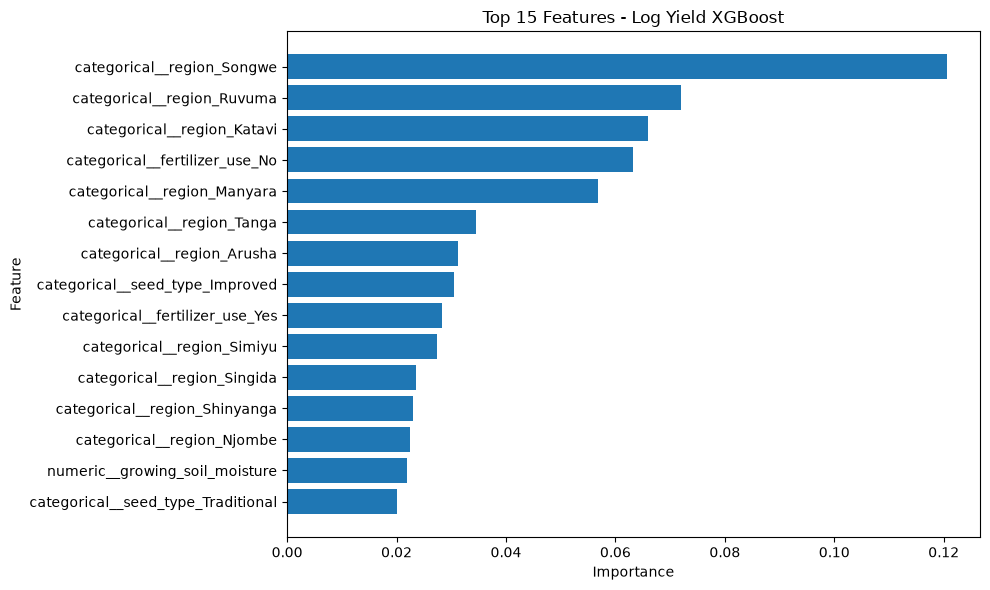

In [273]:
top_features_log = feature_importance_log.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features_log["feature"][::-1],
    top_features_log["importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features - Log Yield XGBoost")

plt.tight_layout()
plt.show()

In [274]:
def original_feature_name(feature):
    feature = feature.replace("categorical__", "")
    feature = feature.replace("numeric__", "")

    if feature.startswith("region_"):
        return "region"

    if feature.startswith("season_"):
        return "season"

    if feature.startswith("seed_type_"):
        return "seed_type"

    if feature.startswith("irrigation_"):
        return "irrigation"

    if feature.startswith("fertilizer_use_"):
        return "fertilizer_use"

    return feature


feature_importance_log["original_feature"] = (
    feature_importance_log["feature"]
    .apply(original_feature_name)
)

grouped_importance = (
    feature_importance_log
    .groupby("original_feature")["importance"]
    .sum()
    .sort_values(ascending=False)
)

print(grouped_importance)

original_feature
region                   0.694377
seed_type                0.092016
fertilizer_use           0.091510
season                   0.024802
growing_soil_moisture    0.021938
growing_rainfall_mm      0.019401
growing_temperature_c    0.019276
irrigation               0.018816
farm_area                0.017863
Name: importance, dtype: float32


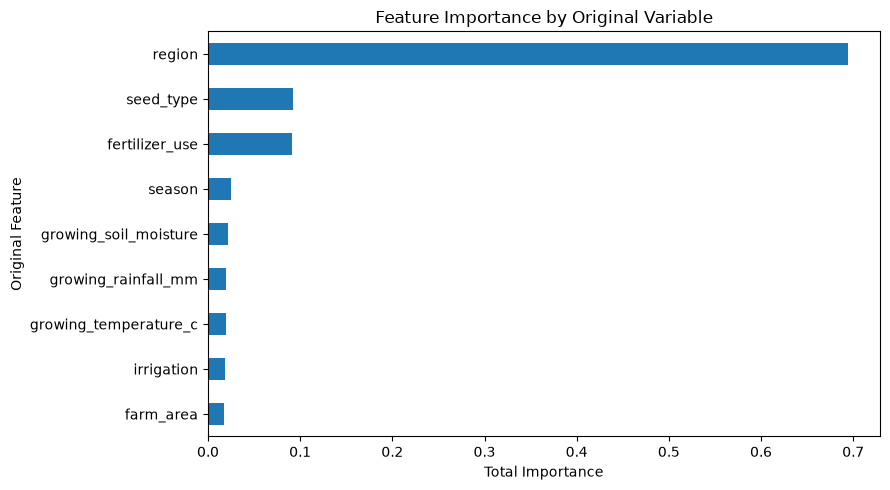

In [275]:
plt.figure(figsize=(9, 5))

grouped_importance.sort_values().plot(
    kind="barh"
)

plt.xlabel("Total Importance")
plt.ylabel("Original Feature")
plt.title("Feature Importance by Original Variable")

plt.tight_layout()
plt.show()

In [276]:
features_no_region = [
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

X_no_region = maize_final[features_no_region].copy()

print(X_no_region.shape)
print(X_no_region.columns.tolist())

(4580, 8)
['season', 'farm_area', 'seed_type', 'irrigation', 'fertilizer_use', 'growing_rainfall_mm', 'growing_temperature_c', 'growing_soil_moisture']


In [277]:
categorical_no_region = [
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use"
]

numeric_no_region = [
    "farm_area",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

preprocessor_no_region = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_no_region
        ),
        (
            "numeric",
            "passthrough",
            numeric_no_region
        )
    ]
)

print("Preprocessor ready.")

Preprocessor ready.


In [278]:
X_nr_train, X_nr_test, y_nr_train, y_nr_test = train_test_split(
    X_no_region,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training:", X_nr_train.shape)
print("Testing:", X_nr_test.shape)

Training: (3664, 8)
Testing: (916, 8)


In [279]:
nr_positive_train = y_nr_train > 0
nr_positive_test = y_nr_test > 0

X_nr_train_positive = X_nr_train[nr_positive_train]
y_nr_train_positive = y_nr_train[nr_positive_train]

X_nr_test_positive = X_nr_test[nr_positive_test]
y_nr_test_positive = y_nr_test[nr_positive_test]

print("Positive train:", len(y_nr_train_positive))
print("Positive test:", len(y_nr_test_positive))

Positive train: 3093
Positive test: 775


In [280]:
nr_regressor = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

nr_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_no_region),
        ("regressor", nr_regressor)
    ]
)

nr_pipeline.fit(
    X_nr_train_positive,
    y_nr_train_positive
)

print("No-region model trained.")

No-region model trained.


In [281]:
nr_pred = nr_pipeline.predict(
    X_nr_test_positive
)

nr_mae = mean_absolute_error(
    y_nr_test_positive,
    nr_pred
)

nr_rmse = mean_squared_error(
    y_nr_test_positive,
    nr_pred
) ** 0.5

nr_r2 = r2_score(
    y_nr_test_positive,
    nr_pred
)

print("NO-REGION MODEL")
print("MAE:", nr_mae)
print("RMSE:", nr_rmse)
print("R²:", nr_r2)

print("\nCURRENT MODEL")
print("MAE:", mae_stage2)
print("RMSE:", rmse_stage2)
print("R²:", r2_stage2)

NO-REGION MODEL
MAE: 0.8743726854126881
RMSE: 1.2406800999196907
R²: 0.18438627042886713

CURRENT MODEL
MAE: 0.9068821073470308
RMSE: 1.3120876143325289
R²: 0.08229605229026637


In [282]:
X_train_nr = X_train.drop(columns=["region"]).copy()
X_test_nr = X_test.drop(columns=["region"]).copy()

positive_train_mask = y_reg_train > 0
positive_test_mask = y_reg_test > 0

X_train_nr_positive = X_train_nr[positive_train_mask].copy()
y_train_nr_positive = y_reg_train[positive_train_mask].copy()

X_test_nr_positive = X_test_nr[positive_test_mask].copy()
y_test_nr_positive = y_reg_test[positive_test_mask].copy()

print("Positive training farms:", len(y_train_nr_positive))
print("Positive testing farms:", len(y_test_nr_positive))

print("Training columns:")
print(X_train_nr_positive.columns.tolist())

Positive training farms: 3094
Positive testing farms: 774
Training columns:
['season', 'farm_area', 'seed_type', 'irrigation', 'fertilizer_use', 'growing_rainfall_mm', 'growing_temperature_c', 'growing_soil_moisture']


In [283]:
categorical_no_region = [
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use"
]

numeric_no_region = [
    "farm_area",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

preprocessor_no_region = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_no_region
        ),
        (
            "numeric",
            "passthrough",
            numeric_no_region
        )
    ]
)

In [284]:
nr_regressor = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

nr_pipeline_fair = Pipeline(
    steps=[
        ("preprocessor", preprocessor_no_region),
        ("regressor", nr_regressor)
    ]
)

nr_pipeline_fair.fit(
    X_train_nr_positive,
    y_train_nr_positive
)

print("Fair no-region model trained.")

Fair no-region model trained.


In [285]:
nr_pred_fair = nr_pipeline_fair.predict(
    X_test_nr_positive
)

nr_mae_fair = mean_absolute_error(
    y_test_nr_positive,
    nr_pred_fair
)

nr_rmse_fair = mean_squared_error(
    y_test_nr_positive,
    nr_pred_fair
) ** 0.5

nr_r2_fair = r2_score(
    y_test_nr_positive,
    nr_pred_fair
)

print("FAIR NO-REGION MODEL")
print("MAE:", nr_mae_fair)
print("RMSE:", nr_rmse_fair)
print("R²:", nr_r2_fair)

print("\nCURRENT REGION MODEL")
print("MAE:", mae_stage2)
print("RMSE:", rmse_stage2)
print("R²:", r2_stage2)

FAIR NO-REGION MODEL
MAE: 0.9041869498706329
RMSE: 1.303165984791746
R²: 0.09473360465688674

CURRENT REGION MODEL
MAE: 0.9068821073470308
RMSE: 1.3120876143325289
R²: 0.08229605229026637


In [286]:
fertilizer_check2 = final_maize[
    [
        "holding_id",
        "season",
        "farm_area",
        "region",
        "yield_t_ha"
    ]
].merge(
    fertilizer_total,
    on=["holding_id", "season"],
    how="left"
)

fertilizer_check2["fertilizer_kg_per_ha"] = (
    fertilizer_check2["fertilizer_kg"]
    / fertilizer_check2["farm_area"]
)

display(
    fertilizer_check2[
        [
            "holding_id",
            "region",
            "season",
            "farm_area",
            "fertilizer_kg",
            "fertilizer_kg_per_ha",
            "yield_t_ha"
        ]
    ]
    .sort_values(
        "fertilizer_kg_per_ha",
        ascending=False
    )
    .head(30)
)

,holding_id,region,season,farm_area,fertilizer_kg,fertilizer_kg_per_ha,yield_t_ha
1623,08-59-69-49,Songwe,Masika,1,3750.0,3750.00,4.0
1622,08-59-69-49,Songwe,Masika,1,3750.0,3750.00,5.0
1080,05-44-74-91,Ruvuma,Masika,1,3000.0,3000.00,5.0
1081,05-44-74-91,Ruvuma,Masika,1,3000.0,3000.00,5.0
1082,05-44-74-91,Ruvuma,Masika,1,3000.0,3000.00,5.0
1084,05-44-74-91,Ruvuma,Masika,1,3000.0,3000.00,4.0
870,04-42-80-95,Ruvuma,Masika,1,2750.0,2750.00,3.0
1629,08-61-35-17,Mbeya,Masika,2,5000.0,2500.00,4.5
2736,22-30-17-03,Songwe,Masika,1,2500.0,2500.00,7.0
427,02-14-62-61,Songwe,Masika,1,2400.0,2400.00,4.0


In [287]:
print(
    fertilizer_check2[
        "fertilizer_kg_per_ha"
    ].describe()
)

print("\nPercentiles:")

print(
    fertilizer_check2[
        "fertilizer_kg_per_ha"
    ].quantile(
        [
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.97,
            0.99,
            0.995,
            0.999
        ]
    )
)

count    1558.000000
mean      307.739262
std       380.656161
min         0.016000
25%       100.000000
50%       200.000000
75%       400.000000
max      3750.000000
Name: fertilizer_kg_per_ha, dtype: float64

Percentiles:
0.250     100.00
0.500     200.00
0.750     400.00
0.900     700.00
0.950    1000.00
0.970    1250.00
0.990    1907.25
0.995    2500.00
0.999    3332.25
Name: fertilizer_kg_per_ha, dtype: float64


In [288]:
holding_area_check = (
    final_maize
    .groupby(
        ["holding_id", "season"],
        as_index=False
    )
    .agg(
        number_of_maize_plots=("farm_area", "size"),
        total_maize_area=("farm_area", "sum")
    )
)

display(
    holding_area_check
    .sort_values(
        "number_of_maize_plots",
        ascending=False
    )
    .head(30)
)

print(
    holding_area_check[
        "number_of_maize_plots"
    ].describe()
)

,holding_id,season,number_of_maize_plots,total_maize_area
1389,05-44-74-91,Masika,6,8
1553,06-17-32-94,Masika,5,9
2837,13-79-08-47,Masika,4,8
3279,18-81-36-21,Masika,3,4
2735,12-76-74-75,Masika,3,4
3145,16-89-01-22,Masika,3,4
1048,04-06-91-80,Masika,3,3
4200,82-46-90-50,Masika,3,6
1928,07-94-93-52,Masika,3,7
2062,08-59-69-49,Masika,3,4


count    4340.000000
mean        1.055991
std         0.265299
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         6.000000
Name: number_of_maize_plots, dtype: float64


In [289]:
fertilizer_holding = fertilizer_total.merge(
    holding_area_check,
    on=["holding_id", "season"],
    how="inner"
)

fertilizer_holding["fertilizer_kg_per_ha"] = (
    fertilizer_holding["fertilizer_kg"]
    / fertilizer_holding["total_maize_area"]
)

print(
    fertilizer_holding[
        "fertilizer_kg_per_ha"
    ].describe()
)

print("\nPercentiles:")

print(
    fertilizer_holding[
        "fertilizer_kg_per_ha"
    ].quantile(
        [
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.97,
            0.99,
            0.995,
            0.999
        ]
    )
)

count    1435.000000
mean      252.544635
std       264.107031
min         0.016000
25%        75.000000
50%       175.000000
75%       338.095238
max      2500.000000
Name: fertilizer_kg_per_ha, dtype: float64

Percentiles:
0.250      75.000000
0.500     175.000000
0.750     338.095238
0.900     550.000000
0.950     750.000000
0.970     924.880000
0.990    1300.000000
0.995    1500.000000
0.999    2103.469500
Name: fertilizer_kg_per_ha, dtype: float64


In [290]:
fertilizer_validation = final_maize[
    [
        "holding_id",
        "season",
        "fertilizer_use"
    ]
].merge(
    fertilizer_total,
    on=["holding_id", "season"],
    how="left"
)

print("Fertilizer quantity availability:")
print(
    pd.crosstab(
        fertilizer_validation["fertilizer_use"],
        fertilizer_validation["fertilizer_kg"].notna(),
        margins=True
    )
)

print(
    "\nSays NO fertilizer but has fertilizer quantity:"
)

print(
    (
        (fertilizer_validation["fertilizer_use"] == "No")
        &
        (fertilizer_validation["fertilizer_kg"] > 0)
    ).sum()
)

print(
    "\nSays YES fertilizer but quantity is missing:"
)

print(
    (
        (fertilizer_validation["fertilizer_use"] == "Yes")
        &
        (fertilizer_validation["fertilizer_kg"].isna())
    ).sum()
)

Fertilizer quantity availability:
fertilizer_kg   False  True   All
fertilizer_use                   
No               3012    96  3108
Yes                13  1462  1475
All              3025  1558  4583

Says NO fertilizer but has fertilizer quantity:
96

Says YES fertilizer but quantity is missing:
13


In [291]:
fertilizer_clean = fertilizer_holding[
    [
        "holding_id",
        "season",
        "fertilizer_kg_per_ha"
    ]
].copy()

print(fertilizer_clean.shape)

display(fertilizer_clean.head(20))

(1442, 3)


,holding_id,season,fertilizer_kg_per_ha
0,00-00-02-59,Masika,1100.000000
1,00-00-82-15,Masika,10.000000
2,00-01-65-16,Masika,50.000000
3,00-01-78-16,Masika,500.000000
4,00-02-93-97,Masika,150.000000
5,00-03-00-74,Masika,150.000000
6,00-03-45-75,Masika,141.564706
7,00-03-68-44,Masika,100.000000
8,00-03-82-26,Masika,60.000000
9,00-05-44-46,Masika,3.000000


In [292]:
print(maize_growing.columns.tolist())

print(
    "holding_id exists:",
    "holding_id" in maize_growing.columns
)

['holding_id', 'FIELD__id', 'MASIKAPLOT__id', 'crop_id', 'TEMP_PERM', 'areaPlanted', 's7q02a', 's7q03', 's7q04__1', 's7q04__2', 's7q04__3', 's7q04a', 's7q04a_Unit', 's7q05', 's7q06__1', 's7q06__2', 's7q06__3', 's7q06__4', 's7q06__5', 's7q06__6', 's7q06__7', 's7q06__8', 's7q06__9', 's7q06__10', 's7q06__11', 's7q06__99', 's7q07', 'areaHarvested', 's7q10__1', 's7q10__2', 's7q10__3', 's7q10__4', 's7q10__5', 's7q10__6', 's7q10__7', 's7q10__8', 's7q10__9', 's7q10__10', 's7q10__99', 's7q11', 's7q12', 's7q13', 's7q14', 's7q14a', 's7q14b_unit', 'harvest_ton', 'season', 'farm_area', 'region', 'yield_t_ha', 'year', 'planting_period', 'irrigation', 'irrigation_method', 'fertilizer_use', 'seed_type', 'VULIPLOT__id', 's5q03', 's5q04__1', 's5q04__2', 's5q04__3', 's5q04a', 's5q04a_Unit', 's5q05', 's5q06__1', 's5q06__2', 's5q06__3', 's5q06__4', 's5q06__5', 's5q06__6', 's5q06__7', 's5q06__8', 's5q06__9', 's5q06__99', 's5q07', 's5q10__1', 's5q10__2', 's5q10__3', 's5q10__4', 's5q10__5', 's5q10__6', 's5q10

In [293]:
maize_with_fertilizer = maize_growing.merge(
    fertilizer_clean,
    on=["holding_id", "season"],
    how="left"
)

print("Shape:", maize_with_fertilizer.shape)

print("\nMissing fertilizer quantity:")
print(
    maize_with_fertilizer[
        "fertilizer_kg_per_ha"
    ].isna().sum()
)

Shape: (4583, 98)

Missing fertilizer quantity:
3025


In [294]:
# If fertilizer was not used, quantity should be zero
mask_no_fertilizer = (
    (maize_with_fertilizer["fertilizer_use"] == "No")
    &
    (maize_with_fertilizer["fertilizer_kg_per_ha"].isna())
)

maize_with_fertilizer.loc[
    mask_no_fertilizer,
    "fertilizer_kg_per_ha"
] = 0

In [295]:
fertilizer_median = (
    maize_with_fertilizer.loc[
        (maize_with_fertilizer["fertilizer_use"] == "Yes")
        &
        (maize_with_fertilizer["fertilizer_kg_per_ha"].notna()),
        "fertilizer_kg_per_ha"
    ]
    .median()
)

print("Median fertilizer kg/ha:", fertilizer_median)

Median fertilizer kg/ha: 200.0


In [296]:
mask_yes_missing = (
    (maize_with_fertilizer["fertilizer_use"] == "Yes")
    &
    (maize_with_fertilizer["fertilizer_kg_per_ha"].isna())
)

maize_with_fertilizer.loc[
    mask_yes_missing,
    "fertilizer_kg_per_ha"
] = fertilizer_median

In [297]:
print(
    maize_with_fertilizer[
        [
            "fertilizer_use",
            "fertilizer_kg_per_ha"
        ]
    ].isna().sum()
)

display(
    maize_with_fertilizer[
        [
            "holding_id",
            "region",
            "season",
            "farm_area",
            "fertilizer_use",
            "fertilizer_kg_per_ha",
            "yield_t_ha"
        ]
    ].head(20)
)

fertilizer_use          0
fertilizer_kg_per_ha    0
dtype: int64


,holding_id,region,season,farm_area,fertilizer_use,fertilizer_kg_per_ha,yield_t_ha
0,00-00-02-59,Mbeya,Masika,1,No,1100.000000,1.000000
1,00-00-73-70,Tabora,Masika,1,No,0.000000,1.000000
2,00-00-82-15,Mara,Masika,1,Yes,10.000000,1.000000
3,00-01-50-14,Tabora,Masika,1,No,0.000000,3.000000
4,00-01-65-16,Manyara,Masika,1,Yes,50.000000,1.000000
5,00-01-78-16,Rukwa,Masika,1,Yes,500.000000,4.000000
6,00-01-88-91,Geita,Masika,2,No,0.000000,1.000000
7,00-02-02-21,Dodoma,Masika,3,No,0.000000,2.000000
8,00-02-29-95,Simiyu,Masika,2,No,0.000000,1.500000
9,00-02-93-97,Tabora,Masika,2,Yes,150.000000,2.000000


In [298]:
fertilized_area = (
    maize_growing[
        maize_growing["fertilizer_use"] == "Yes"
    ]
    .groupby(
        ["holding_id", "season"],
        as_index=False
    )["farm_area"]
    .sum()
    .rename(
        columns={
            "farm_area": "fertilized_maize_area"
        }
    )
)

print(fertilized_area.shape)
display(fertilized_area.head(20))

(1366, 3)


,holding_id,season,fertilized_maize_area
0,00-00-82-15,Masika,1
1,00-01-65-16,Masika,1
2,00-01-78-16,Masika,1
3,00-02-93-97,Masika,2
4,00-03-00-74,Masika,1
5,00-03-00-74,Vuli,1
6,00-03-45-75,Masika,85
7,00-03-68-44,Masika,1
8,00-03-82-26,Masika,5
9,00-06-70-24,Masika,1


In [299]:
# Merge fertilizer totals with fertilized maize area

fertilizer_rate = fertilizer_total.merge(
    fertilized_area,
    on=["holding_id", "season"],
    how="left"
)

display(fertilizer_rate.head(20))

print("\nMissing fertilized area:")
print(fertilizer_rate["fertilized_maize_area"].isna().sum())

,holding_id,fertilizer_kg,season,fertilized_maize_area
0,00-00-02-59,1100.0,Masika,NaN
1,00-00-82-15,10.0,Masika,1.0
2,00-01-65-16,50.0,Masika,1.0
3,00-01-76-00,NaN,Masika,NaN
4,00-01-78-16,500.0,Masika,1.0
5,00-01-98-69,25.0,Masika,NaN
6,00-02-93-97,300.0,Masika,2.0
7,00-03-00-74,150.0,Masika,1.0
8,00-03-42-08,62.0,Masika,NaN
9,00-03-45-75,12033.0,Masika,85.0



Missing fertilized area:
4196


In [300]:
fertilizer_rate_clean = fertilizer_rate[
    fertilizer_rate["fertilized_maize_area"].notna()
].copy()

print("Rows with valid fertilized area:", len(fertilizer_rate_clean))

display(
    fertilizer_rate_clean[
        [
            "holding_id",
            "season",
            "fertilizer_kg",
            "fertilized_maize_area"
        ]
    ].head(20)
)

Rows with valid fertilized area: 1359


,holding_id,season,fertilizer_kg,fertilized_maize_area
1,00-00-82-15,Masika,10.0,1.0
2,00-01-65-16,Masika,50.0,1.0
4,00-01-78-16,Masika,500.0,1.0
6,00-02-93-97,Masika,300.0,2.0
7,00-03-00-74,Masika,150.0,1.0
9,00-03-45-75,Masika,12033.0,85.0
10,00-03-68-44,Masika,100.0,1.0
11,00-03-82-26,Masika,300.0,5.0
13,00-06-70-24,Masika,50.0,1.0
15,00-07-11-84,Masika,400.0,1.0


In [301]:
fertilizer_rate_clean["fertilizer_kg_per_ha"] = (
    fertilizer_rate_clean["fertilizer_kg"]
    / fertilizer_rate_clean["fertilized_maize_area"]
)

display(
    fertilizer_rate_clean[
        [
            "holding_id",
            "season",
            "fertilizer_kg",
            "fertilized_maize_area",
            "fertilizer_kg_per_ha"
        ]
    ].head(20)
)

,holding_id,season,fertilizer_kg,fertilized_maize_area,fertilizer_kg_per_ha
1,00-00-82-15,Masika,10.0,1.0,10.000000
2,00-01-65-16,Masika,50.0,1.0,50.000000
4,00-01-78-16,Masika,500.0,1.0,500.000000
6,00-02-93-97,Masika,300.0,2.0,150.000000
7,00-03-00-74,Masika,150.0,1.0,150.000000
9,00-03-45-75,Masika,12033.0,85.0,141.564706
10,00-03-68-44,Masika,100.0,1.0,100.000000
11,00-03-82-26,Masika,300.0,5.0,60.000000
13,00-06-70-24,Masika,50.0,1.0,50.000000
15,00-07-11-84,Masika,400.0,1.0,400.000000


In [302]:
print(
    fertilizer_rate_clean["fertilizer_kg_per_ha"].describe()
)

print("\nPercentiles:")

print(
    fertilizer_rate_clean["fertilizer_kg_per_ha"].quantile(
        [
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.97,
            0.99,
            0.995,
            0.999
        ]
    )
)

count    1358.000000
mean      259.169711
std       265.831942
min         0.016000
25%       100.000000
50%       200.000000
75%       350.000000
max      2500.000000
Name: fertilizer_kg_per_ha, dtype: float64

Percentiles:
0.250     100.00000
0.500     200.00000
0.750     350.00000
0.900     550.00000
0.950     750.00000
0.970     950.00000
0.990    1300.23650
0.995    1510.77150
0.999    2156.07975
Name: fertilizer_kg_per_ha, dtype: float64


In [303]:
# Investigate unusually high fertilizer rates

high_fertilizer = fertilizer_rate_clean[
    fertilizer_rate_clean["fertilizer_kg_per_ha"] > 750
].copy()

print("Records above 750 kg/ha:", len(high_fertilizer))

print("\nFertilizer rates above 750 kg/ha:")

display(
    high_fertilizer[
        [
            "holding_id",
            "season",
            "fertilizer_kg",
            "fertilized_maize_area",
            "fertilizer_kg_per_ha"
        ]
    ].sort_values(
        "fertilizer_kg_per_ha",
        ascending=False
    ).head(30)
)

Records above 750 kg/ha: 63

Fertilizer rates above 750 kg/ha:


,holding_id,season,fertilizer_kg,fertilized_maize_area,fertilizer_kg_per_ha
1795,08-61-35-17,Masika,5000.00,2.0,2500.00
457,02-14-62-61,Masika,2400.00,1.0,2400.00
371,01-73-27-15,Masika,6867.00,4.0,1716.75
2423,12-97-21-91,Masika,1700.00,1.0,1700.00
755,03-56-81-05,Masika,3250.00,2.0,1625.00
4437,03-98-35-03,Vuli,1600.00,1.0,1600.00
1061,04-95-43-42,Masika,1550.10,1.0,1550.10
2374,12-53-54-97,Masika,1500.00,1.0,1500.00
3197,23-36-47-62,Masika,1500.00,1.0,1500.00
3276,25-19-95-26,Masika,1500.00,1.0,1500.00


In [304]:
# Look for all possible area/unit columns in the maize survey datasets

print("MASIKA possible area/unit columns:")
print([
    c for c in masika_clean.columns
    if "area" in c.lower()
    or "unit" in c.lower()
    or "hect" in c.lower()
    or "acre" in c.lower()
])

print("\nVULI possible area/unit columns:")
print([
    c for c in vuli_clean.columns
    if "area" in c.lower()
    or "unit" in c.lower()
    or "hect" in c.lower()
    or "acre" in c.lower()
])

MASIKA possible area/unit columns:
['areaPlanted', 's7q04a_Unit', 'areaHarvested', 's7q14b_unit', 'farm_area']

VULI possible area/unit columns:
['areaPlanted', 's5q04a_Unit', 'areaHarvested', 's5q14b_unit', 'farm_area']


In [305]:
print("Current area values:")
print(
    maize_growing["farm_area"]
    .value_counts()
    .sort_index()
    .head(30)
)

print("\nFarm-area summary:")
print(
    maize_growing["farm_area"].describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

Current area values:
farm_area
1     2812
2     1169
3      216
4      200
5       44
6       41
7       15
8       21
9        3
10      10
11       4
12       9
13       7
15       2
16       5
17       2
18       2
19       1
20       4
22       1
23       3
25       2
27       1
28       1
29       1
32       1
63       2
72       2
85       2
Name: count, dtype: int64

Farm-area summary:
count    4583.000000
mean        1.894611
std         3.283960
min         1.000000
50%         1.000000
75%         2.000000
90%         3.000000
95%         4.000000
99%        12.000000
max        85.000000
Name: farm_area, dtype: float64


In [306]:
print("MASIKA area units:")
print(
    masika_clean["s7q04a_Unit"]
    .value_counts(dropna=False)
)

print("\nVULI area units:")
print(
    vuli_clean["s5q04a_Unit"]
    .value_counts(dropna=False)
)

MASIKA area units:
s7q04a_Unit
KILOGRAM    3934
Name: count, dtype: int64

VULI area units:
s5q04a_Unit
KILOGRAM    1268
Name: count, dtype: int64


In [307]:
print("MASIKA area + unit:")
display(
    masika_clean[
        [
            "holding_id",
            "areaPlanted",
            "s7q04a_Unit",
            "farm_area"
        ]
    ].head(30)
)

print("\nVULI area + unit:")
display(
    vuli_clean[
        [
            "holding_id",
            "areaPlanted",
            "s5q04a_Unit",
            "farm_area"
        ]
    ].head(30)
)

MASIKA area + unit:


,holding_id,areaPlanted,s7q04a_Unit,farm_area
0,00-00-02-59,1.0,KILOGRAM,1
1,00-00-73-70,1.0,KILOGRAM,1
2,00-00-82-15,1.0,KILOGRAM,1
3,00-01-50-14,1.0,KILOGRAM,1
4,00-01-65-16,1.0,KILOGRAM,1
5,00-01-78-16,1.0,KILOGRAM,1
6,00-01-88-91,2.0,KILOGRAM,2
7,00-02-02-21,3.0,KILOGRAM,3
8,00-02-29-95,2.0,KILOGRAM,2
9,00-02-93-97,2.0,KILOGRAM,2



VULI area + unit:


,holding_id,areaPlanted,s5q04a_Unit,farm_area
0,00-01-88-91,2.0,KILOGRAM,2
1,00-01-88-91,1.0,KILOGRAM,2
2,00-03-00-74,1.0,KILOGRAM,1
3,00-03-06-74,1.0,KILOGRAM,1
4,00-06-89-76,2.0,KILOGRAM,2
5,00-08-20-03,1.0,KILOGRAM,1
6,00-12-99-08,1.0,KILOGRAM,1
7,00-14-61-05,3.0,KILOGRAM,3
8,00-15-87-03,1.0,KILOGRAM,1
9,00-16-15-75,1.0,KILOGRAM,1


In [308]:
print("MASIKA columns around areaPlanted:")
cols = masika_clean.columns.tolist()
idx = cols.index("areaPlanted")

print(cols[max(0, idx-8): idx+9])


print("\nVULI columns around areaPlanted:")
cols_v = vuli_clean.columns.tolist()
idx_v = cols_v.index("areaPlanted")

print(cols_v[max(0, idx_v-8): idx_v+9])

MASIKA columns around areaPlanted:
['holding_id', 'FIELD__id', 'MASIKAPLOT__id', 'crop_id', 'TEMP_PERM', 'areaPlanted', 's7q02a', 's7q03', 's7q04__1', 's7q04__2', 's7q04__3', 's7q04a', 's7q04a_Unit', 's7q05']

VULI columns around areaPlanted:
['holding_id', 'FIELD__id', 'VULIPLOT__id', 'crop_id', 'TEMP_PERM', 'areaPlanted', 's5q03', 's5q04__1', 's5q04__2', 's5q04__3', 's5q04a', 's5q04a_Unit', 's5q05', 's5q06__1']


In [309]:
print("MASIKA possible area-related columns:")
print([
    c for c in masika_clean.columns
    if "area" in c.lower()
    or "acre" in c.lower()
    or "hect" in c.lower()
    or "plot" in c.lower()
])

print("\nVULI possible area-related columns:")
print([
    c for c in vuli_clean.columns
    if "area" in c.lower()
    or "acre" in c.lower()
    or "hect" in c.lower()
    or "plot" in c.lower()
])

MASIKA possible area-related columns:
['MASIKAPLOT__id', 'areaPlanted', 'areaHarvested', 'farm_area']

VULI possible area-related columns:
['VULIPLOT__id', 'areaPlanted', 'areaHarvested', 'farm_area']


In [310]:
display(
    masika_clean[
        [
            "holding_id",
            "areaPlanted",
            "areaHarvested",
            "farm_area"
        ]
    ].head(30)
)

display(
    vuli_clean[
        [
            "holding_id",
            "areaPlanted",
            "areaHarvested",
            "farm_area"
        ]
    ].head(30)
)

,holding_id,areaPlanted,areaHarvested,farm_area
0,00-00-02-59,1.0,1.0,1
1,00-00-73-70,1.0,1.0,1
2,00-00-82-15,1.0,1.0,1
3,00-01-50-14,1.0,1.0,1
4,00-01-65-16,1.0,1.0,1
5,00-01-78-16,1.0,1.0,1
6,00-01-88-91,2.0,1.0,2
7,00-02-02-21,3.0,1.0,3
8,00-02-29-95,2.0,2.0,2
9,00-02-93-97,2.0,1.0,2


,holding_id,areaPlanted,areaHarvested,farm_area
0,00-01-88-91,2.0,2.0,2
1,00-01-88-91,1.0,1.0,2
2,00-03-00-74,1.0,1.0,1
3,00-03-06-74,1.0,1.0,1
4,00-06-89-76,2.0,2.0,2
5,00-08-20-03,1.0,1.0,1
6,00-12-99-08,1.0,1.0,1
7,00-14-61-05,3.0,2.0,3
8,00-15-87-03,1.0,1.0,1
9,00-16-15-75,1.0,1.0,1


In [311]:
fertilizer_rate_valid = fertilizer_rate[
    fertilizer_rate["fertilizer_kg"].notna()
    & fertilizer_rate["fertilized_maize_area"].notna()
    & (fertilizer_rate["fertilized_maize_area"] > 0)
].copy()

fertilizer_rate_valid["fertilizer_rate"] = (
    fertilizer_rate_valid["fertilizer_kg"]
    / fertilizer_rate_valid["fertilized_maize_area"]
)

print("Valid fertilizer records:", len(fertilizer_rate_valid))

print("\nFertilizer rate summary:")
print(
    fertilizer_rate_valid["fertilizer_rate"].describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.97,
            0.99
        ]
    )
)

display(
    fertilizer_rate_valid[
        [
            "holding_id",
            "season",
            "fertilizer_kg",
            "fertilized_maize_area",
            "fertilizer_rate"
        ]
    ]
    .sort_values("fertilizer_rate", ascending=False)
    .head(30)
)

Valid fertilizer records: 1358

Fertilizer rate summary:
count    1358.000000
mean      259.169711
std       265.831942
min         0.016000
25%       100.000000
50%       200.000000
75%       350.000000
90%       550.000000
95%       750.000000
97%       950.000000
99%      1300.236500
max      2500.000000
Name: fertilizer_rate, dtype: float64


,holding_id,season,fertilizer_kg,fertilized_maize_area,fertilizer_rate
1795,08-61-35-17,Masika,5000.00,2.0,2500.00
457,02-14-62-61,Masika,2400.00,1.0,2400.00
371,01-73-27-15,Masika,6867.00,4.0,1716.75
2423,12-97-21-91,Masika,1700.00,1.0,1700.00
755,03-56-81-05,Masika,3250.00,2.0,1625.00
4437,03-98-35-03,Vuli,1600.00,1.0,1600.00
1061,04-95-43-42,Masika,1550.10,1.0,1550.10
3276,25-19-95-26,Masika,1500.00,1.0,1500.00
3197,23-36-47-62,Masika,1500.00,1.0,1500.00
2374,12-53-54-97,Masika,1500.00,1.0,1500.00


In [312]:
print("MASIKA values around area variables:\n")

for col in ["s7q02a", "s7q03", "areaPlanted", "areaHarvested"]:
    if col in masika_clean.columns:
        print(f"\n--- {col} ---")
        print(masika_clean[col].value_counts(dropna=False).head(30))


print("\n\nVULI values around area variables:\n")

for col in ["s5q03", "areaPlanted", "areaHarvested"]:
    if col in vuli_clean.columns:
        print(f"\n--- {col} ---")
        print(vuli_clean[col].value_counts(dropna=False).head(30))

MASIKA values around area variables:


--- s7q02a ---
s7q02a
No     3262
Yes     672
Name: count, dtype: int64

--- s7q03 ---
s7q03
DECEMBER 2023     1532
NOVEMBER 2023     1361
JANUARY 2024       368
MARCH 2024         332
FEBRUARY 2024      247
APRIL 2024          62
JUNE 2024           12
MAY 2024            12
AUGUST 2024          4
JULY 2024            2
SEPTEMBER 2024       2
Name: count, dtype: int64

--- areaPlanted ---
areaPlanted
1.0      2356
2.0       799
3.0       170
4.0       166
5.0        50
6.0        44
8.0        38
7.0        22
12.0       21
10.0       18
20.0       15
16.0       13
11.0       10
13.0       10
9.0         9
40.0        9
28.0        8
14.0        6
202.0       6
49.0        5
18.0        5
81.0        5
17.0        5
24.0        5
15.0        4
27.0        4
63.0        4
121.0       4
23.0        3
29.0        3
Name: count, dtype: int64

--- areaHarvested ---
areaHarvested
1.0      2782
2.0       560
3.0       128
4.0        92
5.0        39
6.0

In [313]:
display(
    masika_clean[
        [
            "holding_id",
            "s7q02a",
            "s7q03",
            "areaPlanted",
            "areaHarvested"
        ]
    ].head(30)
)

,holding_id,s7q02a,s7q03,areaPlanted,areaHarvested
0,00-00-02-59,Yes,DECEMBER 2023,1.0,1.0
1,00-00-73-70,Yes,NOVEMBER 2023,1.0,1.0
2,00-00-82-15,No,AUGUST 2024,1.0,1.0
3,00-01-50-14,No,NOVEMBER 2023,1.0,1.0
4,00-01-65-16,No,NOVEMBER 2023,1.0,1.0
5,00-01-78-16,No,NOVEMBER 2023,1.0,1.0
6,00-01-88-91,No,FEBRUARY 2024,2.0,1.0
7,00-02-02-21,No,DECEMBER 2023,3.0,1.0
8,00-02-29-95,No,NOVEMBER 2023,2.0,2.0
9,00-02-93-97,No,NOVEMBER 2023,2.0,1.0


In [314]:
display(
    vuli_clean[
        [
            "holding_id",
            "s5q03",
            "areaPlanted",
            "areaHarvested"
        ]
    ].head(30)
)

,holding_id,s5q03,areaPlanted,areaHarvested
0,00-01-88-91,NOVEMBER 2023,2.0,2.0
1,00-01-88-91,NOVEMBER 2023,1.0,1.0
2,00-03-00-74,OCTOBER 2023,1.0,1.0
3,00-03-06-74,NOVEMBER 2023,1.0,1.0
4,00-06-89-76,NOVEMBER 2023,2.0,2.0
5,00-08-20-03,OCTOBER 2023,1.0,1.0
6,00-12-99-08,DECEMBER 2023,1.0,1.0
7,00-14-61-05,NOVEMBER 2023,3.0,2.0
8,00-15-87-03,SEPTEMBER 2023,1.0,1.0
9,00-16-15-75,OCTOBER 2023,1.0,1.0


In [315]:
# -----------------------------------------
# CHECK HOW farm_area RELATES TO areaPlanted
# -----------------------------------------

masika_area_check = (
    masika_clean
    .groupby("holding_id", as_index=False)
    .agg(
        summed_areaPlanted=("areaPlanted", "sum"),
        summed_areaHarvested=("areaHarvested", "sum"),
        number_of_rows=("holding_id", "size"),
        farm_area=("farm_area", "first")
    )
)

vuli_area_check = (
    vuli_clean
    .groupby("holding_id", as_index=False)
    .agg(
        summed_areaPlanted=("areaPlanted", "sum"),
        summed_areaHarvested=("areaHarvested", "sum"),
        number_of_rows=("holding_id", "size"),
        farm_area=("farm_area", "first")
    )
)

print("MASIKA:")
display(masika_area_check.head(30))

print("\nVULI:")
display(vuli_area_check.head(30))

MASIKA:


,holding_id,summed_areaPlanted,summed_areaHarvested,number_of_rows,farm_area
0,00-00-02-59,1.0,1.0,1,1
1,00-00-73-70,1.0,1.0,1,1
2,00-00-82-15,1.0,1.0,1,1
3,00-01-50-14,1.0,1.0,1,1
4,00-01-65-16,1.0,1.0,1,1
5,00-01-78-16,1.0,1.0,1,1
6,00-01-88-91,2.0,1.0,1,2
7,00-02-02-21,3.0,1.0,1,3
8,00-02-29-95,2.0,2.0,1,2
9,00-02-93-97,2.0,1.0,1,2



VULI:


,holding_id,summed_areaPlanted,summed_areaHarvested,number_of_rows,farm_area
0,00-01-88-91,3.0,3.0,2,2
1,00-03-00-74,1.0,1.0,1,1
2,00-03-06-74,1.0,1.0,1,1
3,00-06-89-76,2.0,2.0,1,2
4,00-08-20-03,1.0,1.0,1,1
5,00-12-99-08,1.0,1.0,1,1
6,00-14-61-05,3.0,2.0,1,3
7,00-15-87-03,1.0,1.0,1,1
8,00-16-15-75,1.0,1.0,1,1
9,00-17-31-71,3.0,3.0,1,4


In [316]:
print("MASIKA mismatches:")
display(
    masika_area_check[
        ~masika_area_check["planted_matches_farm_area"]
    ].head(30)
)

print("\nVULI mismatches:")
display(
    vuli_area_check[
        ~vuli_area_check["planted_matches_farm_area"]
    ].head(30)
)

MASIKA mismatches:


KeyError: 'planted_matches_farm_area'

In [317]:
import numpy as np

masika_area_check["planted_matches_farm_area"] = np.isclose(
    masika_area_check["summed_areaPlanted"],
    masika_area_check["farm_area"],
    equal_nan=False
)

vuli_area_check["planted_matches_farm_area"] = np.isclose(
    vuli_area_check["summed_areaPlanted"],
    vuli_area_check["farm_area"],
    equal_nan=False
)

print(
    "MASIKA matching:",
    round(
        masika_area_check["planted_matches_farm_area"].mean() * 100,
        2
    ),
    "%"
)

print(
    "VULI matching:",
    round(
        vuli_area_check["planted_matches_farm_area"].mean() * 100,
        2
    ),
    "%"
)

MASIKA matching: 82.54 %
VULI matching: 85.15 %


In [318]:
print("MASIKA mismatches:")

display(
    masika_area_check[
        ~masika_area_check["planted_matches_farm_area"]
    ].head(30)
)

print("\nVULI mismatches:")

display(
    vuli_area_check[
        ~vuli_area_check["planted_matches_farm_area"]
    ].head(30)
)

MASIKA mismatches:


,holding_id,summed_areaPlanted,summed_areaHarvested,number_of_rows,farm_area,planted_matches_farm_area
11,00-03-45-75,73.0,22.0,1,85,False
14,00-03-82-26,2.0,2.0,1,5,False
15,00-04-69-23,5.0,3.0,2,3,False
22,00-07-66-21,3.0,1.0,1,4,False
28,00-12-50-77,3.0,3.0,2,2,False
30,00-12-73-56,1.0,1.0,1,2,False
35,00-16-47-99,1.0,1.0,1,2,False
36,00-16-49-08,2.0,1.0,1,3,False
38,00-17-99-71,1.0,1.0,1,2,False
45,00-22-02-16,2.0,2.0,2,1,False



VULI mismatches:


,holding_id,summed_areaPlanted,summed_areaHarvested,number_of_rows,farm_area,planted_matches_farm_area
0,00-01-88-91,3.0,3.0,2,2,False
9,00-17-31-71,3.0,3.0,1,4,False
11,00-21-01-85,1.0,1.0,1,2,False
34,00-61-50-21,1.0,1.0,1,2,False
37,00-63-85-18,2.0,2.0,2,1,False
64,01-02-82-52,1.0,1.0,1,2,False
74,01-10-14-76,3.0,2.0,2,2,False
77,01-16-23-67,2.0,2.0,2,1,False
95,01-39-81-60,4.0,3.0,2,2,False
108,01-59-04-88,2.0,2.0,2,1,False


In [319]:
masika_area_check["harvested_matches_farm_area"] = np.isclose(
    masika_area_check["summed_areaHarvested"],
    masika_area_check["farm_area"],
    equal_nan=False
)

vuli_area_check["harvested_matches_farm_area"] = np.isclose(
    vuli_area_check["summed_areaHarvested"],
    vuli_area_check["farm_area"],
    equal_nan=False
)

print("MASIKA")
print(
    "Planted area match:",
    round(masika_area_check["planted_matches_farm_area"].mean() * 100, 2),
    "%"
)
print(
    "Harvested area match:",
    round(masika_area_check["harvested_matches_farm_area"].mean() * 100, 2),
    "%"
)

print("\nVULI")
print(
    "Planted area match:",
    round(vuli_area_check["planted_matches_farm_area"].mean() * 100, 2),
    "%"
)
print(
    "Harvested area match:",
    round(vuli_area_check["harvested_matches_farm_area"].mean() * 100, 2),
    "%"
)

MASIKA
Planted area match: 82.54 %
Harvested area match: 68.87 %

VULI
Planted area match: 85.15 %
Harvested area match: 72.19 %


In [320]:
# MASIKA planted maize area per holding
masika_planted_area = (
    masika_clean
    .groupby("holding_id", as_index=False)["areaPlanted"]
    .sum()
    .rename(columns={"areaPlanted": "planted_maize_area"})
)

masika_planted_area["season"] = "Masika"


# VULI planted maize area per holding
vuli_planted_area = (
    vuli_clean
    .groupby("holding_id", as_index=False)["areaPlanted"]
    .sum()
    .rename(columns={"areaPlanted": "planted_maize_area"})
)

vuli_planted_area["season"] = "Vuli"


planted_area_total = pd.concat(
    [
        masika_planted_area,
        vuli_planted_area
    ],
    ignore_index=True
)

display(planted_area_total.head(20))
print(planted_area_total["planted_maize_area"].describe())

,holding_id,planted_maize_area,season
0,00-00-02-59,1.0,Masika
1,00-00-73-70,1.0,Masika
2,00-00-82-15,1.0,Masika
3,00-01-50-14,1.0,Masika
4,00-01-65-16,1.0,Masika
5,00-01-78-16,1.0,Masika
6,00-01-88-91,2.0,Masika
7,00-02-02-21,3.0,Masika
8,00-02-29-95,2.0,Masika
9,00-02-93-97,2.0,Masika


count    4832.000000
mean       15.407285
std       144.839033
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max      3900.000000
Name: planted_maize_area, dtype: float64


In [321]:
fertilizer_rate_final = fertilizer_total.merge(
    planted_area_total,
    on=["holding_id", "season"],
    how="inner"
)

fertilizer_rate_final["fertilizer_kg_per_ha"] = (
    fertilizer_rate_final["fertilizer_kg"]
    / fertilizer_rate_final["planted_maize_area"]
)

display(
    fertilizer_rate_final[
        [
            "holding_id",
            "season",
            "fertilizer_kg",
            "planted_maize_area",
            "fertilizer_kg_per_ha"
        ]
    ].head(20)
)

,holding_id,season,fertilizer_kg,planted_maize_area,fertilizer_kg_per_ha
0,00-00-02-59,Masika,1100.0,1.0,1100.000000
1,00-00-82-15,Masika,10.0,1.0,10.000000
2,00-01-65-16,Masika,50.0,1.0,50.000000
3,00-01-78-16,Masika,500.0,1.0,500.000000
4,00-02-93-97,Masika,300.0,2.0,150.000000
5,00-03-00-74,Masika,150.0,1.0,150.000000
6,00-03-45-75,Masika,12033.0,73.0,164.835616
7,00-03-68-44,Masika,100.0,1.0,100.000000
8,00-03-82-26,Masika,300.0,2.0,150.000000
9,00-05-44-46,Masika,3.0,1.0,3.000000


In [322]:
print(
    fertilizer_rate_final["fertilizer_kg_per_ha"].describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.97,
            0.99,
            0.995,
            0.999
        ]
    )
)

count    1705.000000
mean      261.391243
std       329.410759
min         0.001875
25%        70.000000
50%       174.916667
75%       350.000000
90%       596.600000
95%       800.000000
97%      1000.000000
99%      1446.000000
99.5%    1708.040000
99.9%    4027.669985
max      4791.666667
Name: fertilizer_kg_per_ha, dtype: float64


In [323]:
fertilizer_cap = fertilizer_rate_final[
    "fertilizer_kg_per_ha"
].quantile(0.99)

print("99th percentile fertilizer cap:", fertilizer_cap)

fertilizer_rate_final["fertilizer_kg_per_ha_capped"] = (
    fertilizer_rate_final["fertilizer_kg_per_ha"]
    .clip(upper=fertilizer_cap)
)

print("\nOriginal fertilizer rate:")
print(
    fertilizer_rate_final[
        "fertilizer_kg_per_ha"
    ].describe()
)

print("\nCapped fertilizer rate:")
print(
    fertilizer_rate_final[
        "fertilizer_kg_per_ha_capped"
    ].describe()
)

99th percentile fertilizer cap: 1446.0000000000036

Original fertilizer rate:
count    1705.000000
mean      261.391243
std       329.410759
min         0.001875
25%        70.000000
50%       174.916667
75%       350.000000
max      4791.666667
Name: fertilizer_kg_per_ha, dtype: float64

Capped fertilizer rate:
count    1705.000000
mean      253.509148
std       269.770467
min         0.001875
25%        70.000000
50%       174.916667
75%       350.000000
max      1446.000000
Name: fertilizer_kg_per_ha_capped, dtype: float64


In [324]:
n_capped = (
    fertilizer_rate_final["fertilizer_kg_per_ha"]
    > fertilizer_cap
).sum()

print("Records capped:", n_capped)

print(
    "Percentage capped:",
    round(
        n_capped / len(fertilizer_rate_final) * 100,
        2
    ),
    "%"
)

Records capped: 18
Percentage capped: 1.04 %


In [325]:
fertilizer_feature = fertilizer_rate_final[
    [
        "holding_id",
        "season",
        "fertilizer_kg_per_ha_capped"
    ]
].copy()

print("Fertilizer feature shape:", fertilizer_feature.shape)

display(fertilizer_feature.head(20))

Fertilizer feature shape: (1730, 3)


,holding_id,season,fertilizer_kg_per_ha_capped
0,00-00-02-59,Masika,1100.000000
1,00-00-82-15,Masika,10.000000
2,00-01-65-16,Masika,50.000000
3,00-01-78-16,Masika,500.000000
4,00-02-93-97,Masika,150.000000
5,00-03-00-74,Masika,150.000000
6,00-03-45-75,Masika,164.835616
7,00-03-68-44,Masika,100.000000
8,00-03-82-26,Masika,150.000000
9,00-05-44-46,Masika,3.000000


In [326]:
maize_with_fertilizer_rate = maize_growing.merge(
    fertilizer_feature,
    on=["holding_id", "season"],
    how="left"
)

print("Before merge:", maize_growing.shape)
print("After merge:", maize_with_fertilizer_rate.shape)

print("\nMissing fertilizer-rate values:")
print(
    maize_with_fertilizer_rate[
        "fertilizer_kg_per_ha_capped"
    ].isna().sum()
)

display(
    maize_with_fertilizer_rate[
        [
            "holding_id",
            "region",
            "season",
            "farm_area",
            "fertilizer_use",
            "fertilizer_kg_per_ha_capped",
            "yield_t_ha"
        ]
    ].head(30)
)

Before merge: (4583, 97)
After merge: (4583, 98)

Missing fertilizer-rate values:
3025


,holding_id,region,season,farm_area,fertilizer_use,fertilizer_kg_per_ha_capped,yield_t_ha
0,00-00-02-59,Mbeya,Masika,1,No,1100.000000,1.000000
1,00-00-73-70,Tabora,Masika,1,No,NaN,1.000000
2,00-00-82-15,Mara,Masika,1,Yes,10.000000,1.000000
3,00-01-50-14,Tabora,Masika,1,No,NaN,3.000000
4,00-01-65-16,Manyara,Masika,1,Yes,50.000000,1.000000
5,00-01-78-16,Rukwa,Masika,1,Yes,500.000000,4.000000
6,00-01-88-91,Geita,Masika,2,No,NaN,1.000000
7,00-02-02-21,Dodoma,Masika,3,No,NaN,2.000000
8,00-02-29-95,Simiyu,Masika,2,No,NaN,1.500000
9,00-02-93-97,Tabora,Masika,2,Yes,150.000000,2.000000


In [327]:
no_fertilizer_missing = (
    (maize_with_fertilizer_rate["fertilizer_use"] == "No")
    &
    (maize_with_fertilizer_rate["fertilizer_kg_per_ha_capped"].isna())
)

yes_fertilizer_missing = (
    (maize_with_fertilizer_rate["fertilizer_use"] == "Yes")
    &
    (maize_with_fertilizer_rate["fertilizer_kg_per_ha_capped"].isna())
)

print(
    "No fertilizer + missing rate:",
    no_fertilizer_missing.sum()
)

print(
    "Yes fertilizer + missing rate:",
    yes_fertilizer_missing.sum()
)

print(
    "Known fertilizer rate:",
    maize_with_fertilizer_rate[
        "fertilizer_kg_per_ha_capped"
    ].notna().sum()
)

No fertilizer + missing rate: 3012
Yes fertilizer + missing rate: 13
Known fertilizer rate: 1558


In [328]:
contradictions_no = maize_with_fertilizer_rate[
    (maize_with_fertilizer_rate["fertilizer_use"] == "No")
    &
    (maize_with_fertilizer_rate["fertilizer_kg_per_ha_capped"].notna())
]

print(
    "Rows saying No fertilizer but having fertilizer quantity:",
    len(contradictions_no)
)

display(
    contradictions_no[
        [
            "holding_id",
            "region",
            "season",
            "farm_area",
            "fertilizer_use",
            "fertilizer_kg_per_ha_capped",
            "yield_t_ha"
        ]
    ].head(30)
)

Rows saying No fertilizer but having fertilizer quantity: 96


,holding_id,region,season,farm_area,fertilizer_use,fertilizer_kg_per_ha_capped,yield_t_ha
0,00-00-02-59,Mbeya,Masika,1,No,1100.000000,1.00
17,00-05-44-46,Ruvuma,Masika,1,No,3.000000,1.00
93,00-48-30-66,Mbeya,Masika,1,No,800.000000,1.00
142,00-76-82-42,Mtwara,Masika,1,No,100.000000,1.00
150,00-79-82-70,Singida,Masika,2,No,12.500000,7.00
159,00-83-05-25,Songwe,Masika,1,No,100.000000,0.00
194,01-00-46-00,Manyara,Masika,2,No,41.000000,5.00
212,01-11-96-25,Mbeya,Masika,1,No,200.000000,0.00
227,01-16-71-12,Iringa,Masika,1,No,125.000000,2.00
232,01-18-24-37,Ruvuma,Masika,1,No,50.000000,0.00


In [329]:
maize_with_fertilizer_rate["fertilizer_use_clean"] = (
    maize_with_fertilizer_rate["fertilizer_use"].copy()
)

maize_with_fertilizer_rate["fertilizer_rate_clean"] = (
    maize_with_fertilizer_rate["fertilizer_kg_per_ha_capped"].copy()
)


# RULE 1:
# If an actual positive fertilizer quantity exists,
# treat that farm as fertilizer user.
has_quantity = (
    maize_with_fertilizer_rate["fertilizer_rate_clean"].notna()
    &
    (maize_with_fertilizer_rate["fertilizer_rate_clean"] > 0)
)

maize_with_fertilizer_rate.loc[
    has_quantity,
    "fertilizer_use_clean"
] = "Yes"


# RULE 2:
# Says No fertilizer and no quantity record -> 0 kg/ha
no_fertilizer_missing = (
    (maize_with_fertilizer_rate["fertilizer_use_clean"] == "No")
    &
    (maize_with_fertilizer_rate["fertilizer_rate_clean"].isna())
)

maize_with_fertilizer_rate.loc[
    no_fertilizer_missing,
    "fertilizer_rate_clean"
] = 0

In [330]:
positive_fertilizer_median = (
    maize_with_fertilizer_rate.loc[
        maize_with_fertilizer_rate["fertilizer_rate_clean"] > 0,
        "fertilizer_rate_clean"
    ]
    .median()
)

print(
    "Median positive fertilizer rate:",
    positive_fertilizer_median,
    "kg/ha"
)

Median positive fertilizer rate: 200.0 kg/ha


In [331]:
yes_missing = (
    (maize_with_fertilizer_rate["fertilizer_use_clean"] == "Yes")
    &
    (maize_with_fertilizer_rate["fertilizer_rate_clean"].isna())
)

print(
    "Yes + missing before filling:",
    yes_missing.sum()
)

maize_with_fertilizer_rate.loc[
    yes_missing,
    "fertilizer_rate_clean"
] = positive_fertilizer_median

Yes + missing before filling: 13


In [332]:
print("Missing fertilizer rate:")
print(
    maize_with_fertilizer_rate[
        "fertilizer_rate_clean"
    ].isna().sum()
)

print("\nClean fertilizer-use counts:")
print(
    maize_with_fertilizer_rate[
        "fertilizer_use_clean"
    ].value_counts()
)

print("\nClean fertilizer-rate summary:")
print(
    maize_with_fertilizer_rate[
        "fertilizer_rate_clean"
    ].describe()
)

print("\nRows with No fertilizer but positive clean rate:")
print(
    (
        (maize_with_fertilizer_rate["fertilizer_use_clean"] == "No")
        &
        (maize_with_fertilizer_rate["fertilizer_rate_clean"] > 0)
    ).sum()
)

Missing fertilizer rate:
0

Clean fertilizer-use counts:
fertilizer_use_clean
No     3012
Yes    1571
Name: count, dtype: int64

Clean fertilizer-rate summary:
count    4583.00000
mean       87.75017
std       189.86469
min         0.00000
25%         0.00000
50%         0.00000
75%       100.00000
max      1446.00000
Name: fertilizer_rate_clean, dtype: float64

Rows with No fertilizer but positive clean rate:
0


In [333]:
maize_model_final = maize_with_fertilizer_rate[
    [
        "region",
        "season",
        "farm_area",
        "seed_type",
        "irrigation",
        "fertilizer_use_clean",
        "fertilizer_rate_clean",
        "growing_rainfall_mm",
        "growing_temperature_c",
        "growing_soil_moisture",
        "yield_t_ha"
    ]
].copy()

print("Final dataset shape:", maize_model_final.shape)

print("\nMissing values:")
print(maize_model_final.isna().sum())

display(maize_model_final.head(20))print(maize_model_final["yield_t_ha"].describe())

print("\nZero-yield farms:")
print((maize_model_final["yield_t_ha"] == 0).sum())

print("\nPositive-yield farms:")
print((maize_model_final["yield_t_ha"] > 0).sum())

Final dataset shape: (4583, 11)

Missing values:
region                   0
season                   0
farm_area                0
seed_type                0
irrigation               0
fertilizer_use_clean     0
fertilizer_rate_clean    0
growing_rainfall_mm      0
growing_temperature_c    3
growing_soil_moisture    3
yield_t_ha               0
dtype: int64


,region,season,farm_area,seed_type,irrigation,fertilizer_use_clean,fertilizer_rate_clean,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,yield_t_ha
0,Mbeya,Masika,1,Traditional,No,Yes,1100.000000,1281.109558,21.642988,0.440201,1.000000
1,Tabora,Masika,1,Improved recycled,No,No,0.000000,788.573883,22.785276,0.411738,1.000000
2,Mara,Masika,1,Improved,No,Yes,10.000000,456.237171,23.139217,0.213502,1.000000
3,Tabora,Masika,1,Traditional,No,No,0.000000,788.573883,22.785276,0.411738,3.000000
4,Manyara,Masika,1,Improved,No,Yes,50.000000,643.435944,22.200369,0.318072,1.000000
5,Rukwa,Masika,1,Improved,No,Yes,500.000000,1244.757675,21.670128,0.345683,4.000000
6,Geita,Masika,2,Improved,No,No,0.000000,466.519158,23.106525,0.388444,1.000000
7,Dodoma,Masika,3,Improved,No,No,0.000000,633.649864,23.066451,0.334084,2.000000
8,Simiyu,Masika,2,Improved,No,No,0.000000,783.973763,21.910604,0.369624,1.500000
9,Tabora,Masika,2,Traditional,No,Yes,150.000000,788.573883,22.785276,0.411738,2.000000


In [334]:
print(maize_model_final["yield_t_ha"].describe())

print("\nZero-yield farms:")
print((maize_model_final["yield_t_ha"] == 0).sum())

print("\nPositive-yield farms:")
print((maize_model_final["yield_t_ha"] > 0).sum())

count    4583.000000
mean        1.599131
std         1.432049
min         0.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        12.333333
Name: yield_t_ha, dtype: float64

Zero-yield farms:
713

Positive-yield farms:
3870


In [335]:
print("\nFertilizer vs yield summary:")

print(
    maize_model_final
    .groupby("fertilizer_use_clean")["yield_t_ha"]
    .agg(["count", "mean", "median", "std"])
)


Fertilizer vs yield summary:
                      count      mean  median       std
fertilizer_use_clean                                   
No                     3012  1.271891     1.0  1.179066
Yes                    1571  2.226533     2.0  1.649121


In [336]:
print(
    maize_model_final[
        [
            "fertilizer_rate_clean",
            "yield_t_ha"
        ]
    ]
    .corr()
)

                       fertilizer_rate_clean  yield_t_ha
fertilizer_rate_clean               1.000000    0.387915
yield_t_ha                          0.387915    1.000000


In [337]:
features_final = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

X_final = maize_model_final[features_final].copy()

# Stage 1 target
# 0 = zero yield
# 1 = positive yield
y_class_final = (
    maize_model_final["yield_t_ha"] > 0
).astype(int)

# Stage 2 target
y_yield_final = maize_model_final["yield_t_ha"].copy()

print("X shape:", X_final.shape)

print("\nFeatures:")
print(X_final.columns.tolist())

print("\nClass counts:")
print(y_class_final.value_counts())

print("\nMissing values:")
print(X_final.isna().sum())

X shape: (4583, 10)

Features:
['region', 'season', 'farm_area', 'seed_type', 'irrigation', 'fertilizer_use_clean', 'fertilizer_rate_clean', 'growing_rainfall_mm', 'growing_temperature_c', 'growing_soil_moisture']

Class counts:
yield_t_ha
1    3870
0     713
Name: count, dtype: int64

Missing values:
region                   0
season                   0
farm_area                0
seed_type                0
irrigation               0
fertilizer_use_clean     0
fertilizer_rate_clean    0
growing_rainfall_mm      0
growing_temperature_c    3
growing_soil_moisture    3
dtype: int64


In [338]:
from sklearn.model_selection import train_test_split

(
    X_train_final,
    X_test_final,
    y_class_train_final,
    y_class_test_final,
    y_yield_train_final,
    y_yield_test_final
) = train_test_split(
    X_final,
    y_class_final,
    y_yield_final,
    test_size=0.20,
    random_state=42,
    stratify=y_class_final
)

print("Training rows:", len(X_train_final))
print("Testing rows:", len(X_test_final))

print("\nTraining classes:")
print(y_class_train_final.value_counts())

print("\nTesting classes:")
print(y_class_test_final.value_counts())

Training rows: 3666
Testing rows: 917

Training classes:
yield_t_ha
1    3096
0     570
Name: count, dtype: int64

Testing classes:
yield_t_ha
1    774
0    143
Name: count, dtype: int64


In [339]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_features_final = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean"
]

numeric_features_final = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

# Fill missing numeric values using the median
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Convert categorical variables into numerical form
categorical_transformer = Pipeline(
    steps=[
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor_final = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features_final
        ),
        (
            "numeric",
            numeric_transformer,
            numeric_features_final
        )
    ]
)

print("Final preprocessor created successfully.")

Final preprocessor created successfully.


In [340]:
import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

stage1_classifier = XGBClassifier(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

stage1_pipeline_final = Pipeline(
    steps=[
        ("preprocessor", preprocessor_final),
        ("classifier", stage1_classifier)
    ]
)

# Give more importance to the minority zero-yield class
stage1_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_class_train_final
)

print("Number of training weights:", len(stage1_weights))

print(
    "Average weight - zero yield:",
    stage1_weights[y_class_train_final.values == 0].mean()
)

print(
    "Average weight - positive yield:",
    stage1_weights[y_class_train_final.values == 1].mean()
)

Number of training weights: 3666
Average weight - zero yield: 3.2157894736842105
Average weight - positive yield: 0.5920542635658916


In [341]:
stage1_pipeline_final.fit(
    X_train_final,
    y_class_train_final,
    classifier__sample_weight=stage1_weights
)

print("Final Stage 1 classifier trained successfully.")

Final Stage 1 classifier trained successfully.


In [342]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

stage1_predictions_final = stage1_pipeline_final.predict(
    X_test_final
)

accuracy_final = accuracy_score(
    y_class_test_final,
    stage1_predictions_final
)

cm_final = confusion_matrix(
    y_class_test_final,
    stage1_predictions_final
)

print("STAGE 1 - FINAL CLASSIFIER")
print("Accuracy:", accuracy_final)

print("\nClassification report:")
print(
    classification_report(
        y_class_test_final,
        stage1_predictions_final,
        target_names=[
            "Zero yield",
            "Positive yield"
        ]
    )
)

print("\nConfusion matrix:")
print(cm_final)

STAGE 1 - FINAL CLASSIFIER
Accuracy: 0.6826608505997819

Classification report:
                precision    recall  f1-score   support

    Zero yield       0.29      0.74      0.42       143
Positive yield       0.93      0.67      0.78       774

      accuracy                           0.68       917
     macro avg       0.61      0.71      0.60       917
  weighted avg       0.83      0.68      0.73       917


Confusion matrix:
[[106  37]
 [254 520]]


In [343]:
# Keep only positive-yield training rows
positive_train_mask_final = y_yield_train_final > 0
positive_test_mask_final = y_yield_test_final > 0

X_train_positive_final = X_train_final[
    positive_train_mask_final
].copy()

y_train_positive_final = y_yield_train_final[
    positive_train_mask_final
].copy()

X_test_positive_final = X_test_final[
    positive_test_mask_final
].copy()

y_test_positive_final = y_yield_test_final[
    positive_test_mask_final
].copy()

print("Positive-yield training farms:", len(X_train_positive_final))
print("Positive-yield testing farms:", len(X_test_positive_final))

print("\nTraining yield summary:")
print(y_train_positive_final.describe())

Positive-yield training farms: 3096
Positive-yield testing farms: 774

Training yield summary:
count    3096.000000
mean        1.902492
std         1.386492
min         0.062500
25%         1.000000
50%         1.000000
75%         2.000000
max        12.333333
Name: yield_t_ha, dtype: float64


In [344]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

stage2_regressor_final = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

stage2_pipeline_final = Pipeline(
    steps=[
        ("preprocessor", preprocessor_final),
        ("regressor", stage2_regressor_final)
    ]
)

stage2_pipeline_final.fit(
    X_train_positive_final,
    y_train_positive_final
)

print("Final Stage 2 regression model trained successfully.")

Final Stage 2 regression model trained successfully.


In [345]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

stage2_predictions_final = stage2_pipeline_final.predict(
    X_test_positive_final
)

mae_final = mean_absolute_error(
    y_test_positive_final,
    stage2_predictions_final
)

rmse_final = mean_squared_error(
    y_test_positive_final,
    stage2_predictions_final
) ** 0.5

r2_final = r2_score(
    y_test_positive_final,
    stage2_predictions_final
)

print("FINAL STAGE 2 - YIELD REGRESSION")
print("MAE:", mae_final)
print("RMSE:", rmse_final)
print("R²:", r2_final)

FINAL STAGE 2 - YIELD REGRESSION
MAE: 0.8545320732791443
RMSE: 1.1825968424766913
R²: 0.15858985690411231


In [346]:
# Get trained XGBoost model
trained_regressor = stage2_pipeline_final.named_steps["regressor"]

# Get transformed feature names
feature_names = (
    stage2_pipeline_final
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

import pandas as pd

feature_importance_final = pd.DataFrame({
    "feature": feature_names,
    "importance": trained_regressor.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

display(feature_importance_final.head(25))

,feature,importance
23,categorical__region_Simiyu,0.071957
11,categorical__region_Manyara,0.061423
25,categorical__region_Songwe,0.060870
21,categorical__region_Ruvuma,0.056979
38,categorical__fertilizer_use_clean_No,0.050156
41,numeric__fertilizer_rate_clean,0.040846
30,categorical__seed_type_Improved,0.035637
6,categorical__region_Katavi,0.035346
3,categorical__region_Geita,0.034699
29,categorical__season_Vuli,0.034620


In [347]:
# Get the trained XGBoost model from the final Stage 2 pipeline
final_xgb = stage2_pipeline_final.named_steps["regressor"]

# Get feature names after preprocessing
final_feature_names = (
    stage2_pipeline_final
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create feature-importance table
final_feature_importance = pd.DataFrame({
    "feature": final_feature_names,
    "importance": final_xgb.feature_importances_
}).sort_values("importance", ascending=False)

display(final_feature_importance.head(25))

,feature,importance
23,categorical__region_Simiyu,0.071957
11,categorical__region_Manyara,0.061423
25,categorical__region_Songwe,0.060870
21,categorical__region_Ruvuma,0.056979
38,categorical__fertilizer_use_clean_No,0.050156
41,numeric__fertilizer_rate_clean,0.040846
30,categorical__seed_type_Improved,0.035637
6,categorical__region_Katavi,0.035346
3,categorical__region_Geita,0.034699
29,categorical__season_Vuli,0.034620


In [348]:
def get_original_feature(feature):
    feature = feature.replace("categorical__", "").replace("numeric__", "")

    if feature.startswith("region_"):
        return "region"

    if feature.startswith("season_"):
        return "season"

    if feature.startswith("seed_type_"):
        return "seed_type"

    if feature.startswith("irrigation_"):
        return "irrigation"

    if feature.startswith("fertilizer_use_clean_"):
        return "fertilizer_use_clean"

    return feature


final_feature_importance["original_feature"] = (
    final_feature_importance["feature"]
    .apply(get_original_feature)
)

final_grouped_importance = (
    final_feature_importance
    .groupby("original_feature")["importance"]
    .sum()
    .sort_values(ascending=False)
)

print(final_grouped_importance)

original_feature
region                   0.620960
seed_type                0.103111
fertilizer_use_clean     0.060921
season                   0.059829
fertilizer_rate_clean    0.040846
growing_soil_moisture    0.025941
growing_temperature_c    0.025680
growing_rainfall_mm      0.022357
farm_area                0.020988
irrigation               0.019367
Name: importance, dtype: float32


In [349]:
# Remove region while keeping exactly the same train/test split
X_train_no_region = X_train_final.drop(columns=["region"]).copy()
X_test_no_region = X_test_final.drop(columns=["region"]).copy()

print("Training shape:", X_train_no_region.shape)
print("Testing shape:", X_test_no_region.shape)

print("\nFeatures:")
print(X_train_no_region.columns.tolist())

Training shape: (3666, 9)
Testing shape: (917, 9)

Features:
['season', 'farm_area', 'seed_type', 'irrigation', 'fertilizer_use_clean', 'fertilizer_rate_clean', 'growing_rainfall_mm', 'growing_temperature_c', 'growing_soil_moisture']


In [350]:
# Keep only positive-yield farms for Stage 2
positive_train_mask_final = y_yield_train_final > 0
positive_test_mask_final = y_yield_test_final > 0

X_train_positive_no_region = X_train_no_region[
    positive_train_mask_final
].copy()

y_train_positive_no_region = y_yield_train_final[
    positive_train_mask_final
].copy()

X_test_positive_no_region = X_test_no_region[
    positive_test_mask_final
].copy()

y_test_positive_no_region = y_yield_test_final[
    positive_test_mask_final
].copy()

print("Positive-yield training farms:",
      len(X_train_positive_no_region))

print("Positive-yield testing farms:",
      len(X_test_positive_no_region))

Positive-yield training farms: 3096
Positive-yield testing farms: 774


In [351]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

categorical_no_region = [
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean"
]

numeric_no_region = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

preprocessor_no_region = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_no_region
        ),
        (
            "numeric",
            "passthrough",
            numeric_no_region
        )
    ]
)

xgb_no_region = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

stage2_no_region = Pipeline(
    steps=[
        ("preprocessor", preprocessor_no_region),
        ("regressor", xgb_no_region)
    ]
)

stage2_no_region.fit(
    X_train_positive_no_region,
    y_train_positive_no_region
)

print("No-region Stage 2 model trained successfully.")

No-region Stage 2 model trained successfully.


In [352]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pred_no_region = stage2_no_region.predict(
    X_test_positive_no_region
)

mae_no_region = mean_absolute_error(
    y_test_positive_no_region,
    pred_no_region
)

rmse_no_region = mean_squared_error(
    y_test_positive_no_region,
    pred_no_region
) ** 0.5

r2_no_region = r2_score(
    y_test_positive_no_region,
    pred_no_region
)

print("NO-REGION STAGE 2")
print("MAE:", mae_no_region)
print("RMSE:", rmse_no_region)
print("R²:", r2_no_region)

print("\nCURRENT REGION MODEL")
print("MAE:", mae_final)
print("RMSE:", rmse_final)
print("R²:", r2_final)

NO-REGION STAGE 2
MAE: 0.8582053697811278
RMSE: 1.1974783003183207
R²: 0.13728049428091094

CURRENT REGION MODEL
MAE: 0.8545320732791443
RMSE: 1.1825968424766913
R²: 0.15858985690411231


In [353]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

xgb_tuning = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_final),
        ("regressor", xgb_tuning)
    ]
)

param_distributions = {
    "regressor__n_estimators": [200, 300, 500, 700, 1000],
    "regressor__learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "regressor__max_depth": [2, 3, 4, 5, 6],
    "regressor__min_child_weight": [1, 3, 5, 10],
    "regressor__subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "regressor__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "regressor__reg_alpha": [0, 0.01, 0.1, 0.5, 1],
    "regressor__reg_lambda": [0.5, 1, 2, 5, 10]
}

random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=40,
    scoring="neg_mean_absolute_error",
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(
    X_train_positive_final,
    y_train_positive_final
)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest CV MAE:")
print(-random_search.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best parameters:
{'regressor__subsample': 0.6, 'regressor__reg_lambda': 2, 'regressor__reg_alpha': 0.1, 'regressor__n_estimators': 1000, 'regressor__min_child_weight': 10, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.01, 'regressor__colsample_bytree': 0.7}

Best CV MAE:
0.8527083697816543


In [354]:
best_tuned_model = random_search.best_estimator_

tuned_predictions = best_tuned_model.predict(
    X_test_positive_final
)

tuned_mae = mean_absolute_error(
    y_test_positive_final,
    tuned_predictions
)

tuned_rmse = mean_squared_error(
    y_test_positive_final,
    tuned_predictions
) ** 0.5

tuned_r2 = r2_score(
    y_test_positive_final,
    tuned_predictions
)

print("TUNED XGBOOST - TEST RESULTS")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)

print("\nPREVIOUS MODEL")
print("MAE:", mae_final)
print("RMSE:", rmse_final)
print("R²:", r2_final)

TUNED XGBOOST - TEST RESULTS
MAE: 0.8399334571029337
RMSE: 1.1674274159416826
R²: 0.18003731466834394

PREVIOUS MODEL
MAE: 0.8545320732791443
RMSE: 1.1825968424766913
R²: 0.15858985690411231


In [355]:
comparison = pd.DataFrame({
    "actual_yield": y_test_positive_final.values,
    "predicted_yield": tuned_predictions
})

comparison["error"] = (
    comparison["predicted_yield"]
    - comparison["actual_yield"]
)

comparison["absolute_error"] = comparison["error"].abs()

display(comparison.head(20))

print("\nPrediction summary:")
print(comparison.describe())

,actual_yield,predicted_yield,error,absolute_error
0,4.0,2.693806,-1.306194,1.306194
1,2.5,3.547129,1.047129,1.047129
2,1.0,2.427421,1.427421,1.427421
3,2.0,1.798776,-0.201224,0.201224
4,1.0,1.656885,0.656885,0.656885
5,1.0,1.552029,0.552029,0.552029
6,2.0,3.579272,1.579272,1.579272
7,1.0,1.265493,0.265493,0.265493
8,3.0,2.171949,-0.828051,0.828051
9,3.0,1.300393,-1.699607,1.699607



Prediction summary:
       actual_yield  predicted_yield       error  absolute_error
count    774.000000       774.000000  774.000000      774.000000
mean       1.858788         1.859557    0.000769        0.839933
std        1.290071         0.675446    1.168182        0.811325
min        0.250000         0.656016   -9.315431        0.003312
25%        1.000000         1.407890   -0.535315        0.318963
50%        1.000000         1.663310    0.284061        0.595392
75%        2.000000         2.143589    0.644875        1.091298
max       10.500000         4.956834    3.371548        9.315431


In [356]:
display(
    comparison
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(20)
)

,actual_yield,predicted_yield,error,absolute_error
612,10.500000,1.184569,-9.315431,9.315431
584,8.000000,1.697043,-6.302957,6.302957
283,7.000000,1.291978,-5.708022,5.708022
458,7.000000,2.342403,-4.657597,4.657597
82,6.000000,2.137301,-3.862699,3.862699
71,5.000000,1.471167,-3.528833,3.528833
678,5.000000,1.474316,-3.525684,3.525684
337,6.000000,2.508713,-3.491287,3.491287
700,5.000000,1.606303,-3.393697,3.393697
308,5.000000,1.612218,-3.387782,3.387782


In [357]:
import numpy as np
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Give more importance to high-yield farms
yield_weights = np.where(
    y_train_positive_final >= 5,
    4.0,
    np.where(
        y_train_positive_final >= 3,
        2.0,
        1.0
    )
)

print("Weight summary:")
print(
    pd.Series(yield_weights)
    .value_counts()
    .sort_index()
)

# Start from our best tuned XGBoost model
weighted_model = clone(
    random_search.best_estimator_
)

weighted_model.fit(
    X_train_positive_final,
    y_train_positive_final,
    regressor__sample_weight=yield_weights
)

print("Weighted model trained successfully.")

Weight summary:
1.0    2429
2.0     469
4.0     198
Name: count, dtype: int64
Weighted model trained successfully.


In [358]:
weighted_predictions = weighted_model.predict(
    X_test_positive_final
)

weighted_mae = mean_absolute_error(
    y_test_positive_final,
    weighted_predictions
)

weighted_rmse = mean_squared_error(
    y_test_positive_final,
    weighted_predictions
) ** 0.5

weighted_r2 = r2_score(
    y_test_positive_final,
    weighted_predictions
)

print("WEIGHTED XGBOOST")
print("MAE:", weighted_mae)
print("RMSE:", weighted_rmse)
print("R²:", weighted_r2)

print("\nCURRENT TUNED MODEL")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)

WEIGHTED XGBOOST
MAE: 0.9974513585293061
RMSE: 1.3020264110220439
R²: -0.01993830010966713

CURRENT TUNED MODEL
MAE: 0.8399334571029337
RMSE: 1.1674274159416826
R²: 0.18003731466834394


In [359]:
weighted_comparison = pd.DataFrame({
    "actual": y_test_positive_final.values,
    "old_prediction": tuned_predictions,
    "weighted_prediction": weighted_predictions
})

weighted_comparison["old_abs_error"] = (
    weighted_comparison["old_prediction"]
    - weighted_comparison["actual"]
).abs()

weighted_comparison["weighted_abs_error"] = (
    weighted_comparison["weighted_prediction"]
    - weighted_comparison["actual"]
).abs()

for threshold in [1, 2, 3, 5]:
    
    subset = weighted_comparison[
        weighted_comparison["actual"] >= threshold
    ]

    print(f"\nActual yield >= {threshold} t/ha")
    print("Number of farms:", len(subset))
    
    print(
        "Old MAE:",
        subset["old_abs_error"].mean()
    )
    
    print(
        "Weighted MAE:",
        subset["weighted_abs_error"].mean()
    )


Actual yield >= 1 t/ha
Number of farms: 733
Old MAE: 0.825150836324131
Weighted MAE: 0.9669689084775249

Actual yield >= 2 t/ha
Number of farms: 356
Old MAE: 1.029339927109631
Weighted MAE: 0.9444474387832221

Actual yield >= 3 t/ha
Number of farms: 157
Old MAE: 1.7181144350400142
Weighted MAE: 1.3279517433445924

Actual yield >= 5 t/ha
Number of farms: 41
Old MAE: 2.82302870401522
Weighted MAE: 2.1780405626064394


In [360]:
import numpy as np
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Gentler weights
moderate_weights = np.where(
    y_train_positive_final >= 5,
    2.5,
    np.where(
        y_train_positive_final >= 3,
        1.5,
        1.0
    )
)

print("Moderate weight summary:")
print(
    pd.Series(moderate_weights)
    .value_counts()
    .sort_index()
)

moderate_model = clone(
    random_search.best_estimator_
)

moderate_model.fit(
    X_train_positive_final,
    y_train_positive_final,
    regressor__sample_weight=moderate_weights
)

print("Moderately weighted model trained successfully.")

Moderate weight summary:
1.0    2429
1.5     469
2.5     198
Name: count, dtype: int64
Moderately weighted model trained successfully.


In [361]:
moderate_predictions = moderate_model.predict(
    X_test_positive_final
)

moderate_mae = mean_absolute_error(
    y_test_positive_final,
    moderate_predictions
)

moderate_rmse = mean_squared_error(
    y_test_positive_final,
    moderate_predictions
) ** 0.5

moderate_r2 = r2_score(
    y_test_positive_final,
    moderate_predictions
)

print("MODERATELY WEIGHTED XGBOOST")
print("MAE:", moderate_mae)
print("RMSE:", moderate_rmse)
print("R²:", moderate_r2)

print("\nTUNED XGBOOST")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)

print("\nHEAVILY WEIGHTED XGBOOST")
print("MAE:", weighted_mae)
print("RMSE:", weighted_rmse)
print("R²:", weighted_r2)

MODERATELY WEIGHTED XGBOOST
MAE: 0.918003447124042
RMSE: 1.215970784838059
R²: 0.11042904582539459

TUNED XGBOOST
MAE: 0.8399334571029337
RMSE: 1.1674274159416826
R²: 0.18003731466834394

HEAVILY WEIGHTED XGBOOST
MAE: 0.9974513585293061
RMSE: 1.3020264110220439
R²: -0.01993830010966713


In [362]:
moderate_comparison = pd.DataFrame({
    "actual": y_test_positive_final.values,
    "tuned": tuned_predictions,
    "moderate": moderate_predictions,
    "heavy": weighted_predictions
})

moderate_comparison["tuned_error"] = (
    moderate_comparison["actual"]
    - moderate_comparison["tuned"]
).abs()

moderate_comparison["moderate_error"] = (
    moderate_comparison["actual"]
    - moderate_comparison["moderate"]
).abs()

moderate_comparison["heavy_error"] = (
    moderate_comparison["actual"]
    - moderate_comparison["heavy"]
).abs()

for threshold in [1, 2, 3, 5]:

    subset = moderate_comparison[
        moderate_comparison["actual"] >= threshold
    ]

    print(f"\nYIELD >= {threshold} t/ha")
    print("Farms:", len(subset))

    print(
        "Tuned MAE:",
        subset["tuned_error"].mean()
    )

    print(
        "Moderate MAE:",
        subset["moderate_error"].mean()
    )

    print(
        "Heavy MAE:",
        subset["heavy_error"].mean()
    )


YIELD >= 1 t/ha
Farms: 733
Tuned MAE: 0.825150836324131
Moderate MAE: 0.8926059631903889
Heavy MAE: 0.9669689084775249

YIELD >= 2 t/ha
Farms: 356
Tuned MAE: 1.029339927109631
Moderate MAE: 0.9553824717058351
Heavy MAE: 0.9444474387832221

YIELD >= 3 t/ha
Farms: 157
Tuned MAE: 1.7181144350400142
Moderate MAE: 1.4639124148970197
Heavy MAE: 1.3279517433445924

YIELD >= 5 t/ha
Farms: 41
Tuned MAE: 2.82302870401522
Moderate MAE: 2.390540277085653
Heavy MAE: 2.1780405626064394


In [363]:
error_analysis = X_test_positive_final.copy()

error_analysis["actual_yield"] = y_test_positive_final.values
error_analysis["predicted_yield"] = tuned_predictions

error_analysis["error"] = (
    error_analysis["predicted_yield"]
    - error_analysis["actual_yield"]
)

error_analysis["absolute_error"] = (
    error_analysis["error"].abs()
)

display(
    error_analysis
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(30)
)

,region,season,farm_area,seed_type,irrigation,fertilizer_use_clean,fertilizer_rate_clean,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,actual_yield,predicted_yield,error,absolute_error
3402,Iringa,Masika,6,Traditional,No,Yes,165.000000,986.591827,21.856639,0.375049,10.500000,1.184569,-9.315431,9.315431
2041,Arusha,Masika,10,Traditional,No,No,0.000000,494.077467,21.819608,0.289918,8.000000,1.697043,-6.302957,6.302957
3414,Morogoro,Masika,3,Traditional,No,No,0.000000,922.574783,25.153229,0.348992,7.000000,1.291978,-5.708022,5.708022
150,Singida,Masika,2,Improved,No,Yes,12.500000,753.586700,22.266168,0.398489,7.000000,2.342403,-4.657597,4.657597
3667,Geita,Vuli,2,Improved,No,Yes,77.500000,760.861420,22.461502,0.413143,6.000000,2.137301,-3.862699,3.862699
4210,Tabora,Vuli,2,Improved + Traditional,No,No,0.000000,788.573883,22.785276,0.411738,5.000000,1.471167,-3.528833,3.528833
64,Dodoma,Masika,4,Traditional,No,No,0.000000,633.649864,23.066451,0.334084,5.000000,1.474316,-3.525684,3.525684
875,Dar es Salaam,Masika,2,Improved,No,No,0.000000,733.339287,27.708047,0.409224,6.000000,2.508713,-3.491287,3.491287
556,Dodoma,Masika,3,Traditional,No,No,0.000000,633.649864,23.066451,0.334084,5.000000,1.606303,-3.393697,3.393697
3190,Ruvuma,Masika,2,Traditional,No,Yes,150.000000,1369.727875,23.687300,0.349011,5.000000,1.612218,-3.387782,3.387782


In [364]:
region_error = (
    error_analysis
    .groupby("region")
    .agg(
        farms=("actual_yield", "count"),
        actual_mean=("actual_yield", "mean"),
        predicted_mean=("predicted_yield", "mean"),
        mae=("absolute_error", "mean")
    )
    .sort_values("mae", ascending=False)
)

display(region_error)

,farms,actual_mean,predicted_mean,mae
region,,,,
Dar es Salaam,8,2.250000,2.282462,1.607192
Kigoma,4,2.625000,1.702668,1.366505
Songwe,61,2.856557,2.820216,1.241531
Ruvuma,53,2.423213,2.728364,1.113366
Iringa,22,2.181818,1.780842,1.075850
Arusha,27,2.061728,1.979264,0.994558
Singida,31,2.118280,1.872148,0.968413
Mbeya,42,1.797619,2.147022,0.956212
Katavi,31,2.142857,2.267768,0.952307


In [365]:
season_error = (
    error_analysis
    .groupby("season")
    .agg(
        farms=("actual_yield", "count"),
        actual_mean=("actual_yield", "mean"),
        predicted_mean=("predicted_yield", "mean"),
        mae=("absolute_error", "mean")
    )
    .sort_values("mae", ascending=False)
)

display(season_error)

,farms,actual_mean,predicted_mean,mae
season,,,,
Masika,579,1.961448,1.960781,0.889545
Vuli,195,1.553968,1.558998,0.692624


In [366]:
import pandas as pd
import numpy as np

error_analysis["yield_band"] = pd.cut(
    error_analysis["actual_yield"],
    bins=[0, 1, 2, 3, 5, np.inf],
    labels=[
        "0-1 t/ha",
        "1-2 t/ha",
        "2-3 t/ha",
        "3-5 t/ha",
        ">5 t/ha"
    ],
    include_lowest=True
)

yield_band_error = (
    error_analysis
    .groupby(
        "yield_band",
        observed=True
    )
    .agg(
        farms=("actual_yield", "count"),
        actual_mean=("actual_yield", "mean"),
        predicted_mean=("predicted_yield", "mean"),
        mae=("absolute_error", "mean")
    )
)

display(yield_band_error)

,farms,actual_mean,predicted_mean,mae
yield_band,,,,
0-1 t/ha,396,0.949116,1.632821,0.685999
1-2 t/ha,207,1.945629,1.894039,0.485394
2-3 t/ha,83,2.909925,2.092096,1.002942
3-5 t/ha,72,4.348380,2.528994,1.862977
>5 t/ha,16,6.593750,2.806394,3.787356


In [367]:
error_analysis["farm_size_group"] = pd.cut(
    error_analysis["farm_area"],
    bins=[0, 1, 2, 5, 10, np.inf],
    labels=[
        "<=1 ha",
        "1-2 ha",
        "2-5 ha",
        "5-10 ha",
        ">10 ha"
    ],
    include_lowest=True
)

farm_size_error = (
    error_analysis
    .groupby(
        "farm_size_group",
        observed=True
    )
    .agg(
        farms=("actual_yield", "count"),
        actual_mean=("actual_yield", "mean"),
        predicted_mean=("predicted_yield", "mean"),
        mae=("absolute_error", "mean")
    )
)

display(farm_size_error)

,farms,actual_mean,predicted_mean,mae
farm_size_group,,,,
<=1 ha,470,1.797872,1.838401,0.742396
1-2 ha,195,1.871795,1.886571,0.898652
2-5 ha,86,2.106589,1.969204,1.089550
5-10 ha,17,2.409034,1.652089,1.606795
>10 ha,6,1.096982,1.655052,0.821367


In [368]:
error_analysis["fertilizer_group"] = pd.cut(
    error_analysis["fertilizer_rate_clean"],
    bins=[
        -0.01,
        0,
        100,
        200,
        400,
        800,
        np.inf
    ],
    labels=[
        "No fertilizer",
        "0-100 kg/ha",
        "100-200 kg/ha",
        "200-400 kg/ha",
        "400-800 kg/ha",
        ">800 kg/ha"
    ]
)

fertilizer_error = (
    error_analysis
    .groupby(
        "fertilizer_group",
        observed=True
    )
    .agg(
        farms=("actual_yield", "count"),
        actual_mean=("actual_yield", "mean"),
        predicted_mean=("predicted_yield", "mean"),
        mae=("absolute_error", "mean")
    )
)

display(fertilizer_error)

,farms,actual_mean,predicted_mean,mae
fertilizer_group,,,,
No fertilizer,495,1.568563,1.558935,0.700795
0-100 kg/ha,91,1.842824,1.867147,0.852748
100-200 kg/ha,72,2.336806,1.996345,1.081620
200-400 kg/ha,65,2.866410,2.955332,1.318795
400-800 kg/ha,39,2.692308,3.146068,1.264980
>800 kg/ha,12,2.916667,3.265319,1.056852


In [370]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

absolute_regressor = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="reg:absoluteerror",
    random_state=42
)

absolute_model = Pipeline(
    steps=[
        ("preprocessor", clone(final_preprocessor)),
        ("regressor", absolute_regressor)
    ]
)

absolute_model.fit(
    X_train_positive_final,
    y_train_positive_final
)

absolute_predictions = absolute_model.predict(
    X_test_positive_final
)

absolute_mae = mean_absolute_error(
    y_test_positive_final,
    absolute_predictions
)

absolute_rmse = mean_squared_error(
    y_test_positive_final,
    absolute_predictions
) ** 0.5

absolute_r2 = r2_score(
    y_test_positive_final,
    absolute_predictions
)

print("ABSOLUTE-ERROR XGBOOST")
print("MAE:", absolute_mae)
print("RMSE:", absolute_rmse)
print("R²:", absolute_r2)

print("\nCURRENT TUNED XGBOOST")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)

ValueError: Some column names are not columns of the dataframe: {'fertilizer_use'}

In [371]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create a safer XGBoost regressor
absolute_regressor = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=42,
    n_jobs=-1
)

# Build pipeline using the same preprocessing used before
absolute_model = Pipeline(
    steps=[
        ("preprocessor", clone(final_preprocessor)),
        ("regressor", absolute_regressor)
    ]
)

# Train only on positive-yield farms
absolute_model.fit(
    X_train_positive_final,
    y_train_positive_final
)

print("Model trained successfully.")

# Make predictions
absolute_predictions = absolute_model.predict(
    X_test_positive_final
)

# Calculate evaluation metrics
absolute_mae = mean_absolute_error(
    y_test_positive_final,
    absolute_predictions
)

absolute_rmse = mean_squared_error(
    y_test_positive_final,
    absolute_predictions
) ** 0.5

absolute_r2 = r2_score(
    y_test_positive_final,
    absolute_predictions
)

# Print results
print("\nABSOLUTE-EVALUATION XGBOOST")
print("MAE:", absolute_mae)
print("RMSE:", absolute_rmse)
print("R²:", absolute_r2)

# Compare with your current tuned model
print("\nCURRENT TUNED XGBOOST")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)

# Show first 20 predictions
import pandas as pd

absolute_comparison = pd.DataFrame({
    "actual_yield": y_test_positive_final.values,
    "predicted_yield": absolute_predictions
})

absolute_comparison["error"] = (
    absolute_comparison["predicted_yield"]
    - absolute_comparison["actual_yield"]
)

absolute_comparison["absolute_error"] = (
    absolute_comparison["error"].abs()
)

display(absolute_comparison.head(20))

print("\nPrediction summary:")
print(absolute_comparison.describe())import pandas as pd

from xgboost import XGBRegressor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. DEFINE CURRENT FEATURES
# --------------------------------------------------

categorical_features_absolute = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean"
]

numeric_features_absolute = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

print("Categorical features:")
print(categorical_features_absolute)

print("\nNumeric features:")
print(numeric_features_absolute)

# --------------------------------------------------
# 2. CHECK THE TRAINING DATA
# --------------------------------------------------

required_features = (
    categorical_features_absolute
    + numeric_features_absolute
)

missing_features = [
    col
    for col in required_features
    if col not in X_train_positive_final.columns
]

if missing_features:
    raise ValueError(
        f"These required columns are missing: {missing_features}"
    )

print("\nAll required columns exist.")

# --------------------------------------------------
# 3. BUILD A NEW PREPROCESSOR
# --------------------------------------------------

absolute_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features_absolute
        ),
        (
            "numeric",
            "passthrough",
            numeric_features_absolute
        )
    ],
    remainder="drop"
)

# --------------------------------------------------
# 4. CREATE XGBOOST MODEL
# --------------------------------------------------

absolute_regressor = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,

    # Keep this because reg:absoluteerror may not
    # be supported by your installed XGBoost
    objective="reg:squarederror",

    random_state=42,
    n_jobs=-1
)

# --------------------------------------------------
# 5. BUILD PIPELINE
# --------------------------------------------------

absolute_model = Pipeline(
    steps=[
        ("preprocessor", absolute_preprocessor),
        ("regressor", absolute_regressor)
    ]
)

# --------------------------------------------------
# 6. TRAIN
# --------------------------------------------------

absolute_model.fit(
    X_train_positive_final,
    y_train_positive_final
)

print("\nModel trained successfully.")

# --------------------------------------------------
# 7. PREDICT
# --------------------------------------------------

absolute_predictions = absolute_model.predict(
    X_test_positive_final
)

# Prevent impossible negative maize yields
absolute_predictions = absolute_predictions.clip(min=0)

# --------------------------------------------------
# 8. EVALUATE
# --------------------------------------------------

absolute_mae = mean_absolute_error(
    y_test_positive_final,
    absolute_predictions
)

absolute_rmse = mean_squared_error(
    y_test_positive_final,
    absolute_predictions
) ** 0.5

absolute_r2 = r2_score(
    y_test_positive_final,
    absolute_predictions
)

print("\nABSOLUTE-EVALUATION XGBOOST")
print("MAE:", absolute_mae)
print("RMSE:", absolute_rmse)
print("R²:", absolute_r2)

print("\nCURRENT TUNED XGBOOST")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)

# --------------------------------------------------
# 9. CREATE COMPARISON TABLE
# --------------------------------------------------

absolute_comparison = pd.DataFrame({
    "actual_yield": y_test_positive_final.values,
    "predicted_yield": absolute_predictions
})

absolute_comparison["error"] = (
    absolute_comparison["predicted_yield"]
    - absolute_comparison["actual_yield"]
)

absolute_comparison["absolute_error"] = (
    absolute_comparison["error"].abs()
)

print("\nFIRST 20 PREDICTIONS")
display(
    absolute_comparison.head(20)
)

print("\nPREDICTION SUMMARY")
display(
    absolute_comparison.describe()
)

# --------------------------------------------------
# 10. SHOW WORST PREDICTIONS
# --------------------------------------------------

print("\n20 LARGEST ERRORS")
display(
    absolute_comparison
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(20)
)

ValueError: Some column names are not columns of the dataframe: {'fertilizer_use'}

In [372]:
import pandas as pd

from xgboost import XGBRegressor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. DEFINE CURRENT FEATURES
# --------------------------------------------------

categorical_features_absolute = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean"
]

numeric_features_absolute = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

print("Categorical features:")
print(categorical_features_absolute)

print("\nNumeric features:")
print(numeric_features_absolute)

# --------------------------------------------------
# 2. CHECK THE TRAINING DATA
# --------------------------------------------------

required_features = (
    categorical_features_absolute
    + numeric_features_absolute
)

missing_features = [
    col
    for col in required_features
    if col not in X_train_positive_final.columns
]

if missing_features:
    raise ValueError(
        f"These required columns are missing: {missing_features}"
    )

print("\nAll required columns exist.")

# --------------------------------------------------
# 3. BUILD A NEW PREPROCESSOR
# --------------------------------------------------

absolute_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features_absolute
        ),
        (
            "numeric",
            "passthrough",
            numeric_features_absolute
        )
    ],
    remainder="drop"
)

# --------------------------------------------------
# 4. CREATE XGBOOST MODEL
# --------------------------------------------------

absolute_regressor = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,

    # Keep this because reg:absoluteerror may not
    # be supported by your installed XGBoost
    objective="reg:squarederror",

    random_state=42,
    n_jobs=-1
)

# --------------------------------------------------
# 5. BUILD PIPELINE
# --------------------------------------------------

absolute_model = Pipeline(
    steps=[
        ("preprocessor", absolute_preprocessor),
        ("regressor", absolute_regressor)
    ]
)

# --------------------------------------------------
# 6. TRAIN
# --------------------------------------------------

absolute_model.fit(
    X_train_positive_final,
    y_train_positive_final
)

print("\nModel trained successfully.")

# --------------------------------------------------
# 7. PREDICT
# --------------------------------------------------

absolute_predictions = absolute_model.predict(
    X_test_positive_final
)

# Prevent impossible negative maize yields
absolute_predictions = absolute_predictions.clip(min=0)

# --------------------------------------------------
# 8. EVALUATE
# --------------------------------------------------

absolute_mae = mean_absolute_error(
    y_test_positive_final,
    absolute_predictions
)

absolute_rmse = mean_squared_error(
    y_test_positive_final,
    absolute_predictions
) ** 0.5

absolute_r2 = r2_score(
    y_test_positive_final,
    absolute_predictions
)

print("\nABSOLUTE-EVALUATION XGBOOST")
print("MAE:", absolute_mae)
print("RMSE:", absolute_rmse)
print("R²:", absolute_r2)

print("\nCURRENT TUNED XGBOOST")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)

# --------------------------------------------------
# 9. CREATE COMPARISON TABLE
# --------------------------------------------------

absolute_comparison = pd.DataFrame({
    "actual_yield": y_test_positive_final.values,
    "predicted_yield": absolute_predictions
})

absolute_comparison["error"] = (
    absolute_comparison["predicted_yield"]
    - absolute_comparison["actual_yield"]
)

absolute_comparison["absolute_error"] = (
    absolute_comparison["error"].abs()
)

print("\nFIRST 20 PREDICTIONS")
display(
    absolute_comparison.head(20)
)

print("\nPREDICTION SUMMARY")
display(
    absolute_comparison.describe()
)

# --------------------------------------------------
# 10. SHOW WORST PREDICTIONS
# --------------------------------------------------

print("\n20 LARGEST ERRORS")
display(
    absolute_comparison
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(20)
)

Categorical features:
['region', 'season', 'seed_type', 'irrigation', 'fertilizer_use_clean']

Numeric features:
['farm_area', 'fertilizer_rate_clean', 'growing_rainfall_mm', 'growing_temperature_c', 'growing_soil_moisture']

All required columns exist.

Model trained successfully.

ABSOLUTE-EVALUATION XGBOOST
MAE: 0.8396977287417399
RMSE: 1.16875292038499
R²: 0.17817427601750557

CURRENT TUNED XGBOOST
MAE: 0.8399334571029337
RMSE: 1.1674274159416826
R²: 0.18003731466834394

FIRST 20 PREDICTIONS


,actual_yield,predicted_yield,error,absolute_error
0,4.0,2.682330,-1.317670,1.317670
1,2.5,3.545439,1.045439,1.045439
2,1.0,2.432189,1.432189,1.432189
3,2.0,1.787684,-0.212316,0.212316
4,1.0,1.607371,0.607371,0.607371
5,1.0,1.544231,0.544231,0.544231
6,2.0,3.561050,1.561050,1.561050
7,1.0,1.262344,0.262344,0.262344
8,3.0,2.155557,-0.844443,0.844443
9,3.0,1.330595,-1.669405,1.669405



PREDICTION SUMMARY


,actual_yield,predicted_yield,error,absolute_error
count,774.000000,774.000000,774.000000,774.000000
mean,1.858788,1.859583,0.000795,0.839698
std,1.290071,0.678194,1.169508,0.813478
min,0.250000,0.621879,-9.260527,0.000709
25%,1.000000,1.402526,-0.538980,0.318918
50%,1.000000,1.674157,0.280625,0.589338
75%,2.000000,2.151691,0.636177,1.093061
max,10.500000,4.972455,3.403705,9.260527



20 LARGEST ERRORS


,actual_yield,predicted_yield,error,absolute_error
612,10.500000,1.239473,-9.260527,9.260527
584,8.000000,1.744006,-6.255994,6.255994
283,7.000000,1.280894,-5.719106,5.719106
458,7.000000,2.369740,-4.630260,4.630260
82,6.000000,2.092294,-3.907706,3.907706
337,6.000000,2.411823,-3.588177,3.588177
71,5.000000,1.467721,-3.532279,3.532279
678,5.000000,1.490328,-3.509672,3.509672
380,6.333333,2.843437,-3.489897,3.489897
323,1.000000,4.403705,3.403705,3.403705


In [373]:
import pandas as pd
import numpy as np

# Use the better tuned predictions
error_check = pd.DataFrame({
    "actual_yield": y_test_positive_final.values,
    "predicted_yield": tuned_predictions
})

error_check["absolute_error"] = (
    error_check["actual_yield"]
    - error_check["predicted_yield"]
).abs()

error_check["yield_group"] = pd.cut(
    error_check["actual_yield"],
    bins=[
        0,
        1,
        2,
        3,
        5,
        np.inf
    ],
    labels=[
        "0-1 t/ha",
        "1-2 t/ha",
        "2-3 t/ha",
        "3-5 t/ha",
        ">5 t/ha"
    ],
    include_lowest=True
)

yield_group_results = (
    error_check
    .groupby(
        "yield_group",
        observed=True
    )
    .agg(
        farms=("actual_yield", "count"),
        actual_mean=("actual_yield", "mean"),
        predicted_mean=("predicted_yield", "mean"),
        MAE=("absolute_error", "mean")
    )
)

print("ERROR BY YIELD RANGE")
display(yield_group_results)

ERROR BY YIELD RANGE


,farms,actual_mean,predicted_mean,MAE
yield_group,,,,
0-1 t/ha,396,0.949116,1.632821,0.685999
1-2 t/ha,207,1.945629,1.894039,0.485394
2-3 t/ha,83,2.909925,2.092096,1.002942
3-5 t/ha,72,4.348380,2.528994,1.862977
>5 t/ha,16,6.593750,2.806394,3.787356


In [374]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. CREATE MODERATE WEIGHTS
# --------------------------------------------------

yield_weights = np.where(
    y_train_positive_final >= 5,
    2.5,
    np.where(
        y_train_positive_final >= 3,
        1.7,
        np.where(
            y_train_positive_final >= 2,
            1.25,
            1.0
        )
    )
)

print("Weight distribution:")
print(pd.Series(yield_weights).value_counts().sort_index())


# --------------------------------------------------
# 2. CLONE THE CURRENT BEST TUNED MODEL
# --------------------------------------------------

balanced_model = clone(
    random_search.best_estimator_
)


# --------------------------------------------------
# 3. TRAIN USING MODERATE SAMPLE WEIGHTS
# --------------------------------------------------

balanced_model.fit(
    X_train_positive_final,
    y_train_positive_final,
    regressor__sample_weight=yield_weights
)

print("Balanced model trained successfully.")


# --------------------------------------------------
# 4. PREDICT
# --------------------------------------------------

balanced_predictions = balanced_model.predict(
    X_test_positive_final
)


# --------------------------------------------------
# 5. OVERALL METRICS
# --------------------------------------------------

balanced_mae = mean_absolute_error(
    y_test_positive_final,
    balanced_predictions
)

balanced_rmse = mean_squared_error(
    y_test_positive_final,
    balanced_predictions
) ** 0.5

balanced_r2 = r2_score(
    y_test_positive_final,
    balanced_predictions
)

print("\nBALANCED XGBOOST")
print("MAE:", balanced_mae)
print("RMSE:", balanced_rmse)
print("R²:", balanced_r2)

print("\nCURRENT TUNED XGBOOST")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)


# --------------------------------------------------
# 6. CHECK PERFORMANCE BY YIELD RANGE
# --------------------------------------------------

balanced_check = pd.DataFrame({
    "actual_yield": y_test_positive_final.values,
    "balanced_prediction": balanced_predictions,
    "tuned_prediction": tuned_predictions
})

balanced_check["balanced_error"] = (
    balanced_check["actual_yield"]
    - balanced_check["balanced_prediction"]
).abs()

balanced_check["tuned_error"] = (
    balanced_check["actual_yield"]
    - balanced_check["tuned_prediction"]
).abs()

balanced_check["yield_group"] = pd.cut(
    balanced_check["actual_yield"],
    bins=[0, 1, 2, 3, 5, np.inf],
    labels=[
        "0-1 t/ha",
        "1-2 t/ha",
        "2-3 t/ha",
        "3-5 t/ha",
        ">5 t/ha"
    ],
    include_lowest=True
)

comparison_by_group = (
    balanced_check
    .groupby("yield_group", observed=True)
    .agg(
        farms=("actual_yield", "count"),
        actual_mean=("actual_yield", "mean"),
        tuned_predicted_mean=("tuned_prediction", "mean"),
        balanced_predicted_mean=("balanced_prediction", "mean"),
        tuned_MAE=("tuned_error", "mean"),
        balanced_MAE=("balanced_error", "mean")
    )
)

print("\nPERFORMANCE BY YIELD RANGE")
display(comparison_by_group)

Weight distribution:
1.00    1662
1.25     767
1.70     469
2.50     198
Name: count, dtype: int64
Balanced model trained successfully.

BALANCED XGBOOST
MAE: 0.9253878027508177
RMSE: 1.2142316375874713
R²: 0.11297185117730513

CURRENT TUNED XGBOOST
MAE: 0.8399334571029337
RMSE: 1.1674274159416826
R²: 0.18003731466834394

PERFORMANCE BY YIELD RANGE


,farms,actual_mean,tuned_predicted_mean,balanced_predicted_mean,tuned_MAE,balanced_MAE
yield_group,,,,,,
0-1 t/ha,396,0.949116,1.632821,1.858667,0.685999,0.912960
1-2 t/ha,207,1.945629,1.894039,2.169574,0.485394,0.567353
2-3 t/ha,83,2.909925,2.092096,2.394381,1.002942,0.873567
3-5 t/ha,72,4.348380,2.528994,2.887360,1.862977,1.550618
>5 t/ha,16,6.593750,2.806394,3.273417,3.787356,3.320333


In [375]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. GENTLER WEIGHTS
# --------------------------------------------------

gentle_weights = np.where(
    y_train_positive_final >= 5,
    1.8,
    np.where(
        y_train_positive_final >= 3,
        1.4,
        np.where(
            y_train_positive_final >= 2,
            1.15,
            1.0
        )
    )
)

print("Gentle weight distribution:")
print(pd.Series(gentle_weights).value_counts().sort_index())


# --------------------------------------------------
# 2. CLONE BEST TUNED MODEL
# --------------------------------------------------

gentle_model = clone(
    random_search.best_estimator_
)


# --------------------------------------------------
# 3. TRAIN
# --------------------------------------------------

gentle_model.fit(
    X_train_positive_final,
    y_train_positive_final,
    regressor__sample_weight=gentle_weights
)

print("Gentle-weight model trained successfully.")


# --------------------------------------------------
# 4. PREDICT
# --------------------------------------------------

gentle_predictions = gentle_model.predict(
    X_test_positive_final
)


# --------------------------------------------------
# 5. METRICS
# --------------------------------------------------

gentle_mae = mean_absolute_error(
    y_test_positive_final,
    gentle_predictions
)

gentle_rmse = mean_squared_error(
    y_test_positive_final,
    gentle_predictions
) ** 0.5

gentle_r2 = r2_score(
    y_test_positive_final,
    gentle_predictions
)

print("\nGENTLE WEIGHTED XGBOOST")
print("MAE:", gentle_mae)
print("RMSE:", gentle_rmse)
print("R²:", gentle_r2)

print("\nTUNED XGBOOST")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)


# --------------------------------------------------
# 6. COMPARE BY YIELD RANGE
# --------------------------------------------------

gentle_check = pd.DataFrame({
    "actual_yield": y_test_positive_final.values,
    "tuned_prediction": tuned_predictions,
    "gentle_prediction": gentle_predictions
})

gentle_check["tuned_error"] = (
    gentle_check["actual_yield"]
    - gentle_check["tuned_prediction"]
).abs()

gentle_check["gentle_error"] = (
    gentle_check["actual_yield"]
    - gentle_check["gentle_prediction"]
).abs()

gentle_check["yield_group"] = pd.cut(
    gentle_check["actual_yield"],
    bins=[0, 1, 2, 3, 5, np.inf],
    labels=[
        "0-1 t/ha",
        "1-2 t/ha",
        "2-3 t/ha",
        "3-5 t/ha",
        ">5 t/ha"
    ],
    include_lowest=True
)

gentle_results = (
    gentle_check
    .groupby("yield_group", observed=True)
    .agg(
        farms=("actual_yield", "count"),
        actual_mean=("actual_yield", "mean"),
        tuned_predicted_mean=("tuned_prediction", "mean"),
        gentle_predicted_mean=("gentle_prediction", "mean"),
        tuned_MAE=("tuned_error", "mean"),
        gentle_MAE=("gentle_error", "mean")
    )
)

print("\nPERFORMANCE BY YIELD RANGE")
display(gentle_results)

Gentle weight distribution:
1.00    1662
1.15     767
1.40     469
1.80     198
Name: count, dtype: int64
Gentle-weight model trained successfully.

GENTLE WEIGHTED XGBOOST
MAE: 0.8857117681924747
RMSE: 1.1850404535870056
R²: 0.15510903681723953

TUNED XGBOOST
MAE: 0.8399334571029337
RMSE: 1.1674274159416826
R²: 0.18003731466834394

PERFORMANCE BY YIELD RANGE


,farms,actual_mean,tuned_predicted_mean,gentle_predicted_mean,tuned_MAE,gentle_MAE
yield_group,,,,,,
0-1 t/ha,396,0.949116,1.632821,1.768285,0.685999,0.822121
1-2 t/ha,207,1.945629,1.894039,2.060189,0.485394,0.519323
2-3 t/ha,83,2.909925,2.092096,2.276200,1.002942,0.920883
3-5 t/ha,72,4.348380,2.528994,2.756691,1.862977,1.669196
>5 t/ha,16,6.593750,2.806394,3.102155,3.787356,3.491595


In [376]:
import pandas as pd
import numpy as np

train_yield_groups = pd.cut(
    y_train_positive_final,
    bins=[0, 1, 2, 3, 5, np.inf],
    labels=[
        "0-1 t/ha",
        "1-2 t/ha",
        "2-3 t/ha",
        "3-5 t/ha",
        ">5 t/ha"
    ],
    include_lowest=True
)

print("TRAINING DATA DISTRIBUTION BY YIELD RANGE")
print(train_yield_groups.value_counts().sort_index())

print("\nPERCENTAGE DISTRIBUTION")
print(
    (
        train_yield_groups.value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)

TRAINING DATA DISTRIBUTION BY YIELD RANGE
yield_t_ha
0-1 t/ha    1563
1-2 t/ha     814
2-3 t/ha     330
3-5 t/ha     302
>5 t/ha       87
Name: count, dtype: int64

PERCENTAGE DISTRIBUTION
yield_t_ha
0-1 t/ha    50.48
1-2 t/ha    26.29
2-3 t/ha    10.66
3-5 t/ha     9.75
>5 t/ha      2.81
Name: proportion, dtype: float64


In [377]:
import numpy as np
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

# --------------------------------------------------
# 1. Log-transform the positive-yield target
# --------------------------------------------------

y_train_log = np.log1p(y_train_positive_final)

# --------------------------------------------------
# 2. Create XGBoost model
# --------------------------------------------------

log_regressor = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="reg:squarederror",
    random_state=42
)

# --------------------------------------------------
# 3. Build pipeline
# --------------------------------------------------

log_model = Pipeline(
    steps=[
        ("preprocessor", clone(final_preprocessor)),
        ("regressor", log_regressor)
    ]
)

# --------------------------------------------------
# 4. Train on log-transformed yield
# --------------------------------------------------

log_model.fit(
    X_train_positive_final,
    y_train_log
)

print("Log-target model trained successfully.")

# --------------------------------------------------
# 5. Predict
# --------------------------------------------------

log_predictions = log_model.predict(
    X_test_positive_final
)

# Convert predictions back to tonnes per hectare
log_predictions_t_ha = np.expm1(log_predictions)

# Prevent impossible negative yield
log_predictions_t_ha = np.maximum(
    log_predictions_t_ha,
    0
)

# --------------------------------------------------
# 6. Evaluate
# --------------------------------------------------

log_mae = mean_absolute_error(
    y_test_positive_final,
    log_predictions_t_ha
)

log_rmse = mean_squared_error(
    y_test_positive_final,
    log_predictions_t_ha
) ** 0.5

log_r2 = r2_score(
    y_test_positive_final,
    log_predictions_t_ha
)

print("\nLOG-TARGET XGBOOST")
print("MAE:", log_mae)
print("RMSE:", log_rmse)
print("R²:", log_r2)

print("\nCURRENT TUNED XGBOOST")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)

ValueError: Some column names are not columns of the dataframe: {'fertilizer_use'}

In [378]:
import numpy as np
import pandas as pd

from xgboost import XGBRegressor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================================
# 1. DEFINE THE CURRENT FEATURES
# ============================================================

categorical_features_log = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean"
]

numeric_features_log = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

print("Categorical features:")
print(categorical_features_log)

print("\nNumerical features:")
print(numeric_features_log)


# ============================================================
# 2. CHECK THAT ALL REQUIRED COLUMNS EXIST
# ============================================================

required_features_log = (
    categorical_features_log
    + numeric_features_log
)

missing_columns = [
    col
    for col in required_features_log
    if col not in X_train_positive_final.columns
]

print("\nMissing columns:", missing_columns)

if missing_columns:
    raise ValueError(
        f"These required columns are missing: {missing_columns}"
    )


# ============================================================
# 3. BUILD A NEW PREPROCESSOR
# ============================================================

categorical_pipeline_log = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

numeric_pipeline_log = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]
)

log_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_pipeline_log,
            categorical_features_log
        ),
        (
            "numeric",
            numeric_pipeline_log,
            numeric_features_log
        )
    ]
)

print("\nNew log-model preprocessor created successfully.")


# ============================================================
# 4. LOG-TRANSFORM THE TARGET
# ============================================================

y_train_log = np.log1p(
    y_train_positive_final
)

print("\nOriginal target summary:")
print(
    y_train_positive_final.describe()
)

print("\nLog target summary:")
print(
    pd.Series(y_train_log).describe()
)


# ============================================================
# 5. CREATE XGBOOST MODEL
# ============================================================

log_regressor = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# ============================================================
# 6. CREATE COMPLETE PIPELINE
# ============================================================

log_model = Pipeline(
    steps=[
        (
            "preprocessor",
            log_preprocessor
        ),
        (
            "regressor",
            log_regressor
        )
    ]
)


# ============================================================
# 7. TRAIN
# ============================================================

log_model.fit(
    X_train_positive_final,
    y_train_log
)

print(
    "\nLog-target XGBoost trained successfully."
)


# ============================================================
# 8. PREDICT
# ============================================================

log_predictions = log_model.predict(
    X_test_positive_final
)

# Convert log predictions back to tonnes/hectare
log_predictions_t_ha = np.expm1(
    log_predictions
)

# Yield cannot be negative
log_predictions_t_ha = np.maximum(
    log_predictions_t_ha,
    0
)


# ============================================================
# 9. CALCULATE METRICS
# ============================================================

log_mae = mean_absolute_error(
    y_test_positive_final,
    log_predictions_t_ha
)

log_rmse = (
    mean_squared_error(
        y_test_positive_final,
        log_predictions_t_ha
    )
    ** 0.5
)

log_r2 = r2_score(
    y_test_positive_final,
    log_predictions_t_ha
)


# ============================================================
# 10. COMPARE WITH CURRENT TUNED MODEL
# ============================================================

print("\n======================================")
print("LOG-TARGET XGBOOST")
print("======================================")
print("MAE :", log_mae)
print("RMSE:", log_rmse)
print("R²  :", log_r2)

print("\n======================================")
print("CURRENT TUNED XGBOOST")
print("======================================")
print("MAE :", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²  :", tuned_r2)


# ============================================================
# 11. PREDICTION COMPARISON
# ============================================================

log_comparison = pd.DataFrame({
    "actual_yield":
        y_test_positive_final.values,

    "predicted_yield":
        log_predictions_t_ha
})

log_comparison["error"] = (
    log_comparison["predicted_yield"]
    - log_comparison["actual_yield"]
)

log_comparison["absolute_error"] = (
    log_comparison["error"].abs()
)

print("\nFIRST 20 PREDICTIONS")

display(
    log_comparison.head(20)
)


# ============================================================
# 12. ERROR BY YIELD RANGE
# ============================================================

log_comparison["yield_group"] = pd.cut(
    log_comparison["actual_yield"],
    bins=[
        0,
        1,
        2,
        3,
        5,
        np.inf
    ],
    labels=[
        "0-1 t/ha",
        "1-2 t/ha",
        "2-3 t/ha",
        "3-5 t/ha",
        ">5 t/ha"
    ],
    include_lowest=True
)

log_group_results = (
    log_comparison
    .groupby(
        "yield_group",
        observed=True
    )
    .agg(
        farms=(
            "actual_yield",
            "count"
        ),

        actual_mean=(
            "actual_yield",
            "mean"
        ),

        predicted_mean=(
            "predicted_yield",
            "mean"
        ),

        MAE=(
            "absolute_error",
            "mean"
        )
    )
)

print("\n======================================")
print("LOG MODEL PERFORMANCE BY YIELD RANGE")
print("======================================")

display(log_group_results)


# ============================================================
# 13. WORST PREDICTIONS
# ============================================================

print("\n20 LARGEST ERRORS")

display(
    log_comparison
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(20)
)

Categorical features:
['region', 'season', 'seed_type', 'irrigation', 'fertilizer_use_clean']

Numerical features:
['farm_area', 'fertilizer_rate_clean', 'growing_rainfall_mm', 'growing_temperature_c', 'growing_soil_moisture']

Missing columns: []

New log-model preprocessor created successfully.

Original target summary:
count    3096.000000
mean        1.902492
std         1.386492
min         0.062500
25%         1.000000
50%         1.000000
75%         2.000000
max        12.333333
Name: yield_t_ha, dtype: float64

Log target summary:
count    3096.000000
mean        0.977723
std         0.398615
min         0.060625
25%         0.693147
50%         0.693147
75%         1.098612
max         2.590267
Name: yield_t_ha, dtype: float64

Log-target XGBoost trained successfully.

LOG-TARGET XGBOOST
MAE : 0.8077399389097405
RMSE: 1.1766490145934256
R²  : 0.16703225654165388

CURRENT TUNED XGBOOST
MAE : 0.8399334571029337
RMSE: 1.1674274159416826
R²  : 0.18003731466834394

FIRST 20 PREDIC

,actual_yield,predicted_yield,error,absolute_error
0,4.0,2.480643,-1.519357,1.519357
1,2.5,3.050067,0.550067,0.550067
2,1.0,2.162282,1.162282,1.162282
3,2.0,1.568909,-0.431091,0.431091
4,1.0,1.467837,0.467837,0.467837
5,1.0,1.423426,0.423426,0.423426
6,2.0,3.318975,1.318975,1.318975
7,1.0,1.243573,0.243573,0.243573
8,3.0,1.904256,-1.095744,1.095744
9,3.0,1.067731,-1.932269,1.932269



LOG MODEL PERFORMANCE BY YIELD RANGE


,farms,actual_mean,predicted_mean,MAE
yield_group,,,,
0-1 t/ha,396,0.949116,1.486680,0.541030
1-2 t/ha,207,1.945629,1.717248,0.497341
2-3 t/ha,83,2.909925,1.898018,1.121570
3-5 t/ha,72,4.348380,2.286032,2.078774
>5 t/ha,16,6.593750,2.516803,4.076947



20 LARGEST ERRORS


,actual_yield,predicted_yield,error,absolute_error,yield_group
612,10.500000,1.002116,-9.497884,9.497884,>5 t/ha
584,8.000000,1.536430,-6.463570,6.463570,>5 t/ha
283,7.000000,1.152342,-5.847658,5.847658,>5 t/ha
458,7.000000,1.910687,-5.089313,5.089313,>5 t/ha
82,6.000000,1.711733,-4.288267,4.288267,>5 t/ha
337,6.000000,1.876650,-4.123350,4.123350,>5 t/ha
380,6.333333,2.520825,-3.812508,3.812508,>5 t/ha
678,5.000000,1.245411,-3.754589,3.754589,3-5 t/ha
71,5.000000,1.362144,-3.637856,3.637856,3-5 t/ha
700,5.000000,1.399097,-3.600903,3.600903,3-5 t/ha


In [379]:
# ============================================================
# COMPARE TUNED MODEL VS LOG MODEL BY YIELD RANGE
# ============================================================

comparison_models = pd.DataFrame({
    "actual_yield": y_test_positive_final.values,
    "tuned_prediction": tuned_predictions,
    "log_prediction": log_predictions_t_ha
})

comparison_models["tuned_error"] = (
    comparison_models["tuned_prediction"]
    - comparison_models["actual_yield"]
).abs()

comparison_models["log_error"] = (
    comparison_models["log_prediction"]
    - comparison_models["actual_yield"]
).abs()

comparison_models["yield_group"] = pd.cut(
    comparison_models["actual_yield"],
    bins=[
        0,
        1,
        2,
        3,
        5,
        np.inf
    ],
    labels=[
        "0-1 t/ha",
        "1-2 t/ha",
        "2-3 t/ha",
        "3-5 t/ha",
        ">5 t/ha"
    ],
    include_lowest=True
)

model_range_comparison = (
    comparison_models
    .groupby(
        "yield_group",
        observed=True
    )
    .agg(
        farms=("actual_yield", "count"),
        actual_mean=("actual_yield", "mean"),
        tuned_predicted_mean=("tuned_prediction", "mean"),
        log_predicted_mean=("log_prediction", "mean"),
        tuned_MAE=("tuned_error", "mean"),
        log_MAE=("log_error", "mean")
    )
)

model_range_comparison["better_model"] = np.where(
    model_range_comparison["log_MAE"]
    < model_range_comparison["tuned_MAE"],
    "LOG MODEL",
    "TUNED MODEL"
)

print("==============================================")
print("TUNED XGBOOST VS LOG-TARGET XGBOOST")
print("PERFORMANCE BY YIELD RANGE")
print("==============================================")

display(model_range_comparison)

TUNED XGBOOST VS LOG-TARGET XGBOOST
PERFORMANCE BY YIELD RANGE


,farms,actual_mean,tuned_predicted_mean,log_predicted_mean,tuned_MAE,log_MAE,better_model
yield_group,,,,,,,
0-1 t/ha,396,0.949116,1.632821,1.486680,0.685999,0.541030,LOG MODEL
1-2 t/ha,207,1.945629,1.894039,1.717248,0.485394,0.497341,TUNED MODEL
2-3 t/ha,83,2.909925,2.092096,1.898018,1.002942,1.121570,TUNED MODEL
3-5 t/ha,72,4.348380,2.528994,2.286032,1.862977,2.078774,TUNED MODEL
>5 t/ha,16,6.593750,2.806394,2.516803,3.787356,4.076947,TUNED MODEL


In [380]:
high_yield_train = X_train_positive_final.copy()

high_yield_train["yield_t_ha"] = y_train_positive_final.values

high_yield_train = (
    high_yield_train[
        high_yield_train["yield_t_ha"] > 5
    ]
    .sort_values(
        "yield_t_ha",
        ascending=False
    )
)

print(
    "Number of training farms above 5 t/ha:",
    len(high_yield_train)
)

display(
    high_yield_train[
        [
            "region",
            "season",
            "farm_area",
            "seed_type",
            "irrigation",
            "fertilizer_use_clean",
            "fertilizer_rate_clean",
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture",
            "yield_t_ha"
        ]
    ].head(50)
)

Number of training farms above 5 t/ha: 87


,region,season,farm_area,seed_type,irrigation,fertilizer_use_clean,fertilizer_rate_clean,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,yield_t_ha
1608,Manyara,Masika,4,Improved,No,No,0.000000,355.660420,22.041372,0.281745,12.333333
4508,Dar es Salaam,Vuli,1,Improved,No,Yes,100.000000,688.369286,27.363234,0.416520,12.000000
4051,Geita,Vuli,2,Improved,No,Yes,75.000000,697.186890,22.860138,0.387772,12.000000
4536,Dar es Salaam,Vuli,1,Improved,No,No,0.000000,1079.577187,26.785820,0.410612,12.000000
4463,Dodoma,Vuli,3,Improved,No,No,0.000000,626.460602,22.662340,0.346782,10.000000
799,Ruvuma,Masika,2,Improved,No,Yes,300.000000,1369.727875,23.687300,0.349011,9.000000
4332,Tanga,Vuli,4,Improved,No,No,0.000000,636.637207,24.217176,0.409565,8.250000
2399,Ruvuma,Masika,1,Improved,No,Yes,700.000000,1369.727875,23.687300,0.349011,8.000000
2366,Ruvuma,Masika,5,Improved,No,Yes,786.600000,1369.727875,23.687300,0.349011,7.500000
1228,Manyara,Masika,5,Improved,No,No,0.000000,586.825821,22.707924,0.301239,7.400000


In [381]:
print("HIGH-YIELD FARMS SUMMARY")

display(
    high_yield_train[
        [
            "farm_area",
            "fertilizer_rate_clean",
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture",
            "yield_t_ha"
        ]
    ].describe()
)

print("\nSEED TYPE")
print(
    high_yield_train["seed_type"]
    .value_counts(dropna=False)
)

print("\nIRRIGATION")
print(
    high_yield_train["irrigation"]
    .value_counts(dropna=False)
)

print("\nFERTILIZER USE")
print(
    high_yield_train["fertilizer_use_clean"]
    .value_counts(dropna=False)
)

print("\nSEASON")
print(
    high_yield_train["season"]
    .value_counts(dropna=False)
)

print("\nREGIONS")
print(
    high_yield_train["region"]
    .value_counts()
    .head(15)
)

HIGH-YIELD FARMS SUMMARY


,farm_area,fertilizer_rate_clean,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,yield_t_ha
count,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000
mean,2.839080,356.065025,1089.002641,22.350497,0.372725,6.668199
std,3.536762,351.610558,372.981569,1.415790,0.041271,1.426499
min,1.000000,0.000000,355.660420,19.440748,0.269311,5.166667
25%,1.000000,0.000000,788.573883,21.495585,0.349011,6.000000
50%,2.000000,300.000000,1213.772583,22.187531,0.377844,6.000000
75%,3.000000,587.500000,1369.727875,23.687300,0.408473,7.000000
max,23.000000,1446.000000,2011.110382,27.363234,0.430484,12.333333



SEED TYPE
seed_type
Improved                  75
Traditional               10
Improved + Traditional     1
Improved recycled          1
Name: count, dtype: int64

IRRIGATION
irrigation
No    87
Name: count, dtype: int64

FERTILIZER USE
fertilizer_use_clean
Yes    62
No     25
Name: count, dtype: int64

SEASON
season
Masika    73
Vuli      14
Name: count, dtype: int64

REGIONS
region
Songwe           24
Ruvuma           18
Manyara           7
Singida           6
Arusha            5
Geita             4
Njombe            4
Tanga             3
Mbeya             3
Tabora            3
Dar es Salaam     2
Dodoma            2
Iringa            2
Katavi            2
Rukwa             1
Name: count, dtype: int64


In [382]:
print("OVERALL IRRIGATION DISTRIBUTION")
print(
    X_train_positive_final["irrigation"]
    .value_counts(dropna=False)
)

print("\nOVERALL SEED TYPE DISTRIBUTION")
print(
    X_train_positive_final["seed_type"]
    .value_counts(dropna=False)
)

print("\nOVERALL FERTILIZER USE")
print(
    X_train_positive_final["fertilizer_use_clean"]
    .value_counts(dropna=False)
)

OVERALL IRRIGATION DISTRIBUTION
irrigation
No     3051
Yes      45
Name: count, dtype: int64

OVERALL SEED TYPE DISTRIBUTION
seed_type
Improved                           1678
Traditional                        1060
Improved recycled                   221
Improved + Traditional              116
Improved + Improved recycled         18
Traditional + Improved recycled       3
Name: count, dtype: int64

OVERALL FERTILIZER USE
fertilizer_use_clean
No     1908
Yes    1188
Name: count, dtype: int64


In [384]:
comparison_train = X_train_positive_final.copy()
comparison_train["yield_t_ha"] = y_train_positive_final.values

comparison_train["yield_group"] = np.where(
    comparison_train["yield_t_ha"] > 5,
    "High yield >5",
    "Normal yield <=5"
)

print("NUMERIC COMPARISON")

display(
    comparison_train
    .groupby("yield_group")[
        [
            "farm_area",
            "fertilizer_rate_clean",
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture",
            "yield_t_ha"
        ]
    ]
    .agg(
        ["count", "mean", "median", "std"]
    )
)

NUMERIC COMPARISON


farm_area                            fertilizer_rate_clean  \
                     count      mean median       std                 count   
yield_group                                                                   
High yield >5           87  2.839080    2.0  3.536762                    87   
Normal yield <=5      3009  2.002326    1.0  3.663587                  3009   

                                                growing_rainfall_mm  \
                        mean median         std               count   
yield_group                                                           
High yield >5     356.065025  300.0  351.610558                  87   
Normal yield <=5   95.394276    0.0  191.420304                3009   

                               ... growing_temperature_c            \
                         mean  ...                median       std   
yield_group                    ...                                   
High yield >5     1089.002641  ...             22.187531  1.415790   
Normal yield <=5   887.168204  ...             22.620526  1.299132   

                 growing_soil_moisture                                \
                                 count      mean    median       std   
yield_group                                                            
High yield >5                       87  0.372725  0.377844  0.041271   
Normal yield <=5                  3008  0.363219  0.377844  0.055847   

                 yield_t_ha                             
                      count      mean median       std  
yield_group                                             
High yield >5            87  6.668199    6.0  1.426499  
Normal yield <=5       3009  1.764700    1.0  1.115300  

[2 rows x 24 columns]

In [385]:
print("SEED TYPE BY YIELD GROUP")

display(
    pd.crosstab(
        comparison_train["yield_group"],
        comparison_train["seed_type"],
        normalize="index"
    ).round(3) * 100
)

print("\nFERTILIZER USE BY YIELD GROUP")

display(
    pd.crosstab(
        comparison_train["yield_group"],
        comparison_train["fertilizer_use_clean"],
        normalize="index"
    ).round(3) * 100
)

print("\nSEASON BY YIELD GROUP")

display(
    pd.crosstab(
        comparison_train["yield_group"],
        comparison_train["season"],
        normalize="index"
    ).round(3) * 100
)

SEED TYPE BY YIELD GROUP


seed_type,Improved,Improved + Improved recycled,Improved + Traditional,Improved recycled,Traditional,Traditional + Improved recycled
yield_group,,,,,,
High yield >5,86.2,0.0,1.1,1.1,11.5,0.0
Normal yield <=5,53.3,0.6,3.8,7.3,34.9,0.1



FERTILIZER USE BY YIELD GROUP


fertilizer_use_clean,No,Yes
yield_group,,
High yield >5,28.7,71.3
Normal yield <=5,62.6,37.4



SEASON BY YIELD GROUP


season,Masika,Vuli
yield_group,,
High yield >5,83.9,16.1
Normal yield <=5,76.5,23.5


In [386]:
# Make copies so we do not damage the original data
X_train_engineered = X_train_positive_final.copy()
X_test_engineered = X_test_positive_final.copy()


# --------------------------------------------------
# 1. Improved seed indicator
# --------------------------------------------------
X_train_engineered["improved_seed_flag"] = (
    X_train_engineered["seed_type"]
    .astype(str)
    .str.contains("Improved", case=False, na=False)
    .astype(int)
)

X_test_engineered["improved_seed_flag"] = (
    X_test_engineered["seed_type"]
    .astype(str)
    .str.contains("Improved", case=False, na=False)
    .astype(int)
)


# --------------------------------------------------
# 2. Fertilizer-use indicator
# --------------------------------------------------
X_train_engineered["fertilizer_flag"] = (
    X_train_engineered["fertilizer_use_clean"]
    .eq("Yes")
    .astype(int)
)

X_test_engineered["fertilizer_flag"] = (
    X_test_engineered["fertilizer_use_clean"]
    .eq("Yes")
    .astype(int)
)


# --------------------------------------------------
# 3. Improved seed × fertilizer interaction
# --------------------------------------------------
X_train_engineered["improved_seed_fertilizer"] = (
    X_train_engineered["improved_seed_flag"]
    * X_train_engineered["fertilizer_flag"]
)

X_test_engineered["improved_seed_fertilizer"] = (
    X_test_engineered["improved_seed_flag"]
    * X_test_engineered["fertilizer_flag"]
)


# --------------------------------------------------
# 4. Fertilizer rate × improved seed
# --------------------------------------------------
X_train_engineered["fertilizer_improved_interaction"] = (
    X_train_engineered["fertilizer_rate_clean"]
    * X_train_engineered["improved_seed_flag"]
)

X_test_engineered["fertilizer_improved_interaction"] = (
    X_test_engineered["fertilizer_rate_clean"]
    * X_test_engineered["improved_seed_flag"]
)


# --------------------------------------------------
# 5. Rainfall × improved seed
# --------------------------------------------------
X_train_engineered["rainfall_improved_interaction"] = (
    X_train_engineered["growing_rainfall_mm"]
    * X_train_engineered["improved_seed_flag"]
)

X_test_engineered["rainfall_improved_interaction"] = (
    X_test_engineered["growing_rainfall_mm"]
    * X_test_engineered["improved_seed_flag"]
)


print("Original train shape:", X_train_positive_final.shape)
print("Engineered train shape:", X_train_engineered.shape)

print("\nNew features:")
print([
    "improved_seed_flag",
    "fertilizer_flag",
    "improved_seed_fertilizer",
    "fertilizer_improved_interaction",
    "rainfall_improved_interaction"
])

display(X_train_engineered.head())

Original train shape: (3096, 10)
Engineered train shape: (3096, 15)

New features:
['improved_seed_flag', 'fertilizer_flag', 'improved_seed_fertilizer', 'fertilizer_improved_interaction', 'rainfall_improved_interaction']


,region,season,farm_area,seed_type,irrigation,fertilizer_use_clean,fertilizer_rate_clean,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,improved_seed_flag,fertilizer_flag,improved_seed_fertilizer,fertilizer_improved_interaction,rainfall_improved_interaction
342,Ruvuma,Masika,1,Traditional,No,Yes,58.0,1369.727875,23.687300,0.349011,0,1,0,0.0,0.000000
1196,Shinyanga,Masika,2,Improved,No,No,0.0,696.742142,22.690392,0.412476,1,0,0,0.0,696.742142
690,Dodoma,Masika,2,Traditional,No,No,0.0,633.649864,23.066451,0.334084,0,0,0,0.0,0.000000
2810,Ruvuma,Masika,1,Improved,No,Yes,525.0,1284.590523,23.096732,0.359910,1,1,1,525.0,1284.590523
2907,Manyara,Masika,2,Improved recycled,No,No,0.0,355.660420,22.041372,0.281745,1,0,0,0.0,355.660420


In [387]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. Define feature groups
# --------------------------------------------------

categorical_engineered = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean"
]

numeric_engineered = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture",

    # engineered features
    "improved_seed_flag",
    "fertilizer_flag",
    "improved_seed_fertilizer",
    "fertilizer_improved_interaction",
    "rainfall_improved_interaction"
]


# --------------------------------------------------
# 2. Categorical preprocessing
# --------------------------------------------------

categorical_pipeline_engineered = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# --------------------------------------------------
# 3. Numeric preprocessing
# --------------------------------------------------

numeric_pipeline_engineered = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]
)


# --------------------------------------------------
# 4. Complete preprocessor
# --------------------------------------------------

engineered_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_pipeline_engineered,
            categorical_engineered
        ),
        (
            "numeric",
            numeric_pipeline_engineered,
            numeric_engineered
        )
    ]
)


# --------------------------------------------------
# 5. XGBoost model
# Use the best parameters we found earlier
# --------------------------------------------------

engineered_regressor = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# --------------------------------------------------
# 6. Complete pipeline
# --------------------------------------------------

engineered_model = Pipeline(
    steps=[
        (
            "preprocessor",
            engineered_preprocessor
        ),
        (
            "regressor",
            engineered_regressor
        )
    ]
)


# --------------------------------------------------
# 7. Train
# --------------------------------------------------

engineered_model.fit(
    X_train_engineered,
    y_train_positive_final
)

print("Engineered XGBoost trained successfully.")


# --------------------------------------------------
# 8. Predict
# --------------------------------------------------

engineered_predictions = engineered_model.predict(
    X_test_engineered
)


# --------------------------------------------------
# 9. Evaluate
# --------------------------------------------------

engineered_mae = mean_absolute_error(
    y_test_positive_final,
    engineered_predictions
)

engineered_rmse = mean_squared_error(
    y_test_positive_final,
    engineered_predictions
) ** 0.5

engineered_r2 = r2_score(
    y_test_positive_final,
    engineered_predictions
)


print("\nENGINEERED XGBOOST")
print("MAE:", engineered_mae)
print("RMSE:", engineered_rmse)
print("R²:", engineered_r2)

print("\nCURRENT TUNED XGBOOST")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)

Engineered XGBoost trained successfully.

ENGINEERED XGBOOST
MAE: 0.8413441963923234
RMSE: 1.1698400035937262
R²: 0.1766447680918689

CURRENT TUNED XGBOOST
MAE: 0.8399334571029337
RMSE: 1.1674274159416826
R²: 0.18003731466834394


In [388]:
analysis_df = X_train_positive_final.copy()
analysis_df["yield_t_ha"] = y_train_positive_final.values

analysis_df["yield_group"] = pd.cut(
    analysis_df["yield_t_ha"],
    bins=[0, 1, 2, 3, 5, float("inf")],
    labels=[
        "0-1 t/ha",
        "1-2 t/ha",
        "2-3 t/ha",
        "3-5 t/ha",
        ">5 t/ha"
    ],
    include_lowest=True
)

numeric_cols = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture",
    "yield_t_ha"
]

print("NUMBER OF FARMS PER YIELD GROUP")
print(
    analysis_df["yield_group"]
    .value_counts()
    .sort_index()
)

print("\nMEDIAN VALUES BY YIELD GROUP")

display(
    analysis_df
    .groupby(
        "yield_group",
        observed=True
    )[numeric_cols]
    .median()
    .round(3)
)

print("\nMEAN VALUES BY YIELD GROUP")

display(
    analysis_df
    .groupby(
        "yield_group",
        observed=True
    )[numeric_cols]
    .mean()
    .round(3)
)

NUMBER OF FARMS PER YIELD GROUP
yield_group
0-1 t/ha    1563
1-2 t/ha     814
2-3 t/ha     330
3-5 t/ha     302
>5 t/ha       87
Name: count, dtype: int64

MEDIAN VALUES BY YIELD GROUP


,farm_area,fertilizer_rate_clean,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,yield_t_ha
yield_group,,,,,,
0-1 t/ha,1.0,0.0,783.974,22.690,0.370,1.0
1-2 t/ha,1.0,0.0,788.574,22.621,0.379,2.0
2-3 t/ha,1.0,0.0,813.960,22.590,0.379,3.0
3-5 t/ha,1.0,200.0,1170.702,22.188,0.378,4.0
>5 t/ha,2.0,300.0,1213.773,22.188,0.378,6.0



MEAN VALUES BY YIELD GROUP


,farm_area,fertilizer_rate_clean,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,yield_t_ha
yield_group,,,,,,
0-1 t/ha,2.055,45.391,852.349,22.757,0.361,0.930
1-2 t/ha,1.912,107.731,887.331,22.525,0.365,1.941
2-3 t/ha,2.136,153.251,905.580,22.476,0.366,2.920
3-5 t/ha,1.828,257.711,1046.814,22.248,0.369,4.347
>5 t/ha,2.839,356.065,1089.003,22.350,0.373,6.668


In [389]:
# Copy existing positive-yield training/test sets
X_train_agro = X_train_positive_final.copy()
X_test_agro = X_test_positive_final.copy()


# =========================================
# 1. RAINFALL THRESHOLD FEATURES
# =========================================

X_train_agro["rainfall_above_900"] = (
    X_train_agro["growing_rainfall_mm"] >= 900
).astype(int)

X_test_agro["rainfall_above_900"] = (
    X_test_agro["growing_rainfall_mm"] >= 900
).astype(int)


X_train_agro["rainfall_above_1100"] = (
    X_train_agro["growing_rainfall_mm"] >= 1100
).astype(int)

X_test_agro["rainfall_above_1100"] = (
    X_test_agro["growing_rainfall_mm"] >= 1100
).astype(int)


# =========================================
# 2. FERTILIZER THRESHOLD FEATURES
# =========================================

X_train_agro["fertilizer_above_100"] = (
    X_train_agro["fertilizer_rate_clean"] >= 100
).astype(int)

X_test_agro["fertilizer_above_100"] = (
    X_test_agro["fertilizer_rate_clean"] >= 100
).astype(int)


X_train_agro["fertilizer_above_200"] = (
    X_train_agro["fertilizer_rate_clean"] >= 200
).astype(int)

X_test_agro["fertilizer_above_200"] = (
    X_test_agro["fertilizer_rate_clean"] >= 200
).astype(int)


# =========================================
# 3. COMBINED AGRONOMIC FEATURES
# =========================================

X_train_agro["rainfall_fertilizer_interaction"] = (
    X_train_agro["growing_rainfall_mm"]
    * X_train_agro["fertilizer_rate_clean"]
)

X_test_agro["rainfall_fertilizer_interaction"] = (
    X_test_agro["growing_rainfall_mm"]
    * X_test_agro["fertilizer_rate_clean"]
)


X_train_agro["high_input_condition"] = (
    (X_train_agro["growing_rainfall_mm"] >= 1000)
    &
    (X_train_agro["fertilizer_rate_clean"] >= 150)
).astype(int)

X_test_agro["high_input_condition"] = (
    (X_test_agro["growing_rainfall_mm"] >= 1000)
    &
    (X_test_agro["fertilizer_rate_clean"] >= 150)
).astype(int)


# =========================================
# 4. DISPLAY NEW DATA
# =========================================

print("Original features:", X_train_positive_final.shape)
print("Agronomic features:", X_train_agro.shape)

print("\nNew columns:")

new_cols = [
    "rainfall_above_900",
    "rainfall_above_1100",
    "fertilizer_above_100",
    "fertilizer_above_200",
    "rainfall_fertilizer_interaction",
    "high_input_condition"
]

display(
    X_train_agro[new_cols].head(20)
)

Original features: (3096, 10)
Agronomic features: (3096, 16)

New columns:


,rainfall_above_900,rainfall_above_1100,fertilizer_above_100,fertilizer_above_200,rainfall_fertilizer_interaction,high_input_condition
342,1,1,0,0,79444.216736,0
1196,0,0,0,0,0.000000,0
690,0,0,0,0,0.000000,0
2810,1,1,1,1,674410.024452,1
2907,0,0,0,0,0.000000,0
25,0,0,0,0,19714.347076,0
125,0,0,0,0,0.000000,0
3030,0,0,0,0,0.000000,0
1599,0,0,0,0,0.000000,0
4254,0,0,0,0,0.000000,0


In [390]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# =========================================
# 1. DEFINE COLUMN TYPES
# =========================================

categorical_cols_agro = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean"
]

numeric_cols_agro = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture",
    "rainfall_above_900",
    "rainfall_above_1100",
    "fertilizer_above_100",
    "fertilizer_above_200",
    "rainfall_fertilizer_interaction",
    "high_input_condition"
]


# =========================================
# 2. PREPROCESSING
# =========================================

categorical_transformer_agro = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

numeric_transformer_agro = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]
)

agro_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer_agro,
            categorical_cols_agro
        ),
        (
            "numeric",
            numeric_transformer_agro,
            numeric_cols_agro
        )
    ]
)


# =========================================
# 3. XGBOOST MODEL
# =========================================

agro_xgb = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="reg:squarederror",
    random_state=42
)


# =========================================
# 4. BUILD PIPELINE
# =========================================

agro_model = Pipeline(
    steps=[
        (
            "preprocessor",
            agro_preprocessor
        ),
        (
            "regressor",
            agro_xgb
        )
    ]
)


# =========================================
# 5. TRAIN
# =========================================

agro_model.fit(
    X_train_agro,
    y_train_positive_final
)

print("Agronomic model trained successfully.")


# =========================================
# 6. PREDICT
# =========================================

agro_predictions = agro_model.predict(
    X_test_agro
)


# =========================================
# 7. EVALUATE
# =========================================

agro_mae = mean_absolute_error(
    y_test_positive_final,
    agro_predictions
)

agro_rmse = mean_squared_error(
    y_test_positive_final,
    agro_predictions
) ** 0.5

agro_r2 = r2_score(
    y_test_positive_final,
    agro_predictions
)


print("\nAGRONOMIC FEATURE XGBOOST")
print("MAE:", agro_mae)
print("RMSE:", agro_rmse)
print("R²:", agro_r2)


print("\nCURRENT TUNED XGBOOST")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²:", tuned_r2)

Agronomic model trained successfully.

AGRONOMIC FEATURE XGBOOST
MAE: 0.8418968201632812
RMSE: 1.1700357121440794
R²: 0.1763692583860268

CURRENT TUNED XGBOOST
MAE: 0.8399334571029337
RMSE: 1.1674274159416826
R²: 0.18003731466834394


In [391]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================
# FULL TWO-STAGE MODEL EVALUATION
# ============================================

# Stage 1:
# Decide whether each test farm has zero or positive yield
stage1_full_predictions = stage1_pipeline_final.predict(
    X_test_final
)

# Prepare final predictions
final_yield_predictions = np.zeros(len(X_test_final))

# ============================================
# Stage 2:
# Only predict yield where Stage 1 predicts positive yield
# ============================================

positive_mask = stage1_full_predictions == 1

if positive_mask.sum() > 0:
    
    X_positive_for_stage2 = X_test_final.loc[positive_mask].copy()

    predicted_positive_yield = best_tuned_model.predict(
        X_positive_for_stage2
    )

    # Prevent negative yield predictions
    predicted_positive_yield = np.maximum(
        predicted_positive_yield,
        0
    )

    final_yield_predictions[positive_mask] = predicted_positive_yield


# ============================================
# TRUE YIELDS
# ============================================

actual_yield = y_yield_test_final.values


# ============================================
# METRICS
# ============================================

full_mae = mean_absolute_error(
    actual_yield,
    final_yield_predictions
)

full_rmse = mean_squared_error(
    actual_yield,
    final_yield_predictions
) ** 0.5

full_r2 = r2_score(
    actual_yield,
    final_yield_predictions
)


print("======================================")
print("FINAL TWO-STAGE MAIZE YIELD MODEL")
print("======================================")

print("MAE :", full_mae)
print("RMSE:", full_rmse)
print("R²  :", full_r2)


# ============================================
# PREDICTION TABLE
# ============================================

final_results = pd.DataFrame({
    "actual_yield": actual_yield,
    "predicted_yield": final_yield_predictions,
    "stage1_prediction": stage1_full_predictions
})

final_results["error"] = (
    final_results["predicted_yield"]
    - final_results["actual_yield"]
)

final_results["absolute_error"] = (
    final_results["error"].abs()
)

print("\nFIRST 30 FINAL PREDICTIONS")

display(
    final_results.head(30)
)


print("\nFINAL PREDICTION SUMMARY")

display(
    final_results[
        [
            "actual_yield",
            "predicted_yield",
            "absolute_error"
        ]
    ].describe()
)

ValueError: Feature shape mismatch, expected: 46, got 45

In [392]:
# ============================================================
# FINAL TWO-STAGE MAIZE YIELD MODEL
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ------------------------------------------------------------
# 1. Stage 1
# Predict zero-yield or positive-yield
# ------------------------------------------------------------

stage1_full_predictions = stage1_pipeline_clean.predict(
    X_test_final
)

print(
    "Predicted zero-yield farms:",
    (stage1_full_predictions == 0).sum()
)

print(
    "Predicted positive-yield farms:",
    (stage1_full_predictions == 1).sum()
)


# ------------------------------------------------------------
# 2. Start all predictions at zero
# ------------------------------------------------------------

final_yield_predictions = np.zeros(
    len(X_test_final),
    dtype=float
)


# ------------------------------------------------------------
# 3. Find farms Stage 1 predicts as positive
# ------------------------------------------------------------

positive_mask = stage1_full_predictions == 1

X_positive_for_stage2 = (
    X_test_final
    .loc[positive_mask]
    .copy()
)


# ------------------------------------------------------------
# 4. Stage 2
# Predict yield quantity only for positive-yield farms
# ------------------------------------------------------------

if len(X_positive_for_stage2) > 0:

    stage2_positive_predictions = (
        best_tuned_model.predict(
            X_positive_for_stage2
        )
    )

    # Yield cannot be negative
    stage2_positive_predictions = np.maximum(
        stage2_positive_predictions,
        0
    )

    final_yield_predictions[
        positive_mask
    ] = stage2_positive_predictions


# ------------------------------------------------------------
# 5. Actual yields
# ------------------------------------------------------------

actual_yield = (
    y_yield_test_final
    .to_numpy()
    .astype(float)
)


# ------------------------------------------------------------
# 6. Overall two-stage metrics
# ------------------------------------------------------------

full_mae = mean_absolute_error(
    actual_yield,
    final_yield_predictions
)

full_rmse = (
    mean_squared_error(
        actual_yield,
        final_yield_predictions
    ) ** 0.5
)

full_r2 = r2_score(
    actual_yield,
    final_yield_predictions
)


print("\n==========================================")
print("FINAL TWO-STAGE MAIZE YIELD MODEL")
print("==========================================")

print("MAE :", full_mae)
print("RMSE:", full_rmse)
print("R²  :", full_r2)


# ------------------------------------------------------------
# 7. Build prediction table
# ------------------------------------------------------------

final_results = pd.DataFrame({
    "actual_yield": actual_yield,
    "predicted_yield": final_yield_predictions,
    "stage1_prediction": stage1_full_predictions
})

final_results["error"] = (
    final_results["predicted_yield"]
    - final_results["actual_yield"]
)

final_results["absolute_error"] = (
    final_results["error"].abs()
)


# ------------------------------------------------------------
# 8. Display predictions
# ------------------------------------------------------------

print("\nFIRST 30 FINAL PREDICTIONS")

display(
    final_results.head(30)
)


print("\nPREDICTION SUMMARY")

display(
    final_results[
        [
            "actual_yield",
            "predicted_yield",
            "absolute_error"
        ]
    ].describe()
)


# ------------------------------------------------------------
# 9. Zero-yield performance
# ------------------------------------------------------------

zero_actual_mask = actual_yield == 0

print("\n==========================================")
print("ZERO-YIELD FARMS")
print("==========================================")

print(
    "Actual zero-yield farms:",
    zero_actual_mask.sum()
)

print(
    "Correctly predicted as zero:",
    (
        (stage1_full_predictions == 0)
        & zero_actual_mask
    ).sum()
)


# ------------------------------------------------------------
# 10. Positive-yield performance
# ------------------------------------------------------------

positive_actual_mask = actual_yield > 0

positive_mae = mean_absolute_error(
    actual_yield[positive_actual_mask],
    final_yield_predictions[positive_actual_mask]
)

print("\n==========================================")
print("POSITIVE-YIELD FARMS")
print("==========================================")

print(
    "Actual positive-yield farms:",
    positive_actual_mask.sum()
)

print(
    "MAE on actual positive-yield farms:",
    positive_mae
)

NameError: name 'stage1_pipeline_clean' is not defined

In [393]:
# ============================================================
# REBUILD STAGE 1 CLASSIFIER CLEANLY
# ============================================================

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Fresh copy of the original Stage 1 pipeline
stage1_pipeline_clean = clone(stage1_pipeline_final)

# Train it again
if "stage1_weights" in globals():

    stage1_pipeline_clean.fit(
        X_train_final,
        y_class_train_final,
        classifier__sample_weight=stage1_weights
    )

    print("Stage 1 retrained WITH sample weights.")

else:

    stage1_pipeline_clean.fit(
        X_train_final,
        y_class_train_final
    )

    print("Stage 1 retrained WITHOUT sample weights.")


# Predict on test data
stage1_test_predictions_clean = stage1_pipeline_clean.predict(
    X_test_final
)

# Accuracy
stage1_accuracy_clean = accuracy_score(
    y_class_test_final,
    stage1_test_predictions_clean
)

print("\n======================================")
print("REBUILT STAGE 1 CLASSIFIER")
print("======================================")

print("Accuracy:", stage1_accuracy_clean)

print("\nClassification report:")

print(
    classification_report(
        y_class_test_final,
        stage1_test_predictions_clean,
        target_names=[
            "Zero yield",
            "Positive yield"
        ]
    )
)

print("\nConfusion matrix:")

print(
    confusion_matrix(
        y_class_test_final,
        stage1_test_predictions_clean
    )
)


# ============================================================
# FEATURE DIMENSION CHECK
# ============================================================

clean_preprocessor = stage1_pipeline_clean.named_steps[
    "preprocessor"
]

clean_classifier = stage1_pipeline_clean.named_steps[
    "classifier"
]

X_test_transformed_clean = clean_preprocessor.transform(
    X_test_final
)

print("\n======================================")
print("FEATURE CHECK")
print("======================================")

print(
    "Preprocessor produces:",
    X_test_transformed_clean.shape[1]
)

print(
    "Classifier expects:",
    clean_classifier.n_features_in_
)

if (
    X_test_transformed_clean.shape[1]
    == clean_classifier.n_features_in_
):
    print("\n✅ Feature dimensions match.")
else:
    print("\n❌ Feature dimensions DO NOT match.")

Stage 1 retrained WITH sample weights.

REBUILT STAGE 1 CLASSIFIER
Accuracy: 0.6826608505997819

Classification report:
                precision    recall  f1-score   support

    Zero yield       0.29      0.74      0.42       143
Positive yield       0.93      0.67      0.78       774

      accuracy                           0.68       917
     macro avg       0.61      0.71      0.60       917
  weighted avg       0.83      0.68      0.73       917


Confusion matrix:
[[106  37]
 [254 520]]

FEATURE CHECK
Preprocessor produces: 46
Classifier expects: 46

✅ Feature dimensions match.


In [394]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================================
# COMPLETE TWO-STAGE MAIZE YIELD PREDICTION
# ============================================================

# Stage 1:
# 0 = zero yield
# 1 = positive yield

stage1_full_predictions = stage1_pipeline_clean.predict(
    X_test_final
)

print("Stage 1 prediction counts:")
print(
    pd.Series(stage1_full_predictions)
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Start all final predictions at zero
# ------------------------------------------------------------

final_yield_predictions = np.zeros(
    len(X_test_final),
    dtype=float
)

# ------------------------------------------------------------
# Identify farms Stage 1 says have positive yield
# ------------------------------------------------------------

predicted_positive_mask = (
    stage1_full_predictions == 1
)

print(
    "\nFarms predicted as positive yield:",
    predicted_positive_mask.sum()
)

print(
    "Farms predicted as zero yield:",
    (~predicted_positive_mask).sum()
)

# ------------------------------------------------------------
# Get only positive-predicted farms for Stage 2
# ------------------------------------------------------------

X_stage2_test = X_test_final.loc[
    predicted_positive_mask
].copy()

# ------------------------------------------------------------
# Stage 2:
# Predict actual yield amount
#
# Use our best tuned model
# ------------------------------------------------------------

if len(X_stage2_test) > 0:

    stage2_positive_predictions = (
        best_tuned_model.predict(
            X_stage2_test
        )
    )

    # Yield cannot be negative
    stage2_positive_predictions = np.maximum(
        stage2_positive_predictions,
        0
    )

    final_yield_predictions[
        predicted_positive_mask
    ] = stage2_positive_predictions


# ============================================================
# ACTUAL TEST VALUES
# ============================================================

actual_yield = y_yield_test_final.values


# ============================================================
# OVERALL PERFORMANCE
# ============================================================

final_mae = mean_absolute_error(
    actual_yield,
    final_yield_predictions
)

final_rmse = mean_squared_error(
    actual_yield,
    final_yield_predictions
) ** 0.5

final_r2 = r2_score(
    actual_yield,
    final_yield_predictions
)

print("\n========================================")
print("FINAL TWO-STAGE MAIZE YIELD MODEL")
print("========================================")

print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R²:", final_r2)


# ============================================================
# COMPARISON TABLE
# ============================================================

final_comparison = pd.DataFrame({
    "actual_yield": actual_yield,
    "predicted_yield": final_yield_predictions,
    "stage1_class": stage1_full_predictions
})

final_comparison["error"] = (
    final_comparison["predicted_yield"]
    - final_comparison["actual_yield"]
)

final_comparison["absolute_error"] = (
    final_comparison["error"].abs()
)

print("\nFIRST 30 FINAL PREDICTIONS")

display(
    final_comparison.head(30)
)


# ============================================================
# FINAL PREDICTION SUMMARY
# ============================================================

print("\nFINAL PREDICTION SUMMARY")

display(
    final_comparison[
        [
            "actual_yield",
            "predicted_yield",
            "absolute_error"
        ]
    ].describe()
)


# ============================================================
# WORST 20 PREDICTIONS
# ============================================================

print("\n20 LARGEST FINAL ERRORS")

display(
    final_comparison
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(20)
)

Stage 1 prediction counts:
0    360
1    557
Name: count, dtype: int64

Farms predicted as positive yield: 557
Farms predicted as zero yield: 360

FINAL TWO-STAGE MAIZE YIELD MODEL
MAE: 0.9986257282333396
RMSE: 1.346787378387096
R²: 0.023617592658807363

FIRST 30 FINAL PREDICTIONS


,actual_yield,predicted_yield,stage1_class,error,absolute_error
0,4.0,2.693806,1,-1.306194,1.306194
1,2.5,3.547129,1,1.047129,1.047129
2,0.0,0.000000,0,0.000000,0.000000
3,1.0,2.427421,1,1.427421,1.427421
4,2.0,1.798776,1,-0.201224,0.201224
5,1.0,1.656885,1,0.656885,0.656885
6,1.0,1.552029,1,0.552029,0.552029
7,2.0,3.579272,1,1.579272,1.579272
8,1.0,0.000000,0,-1.000000,1.000000
9,3.0,2.171949,1,-0.828051,0.828051



FINAL PREDICTION SUMMARY


,actual_yield,predicted_yield,absolute_error
count,917.000000,917.000000,917.000000
mean,1.568923,1.238351,0.998626
std,1.363722,1.137391,0.904143
min,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.369475
50%,1.000000,1.451323,1.000000
75%,2.000000,2.003727,1.317188
max,10.500000,4.956834,9.315431



20 LARGEST FINAL ERRORS


,actual_yield,predicted_yield,stage1_class,error,absolute_error
729,10.500000,1.184569,1,-9.315431,9.315431
337,7.000000,0.000000,0,-7.000000,7.000000
696,8.000000,1.697043,1,-6.302957,6.302957
552,5.000000,0.000000,0,-5.000000,5.000000
549,7.000000,2.342403,1,-4.657597,4.657597
712,4.000000,0.000000,0,-4.000000,4.000000
213,4.000000,0.000000,0,-4.000000,4.000000
240,4.000000,0.000000,0,-4.000000,4.000000
621,4.000000,0.000000,0,-4.000000,4.000000
96,6.000000,2.137301,1,-3.862699,3.862699


In [395]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================================
# 1. ACTUAL TEST YIELD
# ============================================================

actual_yield = y_yield_test_final.values


# ============================================================
# 2. TWO-STAGE MODEL
# already calculated as final_yield_predictions
# ============================================================

two_stage_predictions = final_yield_predictions.copy()


# ============================================================
# 3. SIMPLE BASELINE:
# predict the average training yield for everyone
# ============================================================

mean_train_yield = y_yield_train_final.mean()

baseline_predictions = np.full(
    len(actual_yield),
    mean_train_yield
)


# ============================================================
# 4. DIRECT REGRESSION MODEL
# Train one XGBoost model on ALL farms,
# including the zero-yield farms
# ============================================================

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone

direct_regressor = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="reg:squarederror",
    random_state=42
)

direct_model = Pipeline(
    steps=[
        ("preprocessor", clone(final_preprocessor)),
        ("regressor", direct_regressor)
    ]
)

direct_model.fit(
    X_train_final,
    y_yield_train_final
)

direct_predictions = direct_model.predict(
    X_test_final
)

# Yield cannot be negative
direct_predictions = np.maximum(
    direct_predictions,
    0
)


# ============================================================
# FUNCTION FOR EVALUATION
# ============================================================

def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = mean_squared_error(
        actual,
        predicted
    ) ** 0.5

    r2 = r2_score(
        actual,
        predicted
    )

    return {
        "model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


# ============================================================
# 5. COMPARE MODELS
# ============================================================

results = []

results.append(
    evaluate_model(
        "Mean baseline",
        actual_yield,
        baseline_predictions
    )
)

results.append(
    evaluate_model(
        "Two-stage model",
        actual_yield,
        two_stage_predictions
    )
)

results.append(
    evaluate_model(
        "Direct XGBoost",
        actual_yield,
        direct_predictions
    )
)

results_df = pd.DataFrame(results)

print("====================================")
print("FINAL MODEL COMPARISON")
print("====================================")

display(
    results_df.sort_values(
        "MAE"
    )
)


# ============================================================
# 6. FIRST 30 DIRECT PREDICTIONS
# ============================================================

direct_comparison = pd.DataFrame({
    "actual_yield": actual_yield,
    "direct_prediction": direct_predictions,
    "two_stage_prediction": two_stage_predictions
})

direct_comparison["direct_error"] = (
    direct_comparison["direct_prediction"]
    - direct_comparison["actual_yield"]
).abs()

direct_comparison["two_stage_error"] = (
    direct_comparison["two_stage_prediction"]
    - direct_comparison["actual_yield"]
).abs()

print("\nFIRST 30 COMPARISONS")

display(
    direct_comparison.head(30)
)

ValueError: Some column names are not columns of the dataframe: {'fertilizer_use'}

In [396]:
# ============================================================
# DIRECT XGBOOST MODEL - CLEAN VERSION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor


# ============================================================
# 1. DEFINE THE EXACT CURRENT FEATURES
# ============================================================

categorical_features_direct = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean"
]

numeric_features_direct = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]


# ============================================================
# 2. VERIFY THE DATA
# ============================================================

required_features = (
    categorical_features_direct
    + numeric_features_direct
)

print("Required features:")
print(required_features)

print("\nX_train_final columns:")
print(X_train_final.columns.tolist())

missing_columns = [
    col for col in required_features
    if col not in X_train_final.columns
]

print("\nMissing columns:", missing_columns)

if missing_columns:
    raise ValueError(
        f"These columns are missing: {missing_columns}"
    )


# ============================================================
# 3. KEEP ONLY THE REQUIRED FEATURES
# ============================================================

X_train_direct = X_train_final[
    required_features
].copy()

X_test_direct = X_test_final[
    required_features
].copy()


# ============================================================
# 4. NUMERIC PREPROCESSING
# ============================================================

numeric_pipeline_direct = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)


# ============================================================
# 5. CATEGORICAL PREPROCESSING
# ============================================================

categorical_pipeline_direct = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# ============================================================
# 6. BUILD A FRESH PREPROCESSOR
# ============================================================

direct_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_pipeline_direct,
            categorical_features_direct
        ),
        (
            "numeric",
            numeric_pipeline_direct,
            numeric_features_direct
        )
    ]
)


# ============================================================
# 7. DIRECT XGBOOST REGRESSOR
# ============================================================

direct_regressor = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# ============================================================
# 8. COMPLETE PIPELINE
# ============================================================

direct_model = Pipeline(
    steps=[
        (
            "preprocessor",
            direct_preprocessor
        ),
        (
            "regressor",
            direct_regressor
        )
    ]
)


# ============================================================
# 9. TRAIN USING ALL FARMS
# INCLUDING ZERO-YIELD FARMS
# ============================================================

direct_model.fit(
    X_train_direct,
    y_yield_train_final
)

print("\nDirect XGBoost trained successfully.")


# ============================================================
# 10. PREDICT
# ============================================================

direct_predictions = direct_model.predict(
    X_test_direct
)

# Yield cannot be negative
direct_predictions = np.maximum(
    direct_predictions,
    0
)


# ============================================================
# 11. DIRECT MODEL METRICS
# ============================================================

direct_mae = mean_absolute_error(
    y_yield_test_final,
    direct_predictions
)

direct_rmse = mean_squared_error(
    y_yield_test_final,
    direct_predictions
) ** 0.5

direct_r2 = r2_score(
    y_yield_test_final,
    direct_predictions
)


print("\n====================================")
print("DIRECT XGBOOST")
print("====================================")

print("MAE :", direct_mae)
print("RMSE:", direct_rmse)
print("R²  :", direct_r2)


# ============================================================
# 12. TWO-STAGE MODEL METRICS
# ============================================================

two_stage_mae = mean_absolute_error(
    y_yield_test_final,
    final_yield_predictions
)

two_stage_rmse = mean_squared_error(
    y_yield_test_final,
    final_yield_predictions
) ** 0.5

two_stage_r2 = r2_score(
    y_yield_test_final,
    final_yield_predictions
)


# ============================================================
# 13. SIMPLE BASELINE
# ============================================================

mean_train_yield = y_yield_train_final.mean()

baseline_predictions = np.full(
    len(y_yield_test_final),
    mean_train_yield
)

baseline_mae = mean_absolute_error(
    y_yield_test_final,
    baseline_predictions
)

baseline_rmse = mean_squared_error(
    y_yield_test_final,
    baseline_predictions
) ** 0.5

baseline_r2 = r2_score(
    y_yield_test_final,
    baseline_predictions
)


# ============================================================
# 14. FINAL COMPARISON
# ============================================================

results_df = pd.DataFrame({

    "Model": [
        "Mean baseline",
        "Two-stage model",
        "Direct XGBoost"
    ],

    "MAE": [
        baseline_mae,
        two_stage_mae,
        direct_mae
    ],

    "RMSE": [
        baseline_rmse,
        two_stage_rmse,
        direct_rmse
    ],

    "R2": [
        baseline_r2,
        two_stage_r2,
        direct_r2
    ]

})

print("\n====================================")
print("FINAL MODEL COMPARISON")
print("====================================")

display(
    results_df.sort_values(
        "MAE"
    )
)


# ============================================================
# 15. FIRST 30 PREDICTIONS
# ============================================================

comparison_direct = pd.DataFrame({

    "actual_yield":
        y_yield_test_final.values,

    "direct_prediction":
        direct_predictions,

    "two_stage_prediction":
        final_yield_predictions

})

comparison_direct["direct_absolute_error"] = (
    comparison_direct["direct_prediction"]
    - comparison_direct["actual_yield"]
).abs()

comparison_direct["two_stage_absolute_error"] = (
    comparison_direct["two_stage_prediction"]
    - comparison_direct["actual_yield"]
).abs()


print("\nFIRST 30 COMPARISONS")

display(
    comparison_direct.head(30)
)

Required features:
['region', 'season', 'seed_type', 'irrigation', 'fertilizer_use_clean', 'farm_area', 'fertilizer_rate_clean', 'growing_rainfall_mm', 'growing_temperature_c', 'growing_soil_moisture']

X_train_final columns:
['region', 'season', 'farm_area', 'seed_type', 'irrigation', 'fertilizer_use_clean', 'fertilizer_rate_clean', 'growing_rainfall_mm', 'growing_temperature_c', 'growing_soil_moisture']

Missing columns: []

Direct XGBoost trained successfully.

DIRECT XGBOOST
MAE : 0.857073010407241
RMSE: 1.185551708328098
R²  : 0.24340603715581366

FINAL MODEL COMPARISON


,Model,MAE,RMSE,R2
2,Direct XGBoost,0.857073,1.185552,0.243406
1,Two-stage model,0.998626,1.346787,0.023618
0,Mean baseline,1.037212,1.363502,-0.000768



FIRST 30 COMPARISONS


,actual_yield,direct_prediction,two_stage_prediction,direct_absolute_error,two_stage_absolute_error
0,4.0,2.722734,2.693806,1.277266,1.306194
1,2.5,3.473148,3.547129,0.973148,1.047129
2,0.0,0.993221,0.000000,0.993221,0.000000
3,1.0,2.479457,2.427421,1.479457,1.427421
4,2.0,1.485122,1.798776,0.514878,0.201224
5,1.0,1.506192,1.656885,0.506192,0.656885
6,1.0,1.364900,1.552029,0.364900,0.552029
7,2.0,3.608958,3.579272,1.608958,1.579272
8,1.0,0.992397,0.000000,0.007603,1.000000
9,3.0,2.084850,2.171949,0.915150,0.828051


In [397]:

# FEATURE IMPORTANCE - DIRECT XGBOOST

import pandas as pd

# Get trained preprocessor and XGBoost model
trained_preprocessor = direct_model.named_steps["preprocessor"]
trained_regressor = direct_model.named_steps["regressor"]

# Get transformed feature names
feature_names = trained_preprocessor.get_feature_names_out()

# Get feature importance values
importance_values = trained_regressor.feature_importances_

# Build table
direct_feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importance_values
})

direct_feature_importance = (
    direct_feature_importance
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("TOP 30 DIRECT MODEL FEATURES")
display(
    direct_feature_importance.head(30)
)

# GROUP ONE-HOT FEATURES BACK TO ORIGINAL VARIABLES

def original_variable(feature):

    feature = feature.replace(
        "categorical__",
        ""
    ).replace(
        "numeric__",
        ""
    )

    if feature.startswith("region_"):
        return "region"

    if feature.startswith("season_"):
        return "season"

    if feature.startswith("seed_type_"):
        return "seed_type"

    if feature.startswith("irrigation_"):
        return "irrigation"

    if feature.startswith("fertilizer_use_clean_"):
        return "fertilizer_use_clean"

    return feature


direct_feature_importance["original_feature"] = (
    direct_feature_importance["feature"]
    .apply(original_variable)
)

grouped_direct_importance = (
    direct_feature_importance
    .groupby("original_feature")["importance"]
    .sum()
    .sort_values(ascending=False)
)

print("GROUPED FEATURE IMPORTANCE")

display(
    grouped_direct_importance.to_frame(
        "importance"
    )
)

TOP 30 DIRECT MODEL FEATURES


,feature,importance
0,categorical__fertilizer_use_clean_No,0.132665
1,categorical__fertilizer_use_clean_Yes,0.107233
2,numeric__fertilizer_rate_clean,0.071911
3,categorical__region_Songwe,0.059047
4,categorical__region_Manyara,0.058242
5,categorical__seed_type_Improved,0.048187
6,categorical__region_Ruvuma,0.045324
7,categorical__region_Katavi,0.025630
8,categorical__seed_type_Traditional,0.024688
9,categorical__region_Shinyanga,0.021750


GROUPED FEATURE IMPORTANCE


,importance
original_feature,
region,0.465035
fertilizer_use_clean,0.239899
seed_type,0.107186
fertilizer_rate_clean,0.071911
season,0.022434
growing_soil_moisture,0.020508
growing_rainfall_mm,0.020458
farm_area,0.020218
growing_temperature_c,0.016250


In [398]:

# CHECK HOW ENVIRONMENTAL FEATURES RELATE TO YIELD

import pandas as pd

check_cols = [
    "yield_t_ha",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture",
    "fertilizer_rate_clean",
    "farm_area"
]

print("CORRELATION WITH YIELD")
print(
    maize_model_final[check_cols]
    .corr(numeric_only=True)["yield_t_ha"]
    .sort_values(ascending=False)
)

print("SUMMARY OF ENVIRONMENTAL FEATURES")

display(
    maize_model_final[
        [
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture"
        ]
    ].describe()
)

print("ENVIRONMENT BY REGION")

display(
    maize_model_final
    .groupby("region")[
        [
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture",
            "yield_t_ha"
        ]
    ]
    .mean()
    .sort_values("yield_t_ha", ascending=False)
)

print("ENVIRONMENT BY SEASON")

display(
    maize_model_final
    .groupby("season")[
        [
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture",
            "yield_t_ha"
        ]
    ]
    .agg(["count", "mean", "std", "min", "max"])
)

CORRELATION WITH YIELD
yield_t_ha               1.000000
fertilizer_rate_clean    0.387915
growing_rainfall_mm      0.189284
growing_soil_moisture    0.078797
farm_area                0.010801
growing_temperature_c   -0.153550
Name: yield_t_ha, dtype: float64
SUMMARY OF ENVIRONMENTAL FEATURES


,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture
count,4583.000000,4580.000000,4580.000000
mean,876.902322,22.717296,0.361504
std,326.162588,1.344229,0.056447
min,0.000000,17.008042,0.149553
25%,636.637207,21.910604,0.326247
50%,788.573883,22.690392,0.377844
75%,1110.271713,23.139217,0.409565
max,2011.110382,27.708047,0.440777


ENVIRONMENT BY REGION


,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,yield_t_ha
region,,,,
Songwe,1314.284977,21.187346,0.393480,2.790206
Ruvuma,1332.470150,23.682360,0.344860,2.466170
Manyara,577.586122,22.461626,0.304006,2.161542
Katavi,876.560836,22.609470,0.409609,2.086630
Mbeya,1173.242581,21.894722,0.423850,1.835439
Singida,795.432863,21.970424,0.422776,1.820126
Arusha,632.071150,21.604377,0.294083,1.798490
Dar es Salaam,868.454318,26.959220,0.400754,1.666947
Njombe,1775.348584,19.503405,0.387911,1.649624


ENVIRONMENT BY SEASON


growing_rainfall_mm                                            \
                     count        mean         std  min          max   
season                                                                 
Masika                3421  922.118906  354.859431  0.0  2011.110382   
Vuli                  1162  743.781897  158.568133  0.0  2011.110382   

       growing_temperature_c                                             \
                       count       mean       std        min        max   
season                                                                    
Masika                  3420  22.500440  1.291426  17.008042  27.708047   
Vuli                    1160  23.356649  1.292735  19.440748  27.708047   

       growing_soil_moisture                                          \
                       count      mean       std       min       max   
season                                                                 
Masika                  3420  0.368257  0.050230  0.149553  0.440777   
Vuli                    1160  0.341595  0.067927  0.190100  0.440201   

       yield_t_ha                                      
            count      mean       std  min        max  
season                                                 
Masika       3421  1.716652  1.472686  0.0  12.333333  
Vuli         1162  1.253143  1.242702  0.0  12.000000

In [399]:
env_cols = [
    "region",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

print("UNIQUE VALUES")
for col in env_cols:
    print(col, ":", maize_model_final[col].nunique())

print("\nTOTAL ROWS:", len(maize_model_final))

print("\nMOST COMMON ENVIRONMENT COMBINATIONS")
display(
    maize_model_final[
        [
            "region",
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture"
        ]
    ]
    .value_counts()
    .head(20)
)

UNIQUE VALUES
region : 29
growing_rainfall_mm : 159
growing_temperature_c : 158
growing_soil_moisture : 158

TOTAL ROWS: 4583

MOST COMMON ENVIRONMENT COMBINATIONS


region     growing_rainfall_mm  growing_temperature_c  growing_soil_moisture
Tabora     788.573883           22.785276              0.411738                 275
Ruvuma     1369.727875          23.687300              0.349011                 200
Songwe     1384.559479          21.010336              0.404276                 195
Manyara    586.825821           22.707924              0.301239                 180
Dodoma     633.649864           23.066451              0.334084                 158
Tanga      523.472805           23.588570              0.378534                 134
Songwe     1213.772583          21.495585              0.377844                 130
Shinyanga  696.742142           22.690392              0.412476                 121
Simiyu     783.973763           21.910604              0.369624                 120
Tanga      636.637207           24.217176              0.409565                 120
Katavi     876.551254           22.620526              0.408539                 119

In [400]:
print("UNIQUE ENVIRONMENT COMBINATIONS BY REGION AND SEASON")

env_check = (
    maize_model_final[
        [
            "region",
            "season",
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture"
        ]
    ]
    .drop_duplicates()
    .sort_values(["region", "season"])
)

print("Number of unique combinations:", len(env_check))

display(env_check.head(100))

print("\nNUMBER OF ENVIRONMENT PROFILES PER REGION")
display(
    env_check
    .groupby("region")
    .size()
    .sort_values(ascending=False)
    .to_frame("environment_profiles")
)

UNIQUE ENVIRONMENT COMBINATIONS BY REGION AND SEASON
Number of unique combinations: 206


,region,season,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture
24,Arusha,Masika,829.829910,22.006834,0.305558
35,Arusha,Masika,897.808853,21.775058,0.321633
44,Arusha,Masika,494.077467,21.819608,0.289918
81,Arusha,Masika,376.513854,21.021040,0.269311
288,Arusha,Masika,303.856003,20.339285,0.246198
...,...,...,...,...,...
3485,Mara,Vuli,871.308250,22.381295,0.282999
3520,Mara,Vuli,666.351433,22.553627,0.290614
3587,Mara,Vuli,895.757805,22.018241,0.305946
3971,Mara,Vuli,612.182484,22.968546,0.275072



NUMBER OF ENVIRONMENT PROFILES PER REGION


,environment_profiles
region,
Morogoro,15
Tanga,13
Pwani,13
Mara,13
Dar es Salaam,13
Arusha,12
Dodoma,10
Mwanza,10
Njombe,10


In [401]:
# Count how many farm rows share each exact environmental profile

env_frequency = (
    maize_model_final
    .groupby(
        [
            "region",
            "season",
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="number_of_farms")
    .sort_values("number_of_farms", ascending=False)
)

print("TOTAL ENVIRONMENT PROFILES:", len(env_frequency))

print("\nFARMS PER ENVIRONMENT PROFILE")
print(env_frequency["number_of_farms"].describe())

print("\n20 MOST REPEATED ENVIRONMENT PROFILES")
display(env_frequency.head(20))

TOTAL ENVIRONMENT PROFILES: 206

FARMS PER ENVIRONMENT PROFILE
count    206.000000
mean      22.247573
std       37.795365
min        1.000000
25%        1.250000
50%        5.000000
75%       26.750000
max      200.000000
Name: number_of_farms, dtype: float64

20 MOST REPEATED ENVIRONMENT PROFILES


,region,season,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,number_of_farms
164,Ruvuma,Masika,1369.727875,23.687300,0.349011,200
188,Tabora,Masika,788.573883,22.785276,0.411738,200
184,Songwe,Masika,1384.559479,21.010336,0.404276,195
80,Manyara,Masika,586.825821,22.707924,0.301239,169
197,Tanga,Masika,523.472805,23.588570,0.378534,134
182,Songwe,Masika,1213.772583,21.495585,0.377844,130
29,Dodoma,Masika,633.649864,23.066451,0.334084,125
167,Shinyanga,Masika,696.742142,22.690392,0.412476,121
204,Tanga,Vuli,636.637207,24.217176,0.409565,120
59,Katavi,Masika,876.551254,22.620526,0.408539,119


In [402]:
# Check how much yield varies inside the SAME environmental profile

profile_yield_variation = (
    maize_model_final
    .groupby(
        [
            "region",
            "season",
            "growing_rainfall_mm",
            "growing_temperature_c",
            "growing_soil_moisture"
        ],
        dropna=False
    )
    .agg(
        number_of_farms=("yield_t_ha", "count"),
        mean_yield=("yield_t_ha", "mean"),
        median_yield=("yield_t_ha", "median"),
        min_yield=("yield_t_ha", "min"),
        max_yield=("yield_t_ha", "max"),
        std_yield=("yield_t_ha", "std")
    )
    .reset_index()
)

profile_yield_variation["yield_range"] = (
    profile_yield_variation["max_yield"]
    - profile_yield_variation["min_yield"]
)

print("YIELD VARIATION INSIDE SAME ENVIRONMENT PROFILE")
print(
    profile_yield_variation[
        [
            "number_of_farms",
            "std_yield",
            "yield_range"
        ]
    ].describe()
)

print("\n20 ENVIRONMENT PROFILES WITH LARGEST YIELD VARIATION")

display(
    profile_yield_variation
    .sort_values(
        ["yield_range", "number_of_farms"],
        ascending=False
    )
    .head(20)
)

YIELD VARIATION INSIDE SAME ENVIRONMENT PROFILE
       number_of_farms   std_yield  yield_range
count       206.000000  154.000000   206.000000
mean         22.247573    1.077877     2.671305
std          37.795365    0.809278     2.765443
min           1.000000    0.000000     0.000000
25%           1.250000    0.678166     0.000000
50%           5.000000    0.968858     2.000000
75%          26.750000    1.391669     4.375000
max         200.000000    6.429101    12.055556

20 ENVIRONMENT PROFILES WITH LARGEST YIELD VARIATION


,region,season,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,number_of_farms,mean_yield,median_yield,min_yield,max_yield,std_yield,yield_range
79,Manyara,Masika,355.660420,22.041372,0.281745,26,2.662126,2.000000,0.277778,12.333333,2.336145,12.055556
42,Geita,Vuli,697.186890,22.860138,0.387772,116,1.231527,1.000000,0.000000,12.000000,1.398142,12.000000
21,Dar es Salaam,Vuli,688.369286,27.363234,0.416520,3,4.666667,2.000000,0.000000,12.000000,6.429101,12.000000
23,Dar es Salaam,Vuli,1079.577187,26.785820,0.410612,3,5.000000,2.000000,1.000000,12.000000,6.082763,11.000000
47,Iringa,Masika,986.591827,21.856639,0.375049,62,1.939394,1.416667,0.000000,10.500000,1.854215,10.500000
33,Dodoma,Vuli,626.460602,22.662340,0.346782,8,1.971154,1.000000,0.000000,10.000000,3.273446,10.000000
164,Ruvuma,Masika,1369.727875,23.687300,0.349011,200,2.607929,2.000000,0.000000,9.000000,1.840819,9.000000
204,Tanga,Vuli,636.637207,24.217176,0.409565,120,1.582282,1.000000,0.000000,8.250000,1.425623,8.250000
3,Arusha,Masika,494.077467,21.819608,0.289918,46,1.938095,2.000000,0.000000,8.000000,1.643517,8.000000
80,Manyara,Masika,586.825821,22.707924,0.301239,169,2.152367,2.000000,0.000000,7.400000,1.344406,7.400000


In [404]:

# CHECK YIELD VARIATION FOR FARMS WITH SAME FULL INPUT PROFILE

full_profile_columns = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

full_profile_check = (
    maize_model_final
    .groupby(
        full_profile_columns,
        dropna=False
    )
    .agg(
        number_of_farms=("yield_t_ha", "count"),
        mean_yield=("yield_t_ha", "mean"),
        median_yield=("yield_t_ha", "median"),
        min_yield=("yield_t_ha", "min"),
        max_yield=("yield_t_ha", "max"),
        std_yield=("yield_t_ha", "std")
    )
    .reset_index()
)

full_profile_check["yield_range"] = (
    full_profile_check["max_yield"]
    - full_profile_check["min_yield"]
)

# Keep only profiles shared by at least 2 farms
repeated_full_profiles = full_profile_check[
    full_profile_check["number_of_farms"] >= 2
].copy()

print("TOTAL UNIQUE FULL INPUT PROFILES:")
print(len(full_profile_check))

print("\nREPEATED FULL INPUT PROFILES:")
print(len(repeated_full_profiles))

print("\nFARMS REPRESENTED BY REPEATED PROFILES:")
print(repeated_full_profiles["number_of_farms"].sum())

print("\nYIELD VARIATION WITHIN REPEATED FULL PROFILES:")
display(
    repeated_full_profiles[
        [
            "number_of_farms",
            "mean_yield",
            "std_yield",
            "yield_range"
        ]
    ].describe()
)

print("\n20 FULL PROFILES WITH LARGEST YIELD DIFFERENCES:")

display(
    repeated_full_profiles
    .sort_values(
        ["yield_range", "number_of_farms"],
        ascending=False
    )
    .head(20)
)

TOTAL UNIQUE FULL INPUT PROFILES:
2027

REPEATED FULL INPUT PROFILES:
601

FARMS REPRESENTED BY REPEATED PROFILES:
3157

YIELD VARIATION WITHIN REPEATED FULL PROFILES:


,number_of_farms,mean_yield,std_yield,yield_range
count,601.000000,601.000000,601.000000,601.000000
mean,5.252912,1.612132,0.850679,1.787133
std,6.463172,1.143431,0.717079,1.519691
min,2.000000,0.000000,0.000000,0.000000
25%,2.000000,0.909091,0.500000,1.000000
50%,3.000000,1.350000,0.707107,1.000000
75%,5.000000,2.000000,1.167748,3.000000
max,59.000000,7.833333,6.363961,9.000000



20 FULL PROFILES WITH LARGEST YIELD DIFFERENCES:


,region,season,farm_area,seed_type,irrigation,fertilizer_use_clean,fertilizer_rate_clean,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,number_of_farms,mean_yield,median_yield,min_yield,max_yield,std_yield,yield_range
621,Manyara,Masika,4,Improved,No,No,0.0,355.660420,22.041372,0.281745,2,7.833333,7.833333,3.333333,12.333333,6.363961,9.00
2020,Tanga,Vuli,4,Improved,No,No,0.0,636.637207,24.217176,0.409565,2,4.625000,4.625000,1.000000,8.250000,5.126524,7.25
209,Geita,Vuli,1,Improved,No,No,0.0,697.186890,22.860138,0.387772,41,1.292683,1.000000,0.000000,7.000000,1.269722,7.00
1550,Singida,Masika,2,Improved,No,No,0.0,813.960144,21.953102,0.426263,19,2.552632,2.000000,0.000000,7.000000,1.755109,7.00
79,Arusha,Vuli,1,Traditional,No,No,0.0,923.145462,21.503418,0.323349,4,2.250000,1.000000,0.000000,7.000000,3.201562,7.00
924,Morogoro,Masika,3,Traditional,No,No,0.0,922.574783,25.153229,0.348992,4,2.375000,1.250000,0.000000,7.000000,3.198307,7.00
634,Manyara,Masika,5,Improved,No,No,0.0,586.825821,22.707924,0.301239,2,4.000000,4.000000,0.600000,7.400000,4.808326,6.80
1574,Singida,Masika,4,Improved,No,No,0.0,813.960144,21.953102,0.426263,3,3.500000,3.000000,0.500000,7.000000,3.278719,6.50
1530,Singida,Masika,1,Improved,No,No,0.0,813.960144,21.953102,0.426263,34,1.852941,2.000000,0.000000,6.000000,1.234169,6.00
149,Dodoma,Masika,2,Traditional,No,No,0.0,633.649864,23.066451,0.334084,29,1.413793,1.000000,0.000000,6.000000,1.343430,6.00


In [406]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ESTIMATE INFORMATION LIMIT OF CURRENT FEATURES

profile_cols = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

limit_check = maize_model_final.copy()

# For MAE, the optimal prediction for identical inputs
# is their median observed yield.
profile_median = (
    limit_check
    .groupby(profile_cols, dropna=False)["yield_t_ha"]
    .transform("median")
)

limit_check["best_profile_prediction"] = profile_median

# Error
limit_check["absolute_error"] = (
    limit_check["yield_t_ha"]
    - limit_check["best_profile_prediction"]
).abs()

# Overall optimistic performance

oracle_mae = mean_absolute_error(
    limit_check["yield_t_ha"],
    limit_check["best_profile_prediction"]
)

oracle_rmse = mean_squared_error(
    limit_check["yield_t_ha"],
    limit_check["best_profile_prediction"]
) ** 0.5

oracle_r2 = r2_score(
    limit_check["yield_t_ha"],
    limit_check["best_profile_prediction"]
)

print("OPTIMISTIC INFORMATION-LIMIT ESTIMATE")

print("MAE :", oracle_mae)
print("RMSE:", oracle_rmse)
print("R²  :", oracle_r2)

# Only repeated profiles

profile_sizes = (
    limit_check
    .groupby(profile_cols, dropna=False)
    .size()
    .rename("profile_size")
    .reset_index()
)

repeated_only = limit_check.merge(
    profile_sizes,
    on=profile_cols,
    how="left"
)

repeated_only = repeated_only[
    repeated_only["profile_size"] >= 2
]

repeated_mae = mean_absolute_error(
    repeated_only["yield_t_ha"],
    repeated_only["best_profile_prediction"]
)

print("\nRepeated-profile farms:", len(repeated_only))
print(
    "Unavoidable MAE inside repeated profiles:",
    repeated_mae
)

print("\nError distribution:")
print(
    repeated_only["absolute_error"]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

OPTIMISTIC INFORMATION-LIMIT ESTIMATE
MAE : 0.42037239071932503
RMSE: 0.8196390805813103
R²  : 0.6723391730046381

Repeated-profile farms: 3157
Unavoidable MAE inside repeated profiles: 0.6102523492767395

Error distribution:
count    3157.000000
mean        0.610252
std         0.776559
min         0.000000
25%         0.000000
50%         0.500000
75%         1.000000
90%         1.500000
95%         2.000000
99%         3.500000
max         6.000000
Name: absolute_error, dtype: float64


In [409]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

# 1. DEFINE FEATURES

feature_cols = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

target_col = "yield_t_ha"


data_group_test = maize_model_final[
    feature_cols + [target_col]
].copy()

# 2. BUILD PROFILE ID 

profile_source = (
    data_group_test[feature_cols]
    .copy()
    .astype("string")
    .fillna("MISSING")
)

data_group_test["profile_id"] = (
    profile_source
    .agg("||".join, axis=1)
)

print("Total farms:", len(data_group_test))
print(
    "Unique input profiles:",
    data_group_test["profile_id"].nunique()
)

print("\nExample profile IDs:")
display(
    data_group_test[
        feature_cols + ["profile_id"]
    ].head()
)


# 3. GROUP TRAIN/TEST SPLIT

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        data_group_test,
        groups=data_group_test["profile_id"]
    )
)

train_df = data_group_test.iloc[train_idx].copy()
test_df = data_group_test.iloc[test_idx].copy()

X_train_group = train_df[feature_cols]
y_train_group = train_df[target_col]

X_test_group = test_df[feature_cols]
y_test_group = test_df[target_col]


print("\nTraining farms:", len(X_train_group))
print("Testing farms:", len(X_test_group))

print(
    "Training profiles:",
    train_df["profile_id"].nunique()
)

print(
    "Testing profiles:",
    test_df["profile_id"].nunique()
)

# 4. VERIFY NO PROFILE LEAKAGE

train_profiles = set(
    train_df["profile_id"]
)

test_profiles = set(
    test_df["profile_id"]
)

overlap = train_profiles.intersection(
    test_profiles
)

print(
    "\nProfiles shared between train and test:",
    len(overlap)
)

# 5. PREPROCESSOR

categorical_features = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean"
]

numeric_features = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]


categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]
)


group_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        ),
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        )
    ]
)

# 6. XGBOOST MODEL

group_regressor = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


group_model = Pipeline(
    steps=[
        (
            "preprocessor",
            group_preprocessor
        ),
        (
            "regressor",
            group_regressor
        )
    ]
)

# 7. TRAIN

group_model.fit(
    X_train_group,
    y_train_group
)

print(
    "\nGroup-split XGBoost trained successfully."
)

# 8. PREDICT

group_predictions = group_model.predict(
    X_test_group
)

# 9. EVALUATE

group_mae = mean_absolute_error(
    y_test_group,
    group_predictions
)

group_rmse = mean_squared_error(
    y_test_group,
    group_predictions
) ** 0.5

group_r2 = r2_score(
    y_test_group,
    group_predictions
)



print("GROUP-SPLIT XGBOOST")

print("MAE :", group_mae)
print("RMSE:", group_rmse)
print("R²  :", group_r2)

# 10. COMPARE AGAINST OLD RANDOM SPLIT

print("PREVIOUS RANDOM-SPLIT DIRECT MODEL")

print("MAE : ~0.857")
print("RMSE: ~1.186")
print("R²  : ~0.243")

Total farms: 4583
Unique input profiles: 2027

Example profile IDs:


,region,season,farm_area,seed_type,irrigation,fertilizer_use_clean,fertilizer_rate_clean,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,profile_id
0,Mbeya,Masika,1,Traditional,No,Yes,1100.0,1281.109558,21.642988,0.440201,Mbeya||Masika||1||Traditional||No||Yes||1100.0...
1,Tabora,Masika,1,Improved recycled,No,No,0.0,788.573883,22.785276,0.411738,Tabora||Masika||1||Improved recycled||No||No||...
2,Mara,Masika,1,Improved,No,Yes,10.0,456.237171,23.139217,0.213502,Mara||Masika||1||Improved||No||Yes||10.0||456....
3,Tabora,Masika,1,Traditional,No,No,0.0,788.573883,22.785276,0.411738,Tabora||Masika||1||Traditional||No||No||0.0||7...
4,Manyara,Masika,1,Improved,No,Yes,50.0,643.435944,22.200369,0.318072,Manyara||Masika||1||Improved||No||Yes||50.0||6...



Training farms: 3688
Testing farms: 895
Training profiles: 1621
Testing profiles: 406

Profiles shared between train and test: 0

Group-split XGBoost trained successfully.
GROUP-SPLIT XGBOOST
MAE : 0.8783527004858819
RMSE: 1.1747359288520114
R²  : 0.32798575500314453
PREVIOUS RANDOM-SPLIT DIRECT MODEL
MAE : ~0.857
RMSE: ~1.186
R²  : ~0.243


In [410]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import numpy as np
import pandas as pd

# GROUP CROSS-VALIDATION

X_group = data_group_test[feature_cols].copy()
y_group = data_group_test["yield_t_ha"].copy()
groups = data_group_test["profile_id"].copy()

group_kfold = GroupKFold(n_splits=5)

results = []

for fold, (train_idx, test_idx) in enumerate(
    group_kfold.split(X_group, y_group, groups),
    start=1
):
    
    X_train_fold = X_group.iloc[train_idx].copy()
    X_test_fold = X_group.iloc[test_idx].copy()

    y_train_fold = y_group.iloc[train_idx].copy()
    y_test_fold = y_group.iloc[test_idx].copy()

    model_fold = clone(group_model)

    model_fold.fit(
        X_train_fold,
        y_train_fold
    )

    predictions_fold = model_fold.predict(
        X_test_fold
    )

    mae = mean_absolute_error(
        y_test_fold,
        predictions_fold
    )

    rmse = mean_squared_error(
        y_test_fold,
        predictions_fold
    ) ** 0.5

    r2 = r2_score(
        y_test_fold,
        predictions_fold
    )

    results.append({
        "fold": fold,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "train_farms": len(train_idx),
        "test_farms": len(test_idx)
    })


cv_results = pd.DataFrame(results)

print("GROUPKFOLD RESULTS")
display(cv_results)

print("\nAVERAGE PERFORMANCE")
print("Mean MAE :", cv_results["MAE"].mean())
print("Mean RMSE:", cv_results["RMSE"].mean())
print("Mean R²  :", cv_results["R2"].mean())

print("\nR² standard deviation:")
print(cv_results["R2"].std())

GROUPKFOLD RESULTS


,fold,MAE,RMSE,R2,train_farms,test_farms
0,1,0.837297,1.161007,0.295188,3666,917
1,2,0.885676,1.286840,0.258240,3666,917
2,3,0.838072,1.185199,0.286910,3666,917
3,4,0.894680,1.242821,0.281839,3667,916
4,5,0.870356,1.194671,0.276309,3667,916



AVERAGE PERFORMANCE
Mean MAE : 0.8652162901598027
Mean RMSE: 1.2141076279658933
Mean R²  : 0.27969735866109335

R² standard deviation:
0.013860867798549299


In [412]:
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from xgboost import XGBRegressor

# 1. FEATURES WITH REGION

features_with_region = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]


# 2. FEATURES WITHOUT REGION

features_without_region = [
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

# 3. CATEGORICAL / NUMERIC FEATURES

categorical_with_region = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean"
]

categorical_without_region = [
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean"
]

numeric_features = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

# 4. DATA

X_with_region = data_group_test[
    features_with_region
].copy()

X_without_region = data_group_test[
    features_without_region
].copy()

y_compare = data_group_test[
    "yield_t_ha"
].copy()

groups_compare = data_group_test[
    "profile_id"
].copy()

# 5. PREPROCESSORS

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]
)


preprocessor_with_region = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_pipeline,
            categorical_with_region
        ),
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        )
    ]
)


preprocessor_without_region = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_pipeline,
            categorical_without_region
        ),
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        )
    ]
)

# 6. SAME XGBOOST SETTINGS FOR BOTH MODELS

def make_regressor():

    return XGBRegressor(
        n_estimators=1000,
        learning_rate=0.01,
        max_depth=3,
        min_child_weight=10,
        subsample=0.6,
        colsample_bytree=0.7,
        reg_alpha=0.1,
        reg_lambda=2,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

# 7. GROUPKFOLD

group_kfold = GroupKFold(
    n_splits=5
)

results = []


# 8. TRAIN BOTH MODELS ON IDENTICAL FOLDS

for fold, (train_idx, test_idx) in enumerate(
    group_kfold.split(
        X_with_region,
        y_compare,
        groups_compare
    ),
    start=1
):

    print(f"Training fold {fold}...")

    # TRAIN / TEST TARGET

    y_train = y_compare.iloc[
        train_idx
    ].copy()

    y_test = y_compare.iloc[
        test_idx
    ].copy()


    # MODEL A — WITH REGION

    X_train_with = X_with_region.iloc[
        train_idx
    ].copy()

    X_test_with = X_with_region.iloc[
        test_idx
    ].copy()


    model_with_region = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor_with_region
            ),
            (
                "regressor",
                make_regressor()
            )
        ]
    )


    model_with_region.fit(
        X_train_with,
        y_train
    )


    pred_with = model_with_region.predict(
        X_test_with
    )


    mae_with = mean_absolute_error(
        y_test,
        pred_with
    )

    rmse_with = mean_squared_error(
        y_test,
        pred_with
    ) ** 0.5

    r2_with = r2_score(
        y_test,
        pred_with
    )


    # MODEL B — WITHOUT REGION
    
    X_train_without = X_without_region.iloc[
        train_idx
    ].copy()

    X_test_without = X_without_region.iloc[
        test_idx
    ].copy()


    model_without_region = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor_without_region
            ),
            (
                "regressor",
                make_regressor()
            )
        ]
    )


    model_without_region.fit(
        X_train_without,
        y_train
    )


    pred_without = model_without_region.predict(
        X_test_without
    )


    mae_without = mean_absolute_error(
        y_test,
        pred_without
    )

    rmse_without = mean_squared_error(
        y_test,
        pred_without
    ) ** 0.5

    r2_without = r2_score(
        y_test,
        pred_without
    )

    # SAVE FOLD RESULTS
    
    results.append({
        "fold": fold,

        "MAE_with_region": mae_with,
        "RMSE_with_region": rmse_with,
        "R2_with_region": r2_with,

        "MAE_without_region": mae_without,
        "RMSE_without_region": rmse_without,
        "R2_without_region": r2_without
    })

# 9. RESULTS

comparison_cv = pd.DataFrame(
    results
)

print("WITH REGION VS WITHOUT REGION")

display(
    comparison_cv
)

# 10. AVERAGES

mean_mae_with = comparison_cv[
    "MAE_with_region"
].mean()

mean_rmse_with = comparison_cv[
    "RMSE_with_region"
].mean()

mean_r2_with = comparison_cv[
    "R2_with_region"
].mean()


mean_mae_without = comparison_cv[
    "MAE_without_region"
].mean()

mean_rmse_without = comparison_cv[
    "RMSE_without_region"
].mean()

mean_r2_without = comparison_cv[
    "R2_without_region"
].mean()

print("AVERAGE PERFORMANCE")

print("\nWITH REGION")

print(
    "Mean MAE:",
    mean_mae_with
)

print(
    "Mean RMSE:",
    mean_rmse_with
)

print(
    "Mean R²:",
    mean_r2_with
)


print("\nWITHOUT REGION")

print(
    "Mean MAE:",
    mean_mae_without
)

print(
    "Mean RMSE:",
    mean_rmse_without
)

print(
    "Mean R²:",
    mean_r2_without
)

# 11. DIFFERENCE

r2_difference = (
    mean_r2_with
    - mean_r2_without
)

mae_difference = (
    mean_mae_without
    - mean_mae_with
)


print("EFFECT OF REGION")

print(
    "R² gained by including region:",
    r2_difference
)

print(
    "MAE improvement from region:",
    mae_difference
)

Training fold 1...
Training fold 2...
Training fold 3...
Training fold 4...
Training fold 5...
WITH REGION VS WITHOUT REGION


,fold,MAE_with_region,RMSE_with_region,R2_with_region,MAE_without_region,RMSE_without_region,R2_without_region
0,1,0.837297,1.161007,0.295188,0.851051,1.166853,0.288073
1,2,0.885676,1.286840,0.258240,0.889695,1.288105,0.256781
2,3,0.838072,1.185199,0.286910,0.837769,1.189362,0.281892
3,4,0.894680,1.242821,0.281839,0.908660,1.254252,0.268568
4,5,0.870356,1.194671,0.276309,0.873500,1.200634,0.269066


AVERAGE PERFORMANCE

WITH REGION
Mean MAE: 0.8652162901598027
Mean RMSE: 1.2141076279658933
Mean R²: 0.27969735866109335

WITHOUT REGION
Mean MAE: 0.8721352512052238
Mean RMSE: 1.2198409458235537
Mean R²: 0.27287631003367896
EFFECT OF REGION
R² gained by including region: 0.0068210486274143944
MAE improvement from region: 0.0069189610454211126


In [413]:
# Show all columns available in the main modelling dataset
print("TOTAL COLUMNS:", len(maize_model_final.columns))

for i, col in enumerate(maize_model_final.columns, start=1):
    print(i, col)

TOTAL COLUMNS: 11
1 region
2 season
3 farm_area
4 seed_type
5 irrigation
6 fertilizer_use_clean
7 fertilizer_rate_clean
8 growing_rainfall_mm
9 growing_temperature_c
10 growing_soil_moisture
11 yield_t_ha


In [414]:
current_features = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture"
]

unused_columns = [
    col for col in maize_model_final.columns
    if col not in current_features + ["yield_t_ha"]
]

print("UNUSED COLUMNS:")
for col in unused_columns:
    print(col)

UNUSED COLUMNS:


In [416]:
import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(
            f"{name:35s}",
            "rows =", obj.shape[0],
            "columns =", obj.shape[1]
        )

_                                   rows = 5 columns = 7
aass                                rows = 18836 columns = 16
masika_crop                         rows = 34574 columns = 46
masika_plot                         rows = 27917 columns = 42
vuli_crop                           rows = 18757 columns = 42
vuli_plot                           rows = 15495 columns = 42
masika_maize                        rows = 11842 columns = 49
vuli_maize                          rows = 6141 columns = 45
masika_merged                       rows = 11842 columns = 49
vuli_merged                         rows = 6141 columns = 45
region_lookup                       rows = 18836 columns = 2
df                                  rows = 6141 columns = 45
masika_clean                        rows = 3934 columns = 56
vuli_clean                          rows = 1268 columns = 52
maize_data                          rows = 5202 columns = 85
zero_yield                          rows = 754 columns = 85
maize_clean           

In [417]:
# Current model columns
current_model_columns = set(maize_model_final.columns)

# All columns in the richer dataframe
all_columns = maize_with_fertilizer_rate.columns.tolist()

# Columns that exist in the rich dataframe
# but are NOT currently used by our model
candidate_columns = [
    col for col in all_columns
    if col not in current_model_columns
]

print("TOTAL COLUMNS IN RICH DATASET:", len(all_columns))
print("CURRENT MODEL COLUMNS:", len(current_model_columns))
print("POTENTIAL UNUSED COLUMNS:", len(candidate_columns))

print("\nPOTENTIAL UNUSED FEATURES:\n")

for i, col in enumerate(candidate_columns, start=1):
    print(i, col)

TOTAL COLUMNS IN RICH DATASET: 100
CURRENT MODEL COLUMNS: 11
POTENTIAL UNUSED COLUMNS: 89

POTENTIAL UNUSED FEATURES:

1 holding_id
2 FIELD__id
3 MASIKAPLOT__id
4 crop_id
5 TEMP_PERM
6 areaPlanted
7 s7q02a
8 s7q03
9 s7q04__1
10 s7q04__2
11 s7q04__3
12 s7q04a
13 s7q04a_Unit
14 s7q05
15 s7q06__1
16 s7q06__2
17 s7q06__3
18 s7q06__4
19 s7q06__5
20 s7q06__6
21 s7q06__7
22 s7q06__8
23 s7q06__9
24 s7q06__10
25 s7q06__11
26 s7q06__99
27 s7q07
28 areaHarvested
29 s7q10__1
30 s7q10__2
31 s7q10__3
32 s7q10__4
33 s7q10__5
34 s7q10__6
35 s7q10__7
36 s7q10__8
37 s7q10__9
38 s7q10__10
39 s7q10__99
40 s7q11
41 s7q12
42 s7q13
43 s7q14
44 s7q14a
45 s7q14b_unit
46 harvest_ton
47 year
48 planting_period
49 irrigation_method
50 fertilizer_use
51 VULIPLOT__id
52 s5q03
53 s5q04__1
54 s5q04__2
55 s5q04__3
56 s5q04a
57 s5q04a_Unit
58 s5q05
59 s5q06__1
60 s5q06__2
61 s5q06__3
62 s5q06__4
63 s5q06__5
64 s5q06__6
65 s5q06__7
66 s5q06__8
67 s5q06__9
68 s5q06__99
69 s5q07
70 s5q10__1
71 s5q10__2
72 s5q10__3
73 s5q1

In [418]:
candidate_summary = []

for col in candidate_columns:
    candidate_summary.append({
        "column": col,
        "dtype": str(maize_with_fertilizer_rate[col].dtype),
        "missing": maize_with_fertilizer_rate[col].isna().sum(),
        "missing_pct": round(
            maize_with_fertilizer_rate[col].isna().mean() * 100,
            2
        ),
        "unique_values": maize_with_fertilizer_rate[col].nunique(
            dropna=True
        )
    })

candidate_summary = (
    pd.DataFrame(candidate_summary)
    .sort_values(
        ["missing_pct", "unique_values"],
        ascending=[True, False]
    )
)

display(candidate_summary)

,column,dtype,missing,missing_pct,unique_values
0,holding_id,str,0,0.0,4101
45,harvest_ton,float64,0,0.0,29
86,region_boundary,str,0,0.0,29
5,areaPlanted,float64,0,0.0,28
27,areaHarvested,float64,0,0.0,23
...,...,...,...,...,...
80,s5q12,str,4583,100.0,0
81,s5q13,str,4583,100.0,0
82,s5q14,str,4583,100.0,0
83,s5q14a,float64,4583,100.0,0


In [420]:
important_candidates = [
    "areaPlanted",
    "year",
    "planting_period",
    "planting_month",
    "irrigation_method",
    "planting_index",
    "fertilizer_kg_per_ha_capped",
    "TEMP_PERM"
]

for col in important_candidates:

    if col not in maize_with_fertilizer_rate.columns:
        continue

    print("COLUMN:", col)
    
    print("dtype:", maize_with_fertilizer_rate[col].dtype)

    print(
        "missing:",
        maize_with_fertilizer_rate[col].isna().sum(),
        "/",
        len(maize_with_fertilizer_rate)
    )

    print(
        "unique:",
        maize_with_fertilizer_rate[col].nunique(dropna=True)
    )

    print("\nMost common values:")
    print(
        maize_with_fertilizer_rate[col]
        .value_counts(dropna=False)
        .head(20)
    )

COLUMN: areaPlanted
dtype: float64
missing: 0 / 4583
unique: 28

Most common values:
areaPlanted
1.0     3154
2.0      960
3.0      181
4.0      148
5.0       36
6.0       27
8.0       14
7.0       14
10.0       8
12.0       7
13.0       5
11.0       5
9.0        3
20.0       3
15.0       2
18.0       2
17.0       2
63.0       2
73.0       1
22.0       1
Name: count, dtype: int64
COLUMN: year
dtype: int64
missing: 0 / 4583
unique: 2

Most common values:
year
2023    3629
2024     954
Name: count, dtype: int64
COLUMN: planting_period
dtype: str
missing: 0 / 4583
unique: 13

Most common values:
planting_period
DECEMBER 2023     1432
NOVEMBER 2023     1423
OCTOBER 2023       469
JANUARY 2024       333
MARCH 2024         305
SEPTEMBER 2023     305
FEBRUARY 2024      232
APRIL 2024          56
JUNE 2024           12
MAY 2024             8
AUGUST 2024          4
JULY 2024            2
SEPTEMBER 2024       2
Name: count, dtype: int64
COLUMN: planting_month
dtype: int64
missing: 0 / 4583
uniqu

In [421]:
survey_columns = [
    col
    for col in candidate_columns
    if col.startswith("s7") or col.startswith("s5")
]

print("Number of survey-coded columns:", len(survey_columns))

survey_summary = []

for col in survey_columns:

    s = maize_with_fertilizer_rate[col]

    survey_summary.append({
        "column": col,
        "dtype": str(s.dtype),
        "missing_pct": round(s.isna().mean() * 100, 2),
        "unique_values": s.nunique(dropna=True),
        "sample_values": list(
            s.dropna().astype(str).unique()[:10]
        )
    })

survey_summary = pd.DataFrame(survey_summary)

display(
    survey_summary.sort_values(
        ["missing_pct", "unique_values"],
        ascending=[True, True]
    )
)

Number of survey-coded columns: 72


,column,dtype,missing_pct,unique_values,sample_values
6,s7q04a_Unit,str,25.35,1,[KILOGRAM]
7,s7q05,str,25.35,1,[Yes]
0,s7q02a,str,25.35,2,"[Yes, No]"
2,s7q04__1,str,25.35,2,"[No, Yes]"
3,s7q04__2,str,25.35,2,"[Yes, No]"
...,...,...,...,...,...
67,s5q12,str,100.00,0,[]
68,s5q13,str,100.00,0,[]
69,s5q14,str,100.00,0,[]
70,s5q14a,float64,100.00,0,[]


In [422]:
# Look for dataframes that may contain metadata,
# labels, survey question names, or codebooks

possible_metadata = []

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):

        cols_lower = [str(c).lower() for c in obj.columns]

        interesting = any(
            keyword in " ".join(cols_lower)
            for keyword in [
                "label",
                "question",
                "description",
                "variable",
                "code",
                "name"
            ]
        )

        if interesting:
            possible_metadata.append({
                "dataframe": name,
                "rows": obj.shape[0],
                "columns": obj.shape[1],
                "column_names": list(obj.columns)
            })

metadata_df = pd.DataFrame(possible_metadata)

display(metadata_df)

,dataframe,rows,columns,column_names
0,tanzania_regions,30,6,"[shapeName, shapeISO, shapeID, shapeGroup, sha..."


In [423]:
# Search column names of every dataframe for the coded variables

target_codes = [
    "s7q02a",
    "s7q04__1",
    "s7q04__2",
    "s7q05",
    "s7q07",
    "s7q11",
    "s7q12",
    "s7q13",
    "s7q14"
]

matches = []

for name, obj in list(globals().items()):

    if isinstance(obj, pd.DataFrame):

        for col in obj.columns:

            if str(col) in target_codes:
                matches.append({
                    "dataframe": name,
                    "column": col,
                    "rows": obj.shape[0],
                    "columns": obj.shape[1]
                })

display(pd.DataFrame(matches))

,dataframe,column,rows,columns
0,masika_crop,s7q02a,34574,46
1,masika_crop,s7q04__1,34574,46
2,masika_crop,s7q04__2,34574,46
3,masika_crop,s7q05,34574,46
4,masika_crop,s7q07,34574,46
...,...,...,...,...
130,contradictions_no,s7q07,96,98
131,contradictions_no,s7q11,96,98
132,contradictions_no,s7q12,96,98
133,contradictions_no,s7q13,96,98


In [425]:
usable_survey_cols = [
    col
    for col in survey_columns
    if maize_with_fertilizer_rate[col].notna().sum() > 0
]

for col in usable_survey_cols[:20]:

    print(col)

    print(
        maize_with_fertilizer_rate[col]
        .value_counts(dropna=False)
        .head(15)
    )

s7q02a
s7q02a
No     2827
NaN    1162
Yes     594
Name: count, dtype: int64
s7q03
s7q03
DECEMBER 2023     1353
NaN               1162
NOVEMBER 2023     1146
JANUARY 2024       313
MARCH 2024         305
FEBRUARY 2024      220
APRIL 2024          56
JUNE 2024           12
MAY 2024             8
AUGUST 2024          4
JULY 2024            2
SEPTEMBER 2024       2
Name: count, dtype: int64
s7q04__1
s7q04__1
Yes    1870
No     1551
NaN    1162
Name: count, dtype: int64
s7q04__2
s7q04__2
No     1981
Yes    1440
NaN    1162
Name: count, dtype: int64
s7q04__3
s7q04__3
No     3160
NaN    1162
Yes     261
Name: count, dtype: int64
s7q04a
s7q04a
NaN     1162
20.0     493
10.0     330
12.0     234
40.0     229
30.0     218
8.0      213
6.0      167
16.0     164
24.0     113
15.0     109
60.0      89
18.0      88
25.0      85
5.0       83
Name: count, dtype: int64
s7q04a_Unit
s7q04a_Unit
KILOGRAM    3421
NaN         1162
Name: count, dtype: int64
s7q05
s7q05
Yes    3421
NaN    1162
Name: count, dt

In [426]:
candidate_preharvest = [
    "s7q02a",
    "s7q03",
    "s7q04__1",
    "s7q04__2",
    "s7q04__3",
    "s7q04a",
    "s7q04a_Unit"
]

print("PRE-HARVEST CANDIDATE FEATURES\n")

for col in candidate_preharvest:
    if col in maize_with_fertilizer_rate.columns:
        print("=" * 60)
        print(col)
        print("dtype:", maize_with_fertilizer_rate[col].dtype)
        print(
            "missing:",
            round(
                maize_with_fertilizer_rate[col].isna().mean() * 100,
                2
            ),
            "%"
        )
        print(
            "unique:",
            maize_with_fertilizer_rate[col].nunique(dropna=True)
        )

        print(
            maize_with_fertilizer_rate[col]
            .value_counts(dropna=False)
            .head(15)
        )
        print()
    else:
        print(col, "NOT FOUND")

PRE-HARVEST CANDIDATE FEATURES

s7q02a
dtype: str
missing: 25.35 %
unique: 2
s7q02a
No     2827
NaN    1162
Yes     594
Name: count, dtype: int64

s7q03
dtype: str
missing: 25.35 %
unique: 11
s7q03
DECEMBER 2023     1353
NaN               1162
NOVEMBER 2023     1146
JANUARY 2024       313
MARCH 2024         305
FEBRUARY 2024      220
APRIL 2024          56
JUNE 2024           12
MAY 2024             8
AUGUST 2024          4
JULY 2024            2
SEPTEMBER 2024       2
Name: count, dtype: int64

s7q04__1
dtype: str
missing: 25.35 %
unique: 2
s7q04__1
Yes    1870
No     1551
NaN    1162
Name: count, dtype: int64

s7q04__2
dtype: str
missing: 25.35 %
unique: 2
s7q04__2
No     1981
Yes    1440
NaN    1162
Name: count, dtype: int64

s7q04__3
dtype: str
missing: 25.35 %
unique: 2
s7q04__3
No     3160
NaN    1162
Yes     261
Name: count, dtype: int64

s7q04a
dtype: float64
missing: 25.35 %
unique: 87
s7q04a
NaN     1162
20.0     493
10.0     330
12.0     234
40.0     229
30.0     218
8.0    

In [427]:
# Find matching Masika (s7) and Vuli (s5) survey variables

all_cols = list(maize_with_fertilizer_rate.columns)

s7_cols = [
    col for col in all_cols
    if str(col).startswith("s7q")
]

s5_cols = [
    col for col in all_cols
    if str(col).startswith("s5q")
]

print("MASIKA / S7 COLUMNS")

for col in s7_cols:
    print(col)

print("\nVULI / S5 COLUMNS")

for col in s5_cols:
    print(col)

MASIKA / S7 COLUMNS
s7q02a
s7q03
s7q04__1
s7q04__2
s7q04__3
s7q04a
s7q04a_Unit
s7q05
s7q06__1
s7q06__2
s7q06__3
s7q06__4
s7q06__5
s7q06__6
s7q06__7
s7q06__8
s7q06__9
s7q06__10
s7q06__11
s7q06__99
s7q07
s7q10__1
s7q10__2
s7q10__3
s7q10__4
s7q10__5
s7q10__6
s7q10__7
s7q10__8
s7q10__9
s7q10__10
s7q10__99
s7q11
s7q12
s7q13
s7q14
s7q14a
s7q14b_unit

VULI / S5 COLUMNS
s5q03
s5q04__1
s5q04__2
s5q04__3
s5q04a
s5q04a_Unit
s5q05
s5q06__1
s5q06__2
s5q06__3
s5q06__4
s5q06__5
s5q06__6
s5q06__7
s5q06__8
s5q06__9
s5q06__99
s5q07
s5q10__1
s5q10__2
s5q10__3
s5q10__4
s5q10__5
s5q10__6
s5q10__7
s5q10__8
s5q10__9
s5q10__99
s5q11
s5q12
s5q13
s5q14
s5q14a
s5q14b_unit


In [428]:
import numpy as np
import pandas as pd

# Start from the rich maize dataset
enhanced_data = maize_with_fertilizer_rate.copy()

# Helper function:
# use Masika value if available,
# otherwise use the corresponding Vuli value
def combine_season_columns(df, masika_col, vuli_col, new_col):
    df[new_col] = df[masika_col].combine_first(df[vuli_col])
    return df

# --------------------------------------------------
# 1. Planting month
# --------------------------------------------------
enhanced_data = combine_season_columns(
    enhanced_data,
    "s7q03",
    "s5q03",
    "planting_month"
)

# --------------------------------------------------
# 2. Improved seed used
# --------------------------------------------------
enhanced_data = combine_season_columns(
    enhanced_data,
    "s7q04__1",
    "s5q04__1",
    "improved_seed_used"
)

# --------------------------------------------------
# 3. Traditional seed used
# --------------------------------------------------
enhanced_data = combine_season_columns(
    enhanced_data,
    "s7q04__2",
    "s5q04__2",
    "traditional_seed_used"
)

# --------------------------------------------------
# 4. Improved recycled seed used
# --------------------------------------------------
enhanced_data = combine_season_columns(
    enhanced_data,
    "s7q04__3",
    "s5q04__3",
    "recycled_seed_used"
)

# --------------------------------------------------
# 5. Seed quantity
# --------------------------------------------------
enhanced_data = combine_season_columns(
    enhanced_data,
    "s7q04a",
    "s5q04a",
    "seed_quantity"
)

# --------------------------------------------------
# 6. Seed quantity unit
# --------------------------------------------------
enhanced_data = combine_season_columns(
    enhanced_data,
    "s7q04a_Unit",
    "s5q04a_Unit",
    "seed_quantity_unit"
)

# --------------------------------------------------
# Check results
# --------------------------------------------------

new_features = [
    "planting_month",
    "improved_seed_used",
    "traditional_seed_used",
    "recycled_seed_used",
    "seed_quantity",
    "seed_quantity_unit"
]

print("NEW COMBINED FEATURES")

for col in new_features:
    print(f"\n{col}")
    print("Missing:", enhanced_data[col].isna().sum())
    print("Missing %:", round(enhanced_data[col].isna().mean() * 100, 2))
    print("Unique values:", enhanced_data[col].nunique(dropna=True))
    print(enhanced_data[col].value_counts(dropna=False).head(15))

NEW COMBINED FEATURES

planting_month
Missing: 0
Missing %: 0.0
Unique values: 13
planting_month
DECEMBER 2023     1432
NOVEMBER 2023     1423
OCTOBER 2023       469
JANUARY 2024       333
MARCH 2024         305
SEPTEMBER 2023     305
FEBRUARY 2024      232
APRIL 2024          56
JUNE 2024           12
MAY 2024             8
AUGUST 2024          4
JULY 2024            2
SEPTEMBER 2024       2
Name: count, dtype: int64

improved_seed_used
Missing: 0
Missing %: 0.0
Unique values: 2
improved_seed_used
Yes    2478
No     2105
Name: count, dtype: int64

traditional_seed_used
Missing: 0
Missing %: 0.0
Unique values: 2
traditional_seed_used
No     2645
Yes    1938
Name: count, dtype: int64

recycled_seed_used
Missing: 0
Missing %: 0.0
Unique values: 2
recycled_seed_used
No     4210
Yes     373
Name: count, dtype: int64

seed_quantity
Missing: 0
Missing %: 0.0
Unique values: 89
seed_quantity
20.0    608
10.0    473
12.0    329
8.0     327
40.0    261
30.0    257
6.0     247
16.0    221
24.0   

In [430]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor


# ============================================================
# 1. BUILD ENHANCED MODEL DATA
# ============================================================

enhanced_features = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture",

    # New management features
    "planting_month",
    "improved_seed_used",
    "traditional_seed_used",
    "recycled_seed_used",
    "seed_quantity"
]

target = "yield_t_ha"


# Make sure everything comes from the same dataframe
enhanced_model_data = enhanced_data[
    enhanced_features + [target]
].copy()

print("Enhanced model shape:", enhanced_model_data.shape)

print("\nMissing values:")
print(
    enhanced_model_data
    .isna()
    .sum()
    .sort_values(ascending=False)
)


# ============================================================
# 2. DEFINE X AND y
# ============================================================

X_enhanced = enhanced_model_data[enhanced_features].copy()
y_enhanced = enhanced_model_data[target].copy()


# ============================================================
# 3. GROUP IDENTIFIER - ROBUST VERSION
# ============================================================

group_columns = [
    "region",
    "season",
    "farm_area",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture",
    "planting_month",
    "improved_seed_used",
    "traditional_seed_used",
    "recycled_seed_used",
    "seed_quantity"
]

# Create group IDs safely.
# map(str, row) guarantees every value becomes text before joining.
groups_enhanced = (
    X_enhanced[group_columns]
    .fillna("MISSING")
    .apply(
        lambda row: "||".join(map(str, row)),
        axis=1
    )
)

print("Total farms:", len(groups_enhanced))
print("Unique enhanced profiles:", groups_enhanced.nunique())

print("\nExample group IDs:")
print(groups_enhanced.head())
# ============================================================
# 4. COLUMN TYPES
# ============================================================

categorical_features = [
    "region",
    "season",
    "seed_type",
    "irrigation",
    "fertilizer_use_clean",
    "planting_month",
    "improved_seed_used",
    "traditional_seed_used",
    "recycled_seed_used"
]

numeric_features = [
    "farm_area",
    "fertilizer_rate_clean",
    "growing_rainfall_mm",
    "growing_temperature_c",
    "growing_soil_moisture",
    "seed_quantity"
]


# ============================================================
# 5. PREPROCESSOR
# ============================================================

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

enhanced_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)


# ============================================================
# 6. MODEL
# ============================================================

enhanced_regressor = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=3,
    min_child_weight=10,
    subsample=0.6,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

enhanced_pipeline = Pipeline(
    steps=[
        ("preprocessor", enhanced_preprocessor),
        ("regressor", enhanced_regressor)
    ]
)


# ============================================================
# 7. GROUPKFOLD EVALUATION
# ============================================================

gkf = GroupKFold(n_splits=5)

results = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(
        X_enhanced,
        y_enhanced,
        groups=groups_enhanced
    ),
    start=1
):

    print(f"Training fold {fold}...")

    X_train_fold = X_enhanced.iloc[train_idx]
    X_test_fold = X_enhanced.iloc[test_idx]

    y_train_fold = y_enhanced.iloc[train_idx]
    y_test_fold = y_enhanced.iloc[test_idx]

    model_fold = Pipeline(
        steps=[
            ("preprocessor", enhanced_preprocessor),
            (
                "regressor",
                XGBRegressor(
                    n_estimators=1000,
                    learning_rate=0.01,
                    max_depth=3,
                    min_child_weight=10,
                    subsample=0.6,
                    colsample_bytree=0.7,
                    reg_alpha=0.1,
                    reg_lambda=2,
                    objective="reg:squarederror",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    )

    model_fold.fit(
        X_train_fold,
        y_train_fold
    )

    predictions = model_fold.predict(
        X_test_fold
    )

    mae = mean_absolute_error(
        y_test_fold,
        predictions
    )

    rmse = mean_squared_error(
        y_test_fold,
        predictions
    ) ** 0.5

    r2 = r2_score(
        y_test_fold,
        predictions
    )

    results.append({
        "fold": fold,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "train_farms": len(train_idx),
        "test_farms": len(test_idx)
    })


# ============================================================
# 8. RESULTS
# ============================================================

enhanced_cv_results = pd.DataFrame(results)

print("\nENHANCED GROUPKFOLD RESULTS")
display(enhanced_cv_results)

print("\nAVERAGE PERFORMANCE")

enhanced_mean_mae = enhanced_cv_results["MAE"].mean()
enhanced_mean_rmse = enhanced_cv_results["RMSE"].mean()
enhanced_mean_r2 = enhanced_cv_results["R2"].mean()

print("Mean MAE :", enhanced_mean_mae)
print("Mean RMSE:", enhanced_mean_rmse)
print("Mean R²  :", enhanced_mean_r2)


# ============================================================
# 9. COMPARE AGAINST CURRENT MODEL
# ============================================================

current_mae = 0.8652162901598027
current_rmse = 1.2141076279658933
current_r2 = 0.27969735866109335

print("\n" + "=" * 55)
print("CURRENT MODEL VS ENHANCED MODEL")
print("=" * 55)

comparison = pd.DataFrame({
    "Model": [
        "Current model",
        "Enhanced management model"
    ],
    "MAE": [
        current_mae,
        enhanced_mean_mae
    ],
    "RMSE": [
        current_rmse,
        enhanced_mean_rmse
    ],
    "R2": [
        current_r2,
        enhanced_mean_r2
    ]
})

display(comparison)

print("\nCHANGE")

print(
    "MAE change:",
    enhanced_mean_mae - current_mae
)

print(
    "RMSE change:",
    enhanced_mean_rmse - current_rmse
)

print(
    "R² change:",
    enhanced_mean_r2 - current_r2
)

Enhanced model shape: (4583, 16)

Missing values:
growing_soil_moisture    3
growing_temperature_c    3
region                   0
season                   0
irrigation               0
fertilizer_use_clean     0
farm_area                0
seed_type                0
growing_rainfall_mm      0
fertilizer_rate_clean    0
planting_month           0
improved_seed_used       0
traditional_seed_used    0
recycled_seed_used       0
seed_quantity            0
yield_t_ha               0
dtype: int64
Total farms: 4583
Unique enhanced profiles: 3614

Example group IDs:
0    Mbeya||Masika||1||Traditional||No||Yes||1100.0...
1    Tabora||Masika||1||Improved recycled||No||No||...
2    Mara||Masika||1||Improved||No||Yes||10.0||456....
3    Tabora||Masika||1||Traditional||No||No||0.0||7...
4    Manyara||Masika||1||Improved||No||Yes||50.0||6...
dtype: str
Training fold 1...
Training fold 2...
Training fold 3...
Training fold 4...
Training fold 5...

ENHANCED GROUPKFOLD RESULTS


,fold,MAE,RMSE,R2,train_farms,test_farms
0,1,0.779108,1.082053,0.359093,3666,917
1,2,0.854056,1.256990,0.330035,3666,917
2,3,0.822293,1.146058,0.304929,3666,917
3,4,0.815260,1.128225,0.406596,3667,916
4,5,0.804914,1.120455,0.381070,3667,916



AVERAGE PERFORMANCE
Mean MAE : 0.8151263007301326
Mean RMSE: 1.14675636985647
Mean R²  : 0.3563445068015721

CURRENT MODEL VS ENHANCED MODEL


,Model,MAE,RMSE,R2
0,Current model,0.865216,1.214108,0.279697
1,Enhanced management model,0.815126,1.146756,0.356345



CHANGE
MAE change: -0.050089989429670134
RMSE change: -0.06735125810942333
R² change: 0.07664714814047874


In [433]:
# ============================================================
# FIT FINAL ENHANCED MODEL + FEATURE IMPORTANCE
# ============================================================

import pandas as pd

# X_enhanced should already contain only predictors/features.
# Use the target series separately.
print("X_enhanced shape:", X_enhanced.shape)
print("Target shape:", y.shape if "y" in globals() else "y not found")

# ------------------------------------------------------------
# Pick the correct target variable
# ------------------------------------------------------------

if "y" in globals() and len(y) == len(X_enhanced):
    y_enhanced_final = y.copy()

elif "maize_model_final" in globals() and "yield_t_ha" in maize_model_final.columns:
    y_enhanced_final = maize_model_final.loc[X_enhanced.index, "yield_t_ha"].copy()

elif "enhanced_model_data" in globals() and "yield_t_ha" in enhanced_model_data.columns:
    y_enhanced_final = enhanced_model_data.loc[X_enhanced.index, "yield_t_ha"].copy()

else:
    raise ValueError(
        "Could not automatically locate the yield_t_ha target."
    )

print("Final feature shape:", X_enhanced.shape)
print("Final target shape:", y_enhanced_final.shape)

# ------------------------------------------------------------
# Fit the COMPLETE enhanced pipeline
# ------------------------------------------------------------

enhanced_pipeline.fit(
    X_enhanced,
    y_enhanced_final
)

print("\nFinal enhanced model fitted successfully.")

# ------------------------------------------------------------
# Extract the FITTED objects from the pipeline
# ------------------------------------------------------------

enhanced_preprocessor_fitted = enhanced_pipeline.named_steps["preprocessor"]
enhanced_regressor_fitted = enhanced_pipeline.named_steps["regressor"]

# ------------------------------------------------------------
# Get encoded/transformed feature names
# ------------------------------------------------------------

feature_names = enhanced_preprocessor_fitted.get_feature_names_out()

# ------------------------------------------------------------
# Get feature importances
# ------------------------------------------------------------

importance = enhanced_regressor_fitted.feature_importances_

print("\nTransformed features:", len(feature_names))
print("Importance values:", len(importance))

if len(feature_names) != len(importance):
    raise ValueError(
        f"Feature mismatch: {len(feature_names)} feature names "
        f"but {len(importance)} importance values."
    )

# ------------------------------------------------------------
# Build feature importance table
# ------------------------------------------------------------

feature_importance_enhanced = pd.DataFrame({
    "feature": feature_names,
    "importance": importance
})

feature_importance_enhanced = (
    feature_importance_enhanced
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("\nTOP 30 ENHANCED MODEL FEATURES")
display(feature_importance_enhanced.head(30))

X_enhanced shape: (4583, 15)
Target shape: (4580,)
Final feature shape: (4583, 15)
Final target shape: (4583,)

Final enhanced model fitted successfully.

Transformed features: 67
Importance values: 67

TOP 30 ENHANCED MODEL FEATURES


,feature,importance
0,categorical__fertilizer_use_clean_Yes,0.109674
1,categorical__fertilizer_use_clean_No,0.071943
2,numeric__fertilizer_rate_clean,0.064377
3,categorical__seed_type_Improved,0.054578
4,categorical__improved_seed_used_No,0.044964
5,numeric__seed_quantity,0.041456
6,categorical__traditional_seed_used_Yes,0.038741
7,categorical__region_Songwe,0.034599
8,categorical__region_Manyara,0.032565
9,categorical__traditional_seed_used_No,0.031517


In [434]:
import pandas as pd

# Copy feature-importance table
grouped_importance = feature_importance_enhanced.copy()

def get_original_feature(feature):
    # Numeric features
    if feature.startswith("numeric__"):
        return feature.replace("numeric__", "")

    # Categorical features
    if feature.startswith("categorical__"):
        name = feature.replace("categorical__", "")

        original_columns = [
            "region",
            "season",
            "seed_type",
            "irrigation",
            "fertilizer_use_clean",
            "planting_month",
            "improved_seed_used",
            "traditional_seed_used",
            "recycled_seed_used"
        ]

        for col in original_columns:
            if name.startswith(col + "_"):
                return col

        return name

    return feature


grouped_importance["original_feature"] = (
    grouped_importance["feature"]
    .apply(get_original_feature)
)

grouped_feature_importance = (
    grouped_importance
    .groupby("original_feature")["importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("GROUPED ORIGINAL FEATURE IMPORTANCE")
display(grouped_feature_importance)

GROUPED ORIGINAL FEATURE IMPORTANCE


,original_feature,importance
0,region,0.312516
1,fertilizer_use_clean,0.181617
2,seed_type,0.087933
3,improved_seed_used,0.070638
4,traditional_seed_used,0.070258
5,planting_month,0.068736
6,fertilizer_rate_clean,0.064377
7,seed_quantity,0.041456
8,recycled_seed_used,0.020107
9,growing_soil_moisture,0.018635


In [435]:
print("X_enhanced shape:", X_enhanced.shape)

print("\nX_enhanced columns:")
for i, col in enumerate(X_enhanced.columns, start=1):
    print(i, col)

X_enhanced shape: (4583, 15)

X_enhanced columns:
1 region
2 season
3 farm_area
4 seed_type
5 irrigation
6 fertilizer_use_clean
7 fertilizer_rate_clean
8 growing_rainfall_mm
9 growing_temperature_c
10 growing_soil_moisture
11 planting_month
12 improved_seed_used
13 traditional_seed_used
14 recycled_seed_used
15 seed_quantity


In [436]:
selected_features = [
    "region",
    "fertilizer_use_clean",
    "seed_type",
    "improved_seed_used",
    "traditional_seed_used",
    "planting_month",
    "fertilizer_rate_clean",
    "seed_quantity",
    "recycled_seed_used",
    "growing_soil_moisture",
    "growing_rainfall_mm"
]

X_reduced = X_enhanced[selected_features].copy()

print("Reduced feature shape:", X_reduced.shape)

print("\nSelected features:")
for i, col in enumerate(X_reduced.columns, start=1):
    print(i, col)

print("\nMissing values:")
print(X_reduced.isna().sum())

Reduced feature shape: (4583, 11)

Selected features:
1 region
2 fertilizer_use_clean
3 seed_type
4 improved_seed_used
5 traditional_seed_used
6 planting_month
7 fertilizer_rate_clean
8 seed_quantity
9 recycled_seed_used
10 growing_soil_moisture
11 growing_rainfall_mm

Missing values:
region                   0
fertilizer_use_clean     0
seed_type                0
improved_seed_used       0
traditional_seed_used    0
planting_month           0
fertilizer_rate_clean    0
seed_quantity            0
recycled_seed_used       0
growing_soil_moisture    3
growing_rainfall_mm      0
dtype: int64


In [437]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from xgboost import XGBRegressor


# =========================================================
# 1. TARGET
# =========================================================

y_reduced = enhanced_data["yield_t_ha"].copy()


# =========================================================
# 2. DEFINE NUMERIC AND CATEGORICAL FEATURES
# =========================================================

categorical_features_reduced = [
    "region",
    "fertilizer_use_clean",
    "seed_type",
    "improved_seed_used",
    "traditional_seed_used",
    "planting_month",
    "recycled_seed_used"
]

numeric_features_reduced = [
    "fertilizer_rate_clean",
    "seed_quantity",
    "growing_soil_moisture",
    "growing_rainfall_mm"
]


# =========================================================
# 3. PREPROCESSING
# =========================================================

numeric_transformer_reduced = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer_reduced = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

reduced_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer_reduced,
            numeric_features_reduced
        ),
        (
            "categorical",
            categorical_transformer_reduced,
            categorical_features_reduced
        )
    ]
)


# =========================================================
# 4. XGBOOST MODEL
# =========================================================

reduced_regressor = XGBRegressor(
    n_estimators=700,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=8,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# =========================================================
# 5. GROUPS
#    Use the same enhanced-profile grouping approach
# =========================================================

group_columns_reduced = selected_features.copy()

groups_reduced = (
    X_reduced[group_columns_reduced]
    .fillna("__MISSING__")
    .astype(str)
    .agg("||".join, axis=1)
)

print("Total farms:", len(X_reduced))
print("Unique reduced profiles:", groups_reduced.nunique())


# =========================================================
# 6. GROUPKFOLD CROSS-VALIDATION
# =========================================================

gkf_reduced = GroupKFold(n_splits=5)

reduced_results = []

fold = 1

for train_idx, test_idx in gkf_reduced.split(
    X_reduced,
    y_reduced,
    groups=groups_reduced
):

    print(f"Training fold {fold}...")

    X_train_fold = X_reduced.iloc[train_idx].copy()
    X_test_fold = X_reduced.iloc[test_idx].copy()

    y_train_fold = y_reduced.iloc[train_idx].copy()
    y_test_fold = y_reduced.iloc[test_idx].copy()

    reduced_pipeline = Pipeline(
        steps=[
            ("preprocessor", reduced_preprocessor),
            ("regressor", reduced_regressor)
        ]
    )

    reduced_pipeline.fit(
        X_train_fold,
        y_train_fold
    )

    predictions = reduced_pipeline.predict(
        X_test_fold
    )

    mae = mean_absolute_error(
        y_test_fold,
        predictions
    )

    rmse = mean_squared_error(
        y_test_fold,
        predictions
    ) ** 0.5

    r2 = r2_score(
        y_test_fold,
        predictions
    )

    reduced_results.append({
        "fold": fold,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "train_farms": len(train_idx),
        "test_farms": len(test_idx)
    })

    fold += 1


# =========================================================
# 7. RESULTS
# =========================================================

reduced_cv_results = pd.DataFrame(
    reduced_results
)

print("\nREDUCED MODEL GROUPKFOLD RESULTS")
display(reduced_cv_results)

print("\nAVERAGE PERFORMANCE")

reduced_mean_mae = reduced_cv_results["MAE"].mean()
reduced_mean_rmse = reduced_cv_results["RMSE"].mean()
reduced_mean_r2 = reduced_cv_results["R2"].mean()

print("Mean MAE :", reduced_mean_mae)
print("Mean RMSE:", reduced_mean_rmse)
print("Mean R²  :", reduced_mean_r2)


# =========================================================
# 8. COMPARE WITH ENHANCED MODEL
# =========================================================

print("ENHANCED VS REDUCED")

comparison = pd.DataFrame({
    "Model": [
        "Enhanced 15-feature model",
        "Reduced 11-feature model"
    ],
    "MAE": [
        0.8151263007301326,
        reduced_mean_mae
    ],
    "RMSE": [
        1.14675636985647,
        reduced_mean_rmse
    ],
    "R2": [
        0.3563445068015721,
        reduced_mean_r2
    ]
})

display(comparison)

Total farms: 4583
Unique reduced profiles: 3142
Training fold 1...
Training fold 2...
Training fold 3...
Training fold 4...
Training fold 5...

REDUCED MODEL GROUPKFOLD RESULTS


,fold,MAE,RMSE,R2,train_farms,test_farms
0,1,0.847352,1.193166,0.350685,3666,917
1,2,0.784959,1.061314,0.343350,3666,917
2,3,0.805107,1.137167,0.388418,3666,917
3,4,0.822450,1.151200,0.312688,3667,916
4,5,0.854516,1.245268,0.324242,3667,916



AVERAGE PERFORMANCE
Mean MAE : 0.8228767790353345
Mean RMSE: 1.1576229229973138
Mean R²  : 0.34387638844114016
ENHANCED VS REDUCED


,Model,MAE,RMSE,R2
0,Enhanced 15-feature model,0.815126,1.146756,0.356345
1,Reduced 11-feature model,0.822877,1.157623,0.343876


In [438]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from xgboost import XGBRegressor


# =========================================================
# HYPERPARAMETER CONFIGURATIONS TO TEST
# =========================================================

parameter_sets = [

    {
        "name": "Model_A",
        "n_estimators": 700,
        "learning_rate": 0.03,
        "max_depth": 3,
        "min_child_weight": 8,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.1,
        "reg_lambda": 2
    },

    {
        "name": "Model_B",
        "n_estimators": 900,
        "learning_rate": 0.02,
        "max_depth": 3,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.9,
        "reg_alpha": 0.05,
        "reg_lambda": 2
    },

    {
        "name": "Model_C",
        "n_estimators": 600,
        "learning_rate": 0.03,
        "max_depth": 4,
        "min_child_weight": 8,
        "subsample": 0.75,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.1,
        "reg_lambda": 3
    },

    {
        "name": "Model_D",
        "n_estimators": 1000,
        "learning_rate": 0.015,
        "max_depth": 3,
        "min_child_weight": 10,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.2,
        "reg_lambda": 3
    },

    {
        "name": "Model_E",
        "n_estimators": 750,
        "learning_rate": 0.025,
        "max_depth": 2,
        "min_child_weight": 5,
        "subsample": 0.85,
        "colsample_bytree": 0.9,
        "reg_alpha": 0.05,
        "reg_lambda": 1.5
    }
]


# =========================================================
# USE FULL 15-FEATURE ENHANCED DATA
# =========================================================

X_tuning = X_enhanced.copy()
y_tuning = enhanced_data["yield_t_ha"].copy()


# Same grouping strategy as before
groups_tuning = (
    X_tuning
    .fillna("__MISSING__")
    .astype(str)
    .agg("||".join, axis=1)
)

print("Total farms:", len(X_tuning))
print("Unique profiles:", groups_tuning.nunique())


# =========================================================
# GROUPKFOLD
# =========================================================

gkf = GroupKFold(n_splits=5)

all_results = []


for params in parameter_sets:


    print("Testing:", params["name"])
    
    fold_results = []

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(
            X_tuning,
            y_tuning,
            groups=groups_tuning
        ),
        start=1
    ):

        print(f"  Fold {fold}...")

        X_train_fold = X_tuning.iloc[train_idx]
        X_test_fold = X_tuning.iloc[test_idx]

        y_train_fold = y_tuning.iloc[train_idx]
        y_test_fold = y_tuning.iloc[test_idx]

        regressor = XGBRegressor(
            n_estimators=params["n_estimators"],
            learning_rate=params["learning_rate"],
            max_depth=params["max_depth"],
            min_child_weight=params["min_child_weight"],
            subsample=params["subsample"],
            colsample_bytree=params["colsample_bytree"],
            reg_alpha=params["reg_alpha"],
            reg_lambda=params["reg_lambda"],
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )

        pipeline = Pipeline(
            steps=[
                ("preprocessor", enhanced_preprocessor),
                ("regressor", regressor)
            ]
        )

        pipeline.fit(
            X_train_fold,
            y_train_fold
        )

        pred = pipeline.predict(
            X_test_fold
        )

        mae = mean_absolute_error(
            y_test_fold,
            pred
        )

        rmse = mean_squared_error(
            y_test_fold,
            pred
        ) ** 0.5

        r2 = r2_score(
            y_test_fold,
            pred
        )

        fold_results.append({
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })


    fold_df = pd.DataFrame(
        fold_results
    )

    mean_mae = fold_df["MAE"].mean()
    mean_rmse = fold_df["RMSE"].mean()
    mean_r2 = fold_df["R2"].mean()

    all_results.append({
        "Model": params["name"],
        "MAE": mean_mae,
        "RMSE": mean_rmse,
        "R2": mean_r2
    })


# =========================================================
# FINAL COMPARISON
# =========================================================

tuning_results = (
    pd.DataFrame(all_results)
    .sort_values(
        "R2",
        ascending=False
    )
    .reset_index(drop=True)
)

print("HYPERPARAMETER TUNING RESULTS")

display(tuning_results)


print("\nCURRENT BEST MODEL")

print(
    "MAE:",
    0.8151263007301326
)

print(
    "RMSE:",
    1.14675636985647
)

print(
    "R²:",
    0.3563445068015721
)

Total farms: 4583
Unique profiles: 3614
Testing: Model_A
  Fold 1...
  Fold 2...
  Fold 3...
  Fold 4...
  Fold 5...
Testing: Model_B
  Fold 1...
  Fold 2...
  Fold 3...
  Fold 4...
  Fold 5...
Testing: Model_C
  Fold 1...
  Fold 2...
  Fold 3...
  Fold 4...
  Fold 5...
Testing: Model_D
  Fold 1...
  Fold 2...
  Fold 3...
  Fold 4...
  Fold 5...
Testing: Model_E
  Fold 1...
  Fold 2...
  Fold 3...
  Fold 4...
  Fold 5...
HYPERPARAMETER TUNING RESULTS


,Model,MAE,RMSE,R2
0,Model_B,0.813838,1.144696,0.358371
1,Model_D,0.815250,1.145709,0.357419
2,Model_A,0.815434,1.147063,0.355857
3,Model_C,0.815567,1.147151,0.355695
4,Model_E,0.818021,1.149284,0.353426



CURRENT BEST MODEL
MAE: 0.8151263007301326
RMSE: 1.14675636985647
R²: 0.3563445068015721


In [439]:
print("X_enhanced shape:", X_enhanced.shape)
print("Source data shape:", maize_with_fertilizer_rate.shape)

print("\nareaPlanted information:")
print(maize_with_fertilizer_rate["areaPlanted"].describe())

print("\nMissing values:")
print(maize_with_fertilizer_rate["areaPlanted"].isna().sum())

print("\nFirst 20 values:")
print(
    maize_with_fertilizer_rate["areaPlanted"]
    .head(20)
)

X_enhanced shape: (4583, 15)
Source data shape: (4583, 100)

areaPlanted information:
count    4583.000000
mean        1.699324
std         2.947366
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        85.000000
Name: areaPlanted, dtype: float64

Missing values:
0

First 20 values:
0      1.0
1      1.0
2      1.0
3      1.0
4      1.0
5      1.0
6      2.0
7      3.0
8      2.0
9      2.0
10     1.0
11    73.0
12     1.0
13     1.0
14     2.0
15     3.0
16     2.0
17     1.0
18     1.0
19     1.0
Name: areaPlanted, dtype: float64


In [440]:
comparison_area = pd.DataFrame({
    "farm_area": X_enhanced["farm_area"],
    "areaPlanted": maize_with_fertilizer_rate["areaPlanted"]
})

print("AREA COMPARISON")
print(comparison_area.describe())

print("\nCORRELATION:")
print(
    comparison_area[
        ["farm_area", "areaPlanted"]
    ].corr()
)

print("\nARE THEY EXACTLY THE SAME?")
print(
    (
        comparison_area["farm_area"]
        == comparison_area["areaPlanted"]
    ).value_counts()
)

print("\nNUMBER OF DIFFERENT ROWS:")
print(
    (
        comparison_area["farm_area"]
        != comparison_area["areaPlanted"]
    ).sum()
)

print("\nEXAMPLES WHERE THEY DIFFER:")
display(
    comparison_area[
        comparison_area["farm_area"]
        != comparison_area["areaPlanted"]
    ].head(30)
)

AREA COMPARISON
         farm_area  areaPlanted
count  4583.000000  4583.000000
mean      1.894611     1.699324
std       3.283960     2.947366
min       1.000000     1.000000
25%       1.000000     1.000000
50%       1.000000     1.000000
75%       2.000000     2.000000
max      85.000000    85.000000

CORRELATION:
             farm_area  areaPlanted
farm_area     1.000000     0.965286
areaPlanted   0.965286     1.000000

ARE THEY EXACTLY THE SAME?
True     4065
False     518
Name: count, dtype: int64

NUMBER OF DIFFERENT ROWS:
518

EXAMPLES WHERE THEY DIFFER:


,farm_area,areaPlanted
11,85,73.0
14,5,2.0
23,4,3.0
28,2,1.0
29,5,2.0
31,2,1.0
35,2,1.0
36,3,2.0
38,2,1.0
54,6,1.0


In [441]:
# =========================================================
# TEST areaPlanted INSTEAD OF farm_area
# =========================================================

X_area_test = X_enhanced.copy()

# Remove current farm_area
X_area_test = X_area_test.drop(columns=["farm_area"])

# Add original areaPlanted
X_area_test["areaPlanted"] = (
    maize_with_fertilizer_rate["areaPlanted"]
    .astype(float)
)

print("Original enhanced shape:", X_enhanced.shape)
print("Area-test shape:", X_area_test.shape)

print("\nColumns:")
for i, col in enumerate(X_area_test.columns, start=1):
    print(i, col)

print("\nMissing values:")
print(X_area_test.isna().sum())

Original enhanced shape: (4583, 15)
Area-test shape: (4583, 15)

Columns:
1 region
2 season
3 seed_type
4 irrigation
5 fertilizer_use_clean
6 fertilizer_rate_clean
7 growing_rainfall_mm
8 growing_temperature_c
9 growing_soil_moisture
10 planting_month
11 improved_seed_used
12 traditional_seed_used
13 recycled_seed_used
14 seed_quantity
15 areaPlanted

Missing values:
region                   0
season                   0
seed_type                0
irrigation               0
fertilizer_use_clean     0
fertilizer_rate_clean    0
growing_rainfall_mm      0
growing_temperature_c    3
growing_soil_moisture    3
planting_month           0
improved_seed_used       0
traditional_seed_used    0
recycled_seed_used       0
seed_quantity            0
areaPlanted              0
dtype: int64


In [442]:
# ============================================================
# COMPARE farm_area VS areaPlanted
# SAME FOLDS + SAME XGBOOST SETTINGS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.base import clone
from xgboost import XGBRegressor


# ------------------------------------------------------------
# 1. TARGET
# ------------------------------------------------------------

# Use the target we already trained the enhanced model with.
# This should be yield_t_ha for the same 4583 farms.

y_compare = maize_with_fertilizer_rate["yield_t_ha"].reset_index(drop=True)

X_original_compare = X_enhanced.reset_index(drop=True).copy()
X_area_compare = X_area_test.reset_index(drop=True).copy()

print("Original shape:", X_original_compare.shape)
print("Area-test shape:", X_area_compare.shape)
print("Target shape:", y_compare.shape)


# ------------------------------------------------------------
# 2. BUILD STABLE GROUPS
# ------------------------------------------------------------
# IMPORTANT:
# We generate the groups ONCE from the existing enhanced model
# features and reuse exactly the same folds for both experiments.

group_source = X_original_compare.copy()

group_source = group_source.astype(object).where(
    group_source.notna(),
    "MISSING"
)

groups_compare = (
    group_source
    .astype(str)
    .agg("||".join, axis=1)
)

print("\nUnique comparison profiles:",
      groups_compare.nunique())


# ------------------------------------------------------------
# 3. FUNCTION FOR BUILDING PIPELINE
# ------------------------------------------------------------

def build_area_comparison_pipeline(X_data):

    categorical_cols = (
        X_data
        .select_dtypes(include=["object", "string", "category"])
        .columns
        .tolist()
    )

    numeric_cols = [
        col
        for col in X_data.columns
        if col not in categorical_cols
    ]

    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ])

    preprocessor = ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            numeric_cols
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_cols
        )
    ])

    # Same general XGBoost configuration we have been using.
    regressor = XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.5,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    return pipeline


# ------------------------------------------------------------
# 4. SAME GROUPKFOLD FOR BOTH MODELS
# ------------------------------------------------------------

gkf = GroupKFold(n_splits=5)

results_area_comparison = []


for fold, (train_idx, test_idx) in enumerate(
    gkf.split(
        X_original_compare,
        y_compare,
        groups_compare
    ),
    start=1
):

    print(f"\n================ FOLD {fold} ================")

    y_train = y_compare.iloc[train_idx]
    y_test = y_compare.iloc[test_idx]


    # ========================================================
    # MODEL A: farm_area
    # ========================================================

    model_farm_area = build_area_comparison_pipeline(
        X_original_compare
    )

    model_farm_area.fit(
        X_original_compare.iloc[train_idx],
        y_train
    )

    pred_farm_area = model_farm_area.predict(
        X_original_compare.iloc[test_idx]
    )

    farm_mae = mean_absolute_error(
        y_test,
        pred_farm_area
    )

    farm_rmse = mean_squared_error(
        y_test,
        pred_farm_area
    ) ** 0.5

    farm_r2 = r2_score(
        y_test,
        pred_farm_area
    )


    # ========================================================
    # MODEL B: areaPlanted
    # ========================================================

    model_area_planted = build_area_comparison_pipeline(
        X_area_compare
    )

    model_area_planted.fit(
        X_area_compare.iloc[train_idx],
        y_train
    )

    pred_area_planted = model_area_planted.predict(
        X_area_compare.iloc[test_idx]
    )

    area_mae = mean_absolute_error(
        y_test,
        pred_area_planted
    )

    area_rmse = mean_squared_error(
        y_test,
        pred_area_planted
    ) ** 0.5

    area_r2 = r2_score(
        y_test,
        pred_area_planted
    )


    results_area_comparison.append({
        "fold": fold,

        "farm_area_MAE": farm_mae,
        "farm_area_RMSE": farm_rmse,
        "farm_area_R2": farm_r2,

        "areaPlanted_MAE": area_mae,
        "areaPlanted_RMSE": area_rmse,
        "areaPlanted_R2": area_r2
    })


# ------------------------------------------------------------
# 5. RESULTS
# ------------------------------------------------------------

area_comparison_results = pd.DataFrame(
    results_area_comparison
)

print("\n============================================")
print("FARM AREA VS AREA PLANTED")
print("============================================")

display(area_comparison_results)


# ------------------------------------------------------------
# 6. AVERAGES
# ------------------------------------------------------------

summary_area = pd.DataFrame({

    "Model": [
        "farm_area",
        "areaPlanted"
    ],

    "MAE": [
        area_comparison_results["farm_area_MAE"].mean(),
        area_comparison_results["areaPlanted_MAE"].mean()
    ],

    "RMSE": [
        area_comparison_results["farm_area_RMSE"].mean(),
        area_comparison_results["areaPlanted_RMSE"].mean()
    ],

    "R2": [
        area_comparison_results["farm_area_R2"].mean(),
        area_comparison_results["areaPlanted_R2"].mean()
    ]
})

print("\nAVERAGE PERFORMANCE")
display(summary_area)


# ------------------------------------------------------------
# 7. DIFFERENCE
# ------------------------------------------------------------

farm_mae_mean = summary_area.loc[
    summary_area["Model"] == "farm_area",
    "MAE"
].iloc[0]

area_mae_mean = summary_area.loc[
    summary_area["Model"] == "areaPlanted",
    "MAE"
].iloc[0]

farm_r2_mean = summary_area.loc[
    summary_area["Model"] == "farm_area",
    "R2"
].iloc[0]

area_r2_mean = summary_area.loc[
    summary_area["Model"] == "areaPlanted",
    "R2"
].iloc[0]


print("\nCHANGE WHEN USING areaPlanted")

print(
    "MAE change:",
    area_mae_mean - farm_mae_mean
)

print(
    "R² change:",
    area_r2_mean - farm_r2_mean
)


if (
    area_mae_mean < farm_mae_mean
    and
    area_r2_mean > farm_r2_mean
):
    print("\n areaPlanted is better.")

elif (
    area_mae_mean > farm_mae_mean
    and
    area_r2_mean < farm_r2_mean
):
    print("\nfarm_area is better.")

else:
    print(
        "\n Mixed result — we will examine "
        "MAE, RMSE and R² together."
    )

Original shape: (4583, 15)
Area-test shape: (4583, 15)
Target shape: (4583,)

Unique comparison profiles: 3614

================ FOLD 1 ================

================ FOLD 2 ================

================ FOLD 3 ================

================ FOLD 4 ================

================ FOLD 5 ================

FARM AREA VS AREA PLANTED


,fold,farm_area_MAE,farm_area_RMSE,farm_area_R2,areaPlanted_MAE,areaPlanted_RMSE,areaPlanted_R2
0,1,0.775044,1.084025,0.356755,0.779846,1.090855,0.348624
1,2,0.855349,1.253824,0.333405,0.850194,1.254077,0.333137
2,3,0.826480,1.159231,0.288859,0.822903,1.155844,0.293008
3,4,0.809255,1.117773,0.417539,0.809390,1.122590,0.412509
4,5,0.803927,1.119100,0.382567,0.799528,1.119009,0.382667



AVERAGE PERFORMANCE


,Model,MAE,RMSE,R2
0,farm_area,0.814011,1.146790,0.355825
1,areaPlanted,0.812372,1.148475,0.353989



CHANGE WHEN USING areaPlanted
MAE change: -0.00163872215095473
R² change: -0.00183639236586014

 Mixed result — we will examine MAE, RMSE and R² together.


In [443]:
import joblib
import json

# Fit the final enhanced pipeline on ALL available data
enhanced_pipeline.fit(
    X_enhanced,
    maize_with_fertilizer_rate["yield_t_ha"]
)

print("Final model trained on all data.")

# Save model
joblib.dump(
    enhanced_pipeline,
    "maize_yield_model.joblib"
)

# Save feature list
feature_list = list(X_enhanced.columns)

with open("maize_yield_features.json", "w") as f:
    json.dump(feature_list, f, indent=4)

print("Saved:")
print("- maize_yield_model.joblib")
print("- maize_yield_features.json")

Final model trained on all data.
Saved:
- maize_yield_model.joblib
- maize_yield_features.json


In [444]:
loaded_model = joblib.load(
    "maize_yield_model.joblib"
)

sample = X_enhanced.iloc[[0]]

prediction = loaded_model.predict(sample)

print("Sample input:")
display(sample)

print("Predicted maize yield:",
      round(prediction[0], 2),
      "t/ha")

print(
    "Actual maize yield:",
    maize_with_fertilizer_rate["yield_t_ha"].iloc[0],
    "t/ha"
)

Sample input:


,region,season,farm_area,seed_type,irrigation,fertilizer_use_clean,fertilizer_rate_clean,growing_rainfall_mm,growing_temperature_c,growing_soil_moisture,planting_month,improved_seed_used,traditional_seed_used,recycled_seed_used,seed_quantity
0,Mbeya,Masika,1,Traditional,No,Yes,1100.0,1281.109558,21.642988,0.440201,DECEMBER 2023,No,Yes,No,40.0


Predicted maize yield: 2.0 t/ha
Actual maize yield: 1.0 t/ha


In [445]:
import sklearn
import xgboost
import pandas
import joblib

requirements = f"""pandas=={pandas.__version__}
scikit-learn=={sklearn.__version__}
xgboost=={xgboost.__version__}
joblib=={joblib.__version__}
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print(requirements)

pandas==3.0.6
scikit-learn==1.9.1
xgboost==3.4.1
joblib==1.6.0



In [446]:
readme = """
MAIZE YIELD PREDICTION MODEL

Model:
XGBoost regression pipeline for maize yield prediction.

Output:
Predicted maize yield in tonnes per hectare (t/ha).

Required model input features:
1. region
2. season
3. farm_area
4. seed_type
5. irrigation
6. fertilizer_use_clean
7. fertilizer_rate_clean
8. growing_rainfall_mm
9. growing_temperature_c
10. growing_soil_moisture
11. planting_month
12. improved_seed_used
13. traditional_seed_used
14. recycled_seed_used
15. seed_quantity

Files:
- maize_yield_model.joblib
- maize_yield_features.json
- requirements.txt

Validation performance:
MAE ≈ 0.815 t/ha
RMSE ≈ 1.147 t/ha
R² ≈ 0.356

Load model:
    import joblib
    model = joblib.load("maize_yield_model.joblib")

Predict:
    prediction = model.predict(input_dataframe)
"""

with open("README.txt", "w") as f:
    f.write(readme)

print("README.txt created.")

README.txt created.


In [447]:
import os

for filename in [
    "maize_yield_model.joblib",
    "maize_yield_features.json",
    "requirements.txt",
    "README.txt"
]:
    print(filename, "->", os.path.exists(filename))

maize_yield_model.joblib -> True
maize_yield_features.json -> True
requirements.txt -> True
README.txt -> True


In [448]:
import os
print(os.getcwd())

/home/egovridc/mkulima_maize_model


In [449]:
import os

for f in [
    "maize_yield_model.joblib",
    "maize_yield_features.json",
    "requirements.txt",
    "README.txt"
]:
    print(f, "->", os.path.abspath(f))

maize_yield_model.joblib -> /home/egovridc/mkulima_maize_model/maize_yield_model.joblib
maize_yield_features.json -> /home/egovridc/mkulima_maize_model/maize_yield_features.json
requirements.txt -> /home/egovridc/mkulima_maize_model/requirements.txt
README.txt -> /home/egovridc/mkulima_maize_model/README.txt
